In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/AddrAddr_edgelist.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/AddrTx_edgelist.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/TxAddr_edgelist.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/txs_classes.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/txs_edgelist.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/txs_features.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/wallets_classes.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/wallets_features.csv
/kaggle/input/datasets/muhammadabrar78/elliptic-dataset/wallets_features_classes_combined.csv


In [2]:

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUT = Path("/kaggle/working/uc_tgnn_data")
OUT.mkdir(parents=True, exist_ok=True)

print("Notebook 1 initialized.")


Notebook 1 initialized.


In [3]:

from pathlib import Path

ROOT = Path("/kaggle/input")

csv_files = sorted(
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() == ".csv"
)

print("Total CSV files:", len(csv_files))

for p in csv_files:
    print(p.relative_to(ROOT))

if not csv_files:
    print("\nNo CSV files found. Attach the Elliptic++ dataset using Kaggle Add Input.")


Total CSV files: 9
datasets/muhammadabrar78/elliptic-dataset/AddrAddr_edgelist.csv
datasets/muhammadabrar78/elliptic-dataset/AddrTx_edgelist.csv
datasets/muhammadabrar78/elliptic-dataset/TxAddr_edgelist.csv
datasets/muhammadabrar78/elliptic-dataset/txs_classes.csv
datasets/muhammadabrar78/elliptic-dataset/txs_edgelist.csv
datasets/muhammadabrar78/elliptic-dataset/txs_features.csv
datasets/muhammadabrar78/elliptic-dataset/wallets_classes.csv
datasets/muhammadabrar78/elliptic-dataset/wallets_features.csv
datasets/muhammadabrar78/elliptic-dataset/wallets_features_classes_combined.csv


In [4]:

import pandas as pd
from pathlib import Path

# Exact dataset directory detected in Kaggle
DATA_DIR = Path(
    "/kaggle/input/datasets/muhammadabrar78/elliptic-dataset"
)

# Verify dataset directory
assert DATA_DIR.exists(), (
    f"Dataset directory not found: {DATA_DIR}"
)

# Transaction-level Elliptic++ files
features_path = DATA_DIR / "txs_features.csv"
classes_path = DATA_DIR / "txs_classes.csv"
edges_path = DATA_DIR / "txs_edgelist.csv"

# Check required files
for path in [features_path, classes_path, edges_path]:
    assert path.exists(), f"Missing file: {path.name}"

# Load dataset
features = pd.read_csv(features_path)
classes = pd.read_csv(classes_path)
edges = pd.read_csv(edges_path)

print("=" * 55)
print("ELLIPTIC++ DATASET LOADED SUCCESSFULLY")
print("=" * 55)

print("Features shape:", features.shape)
print("Classes shape :", classes.shape)
print("Edges shape   :", edges.shape)

print("\nFEATURE COLUMNS:")
print(features.columns.tolist())

print("\nCLASS COLUMNS:")
print(classes.columns.tolist())

print("\nEDGE COLUMNS:")
print(edges.columns.tolist())

print("\nFEATURE SAMPLE:")
display(features.head(3))

print("\nCLASS SAMPLE:")
display(classes.head(3))

print("\nEDGE SAMPLE:")
display(edges.head(3))

print("\nMISSING VALUES:")
print("Features:", features.isna().sum().sum())
print("Classes :", classes.isna().sum().sum())
print("Edges   :", edges.isna().sum().sum())


ELLIPTIC++ DATASET LOADED SUCCESSFULLY
Features shape: (203769, 184)
Classes shape : (203769, 2)
Edges shape   : (234355, 2)

FEATURE COLUMNS:
['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6', 'Local_feature_7', 'Local_feature_8', 'Local_feature_9', 'Local_feature_10', 'Local_feature_11', 'Local_feature_12', 'Local_feature_13', 'Local_feature_14', 'Local_feature_15', 'Local_feature_16', 'Local_feature_17', 'Local_feature_18', 'Local_feature_19', 'Local_feature_20', 'Local_feature_21', 'Local_feature_22', 'Local_feature_23', 'Local_feature_24', 'Local_feature_25', 'Local_feature_26', 'Local_feature_27', 'Local_feature_28', 'Local_feature_29', 'Local_feature_30', 'Local_feature_31', 'Local_feature_32', 'Local_feature_33', 'Local_feature_34', 'Local_feature_35', 'Local_feature_36', 'Local_feature_37', 'Local_feature_38', 'Local_feature_39', 'Local_feature_40', 'Local_feature_41', 'Local_feature_42', 'Loc

,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6,Local_feature_7,Local_feature_8,...,in_BTC_min,in_BTC_max,in_BTC_mean,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total
0,3321,1,-0.169615,-0.184668,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,-0.160199,...,0.534072,0.534072,0.534072,0.534072,0.534072,0.166899,0.367074,0.266986,0.266986,0.533972
1,11108,1,-0.137586,-0.184668,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,-0.127429,...,5.611878,5.611878,5.611878,5.611878,5.611878,0.586194,5.025584,2.805889,2.805889,5.611778
2,51816,1,-0.170103,-0.184668,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,-0.160699,...,0.456608,0.456608,0.456608,0.456608,0.456608,0.227990,0.228518,0.228254,0.228254,0.456508



CLASS SAMPLE:


,txId,class
0,3321,3
1,11108,3
2,51816,3



EDGE SAMPLE:


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870



MISSING VALUES:
Features: 16405
Classes : 0
Edges   : 0


In [5]:

assert "txId" in features.columns
assert {"txId", "class"}.issubset(classes.columns)
assert {"txId1", "txId2"}.issubset(edges.columns)

assert features["txId"].is_unique
assert classes["txId"].is_unique

df = features.merge(
    classes[["txId", "class"]],
    on="txId",
    how="left",
    validate="one_to_one"
)

assert len(df) == len(features)
assert df["class"].notna().all()

df["class"] = pd.to_numeric(
    df["class"], errors="raise"
).astype(int)

assert set(df["class"].unique()).issubset({1, 2, 3})

# 1 = illicit, 2 = licit, 3 = unknown
df["label"] = np.select(
    [df["class"] == 1, df["class"] == 2],
    [1, 0],
    default=-1
).astype(np.int8)

print(df["class"].value_counts().sort_index())
print("Labeled:", (df.label >= 0).sum())
print("Unknown:", (df.label == -1).sum())


class
1      4545
2     42019
3    157205
Name: count, dtype: int64
Labeled: 46564
Unknown: 157205


In [6]:

print("=" * 55)
print("TRANSACTION LABEL DISTRIBUTION")
print("=" * 55)

print("Class columns:", classes.columns.tolist())

label_candidates = [
    c for c in classes.columns
    if c.lower() in ["class", "label", "labels"]
]

if not label_candidates:
    raise ValueError(
        "Label column not detected. Inspect class columns."
    )

label_col = label_candidates[0]

print("\nClass counts:")
print(classes[label_col].value_counts(dropna=False))

print("\nClass percentages:")
print(
    classes[label_col]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)


TRANSACTION LABEL DISTRIBUTION
Class columns: ['txId', 'class']

Class counts:
class
3    157205
2     42019
1      4545
Name: count, dtype: int64

Class percentages:
class
3    77.15
2    20.62
1     2.23
Name: proportion, dtype: float64


In [7]:

import pandas as pd
import numpy as np

print("DataFrame shape:", df.shape)
print("\nFirst 10 columns:")
print(df.columns[:10].tolist())

print("\nFirst 5 rows:")
display(df.iloc[:5, :8])

print("\nFeature file columns:")
print(features.columns[:10].tolist())


DataFrame shape: (203769, 186)

First 10 columns:
['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6', 'Local_feature_7', 'Local_feature_8']

First 5 rows:


,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6
0,3321,1,-0.169615,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002
1,11108,1,-0.137586,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002
2,51816,1,-0.170103,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002
3,68869,1,-0.114267,-0.184668,-1.201369,0.028105,-0.043875,-0.113002
4,89273,1,5.202107,-0.210553,-1.756361,-0.121970,260.090707,-0.113002



Feature file columns:
['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6', 'Local_feature_7', 'Local_feature_8']


In [8]:

import numpy as np
import pandas as pd

# Actual Elliptic++ time-step column
TIME_COL = "Time step"

assert TIME_COL in df.columns, (
    f"Missing required column: {TIME_COL}"
)

# Convert time-step values to numeric
df["time_step"] = pd.to_numeric(
    df[TIME_COL],
    errors="raise"
)

# Check missing values
assert df["time_step"].notna().all(), (
    "Missing time-step values found."
)

# Check integer values
assert np.all(
    np.isclose(
        df["time_step"],
        np.round(df["time_step"])
    )
), "Non-integer time-step values found."

# Convert to integer
df["time_step"] = df["time_step"].astype(int)

# Verify 49 time steps
observed = set(df["time_step"].unique())
expected = set(range(1, 50))

assert observed == expected, (
    f"Unexpected time steps: {sorted(observed)}"
)

print("=" * 55)
print("TEMPORAL VALIDATION SUCCESSFUL")
print("=" * 55)

print("Total transactions:", len(df))
print("Total time steps:", len(observed))
print("Time-step range:", min(observed), "-", max(observed))

print("\nTransactions per time step:")
print(df.groupby("time_step").size().to_string())


TEMPORAL VALIDATION SUCCESSFUL
Total transactions: 203769
Total time steps: 49
Time-step range: 1 - 49

Transactions per time step:
time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
36    6393
37    3306
38    2891
39    2760
40    4481
41    5342
42    7140
43    5063
44    4975
45    5598
46    3519
47    5121
48    2954
49    2454


In [9]:

import numpy as np
import pandas as pd

# Dataset columns that are not model features
exclude_cols = {
    "txId",
    "Time step",
    "time_step",
    "class",
    "label",
    "labels",
    "Class"
}

# Identify all remaining feature columns
feature_cols = [
    c for c in df.columns
    if c not in exclude_cols
]

print("=" * 55)
print("ELLIPTIC++ FEATURE VALIDATION")
print("=" * 55)

print("Total dataframe columns:", len(df.columns))
print("Total extracted features:", len(feature_cols))

# Identify additional feature columns
other_features = [
    c for c in feature_cols
    if not (
        c.startswith("Local_feature_")
        or c.startswith("Aggregate_feature_")
    )
]

print("\nAdditional feature columns:")
print(other_features)

# Verify numeric features
non_numeric = [
    c for c in feature_cols
    if not pd.api.types.is_numeric_dtype(df[c])
]

print("\nNon-numeric feature columns:", non_numeric)

assert not non_numeric, (
    "Non-numeric feature columns detected. "
    "Inspect before training."
)

# Check duplicate dataframe column names
assert df.columns.is_unique, (
    "Duplicate dataframe column names detected."
)

# Validate feature count dynamically
num_features = len(feature_cols)

assert num_features > 0, (
    "No valid feature columns found."
)

print("\nTotal validated features:", num_features)

# Check missing and infinite values
X = df[feature_cols]

missing_values = X.isna().sum().sum()

infinite_values = np.isinf(
    X.to_numpy(dtype=np.float64)
).sum()

print("Missing values:", missing_values)
print("Infinite values:", infinite_values)

# Store feature count for subsequent model steps
INPUT_DIM = num_features

print("\n" + "=" * 55)
print("SUCCESS: FEATURE VALIDATION COMPLETED")
print("=" * 55)

print("Validated features:", INPUT_DIM)
print("Feature matrix shape:", X.shape)
print("Ready for preprocessing and model training.")


ELLIPTIC++ FEATURE VALIDATION
Total dataframe columns: 187
Total extracted features: 182

Additional feature columns:
['in_txs_degree', 'out_txs_degree', 'total_BTC', 'fees', 'size', 'num_input_addresses', 'num_output_addresses', 'in_BTC_min', 'in_BTC_max', 'in_BTC_mean', 'in_BTC_median', 'in_BTC_total', 'out_BTC_min', 'out_BTC_max', 'out_BTC_mean', 'out_BTC_median', 'out_BTC_total']

Non-numeric feature columns: []

Total validated features: 182
Missing values: 16405
Infinite values: 0

SUCCESS: FEATURE VALIDATION COMPLETED
Validated features: 182
Feature matrix shape: (203769, 182)
Ready for preprocessing and model training.


In [10]:

import numpy as np
import pandas as pd

print("=" * 60)
print("STEP 1: DATASET STRUCTURE AND LABEL VALIDATION")
print("=" * 60)

print("\nDataset shape:", df.shape)
print("\nAll columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

# Identify temporal column
time_candidates = ["Time step", "time_step"]

time_col = next(
    (c for c in time_candidates if c in df.columns),
    None
)

assert time_col is not None, (
    "Time-step column not found."
)

# Identify class column
label_candidates = ["class", "Class", "label", "labels"]

label_col = next(
    (c for c in label_candidates if c in df.columns),
    None
)

assert label_col is not None, (
    "Class/label column not found."
)

print("\nTime column:", time_col)
print("Label column:", label_col)

print("\nUnique class values:")
print(df[label_col].value_counts(dropna=False))

print("\nTime range:")
print(df[time_col].min(), "to", df[time_col].max())

print("\nMissing values in dataset:")
print(df.isnull().sum().sort_values(ascending=False).head(15))


STEP 1: DATASET STRUCTURE AND LABEL VALIDATION

Dataset shape: (203769, 187)

All columns:
['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6', 'Local_feature_7', 'Local_feature_8', 'Local_feature_9', 'Local_feature_10', 'Local_feature_11', 'Local_feature_12', 'Local_feature_13', 'Local_feature_14', 'Local_feature_15', 'Local_feature_16', 'Local_feature_17', 'Local_feature_18', 'Local_feature_19', 'Local_feature_20', 'Local_feature_21', 'Local_feature_22', 'Local_feature_23', 'Local_feature_24', 'Local_feature_25', 'Local_feature_26', 'Local_feature_27', 'Local_feature_28', 'Local_feature_29', 'Local_feature_30', 'Local_feature_31', 'Local_feature_32', 'Local_feature_33', 'Local_feature_34', 'Local_feature_35', 'Local_feature_36', 'Local_feature_37', 'Local_feature_38', 'Local_feature_39', 'Local_feature_40', 'Local_feature_41', 'Local_feature_42', 'Local_feature_43', 'Local_feature_44', 'Local_feature_4

,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6,Local_feature_7,Local_feature_8,...,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total,class,label,time_step
0,3321,1,-0.169615,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160199,...,0.534072,0.534072,1.668990e-01,0.367074,0.266986,0.266986,0.533972,3,-1,1
1,11108,1,-0.137586,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.127429,...,5.611878,5.611878,5.861940e-01,5.025584,2.805889,2.805889,5.611778,3,-1,1
2,51816,1,-0.170103,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160699,...,0.456608,0.456608,2.279902e-01,0.228518,0.228254,0.228254,0.456508,3,-1,1
3,68869,1,-0.114267,-0.184668,-1.201369,0.028105,-0.043875,-0.113002,0.547008,-0.161652,...,1.000000,9.308900,1.229000e+00,8.079800,4.654400,4.654400,9.308800,2,0,1
4,89273,1,5.202107,-0.210553,-1.756361,-0.121970,260.090707,-0.113002,-0.061584,5.335864,...,852.164680,852.164680,1.300000e-07,41.264036,0.065016,0.000441,852.164680,2,0,1



Time column: Time step
Label column: class

Unique class values:
class
3    157205
2     42019
1      4545
Name: count, dtype: int64

Time range:
1 to 49

Missing values in dataset:
in_BTC_mean             965
in_BTC_median           965
in_BTC_total            965
out_BTC_min             965
out_BTC_max             965
out_BTC_mean            965
out_BTC_median          965
fees                    965
total_BTC               965
out_txs_degree          965
size                    965
in_txs_degree           965
num_input_addresses     965
num_output_addresses    965
in_BTC_min              965
dtype: int64


In [11]:

import numpy as np
import pandas as pd

local_features = [
    c for c in df.columns
    if c.startswith("Local_feature_")
]

aggregate_features = [
    c for c in df.columns
    if c.startswith("Aggregate_feature_")
]

metadata_cols = {
    "txId", "Time step", "time_step",
    "class", "label", "labels", "Class"
}

additional_features = [
    c for c in df.columns
    if c not in metadata_cols
    and c not in local_features
    and c not in aggregate_features
]

all_features = (
    local_features
    + aggregate_features
    + additional_features
)

print("=" * 60)
print("UC-TGNN FEATURE AUDIT")
print("=" * 60)

print("Local features:", len(local_features))
print("Aggregate features:", len(aggregate_features))
print("Additional features:", len(additional_features))
print("Total predictive features:", len(all_features))

print("\nAdditional feature names:")
print(additional_features)

print("\nNon-numeric features:")
print([
    c for c in all_features
    if not pd.api.types.is_numeric_dtype(df[c])
])

print("\nMissing values by feature group:")
print("Local:", df[local_features].isna().sum().sum())
print("Aggregate:", df[aggregate_features].isna().sum().sum())
print("Additional:", df[additional_features].isna().sum().sum())

assert len(local_features) == 93
assert len(aggregate_features) == 72
assert len(additional_features) == 17
assert len(all_features) == 182

print("\nSUCCESS: 182 predictive features validated.")


UC-TGNN FEATURE AUDIT
Local features: 93
Aggregate features: 72
Additional features: 17
Total predictive features: 182

Additional feature names:
['in_txs_degree', 'out_txs_degree', 'total_BTC', 'fees', 'size', 'num_input_addresses', 'num_output_addresses', 'in_BTC_min', 'in_BTC_max', 'in_BTC_mean', 'in_BTC_median', 'in_BTC_total', 'out_BTC_min', 'out_BTC_max', 'out_BTC_mean', 'out_BTC_median', 'out_BTC_total']

Non-numeric features:
[]

Missing values by feature group:
Local: 0
Aggregate: 0
Additional: 16405

SUCCESS: 182 predictive features validated.


In [12]:

# Verify class-label consistency
expected_label = df["class"].map({
    1: 1,
    2: 0,
    3: -1
})

assert expected_label.equals(df["label"].astype(int))

# Chronological partitions
conditions = [
    df["Time step"].between(1, 29),
    df["Time step"].between(30, 34),
    df["Time step"].between(35, 39),
    df["Time step"].between(40, 49)
]

choices = [
    "train",
    "validation",
    "calibration",
    "test"
]

df["data_split"] = np.select(
    conditions,
    choices,
    default="invalid"
)

assert not (df["data_split"] == "invalid").any()

print("=" * 60)
print("TEMPORAL DATA SPLITTING")
print("=" * 60)

print(pd.crosstab(
    df["data_split"],
    df["label"]
).reindex([
    "train",
    "validation",
    "calibration",
    "test"
]))

print("\nLabeled samples per split:")
print(
    df[df["label"] >= 0]
    .groupby("data_split")
    .size()
)

print("\nSUCCESS: Temporal splits created.")


TEMPORAL DATA SPLITTING
label           -1      0     1
data_split                     
train        94423  23510  2871
validation   11948   2922   591
calibration  15371   5039   447
test         35463  10548   636

Labeled samples per split:
data_split
calibration     5486
test           11184
train          26381
validation      3513
dtype: int64

SUCCESS: Temporal splits created.


In [13]:

import numpy as np
import pandas as pd

print("=" * 60)
print("STEP 4: FEATURE SELECTION AND MISSING VALUE ANALYSIS")
print("=" * 60)

# Select local transaction features only
local_features = [
    f"Local_feature_{i}"
    for i in range(1, 94)
]

# Verify all expected features exist
missing_columns = [
    col for col in local_features
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing feature columns: {missing_columns}"
)

# Extract numerical feature matrix
X_raw = df[local_features].copy()

# Replace infinite values with NaN
X_raw = X_raw.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Total transactions:", len(X_raw))
print("Selected features:", len(local_features))
print("Feature matrix shape:", X_raw.shape)

# Check missing values
missing_counts = X_raw.isna().sum()

print("\nTotal missing values:")
print(missing_counts.sum())

print("\nFeatures containing missing values:")
print(missing_counts[missing_counts > 0])

# Check constant features
constant_features = [
    col for col in local_features
    if X_raw[col].nunique(dropna=True) <= 1
]

print("\nConstant features:")
print(constant_features)

# Verify feature data types
non_numeric = [
    col for col in local_features
    if not pd.api.types.is_numeric_dtype(X_raw[col])
]

print("\nNon-numeric features:")
print(non_numeric)

assert not non_numeric, (
    "Non-numeric features found."
)

print("\nSUCCESS: Feature selection and audit complete.")


STEP 4: FEATURE SELECTION AND MISSING VALUE ANALYSIS
Total transactions: 203769
Selected features: 93
Feature matrix shape: (203769, 93)

Total missing values:
0

Features containing missing values:
Series([], dtype: int64)

Constant features:
[]

Non-numeric features:
[]

SUCCESS: Feature selection and audit complete.


In [14]:

import numpy as np
from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("STEP 5: LEAKAGE-FREE FEATURE STANDARDIZATION")
print("=" * 60)

# Training period only: time steps 1–29
train_mask = df["data_split"] == "train"

# All 93 selected local features
X_train_raw = X_raw.loc[train_mask]

# Initialize scaler
scaler = StandardScaler()

# Fit only on training-period transactions
# Includes unlabeled training nodes because their
# features are available for graph representation.
scaler.fit(X_train_raw)

# Transform all partitions using training statistics
X_all = scaler.transform(X_raw).astype(np.float32)

print("Training transactions:", train_mask.sum())
print("Full feature matrix:", X_all.shape)

print("\nTraining feature mean (first 5):")
print(np.round(X_all[train_mask.to_numpy()].mean(axis=0)[:5], 4))

print("\nTraining feature std (first 5):")
print(np.round(X_all[train_mask.to_numpy()].std(axis=0)[:5], 4))

# Check for invalid values
print("\nNaN values:", np.isnan(X_all).sum())
print("Infinite values:", np.isinf(X_all).sum())

assert np.isfinite(X_all).all(), (
    "Invalid values found after scaling."
)

print("\nSUCCESS: Training-only standardization complete.")


STEP 5: LEAKAGE-FREE FEATURE STANDARDIZATION
Training transactions: 120804
Full feature matrix: (203769, 93)

Training feature mean (first 5):
[ 0.     -0.      0.0001 -0.      0.    ]

Training feature std (first 5):
[0.9999 1.     1.0001 1.0001 0.9993]

NaN values: 0
Infinite values: 0

SUCCESS: Training-only standardization complete.


In [15]:

import numpy as np
from collections import Counter

print("=" * 60)
print("STEP 6: PREPARING CLASSIFICATION DATASETS")
print("=" * 60)

# Original target labels
y_all = df["label"].to_numpy(dtype=np.int64)

# Chronological split labels
split_all = df["data_split"].to_numpy()

# Store datasets
datasets = {}

for split_name in [
    "train",
    "validation",
    "calibration",
    "test"
]:
    # Select only labeled transactions
    mask = (
        (split_all == split_name) &
        (y_all >= 0)
    )

    X_split = X_all[mask]
    y_split = y_all[mask]

    datasets[split_name] = {
        "X": X_split,
        "y": y_split
    }

    print(f"\n{split_name.upper()}")
    print("-" * 40)
    print("Feature shape:", X_split.shape)
    print("Label shape:", y_split.shape)
    print("Class distribution:", dict(Counter(y_split)))

    assert X_split.shape[0] == len(y_split)
    assert X_split.shape[1] == 93
    assert set(np.unique(y_split)).issubset({0, 1})
    assert np.isfinite(X_split).all()

print("\n" + "=" * 60)
print("SUCCESS: ALL CLASSIFICATION DATASETS PREPARED")
print("=" * 60)


STEP 6: PREPARING CLASSIFICATION DATASETS

TRAIN
----------------------------------------
Feature shape: (26381, 93)
Label shape: (26381,)
Class distribution: {np.int64(0): 23510, np.int64(1): 2871}

VALIDATION
----------------------------------------
Feature shape: (3513, 93)
Label shape: (3513,)
Class distribution: {np.int64(0): 2922, np.int64(1): 591}

CALIBRATION
----------------------------------------
Feature shape: (5486, 93)
Label shape: (5486,)
Class distribution: {np.int64(0): 5039, np.int64(1): 447}

TEST
----------------------------------------
Feature shape: (11184, 93)
Label shape: (11184,)
Class distribution: {np.int64(0): 10548, np.int64(1): 636}

SUCCESS: ALL CLASSIFICATION DATASETS PREPARED


In [16]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 7: LOGISTIC REGRESSION BASELINE TRAINING")
print("=" * 65)

# Training data
X_train = datasets["train"]["X"]
y_train = datasets["train"]["y"]

# Validation data
X_val = datasets["validation"]["X"]
y_val = datasets["validation"]["y"]

# Initialize model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    solver="lbfgs",
    random_state=42
)

# Train model
print("\nTraining Logistic Regression...")
lr_model.fit(X_train, y_train)

print("Training completed!")

# Predict validation probabilities
y_val_prob = lr_model.predict_proba(X_val)[:, 1]

# Initial classification threshold
threshold = 0.5

y_val_pred = (
    y_val_prob >= threshold
).astype(int)

# Calculate metrics
pr_auc = average_precision_score(
    y_val, y_val_prob
)

roc_auc = roc_auc_score(
    y_val, y_val_prob
)

precision = precision_score(
    y_val, y_val_pred,
    zero_division=0
)

recall = recall_score(
    y_val, y_val_pred,
    zero_division=0
)

f1 = f1_score(
    y_val, y_val_pred,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_val, y_val_pred,
    labels=[0, 1]
).ravel()

fpr = fp / (fp + tn)

print("\n" + "=" * 65)
print("LOGISTIC REGRESSION VALIDATION RESULTS")
print("=" * 65)

print(f"PR-AUC (Average Precision): {pr_auc:.4f}")
print(f"ROC-AUC:                    {roc_auc:.4f}")
print(f"Precision:                  {precision:.4f}")
print(f"Recall:                     {recall:.4f}")
print(f"F1-score:                   {f1:.4f}")
print(f"False Positive Rate:        {fpr:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Store results
baseline_results = []

baseline_results.append({
    "Model": "Logistic Regression",
    "PR-AUC": pr_auc,
    "ROC-AUC": roc_auc,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "FPR": fpr
})

print("\nSUCCESS: Logistic Regression baseline completed.")


STEP 7: LOGISTIC REGRESSION BASELINE TRAINING

Training Logistic Regression...
Training completed!

LOGISTIC REGRESSION VALIDATION RESULTS
PR-AUC (Average Precision): 0.7177
ROC-AUC:                    0.9552
Precision:                  0.4511
Recall:                     0.9831
F1-score:                   0.6184
False Positive Rate:        0.2420

Confusion Matrix:
TN: 2215 | FP: 707
FN: 10 | TP: 581

SUCCESS: Logistic Regression baseline completed.


In [17]:

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 8: RANDOM FOREST BASELINE TRAINING")
print("=" * 65)

# Training dataset
X_train = datasets["train"]["X"]
y_train = datasets["train"]["y"]

# Validation dataset
X_val = datasets["validation"]["X"]
y_val = datasets["validation"]["y"]

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("\nTraining Random Forest...")

rf_model.fit(X_train, y_train)

print("Training completed!")

# Predict validation probabilities
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

# Classification threshold
threshold = 0.5

y_val_pred_rf = (
    y_val_prob_rf >= threshold
).astype(int)

# Evaluation metrics
pr_auc_rf = average_precision_score(
    y_val, y_val_prob_rf
)

roc_auc_rf = roc_auc_score(
    y_val, y_val_prob_rf
)

precision_rf = precision_score(
    y_val, y_val_pred_rf,
    zero_division=0
)

recall_rf = recall_score(
    y_val, y_val_pred_rf,
    zero_division=0
)

f1_rf = f1_score(
    y_val, y_val_pred_rf,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_val, y_val_pred_rf,
    labels=[0, 1]
).ravel()

fpr_rf = fp / (fp + tn)

print("\n" + "=" * 65)
print("RANDOM FOREST VALIDATION RESULTS")
print("=" * 65)

print(f"PR-AUC:             {pr_auc_rf:.4f}")
print(f"ROC-AUC:            {roc_auc_rf:.4f}")
print(f"Precision:          {precision_rf:.4f}")
print(f"Recall:             {recall_rf:.4f}")
print(f"F1-score:           {f1_rf:.4f}")
print(f"False Positive Rate:{fpr_rf:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Add results to baseline comparison
baseline_results.append({
    "Model": "Random Forest",
    "PR-AUC": pr_auc_rf,
    "ROC-AUC": roc_auc_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1": f1_rf,
    "FPR": fpr_rf
})

print("\nSUCCESS: Random Forest baseline completed.")


STEP 8: RANDOM FOREST BASELINE TRAINING

Training Random Forest...
Training completed!

RANDOM FOREST VALIDATION RESULTS
PR-AUC:             0.9894
ROC-AUC:            0.9968
Precision:          0.9689
Recall:             0.9475
F1-score:           0.9581
False Positive Rate:0.0062

Confusion Matrix:
TN: 2904 | FP: 18
FN: 31 | TP: 560

SUCCESS: Random Forest baseline completed.


In [18]:

import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 9: XGBOOST BASELINE TRAINING")
print("=" * 65)

X_train = datasets["train"]["X"]
y_train = datasets["train"]["y"]

X_val = datasets["validation"]["X"]
y_val = datasets["validation"]["y"]

# Calculate imbalance ratio using training labels only
negative_count = np.sum(y_train == 0)
positive_count = np.sum(y_train == 1)

scale_pos_weight = negative_count / positive_count

print(f"Scale pos weight: {scale_pos_weight:.4f}")

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=2.0,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

print("\nTraining XGBoost...")

xgb_model.fit(X_train, y_train)

print("Training completed!")

# Validation probabilities
y_val_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

# Fixed threshold for initial comparison
y_val_pred_xgb = (
    y_val_prob_xgb >= 0.5
).astype(int)

pr_auc_xgb = average_precision_score(
    y_val, y_val_prob_xgb
)

roc_auc_xgb = roc_auc_score(
    y_val, y_val_prob_xgb
)

precision_xgb = precision_score(
    y_val, y_val_pred_xgb,
    zero_division=0
)

recall_xgb = recall_score(
    y_val, y_val_pred_xgb,
    zero_division=0
)

f1_xgb = f1_score(
    y_val, y_val_pred_xgb,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_val, y_val_pred_xgb,
    labels=[0, 1]
).ravel()

fpr_xgb = fp / (fp + tn)

print("\n" + "=" * 65)
print("XGBOOST VALIDATION RESULTS")
print("=" * 65)

print(f"PR-AUC:              {pr_auc_xgb:.4f}")
print(f"ROC-AUC:             {roc_auc_xgb:.4f}")
print(f"Precision:           {precision_xgb:.4f}")
print(f"Recall:              {recall_xgb:.4f}")
print(f"F1-score:            {f1_xgb:.4f}")
print(f"False Positive Rate: {fpr_xgb:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

baseline_results.append({
    "Model": "XGBoost",
    "PR-AUC": pr_auc_xgb,
    "ROC-AUC": roc_auc_xgb,
    "Precision": precision_xgb,
    "Recall": recall_xgb,
    "F1": f1_xgb,
    "FPR": fpr_xgb
})

print("\nSUCCESS: XGBoost baseline completed.")


STEP 9: XGBOOST BASELINE TRAINING
Scale pos weight: 8.1888

Training XGBoost...
Training completed!

XGBOOST VALIDATION RESULTS
PR-AUC:              0.9874
ROC-AUC:             0.9970
Precision:           0.9098
Recall:              0.9560
F1-score:            0.9323
False Positive Rate: 0.0192

Confusion Matrix:
TN: 2866 | FP: 56
FN: 26 | TP: 565

SUCCESS: XGBoost baseline completed.


In [19]:

import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 10: TEMPORAL FEATURE AND ID OVERLAP AUDIT")
print("=" * 65)

# Verify transaction IDs
print("\nTotal transaction IDs:", df["txId"].nunique())
print("Total rows:", len(df))
print("Duplicate transaction IDs:", df["txId"].duplicated().sum())

# Only labeled train and validation records
train_df = df.loc[
    (df["data_split"] == "train") &
    (df["label"] >= 0)
].copy()

val_df = df.loc[
    (df["data_split"] == "validation") &
    (df["label"] >= 0)
].copy()

# Check transaction ID overlap
id_overlap = set(train_df["txId"]).intersection(
    set(val_df["txId"])
)

print("\nTrain-validation transaction ID overlap:",
      len(id_overlap))

# Hash feature vectors for exact-duplicate checking
train_hash = pd.util.hash_pandas_object(
    train_df[local_features],
    index=False
)

val_hash = pd.util.hash_pandas_object(
    val_df[local_features],
    index=False
)

train_hash_set = set(train_hash.to_numpy())

duplicate_val_mask = val_hash.isin(train_hash_set)

print("\nValidation labeled transactions:",
      len(val_df))

print("Validation feature vectors matching training:",
      int(duplicate_val_mask.sum()))

print("Feature overlap percentage:",
      round(100 * duplicate_val_mask.mean(), 4))

# Check whether exact feature vectors have
# conflicting labels across the two partitions
train_pairs = pd.DataFrame({
    "hash": train_hash.to_numpy(),
    "label": train_df["label"].to_numpy()
})

val_pairs = pd.DataFrame({
    "hash": val_hash.to_numpy(),
    "label": val_df["label"].to_numpy()
})

train_label_sets = train_pairs.groupby("hash")["label"].agg(
    lambda x: set(x)
)

conflicting = 0

for h, label in zip(
    val_pairs["hash"],
    val_pairs["label"]
):
    if h in train_label_sets.index:
        if label not in train_label_sets.loc[h]:
            conflicting += 1

print("\nValidation records with conflicting labels:",
      conflicting)

print("\nTrain time steps:",
      train_df["Time step"].min(),
      "to",
      train_df["Time step"].max())

print("Validation time steps:",
      val_df["Time step"].min(),
      "to",
      val_df["Time step"].max())

print("\nSUCCESS: Temporal overlap audit completed.")


STEP 10: TEMPORAL FEATURE AND ID OVERLAP AUDIT

Total transaction IDs: 203769
Total rows: 203769
Duplicate transaction IDs: 0

Train-validation transaction ID overlap: 0

Validation labeled transactions: 3513
Validation feature vectors matching training: 0
Feature overlap percentage: 0.0

Validation records with conflicting labels: 0

Train time steps: 1 to 29
Validation time steps: 30 to 34

SUCCESS: Temporal overlap audit completed.


In [20]:


import os
import glob
import pandas as pd

print("=" * 65)
print("STEP 11: GRAPH EDGE DATASET INSPECTION")
print("=" * 65)

# Find CSV files in Kaggle input directory
csv_files = glob.glob(
    "/kaggle/input/**/*.csv",
    recursive=True
)

print("\nAvailable CSV files:")
for i, file_path in enumerate(csv_files):
    print(f"{i+1}. {file_path}")

# Identify potential graph edge files
edge_candidates = [
    path for path in csv_files
    if any(
        keyword in os.path.basename(path).lower()
        for keyword in [
            "edge",
            "edges",
            "edgelist",
            "transaction_graph"
        ]
    )
]

print("\n" + "=" * 65)
print("POTENTIAL EDGE FILES")
print("=" * 65)

if edge_candidates:
    for path in edge_candidates:
        print("\nFile:", path)

        try:
            sample = pd.read_csv(
                path,
                header=None,
                nrows=5
            )

            print("Sample shape:", sample.shape)
            print(sample.to_string(index=False, header=False))

        except Exception as e:
            print("Read error:", str(e))
else:
    print("No edge files identified by filename.")

print("\nSUCCESS: Edge file inspection completed.")


STEP 11: GRAPH EDGE DATASET INSPECTION

Available CSV files:
1. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/AddrAddr_edgelist.csv
2. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/AddrTx_edgelist.csv
3. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/TxAddr_edgelist.csv
4. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/txs_classes.csv
5. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/txs_edgelist.csv
6. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/txs_features.csv
7. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/wallets_classes.csv
8. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/wallets_features.csv
9. /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/wallets_features_classes_combined.csv

POTENTIAL EDGE FILES

File: /kaggle/input/datasets/muhammadabrar78/elliptic-dataset/AddrAddr_edgelist.csv
Sample shape: (5, 2)
                     input_address                     output_address
14YRXHHof4BY1TVxN5F

In [21]:

import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 12: TRANSACTION GRAPH AND TEMPORAL EDGE AUDIT")
print("=" * 65)

edge_path = (
    "/kaggle/input/datasets/muhammadabrar78/"
    "elliptic-dataset/txs_edgelist.csv"
)

# Load actual CSV headers
edges_df = pd.read_csv(edge_path)

print("\nEdge columns:", edges_df.columns.tolist())
print("Original edge shape:", edges_df.shape)

assert {"txId1", "txId2"}.issubset(edges_df.columns)

# Create node ID mapping from the current dataframe
tx_to_idx = pd.Series(
    np.arange(len(df), dtype=np.int64),
    index=df["txId"]
)

# Map transaction IDs to row indices
src_idx = edges_df["txId1"].map(tx_to_idx)
dst_idx = edges_df["txId2"].map(tx_to_idx)

valid_edges = src_idx.notna() & dst_idx.notna()

print("\nEdges with valid endpoints:",
      int(valid_edges.sum()))

print("Edges with missing endpoints:",
      int((~valid_edges).sum()))

# Keep valid edges
src = src_idx.loc[valid_edges].to_numpy(
    dtype=np.int64
)

dst = dst_idx.loc[valid_edges].to_numpy(
    dtype=np.int64
)

# Retrieve time steps
node_times = df["Time step"].to_numpy(
    dtype=np.int64
)

src_times = node_times[src]
dst_times = node_times[dst]

# Temporal relationship analysis
past_to_future = np.sum(src_times < dst_times)
same_time = np.sum(src_times == dst_times)
future_to_past = np.sum(src_times > dst_times)

print("\n" + "=" * 65)
print("TEMPORAL EDGE ANALYSIS")
print("=" * 65)

print("Past → Future edges:", past_to_future)
print("Same-time edges:", same_time)
print("Future → Past edges:", future_to_past)

print("\nTotal mapped edges:", len(src))

print("\nSource time range:",
      src_times.min(), "to", src_times.max())

print("Destination time range:",
      dst_times.min(), "to", dst_times.max())

# Check self loops
self_loops = np.sum(src == dst)

print("\nSelf-loops:", self_loops)

# Check duplicate directed edges
edge_pairs = pd.DataFrame({
    "src": src,
    "dst": dst
})

duplicate_edges = edge_pairs.duplicated().sum()

print("Duplicate directed edges:", duplicate_edges)

# Save mapped graph for future steps
edge_index_np = np.vstack([src, dst])

print("\nEdge index shape:", edge_index_np.shape)

assert edge_index_np.shape[0] == 2
assert edge_index_np.shape[1] == len(src)

print("\nSUCCESS: Transaction graph audit completed.")


STEP 12: TRANSACTION GRAPH AND TEMPORAL EDGE AUDIT

Edge columns: ['txId1', 'txId2']
Original edge shape: (234355, 2)

Edges with valid endpoints: 234355
Edges with missing endpoints: 0

TEMPORAL EDGE ANALYSIS
Past → Future edges: 0
Same-time edges: 234355
Future → Past edges: 0

Total mapped edges: 234355

Source time range: 1 to 49
Destination time range: 1 to 49

Self-loops: 0
Duplicate directed edges: 0

Edge index shape: (2, 234355)

SUCCESS: Transaction graph audit completed.


In [22]:

import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 13: TEMPORAL GRAPH SNAPSHOT CONSTRUCTION")
print("=" * 65)

node_times = df["Time step"].to_numpy(dtype=np.int64)

# Store snapshot information
temporal_snapshots = {}

snapshot_summary = []

for t in sorted(np.unique(node_times)):

    # Global node indices belonging to this time step
    node_ids = np.where(node_times == t)[0]

    # Edges belonging to this time step
    edge_mask = (
        (node_times[src] == t) &
        (node_times[dst] == t)
    )

    snapshot_src = src[edge_mask]
    snapshot_dst = dst[edge_mask]

    # Convert global node indices to local snapshot indices
    global_to_local = np.full(
        len(df),
        -1,
        dtype=np.int64
    )

    global_to_local[node_ids] = np.arange(
        len(node_ids),
        dtype=np.int64
    )

    local_src = global_to_local[snapshot_src]
    local_dst = global_to_local[snapshot_dst]

    assert np.all(local_src >= 0)
    assert np.all(local_dst >= 0)

    local_edge_index = np.vstack([
        local_src,
        local_dst
    ])

    # Store snapshot with features and labels
    temporal_snapshots[int(t)] = {
        "global_node_ids": node_ids,
        "x": X_all[node_ids],
        "y": y_all[node_ids],
        "edge_index": local_edge_index
    }

    snapshot_summary.append({
        "Time step": int(t),
        "Nodes": len(node_ids),
        "Edges": local_edge_index.shape[1],
        "Licit": int(np.sum(y_all[node_ids] == 0)),
        "Illicit": int(np.sum(y_all[node_ids] == 1)),
        "Unknown": int(np.sum(y_all[node_ids] == -1))
    })

# Create summary dataframe
snapshot_summary_df = pd.DataFrame(snapshot_summary)

print("\nFirst 10 snapshots:")
print(snapshot_summary_df.head(10).to_string(index=False))

print("\nLast 10 snapshots:")
print(snapshot_summary_df.tail(10).to_string(index=False))

print("\n" + "=" * 65)
print("SNAPSHOT VALIDATION")
print("=" * 65)

print("Total snapshots:", len(temporal_snapshots))

print("Total nodes:",
      snapshot_summary_df["Nodes"].sum())

print("Total edges:",
      snapshot_summary_df["Edges"].sum())

print("Total labeled nodes:",
      (
          snapshot_summary_df["Licit"].sum()
          + snapshot_summary_df["Illicit"].sum()
      ))

# Verify complete coverage
assert len(temporal_snapshots) == 49

assert snapshot_summary_df["Nodes"].sum() == len(df)

assert snapshot_summary_df["Edges"].sum() == len(src)

assert all(
    snap["edge_index"].shape[0] == 2
    for snap in temporal_snapshots.values()
)

print("\nSUCCESS: All temporal graph snapshots constructed.")


STEP 13: TEMPORAL GRAPH SNAPSHOT CONSTRUCTION

First 10 snapshots:
 Time step  Nodes  Edges  Licit  Illicit  Unknown
         1   7880   9164   2130       17     5733
         2   4544   5241   1099       18     3427
         3   6621   8316   1268       11     5342
         4   5693   8180   1410       30     4253
         5   6803   8623   1874        8     4921
         6   4328   5242    480        5     3843
         7   6048   7253   1101      102     4845
         8   4457   5186   1098       67     3292
         9   4996   5939    530      248     4218
        10   6727   8588    954       18     5755

Last 10 snapshots:
 Time step  Nodes  Edges  Licit  Illicit  Unknown
        40   4481   5246   1099      112     3270
        41   5342   6093   1016      116     4210
        42   7140   8493   1915      239     4986
        43   5063   5950   1346       24     3693
        44   4975   5551   1567       24     3384
        45   5598   6673   1216        5     4377
        46   

In [23]:

import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 14: TEMPORAL GRAPH CONNECTIVITY AUDIT")
print("=" * 65)

connectivity_results = []

for t, snap in temporal_snapshots.items():

    n_nodes = len(snap["global_node_ids"])

    edge_index = snap["edge_index"]

    source_nodes = edge_index[0]
    target_nodes = edge_index[1]

    # Directed graph degrees
    out_degree = np.bincount(
        source_nodes,
        minlength=n_nodes
    )

    in_degree = np.bincount(
        target_nodes,
        minlength=n_nodes
    )

    total_degree = in_degree + out_degree

    # Isolated nodes have no incoming or outgoing edges
    isolated = np.sum(total_degree == 0)

    # Nodes with at least one connection
    connected = np.sum(total_degree > 0)

    connectivity_results.append({
        "Time step": t,
        "Nodes": n_nodes,
        "Edges": edge_index.shape[1],
        "Isolated": int(isolated),
        "Connected": int(connected),
        "Isolation %": 100 * isolated / n_nodes,
        "Mean in-degree": float(in_degree.mean()),
        "Mean out-degree": float(out_degree.mean()),
        "Max total degree": int(total_degree.max())
    })

connectivity_df = pd.DataFrame(
    connectivity_results
)

print("\nFirst 10 snapshots:")
print(
    connectivity_df.head(10).round(3).to_string(index=False)
)

print("\nLast 10 snapshots:")
print(
    connectivity_df.tail(10).round(3).to_string(index=False)
)

print("\n" + "=" * 65)
print("OVERALL GRAPH CONNECTIVITY")
print("=" * 65)

total_nodes = connectivity_df["Nodes"].sum()
total_edges = connectivity_df["Edges"].sum()
total_isolated = connectivity_df["Isolated"].sum()
total_connected = connectivity_df["Connected"].sum()

print("Total nodes:", total_nodes)
print("Total edges:", total_edges)
print("Connected nodes:", total_connected)
print("Isolated nodes:", total_isolated)

print(
    "Overall isolation percentage:",
    round(100 * total_isolated / total_nodes, 4)
)

print(
    "Average directed out-degree:",
    round(total_edges / total_nodes, 4)
)

print(
    "Average total degree:",
    round(2 * total_edges / total_nodes, 4)
)

print(
    "Maximum observed total degree:",
    connectivity_df["Max total degree"].max()
)

assert total_nodes == len(df)
assert total_edges == len(src)
assert total_isolated + total_connected == total_nodes

print("\nSUCCESS: Graph connectivity audit completed.")


STEP 14: TEMPORAL GRAPH CONNECTIVITY AUDIT

First 10 snapshots:
 Time step  Nodes  Edges  Isolated  Connected  Isolation %  Mean in-degree  Mean out-degree  Max total degree
         1   7880   9164         0       7880          0.0           1.163            1.163               289
         2   4544   5241         0       4544          0.0           1.153            1.153                67
         3   6621   8316         0       6621          0.0           1.256            1.256                47
         4   5693   8180         0       5693          0.0           1.437            1.437               211
         5   6803   8623         0       6803          0.0           1.268            1.268               212
         6   4328   5242         0       4328          0.0           1.211            1.211               156
         7   6048   7253         0       6048          0.0           1.199            1.199               239
         8   4457   5186         0       4457          0

In [24]:

import sys
import importlib.util
import torch

print("=" * 65)
print("STEP 15: PYTORCH GEOMETRIC ENVIRONMENT CHECK")
print("=" * 65)

print("\nPython version:")
print(sys.version)

print("\nPyTorch version:")
print(torch.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print("\nGPU name:")
    print(torch.cuda.get_device_name(0))

    print("\nCUDA version:")
    print(torch.version.cuda)

    print("\nGPU memory (GB):")
    print(
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        )
    )

else:
    print("\nRunning on CPU.")

# Check PyTorch Geometric
pyg_spec = importlib.util.find_spec("torch_geometric")

print("\nPyTorch Geometric installed:")
print(pyg_spec is not None)

if pyg_spec is not None:

    import torch_geometric

    print("\nPyTorch Geometric version:")
    print(torch_geometric.__version__)

    from torch_geometric.nn import (
        GCNConv,
        SAGEConv
    )

    print("\nGCNConv import: SUCCESS")
    print("SAGEConv import: SUCCESS")

else:
    print("\nPyTorch Geometric is not installed.")
    print("Installation will be handled in the next step.")

print("\nSUCCESS: Environment verification completed.")


STEP 15: PYTORCH GEOMETRIC ENVIRONMENT CHECK

Python version:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

PyTorch version:
2.11.0+cu128

CUDA available:
True

GPU name:
Tesla T4

CUDA version:
12.8

GPU memory (GB):
14.56

PyTorch Geometric installed:
False

PyTorch Geometric is not installed.
Installation will be handled in the next step.

SUCCESS: Environment verification completed.


In [25]:

import sys
import subprocess

print("=" * 65)
print("STEP 16: INSTALLING PYTORCH GEOMETRIC")
print("=" * 65)

# Install PyG core package without upgrading PyTorch
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--no-cache-dir",
    "torch-geometric"
])

print("\n" + "=" * 65)
print("VERIFYING PYTORCH GEOMETRIC")
print("=" * 65)

import torch
import torch_geometric

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv

print("PyTorch version:", torch.__version__)
print("PyG version:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\nData import: SUCCESS")
print("GCNConv import: SUCCESS")
print("SAGEConv import: SUCCESS")

print("\nSUCCESS: PyTorch Geometric installed.")


STEP 16: INSTALLING PYTORCH GEOMETRIC
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.7 MB/s eta 0:00:00

VERIFYING PYTORCH GEOMETRIC
PyTorch version: 2.11.0+cu128
PyG version: 2.8.1
CUDA available: True

Data import: SUCCESS
GCNConv import: SUCCESS
SAGEConv import: SUCCESS

SUCCESS: PyTorch Geometric installed.


In [26]:

import torch
import numpy as np
from torch_geometric.data import Data

print("=" * 65)
print("STEP 17: CONVERT SNAPSHOTS TO PYTORCH GEOMETRIC")
print("=" * 65)

# Set reproducibility seed
torch.manual_seed(42)
np.random.seed(42)

# Use GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Store PyG graphs
pyg_snapshots = {}

for t, snap in temporal_snapshots.items():

    # Node features
    x = torch.tensor(
        snap["x"],
        dtype=torch.float32
    )

    # Transaction labels
    y = torch.tensor(
        snap["y"],
        dtype=torch.long
    )

    # Directed graph edges
    edge_index = torch.tensor(
        snap["edge_index"],
        dtype=torch.long
    )

    # Only known labels for supervised training
    labeled_mask = y >= 0

    # Construct graph object
    graph = Data(
        x=x,
        edge_index=edge_index,
        y=y,
        labeled_mask=labeled_mask,
        time_step=int(t)
    )

    # Verify graph structure
    assert graph.num_nodes == len(snap["global_node_ids"])
    assert graph.num_node_features == 93
    assert graph.edge_index.shape[0] == 2
    assert int(labeled_mask.sum()) == int(
        np.sum(snap["y"] >= 0)
    )

    pyg_snapshots[int(t)] = graph

print("\nTotal PyG snapshots:", len(pyg_snapshots))

# Inspect representative snapshots
for t in [1, 29, 30, 35, 40, 49]:

    graph = pyg_snapshots[t]

    print(f"\nTime step {t}")
    print("Nodes:", graph.num_nodes)
    print("Edges:", graph.num_edges)
    print("Features:", graph.num_node_features)
    print("Labeled nodes:", int(graph.labeled_mask.sum()))
    print("Unknown nodes:", int((graph.y == -1).sum()))

# Validate global totals
total_nodes = sum(
    graph.num_nodes
    for graph in pyg_snapshots.values()
)

total_edges = sum(
    graph.num_edges
    for graph in pyg_snapshots.values()
)

assert len(pyg_snapshots) == 49
assert total_nodes == 203769
assert total_edges == 234355

print("\nTotal nodes:", total_nodes)
print("Total edges:", total_edges)

print("\nSUCCESS: All 49 PyG graphs constructed.")


STEP 17: CONVERT SNAPSHOTS TO PYTORCH GEOMETRIC
Device: cuda

Total PyG snapshots: 49

Time step 1
Nodes: 7880
Edges: 9164
Features: 93
Labeled nodes: 2147
Unknown nodes: 5733

Time step 29
Nodes: 4275
Edges: 4541
Features: 93
Labeled nodes: 1174
Unknown nodes: 3101

Time step 30
Nodes: 2483
Edges: 2561
Features: 93
Labeled nodes: 524
Unknown nodes: 1959

Time step 35
Nodes: 5507
Edges: 6351
Features: 93
Labeled nodes: 1341
Unknown nodes: 4166

Time step 40
Nodes: 4481
Edges: 5246
Features: 93
Labeled nodes: 1211
Unknown nodes: 3270

Time step 49
Nodes: 2454
Edges: 2587
Features: 93
Labeled nodes: 476
Unknown nodes: 1978

Total nodes: 203769
Total edges: 234355

SUCCESS: All 49 PyG graphs constructed.


In [27]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

print("=" * 65)
print("STEP 18: DEFINE GCN BASELINE ARCHITECTURE")
print("=" * 65)

# Reproducibility
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


class GCNBaseline(nn.Module):

    def __init__(
        self,
        input_dim=93,
        hidden_dim=64,
        dropout=0.3
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.conv2 = GCNConv(
            hidden_dim,
            32
        )

        self.classifier = nn.Linear(
            32,
            2
        )

        self.dropout = dropout

    def forward(self, x, edge_index):

        # First graph convolution
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # Second graph convolution
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # Binary classification logits
        logits = self.classifier(x)

        return logits


# Initialize model
gcn_model = GCNBaseline(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3
).to(device)

print("\nModel architecture:")
print(gcn_model)

# Count trainable parameters
total_params = sum(
    p.numel()
    for p in gcn_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)

# Forward-pass verification
sample_graph = pyg_snapshots[1].to(device)

gcn_model.eval()

with torch.no_grad():
    sample_logits = gcn_model(
        sample_graph.x,
        sample_graph.edge_index
    )

print("\nSample graph nodes:", sample_graph.num_nodes)
print("Output logits shape:", tuple(sample_logits.shape))

assert sample_logits.shape == (
    sample_graph.num_nodes,
    2
)

print("\nSUCCESS: GCN architecture verified.")


STEP 18: DEFINE GCN BASELINE ARCHITECTURE

Model architecture:
GCNBaseline(
  (conv1): GCNConv(93, 64)
  (conv2): GCNConv(64, 32)
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)

Trainable parameters: 8162

Sample graph nodes: 7880
Output logits shape: (7880, 2)

SUCCESS: GCN architecture verified.


In [28]:

import copy
import random
import numpy as np
import torch
import torch.nn as nn

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 19: GCN BASELINE TRAINING")
print("=" * 65)

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Chronological partitions
train_steps = list(range(1, 30))
val_steps = list(range(30, 35))

# Training class weights
train_labels = datasets["train"]["y"]

n_negative = np.sum(train_labels == 0)
n_positive = np.sum(train_labels == 1)

# Balanced class weights
class_weights = torch.tensor(
    [
        len(train_labels) / (2 * n_negative),
        len(train_labels) / (2 * n_positive)
    ],
    dtype=torch.float32,
    device=device
)

print("\nClass weights:", class_weights.cpu().numpy())

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    gcn_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

# Training configuration
max_epochs = 100
patience = 15

best_val_pr_auc = -np.inf
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0

gcn_history = []

for epoch in range(1, max_epochs + 1):

    # TRAINING
    gcn_model.train()

    total_loss = 0.0
    total_labeled = 0

    for t in train_steps:

        graph = pyg_snapshots[t].to(device)

        optimizer.zero_grad()

        logits = gcn_model(
            graph.x,
            graph.edge_index
        )

        mask = graph.labeled_mask

        loss = criterion(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        optimizer.step()

        n_labeled = int(mask.sum().item())

        total_loss += loss.item() * n_labeled
        total_labeled += n_labeled

    avg_train_loss = total_loss / total_labeled

    # VALIDATION
    gcn_model.eval()

    val_probs = []
    val_targets = []

    with torch.no_grad():

        for t in val_steps:

            graph = pyg_snapshots[t].to(device)

            logits = gcn_model(
                graph.x,
                graph.edge_index
            )

            mask = graph.labeled_mask

            probabilities = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            val_probs.append(
                probabilities.cpu().numpy()
            )

            val_targets.append(
                graph.y[mask].cpu().numpy()
            )

    val_probs = np.concatenate(val_probs)
    val_targets = np.concatenate(val_targets)

    val_pr_auc = average_precision_score(
        val_targets,
        val_probs
    )

    val_roc_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    val_pred = (val_probs >= 0.5).astype(int)

    val_f1 = f1_score(
        val_targets,
        val_pred,
        zero_division=0
    )

    gcn_history.append({
        "Epoch": epoch,
        "Train Loss": avg_train_loss,
        "Val PR-AUC": val_pr_auc,
        "Val ROC-AUC": val_roc_auc,
        "Val F1": val_f1
    })

    # Best checkpoint selection
    if val_pr_auc > best_val_pr_auc + 1e-5:

        best_val_pr_auc = val_pr_auc
        best_epoch = epoch

        best_model_state = copy.deepcopy(
            gcn_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {avg_train_loss:.4f} | "
            f"Val PR-AUC: {val_pr_auc:.4f} | "
            f"Val ROC-AUC: {val_roc_auc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

    # Early stopping
    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# Restore best validation model
gcn_model.load_state_dict(best_model_state)

# Save checkpoint
torch.save(
    best_model_state,
    "/kaggle/working/gcn_baseline_best.pt"
)

print("\n" + "=" * 65)
print("GCN TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_epoch)
print("Best validation PR-AUC:", round(best_val_pr_auc, 4))
print("Checkpoint: /kaggle/working/gcn_baseline_best.pt")

print("\nSUCCESS: GCN baseline trained.")


STEP 19: GCN BASELINE TRAINING

Class weights: [0.5610591 4.5943923]
Epoch 001 | Loss: 0.6616 | Val PR-AUC: 0.3955 | Val ROC-AUC: 0.7673 | Val F1: 0.2892
Epoch 005 | Loss: 0.4054 | Val PR-AUC: 0.4850 | Val ROC-AUC: 0.8547 | Val F1: 0.5492
Epoch 010 | Loss: 0.3537 | Val PR-AUC: 0.5528 | Val ROC-AUC: 0.8822 | Val F1: 0.5581
Epoch 015 | Loss: 0.3330 | Val PR-AUC: 0.5921 | Val ROC-AUC: 0.8984 | Val F1: 0.5506
Epoch 020 | Loss: 0.3176 | Val PR-AUC: 0.6146 | Val ROC-AUC: 0.9083 | Val F1: 0.5463
Epoch 025 | Loss: 0.3097 | Val PR-AUC: 0.6363 | Val ROC-AUC: 0.9151 | Val F1: 0.5497
Epoch 030 | Loss: 0.2970 | Val PR-AUC: 0.6449 | Val ROC-AUC: 0.9170 | Val F1: 0.5530
Epoch 035 | Loss: 0.2923 | Val PR-AUC: 0.6599 | Val ROC-AUC: 0.9223 | Val F1: 0.5530
Epoch 040 | Loss: 0.2834 | Val PR-AUC: 0.6611 | Val ROC-AUC: 0.9215 | Val F1: 0.5463
Epoch 045 | Loss: 0.2822 | Val PR-AUC: 0.6739 | Val ROC-AUC: 0.9255 | Val F1: 0.5546
Epoch 050 | Loss: 0.2732 | Val PR-AUC: 0.6789 | Val ROC-AUC: 0.9276 | Val F1: 0.5

In [29]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 20: BEST GCN CHECKPOINT EVALUATION")
print("=" * 65)

# Best checkpoint was restored at the end of Step 19
gcn_model.eval()

val_probs_gcn = []
val_labels_gcn = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        logits = gcn_model(
            graph.x,
            graph.edge_index
        )

        mask = graph.labeled_mask

        probabilities = torch.softmax(
            logits[mask],
            dim=1
        )[:, 1]

        val_probs_gcn.append(
            probabilities.cpu().numpy()
        )

        val_labels_gcn.append(
            graph.y[mask].cpu().numpy()
        )

# Combine validation predictions
val_probs_gcn = np.concatenate(val_probs_gcn)
val_labels_gcn = np.concatenate(val_labels_gcn)

# Fixed threshold
threshold = 0.5

val_pred_gcn = (
    val_probs_gcn >= threshold
).astype(int)

# Metrics
pr_auc_gcn = average_precision_score(
    val_labels_gcn,
    val_probs_gcn
)

roc_auc_gcn = roc_auc_score(
    val_labels_gcn,
    val_probs_gcn
)

precision_gcn = precision_score(
    val_labels_gcn,
    val_pred_gcn,
    zero_division=0
)

recall_gcn = recall_score(
    val_labels_gcn,
    val_pred_gcn,
    zero_division=0
)

f1_gcn = f1_score(
    val_labels_gcn,
    val_pred_gcn,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    val_labels_gcn,
    val_pred_gcn,
    labels=[0, 1]
).ravel()

fpr_gcn = fp / (fp + tn)

print("\nGCN VALIDATION RESULTS")
print("-" * 65)

print(f"PR-AUC:              {pr_auc_gcn:.4f}")
print(f"ROC-AUC:             {roc_auc_gcn:.4f}")
print(f"Precision:           {precision_gcn:.4f}")
print(f"Recall:              {recall_gcn:.4f}")
print(f"F1-score:            {f1_gcn:.4f}")
print(f"False Positive Rate: {fpr_gcn:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Verify validation labels are aligned
assert np.array_equal(
    np.sort(val_labels_gcn),
    np.sort(datasets["validation"]["y"])
)

# Store results
baseline_results.append({
    "Model": "GCN",
    "PR-AUC": pr_auc_gcn,
    "ROC-AUC": roc_auc_gcn,
    "Precision": precision_gcn,
    "Recall": recall_gcn,
    "F1": f1_gcn,
    "FPR": fpr_gcn
})

print("\n" + "=" * 65)
print("UPDATED BASELINE COMPARISON")
print("=" * 65)

comparison_df = pd.DataFrame(baseline_results)

print(
    comparison_df.round(4).to_string(index=False)
)

print("\nSUCCESS: GCN evaluation completed.")


STEP 20: BEST GCN CHECKPOINT EVALUATION

GCN VALIDATION RESULTS
-----------------------------------------------------------------
PR-AUC:              0.6952
ROC-AUC:             0.9314
Precision:           0.3941
Recall:              0.9442
F1-score:            0.5561
False Positive Rate: 0.2936

Confusion Matrix:
TN: 2064 | FP: 858
FN: 33 | TP: 558

UPDATED BASELINE COMPARISON
              Model  PR-AUC  ROC-AUC  Precision  Recall     F1    FPR
Logistic Regression  0.7177   0.9552     0.4511  0.9831 0.6184 0.2420
      Random Forest  0.9894   0.9968     0.9689  0.9475 0.9581 0.0062
            XGBoost  0.9874   0.9970     0.9098  0.9560 0.9323 0.0192
                GCN  0.6952   0.9314     0.3941  0.9442 0.5561 0.2936

SUCCESS: GCN evaluation completed.


In [30]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv

print("=" * 65)
print("STEP 21: DEFINE GRAPHSAGE BASELINE ARCHITECTURE")
print("=" * 65)

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


class GraphSAGEBaseline(nn.Module):

    def __init__(
        self,
        input_dim=93,
        hidden_dim=64,
        dropout=0.3
    ):
        super().__init__()

        self.conv1 = SAGEConv(
            input_dim,
            hidden_dim,
            aggr="mean"
        )

        self.conv2 = SAGEConv(
            hidden_dim,
            32,
            aggr="mean"
        )

        self.classifier = nn.Linear(
            32,
            2
        )

        self.dropout = dropout

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        logits = self.classifier(x)

        return logits


# Initialize GraphSAGE
sage_model = GraphSAGEBaseline(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3
).to(device)

print("\nGraphSAGE architecture:")
print(sage_model)

# Trainable parameters
total_params = sum(
    p.numel()
    for p in sage_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)

# Verify forward pass
sample_graph = pyg_snapshots[1].to(device)

sage_model.eval()

with torch.no_grad():

    sample_logits = sage_model(
        sample_graph.x,
        sample_graph.edge_index
    )

print("\nSample graph nodes:", sample_graph.num_nodes)
print("Output logits shape:", tuple(sample_logits.shape))

assert sample_logits.shape == (
    sample_graph.num_nodes,
    2
)

print("\nSUCCESS: GraphSAGE architecture verified.")


STEP 21: DEFINE GRAPHSAGE BASELINE ARCHITECTURE

GraphSAGE architecture:
GraphSAGEBaseline(
  (conv1): SAGEConv(93, 64, aggr=mean)
  (conv2): SAGEConv(64, 32, aggr=mean)
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)

Trainable parameters: 16162

Sample graph nodes: 7880
Output logits shape: (7880, 2)

SUCCESS: GraphSAGE architecture verified.


In [31]:

import copy
import random
import numpy as np
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score
)

print("=" * 65)
print("STEP 22: GRAPHSAGE BASELINE TRAINING")
print("=" * 65)

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Chronological splits
train_steps = list(range(1, 30))
val_steps = list(range(30, 35))

# Same class weights as GCN
criterion_sage = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_sage = torch.optim.Adam(
    sage_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

max_epochs = 100
patience = 15

best_sage_pr_auc = -np.inf
best_sage_epoch = 0
best_sage_state = None
epochs_without_improvement = 0

sage_history = []

for epoch in range(1, max_epochs + 1):

    # TRAINING
    sage_model.train()

    total_loss = 0.0
    total_labeled = 0

    for t in train_steps:

        graph = pyg_snapshots[t].to(device)

        optimizer_sage.zero_grad()

        logits = sage_model(
            graph.x,
            graph.edge_index
        )

        mask = graph.labeled_mask

        loss = criterion_sage(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        optimizer_sage.step()

        n_labeled = int(mask.sum().item())

        total_loss += loss.item() * n_labeled
        total_labeled += n_labeled

    avg_train_loss = total_loss / total_labeled

    # VALIDATION
    sage_model.eval()

    val_probs = []
    val_targets = []

    with torch.no_grad():

        for t in val_steps:

            graph = pyg_snapshots[t].to(device)

            logits = sage_model(
                graph.x,
                graph.edge_index
            )

            mask = graph.labeled_mask

            probabilities = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            val_probs.append(
                probabilities.cpu().numpy()
            )

            val_targets.append(
                graph.y[mask].cpu().numpy()
            )

    val_probs = np.concatenate(val_probs)
    val_targets = np.concatenate(val_targets)

    val_pr_auc = average_precision_score(
        val_targets,
        val_probs
    )

    val_roc_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    val_predictions = (
        val_probs >= 0.5
    ).astype(int)

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        zero_division=0
    )

    sage_history.append({
        "Epoch": epoch,
        "Train Loss": avg_train_loss,
        "Val PR-AUC": val_pr_auc,
        "Val ROC-AUC": val_roc_auc,
        "Val F1": val_f1
    })

    # Best checkpoint
    if val_pr_auc > best_sage_pr_auc + 1e-5:

        best_sage_pr_auc = val_pr_auc
        best_sage_epoch = epoch

        best_sage_state = copy.deepcopy(
            sage_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {avg_train_loss:.4f} | "
            f"Val PR-AUC: {val_pr_auc:.4f} | "
            f"Val ROC-AUC: {val_roc_auc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# Restore best model
sage_model.load_state_dict(best_sage_state)

# Save checkpoint
torch.save(
    best_sage_state,
    "/kaggle/working/graphsage_baseline_best.pt"
)

print("\n" + "=" * 65)
print("GRAPHSAGE TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_sage_epoch)
print(
    "Best validation PR-AUC:",
    round(best_sage_pr_auc, 4)
)

print(
    "Checkpoint:",
    "/kaggle/working/graphsage_baseline_best.pt"
)

print("\nSUCCESS: GraphSAGE baseline trained.")


STEP 22: GRAPHSAGE BASELINE TRAINING
Epoch 001 | Loss: 0.6302 | Val PR-AUC: 0.4243 | Val ROC-AUC: 0.7626 | Val F1: 0.0034
Epoch 005 | Loss: 0.3201 | Val PR-AUC: 0.5761 | Val ROC-AUC: 0.8988 | Val F1: 0.5692
Epoch 010 | Loss: 0.2336 | Val PR-AUC: 0.8025 | Val ROC-AUC: 0.9573 | Val F1: 0.6470
Epoch 015 | Loss: 0.2062 | Val PR-AUC: 0.8399 | Val ROC-AUC: 0.9674 | Val F1: 0.6805
Epoch 020 | Loss: 0.1900 | Val PR-AUC: 0.7904 | Val ROC-AUC: 0.9661 | Val F1: 0.7057
Epoch 025 | Loss: 0.1760 | Val PR-AUC: 0.7694 | Val ROC-AUC: 0.9669 | Val F1: 0.7047
Epoch 030 | Loss: 0.1641 | Val PR-AUC: 0.7618 | Val ROC-AUC: 0.9668 | Val F1: 0.7186

Early stopping at epoch 33

GRAPHSAGE TRAINING COMPLETED
Best epoch: 18
Best validation PR-AUC: 0.8657
Checkpoint: /kaggle/working/graphsage_baseline_best.pt

SUCCESS: GraphSAGE baseline trained.


In [32]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 23: BEST GRAPHSAGE CHECKPOINT EVALUATION")
print("=" * 65)

# Restore best checkpoint explicitly
sage_model.load_state_dict(
    torch.load(
        "/kaggle/working/graphsage_baseline_best.pt",
        map_location=device,
        weights_only=True
    )
)

sage_model.eval()

val_probs_sage = []
val_labels_sage = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        logits = sage_model(
            graph.x,
            graph.edge_index
        )

        mask = graph.labeled_mask

        probabilities = torch.softmax(
            logits[mask],
            dim=1
        )[:, 1]

        val_probs_sage.append(
            probabilities.cpu().numpy()
        )

        val_labels_sage.append(
            graph.y[mask].cpu().numpy()
        )

val_probs_sage = np.concatenate(val_probs_sage)
val_labels_sage = np.concatenate(val_labels_sage)

# Evaluate at the pre-specified 0.5 threshold
val_pred_sage = (val_probs_sage >= 0.5).astype(int)

pr_auc_sage = average_precision_score(
    val_labels_sage, val_probs_sage
)

roc_auc_sage = roc_auc_score(
    val_labels_sage, val_probs_sage
)

precision_sage = precision_score(
    val_labels_sage, val_pred_sage,
    zero_division=0
)

recall_sage = recall_score(
    val_labels_sage, val_pred_sage,
    zero_division=0
)

f1_sage = f1_score(
    val_labels_sage, val_pred_sage,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    val_labels_sage,
    val_pred_sage,
    labels=[0, 1]
).ravel()

fpr_sage = fp / (fp + tn)

print("\nGRAPHSAGE VALIDATION RESULTS")
print("-" * 65)

print(f"PR-AUC:              {pr_auc_sage:.4f}")
print(f"ROC-AUC:             {roc_auc_sage:.4f}")
print(f"Precision:           {precision_sage:.4f}")
print(f"Recall:              {recall_sage:.4f}")
print(f"F1-score:            {f1_sage:.4f}")
print(f"False Positive Rate: {fpr_sage:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Verify labels
assert len(val_labels_sage) == 3513
assert int((val_labels_sage == 1).sum()) == 591
assert int((val_labels_sage == 0).sum()) == 2922

# Avoid duplicate rows if the cell is rerun
baseline_results = [
    row for row in baseline_results
    if row["Model"] != "GraphSAGE"
]

baseline_results.append({
    "Model": "GraphSAGE",
    "PR-AUC": pr_auc_sage,
    "ROC-AUC": roc_auc_sage,
    "Precision": precision_sage,
    "Recall": recall_sage,
    "F1": f1_sage,
    "FPR": fpr_sage
})

comparison_df = pd.DataFrame(baseline_results)

print("\n" + "=" * 65)
print("UPDATED BASELINE COMPARISON")
print("=" * 65)

print(
    comparison_df.round(4).to_string(index=False)
)

print("\nSUCCESS: GraphSAGE evaluation completed.")


STEP 23: BEST GRAPHSAGE CHECKPOINT EVALUATION

GRAPHSAGE VALIDATION RESULTS
-----------------------------------------------------------------
PR-AUC:              0.8657
ROC-AUC:             0.9719
Precision:           0.5511
Recall:              0.9679
F1-score:            0.7023
False Positive Rate: 0.1595

Confusion Matrix:
TN: 2456 | FP: 466
FN: 19 | TP: 572

UPDATED BASELINE COMPARISON
              Model  PR-AUC  ROC-AUC  Precision  Recall     F1    FPR
Logistic Regression  0.7177   0.9552     0.4511  0.9831 0.6184 0.2420
      Random Forest  0.9894   0.9968     0.9689  0.9475 0.9581 0.0062
            XGBoost  0.9874   0.9970     0.9098  0.9560 0.9323 0.0192
                GCN  0.6952   0.9314     0.3941  0.9442 0.5561 0.2936
          GraphSAGE  0.8657   0.9719     0.5511  0.9679 0.7023 0.1595

SUCCESS: GraphSAGE evaluation completed.


In [33]:

import torch
import torch.nn as nn
import torch.nn.functional as F

print("=" * 65)
print("STEP 24: DEFINE NODE-ONLY MLP BASELINE")
print("=" * 65)

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


class MLPBaseline(nn.Module):

    def __init__(
        self,
        input_dim=93,
        hidden_dim=64,
        dropout=0.3
    ):
        super().__init__()

        self.fc1 = nn.Linear(
            input_dim,
            hidden_dim
        )

        self.fc2 = nn.Linear(
            hidden_dim,
            32
        )

        self.classifier = nn.Linear(
            32,
            2
        )

        self.dropout = dropout

    def forward(self, x):

        x = self.fc1(x)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.fc2(x)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        logits = self.classifier(x)

        return logits


# Initialize MLP
mlp_model = MLPBaseline(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3
).to(device)

print("\nMLP architecture:")
print(mlp_model)

# Trainable parameters
total_params = sum(
    p.numel()
    for p in mlp_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)

# Forward-pass verification
sample_graph = pyg_snapshots[1].to(device)

mlp_model.eval()

with torch.no_grad():

    sample_logits = mlp_model(
        sample_graph.x
    )

print("\nSample nodes:", sample_graph.num_nodes)
print("Output logits shape:", tuple(sample_logits.shape))

assert sample_logits.shape == (
    sample_graph.num_nodes,
    2
)

print("\nSUCCESS: Node-only MLP architecture verified.")


STEP 24: DEFINE NODE-ONLY MLP BASELINE

MLP architecture:
MLPBaseline(
  (fc1): Linear(in_features=93, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)

Trainable parameters: 8162

Sample nodes: 7880
Output logits shape: (7880, 2)

SUCCESS: Node-only MLP architecture verified.


In [34]:

import copy
import random
import numpy as np
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score
)

print("=" * 65)
print("STEP 25: NODE-ONLY MLP BASELINE TRAINING")
print("=" * 65)

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

train_steps = list(range(1, 30))
val_steps = list(range(30, 35))

# Same class-weighted loss as graph baselines
criterion_mlp = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_mlp = torch.optim.Adam(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

max_epochs = 100
patience = 15

best_mlp_pr_auc = -np.inf
best_mlp_epoch = 0
best_mlp_state = None
epochs_without_improvement = 0

mlp_history = []

for epoch in range(1, max_epochs + 1):

    # TRAINING
    mlp_model.train()

    total_loss = 0.0
    total_labeled = 0

    for t in train_steps:

        graph = pyg_snapshots[t].to(device)

        optimizer_mlp.zero_grad()

        # No edge_index: node-only model
        logits = mlp_model(graph.x)

        mask = graph.labeled_mask

        loss = criterion_mlp(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        optimizer_mlp.step()

        n_labeled = int(mask.sum().item())

        total_loss += loss.item() * n_labeled
        total_labeled += n_labeled

    avg_train_loss = total_loss / total_labeled

    # VALIDATION
    mlp_model.eval()

    val_probs = []
    val_targets = []

    with torch.no_grad():

        for t in val_steps:

            graph = pyg_snapshots[t].to(device)

            logits = mlp_model(graph.x)

            mask = graph.labeled_mask

            probabilities = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            val_probs.append(
                probabilities.cpu().numpy()
            )

            val_targets.append(
                graph.y[mask].cpu().numpy()
            )

    val_probs = np.concatenate(val_probs)
    val_targets = np.concatenate(val_targets)

    val_pr_auc = average_precision_score(
        val_targets,
        val_probs
    )

    val_roc_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    val_predictions = (
        val_probs >= 0.5
    ).astype(int)

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        zero_division=0
    )

    mlp_history.append({
        "Epoch": epoch,
        "Train Loss": avg_train_loss,
        "Val PR-AUC": val_pr_auc,
        "Val ROC-AUC": val_roc_auc,
        "Val F1": val_f1
    })

    # Best checkpoint selection
    if val_pr_auc > best_mlp_pr_auc + 1e-5:

        best_mlp_pr_auc = val_pr_auc
        best_mlp_epoch = epoch

        best_mlp_state = copy.deepcopy(
            mlp_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {avg_train_loss:.4f} | "
            f"Val PR-AUC: {val_pr_auc:.4f} | "
            f"Val ROC-AUC: {val_roc_auc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# Restore best model
mlp_model.load_state_dict(best_mlp_state)

# Save checkpoint
torch.save(
    best_mlp_state,
    "/kaggle/working/mlp_baseline_best.pt"
)

print("\n" + "=" * 65)
print("MLP TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_mlp_epoch)
print(
    "Best validation PR-AUC:",
    round(best_mlp_pr_auc, 4)
)

print(
    "Checkpoint:",
    "/kaggle/working/mlp_baseline_best.pt"
)

print("\nSUCCESS: Node-only MLP baseline trained.")


STEP 25: NODE-ONLY MLP BASELINE TRAINING
Epoch 001 | Loss: 0.6305 | Val PR-AUC: 0.5648 | Val ROC-AUC: 0.7650 | Val F1: 0.5138
Epoch 005 | Loss: 0.3211 | Val PR-AUC: 0.7391 | Val ROC-AUC: 0.9051 | Val F1: 0.5283
Epoch 010 | Loss: 0.2442 | Val PR-AUC: 0.8621 | Val ROC-AUC: 0.9594 | Val F1: 0.7013
Epoch 015 | Loss: 0.2218 | Val PR-AUC: 0.8980 | Val ROC-AUC: 0.9707 | Val F1: 0.7373
Epoch 020 | Loss: 0.2020 | Val PR-AUC: 0.8752 | Val ROC-AUC: 0.9740 | Val F1: 0.7430
Epoch 025 | Loss: 0.1899 | Val PR-AUC: 0.9321 | Val ROC-AUC: 0.9782 | Val F1: 0.7540
Epoch 030 | Loss: 0.1856 | Val PR-AUC: 0.9122 | Val ROC-AUC: 0.9773 | Val F1: 0.7557
Epoch 035 | Loss: 0.1755 | Val PR-AUC: 0.9254 | Val ROC-AUC: 0.9792 | Val F1: 0.7574
Epoch 040 | Loss: 0.1714 | Val PR-AUC: 0.9184 | Val ROC-AUC: 0.9792 | Val F1: 0.7436
Epoch 045 | Loss: 0.1651 | Val PR-AUC: 0.9071 | Val ROC-AUC: 0.9799 | Val F1: 0.7532
Epoch 050 | Loss: 0.1584 | Val PR-AUC: 0.9227 | Val ROC-AUC: 0.9788 | Val F1: 0.7443
Epoch 055 | Loss: 0.1531

In [35]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 26: BEST MLP CHECKPOINT EVALUATION")
print("=" * 65)

# Load best checkpoint
mlp_model.load_state_dict(
    torch.load(
        "/kaggle/working/mlp_baseline_best.pt",
        map_location=device,
        weights_only=True
    )
)

mlp_model.eval()

val_probs_mlp = []
val_labels_mlp = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        logits = mlp_model(graph.x)

        mask = graph.labeled_mask

        probabilities = torch.softmax(
            logits[mask],
            dim=1
        )[:, 1]

        val_probs_mlp.append(
            probabilities.cpu().numpy()
        )

        val_labels_mlp.append(
            graph.y[mask].cpu().numpy()
        )

val_probs_mlp = np.concatenate(val_probs_mlp)
val_labels_mlp = np.concatenate(val_labels_mlp)

# Fixed threshold: 0.5
val_pred_mlp = (
    val_probs_mlp >= 0.5
).astype(int)

# Compute metrics
pr_auc_mlp = average_precision_score(
    val_labels_mlp,
    val_probs_mlp
)

roc_auc_mlp = roc_auc_score(
    val_labels_mlp,
    val_probs_mlp
)

precision_mlp = precision_score(
    val_labels_mlp,
    val_pred_mlp,
    zero_division=0
)

recall_mlp = recall_score(
    val_labels_mlp,
    val_pred_mlp,
    zero_division=0
)

f1_mlp = f1_score(
    val_labels_mlp,
    val_pred_mlp,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    val_labels_mlp,
    val_pred_mlp,
    labels=[0, 1]
).ravel()

fpr_mlp = fp / (fp + tn)

print("\nMLP VALIDATION RESULTS")
print("-" * 65)

print(f"PR-AUC:              {pr_auc_mlp:.4f}")
print(f"ROC-AUC:             {roc_auc_mlp:.4f}")
print(f"Precision:           {precision_mlp:.4f}")
print(f"Recall:              {recall_mlp:.4f}")
print(f"F1-score:            {f1_mlp:.4f}")
print(f"False Positive Rate: {fpr_mlp:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Verify validation partition
assert len(val_labels_mlp) == 3513
assert int((val_labels_mlp == 1).sum()) == 591
assert int((val_labels_mlp == 0).sum()) == 2922

# Avoid duplicate MLP entries
baseline_results = [
    row for row in baseline_results
    if row["Model"] != "MLP"
]

baseline_results.append({
    "Model": "MLP",
    "PR-AUC": pr_auc_mlp,
    "ROC-AUC": roc_auc_mlp,
    "Precision": precision_mlp,
    "Recall": recall_mlp,
    "F1": f1_mlp,
    "FPR": fpr_mlp
})

comparison_df = pd.DataFrame(baseline_results)

print("\n" + "=" * 65)
print("UPDATED BASELINE COMPARISON")
print("=" * 65)

print(
    comparison_df
    .sort_values("PR-AUC", ascending=False)
    .round(4)
    .to_string(index=False)
)

print("\nSUCCESS: MLP evaluation completed.")


STEP 26: BEST MLP CHECKPOINT EVALUATION

MLP VALIDATION RESULTS
-----------------------------------------------------------------
PR-AUC:              0.9491
ROC-AUC:             0.9821
Precision:           0.6306
Recall:              0.9560
F1-score:            0.7599
False Positive Rate: 0.1133

Confusion Matrix:
TN: 2591 | FP: 331
FN: 26 | TP: 565

UPDATED BASELINE COMPARISON
              Model  PR-AUC  ROC-AUC  Precision  Recall     F1    FPR
      Random Forest  0.9894   0.9968     0.9689  0.9475 0.9581 0.0062
            XGBoost  0.9874   0.9970     0.9098  0.9560 0.9323 0.0192
                MLP  0.9491   0.9821     0.6306  0.9560 0.7599 0.1133
          GraphSAGE  0.8657   0.9719     0.5511  0.9679 0.7023 0.1595
Logistic Regression  0.7177   0.9552     0.4511  0.9831 0.6184 0.2420
                GCN  0.6952   0.9314     0.3941  0.9442 0.5561 0.2936

SUCCESS: MLP evaluation completed.


In [36]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score
)

print("=" * 65)
print("STEP 27: GRAPHSAGE EDGE-ABLATION DIAGNOSTIC")
print("=" * 65)

# Restore best GraphSAGE checkpoint
sage_model.load_state_dict(
    torch.load(
        "/kaggle/working/graphsage_baseline_best.pt",
        map_location=device,
        weights_only=True
    )
)

sage_model.eval()

results = []

for graph_setting in ["Original Edges", "No Neighbor Edges"]:

    all_probs = []
    all_labels = []

    with torch.no_grad():

        for t in range(30, 35):

            graph = pyg_snapshots[t].to(device)

            if graph_setting == "Original Edges":

                edge_index = graph.edge_index

            else:

                # Remove all neighbor connections
                edge_index = torch.empty(
                    (2, 0),
                    dtype=torch.long,
                    device=device
                )

            logits = sage_model(
                graph.x,
                edge_index
            )

            mask = graph.labeled_mask

            probs = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            all_probs.append(
                probs.cpu().numpy()
            )

            all_labels.append(
                graph.y[mask].cpu().numpy()
            )

    all_probs = np.concatenate(all_probs)
    all_labels = np.concatenate(all_labels)

    preds = (all_probs >= 0.5).astype(int)

    results.append({
        "Graph Setting": graph_setting,
        "PR-AUC": average_precision_score(
            all_labels, all_probs
        ),
        "ROC-AUC": roc_auc_score(
            all_labels, all_probs
        ),
        "F1": f1_score(
            all_labels, preds,
            zero_division=0
        )
    })

ablation_df = pd.DataFrame(results)

print("\nGRAPHSAGE EDGE-ABLATION RESULTS")
print("-" * 65)

print(
    ablation_df.round(4).to_string(index=False)
)

original_ap = ablation_df.loc[
    ablation_df["Graph Setting"] == "Original Edges",
    "PR-AUC"
].iloc[0]

no_edge_ap = ablation_df.loc[
    ablation_df["Graph Setting"] == "No Neighbor Edges",
    "PR-AUC"
].iloc[0]

print("\nPR-AUC difference (Original - No Edges):")
print(round(original_ap - no_edge_ap, 4))

print("\nSUCCESS: Edge-ablation diagnostic completed.")


STEP 27: GRAPHSAGE EDGE-ABLATION DIAGNOSTIC

GRAPHSAGE EDGE-ABLATION RESULTS
-----------------------------------------------------------------
    Graph Setting  PR-AUC  ROC-AUC     F1
   Original Edges  0.8657   0.9719 0.7023
No Neighbor Edges  0.7990   0.9247 0.6173

PR-AUC difference (Original - No Edges):
0.0668

SUCCESS: Edge-ablation diagnostic completed.


In [37]:

import torch
import numpy as np

print("=" * 65)
print("STEP 28: CONTROLLED GRAPHSAGE EDGE ABLATION SETUP")
print("=" * 65)

# Initialize independent GraphSAGE model
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

sage_noedge_model = GraphSAGEBaseline(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3
).to(device)

# Construct empty edge index
empty_edge_index = torch.empty(
    (2, 0),
    dtype=torch.long,
    device=device
)

# Verify parameter counts
original_params = sum(
    p.numel()
    for p in sage_model.parameters()
    if p.requires_grad
)

noedge_params = sum(
    p.numel()
    for p in sage_noedge_model.parameters()
    if p.requires_grad
)

print("\nOriginal GraphSAGE parameters:", original_params)
print("No-edge GraphSAGE parameters:", noedge_params)

assert original_params == noedge_params

# Verify forward pass
sample_graph = pyg_snapshots[1].to(device)

sage_noedge_model.eval()

with torch.no_grad():

    output = sage_noedge_model(
        sample_graph.x,
        empty_edge_index
    )

print("\nSample nodes:", sample_graph.num_nodes)
print("Output shape:", tuple(output.shape))

assert output.shape == (
    sample_graph.num_nodes,
    2
)

# Check that empty-edge predictions are node-independent
# with respect to other nodes' features.
with torch.no_grad():

    single_node_output = sage_noedge_model(
        sample_graph.x[:1],
        empty_edge_index
    )

    difference = torch.max(
        torch.abs(
            output[:1] - single_node_output
        )
    ).item()

print("Single-node consistency difference:", difference)

assert difference < 1e-5

print("\nSUCCESS: Controlled no-edge GraphSAGE ready.")


STEP 28: CONTROLLED GRAPHSAGE EDGE ABLATION SETUP

Original GraphSAGE parameters: 16162
No-edge GraphSAGE parameters: 16162

Sample nodes: 7880
Output shape: (7880, 2)
Single-node consistency difference: 2.9802322387695312e-08

SUCCESS: Controlled no-edge GraphSAGE ready.


In [38]:

import copy
import random
import numpy as np
import torch

from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

print("=" * 65)
print("STEP 29: TRAIN CONTROLLED NO-EDGE GRAPHSAGE")
print("=" * 65)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

train_steps = list(range(1, 30))
val_steps = list(range(30, 35))

criterion_noedge = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_noedge = torch.optim.Adam(
    sage_noedge_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

max_epochs = 100
patience = 15

best_noedge_pr_auc = -np.inf
best_noedge_epoch = 0
best_noedge_state = None
epochs_without_improvement = 0

noedge_history = []

for epoch in range(1, max_epochs + 1):

    # TRAINING
    sage_noedge_model.train()

    total_loss = 0.0
    total_labeled = 0

    for t in train_steps:

        graph = pyg_snapshots[t].to(device)

        optimizer_noedge.zero_grad()

        # Empty edges: no neighborhood aggregation
        logits = sage_noedge_model(
            graph.x,
            empty_edge_index
        )

        mask = graph.labeled_mask

        loss = criterion_noedge(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        optimizer_noedge.step()

        n_labeled = int(mask.sum().item())

        total_loss += loss.item() * n_labeled
        total_labeled += n_labeled

    avg_train_loss = total_loss / total_labeled

    # VALIDATION
    sage_noedge_model.eval()

    val_probs = []
    val_targets = []

    with torch.no_grad():

        for t in val_steps:

            graph = pyg_snapshots[t].to(device)

            logits = sage_noedge_model(
                graph.x,
                empty_edge_index
            )

            mask = graph.labeled_mask

            probabilities = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            val_probs.append(
                probabilities.cpu().numpy()
            )

            val_targets.append(
                graph.y[mask].cpu().numpy()
            )

    val_probs = np.concatenate(val_probs)
    val_targets = np.concatenate(val_targets)

    val_pr_auc = average_precision_score(
        val_targets,
        val_probs
    )

    val_roc_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    val_predictions = (
        val_probs >= 0.5
    ).astype(int)

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        zero_division=0
    )

    noedge_history.append({
        "Epoch": epoch,
        "Train Loss": avg_train_loss,
        "Val PR-AUC": val_pr_auc,
        "Val ROC-AUC": val_roc_auc,
        "Val F1": val_f1
    })

    # Checkpoint selection
    if val_pr_auc > best_noedge_pr_auc + 1e-5:

        best_noedge_pr_auc = val_pr_auc
        best_noedge_epoch = epoch

        best_noedge_state = copy.deepcopy(
            sage_noedge_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {avg_train_loss:.4f} | "
            f"Val PR-AUC: {val_pr_auc:.4f} | "
            f"Val ROC-AUC: {val_roc_auc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:

        print(f"\nEarly stopping at epoch {epoch}")
        break

# Restore best model
sage_noedge_model.load_state_dict(best_noedge_state)

# Save checkpoint
torch.save(
    best_noedge_state,
    "/kaggle/working/graphsage_noedge_best.pt"
)

print("\n" + "=" * 65)
print("CONTROLLED NO-EDGE TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_noedge_epoch)
print("Best validation PR-AUC:", round(best_noedge_pr_auc, 4))
print("Checkpoint: /kaggle/working/graphsage_noedge_best.pt")

print("\nSUCCESS: Controlled no-edge GraphSAGE trained.")


STEP 29: TRAIN CONTROLLED NO-EDGE GRAPHSAGE
Epoch 001 | Loss: 0.6171 | Val PR-AUC: 0.4676 | Val ROC-AUC: 0.7581 | Val F1: 0.0000
Epoch 005 | Loss: 0.3265 | Val PR-AUC: 0.7082 | Val ROC-AUC: 0.8985 | Val F1: 0.4837
Epoch 010 | Loss: 0.2574 | Val PR-AUC: 0.8470 | Val ROC-AUC: 0.9523 | Val F1: 0.6929
Epoch 015 | Loss: 0.2221 | Val PR-AUC: 0.8951 | Val ROC-AUC: 0.9688 | Val F1: 0.7459
Epoch 020 | Loss: 0.2043 | Val PR-AUC: 0.8832 | Val ROC-AUC: 0.9738 | Val F1: 0.7548
Epoch 025 | Loss: 0.1922 | Val PR-AUC: 0.8868 | Val ROC-AUC: 0.9756 | Val F1: 0.7619
Epoch 030 | Loss: 0.1879 | Val PR-AUC: 0.8949 | Val ROC-AUC: 0.9772 | Val F1: 0.7677
Epoch 035 | Loss: 0.1750 | Val PR-AUC: 0.9439 | Val ROC-AUC: 0.9805 | Val F1: 0.7642
Epoch 040 | Loss: 0.1705 | Val PR-AUC: 0.9286 | Val ROC-AUC: 0.9805 | Val F1: 0.7562
Epoch 045 | Loss: 0.1669 | Val PR-AUC: 0.9440 | Val ROC-AUC: 0.9814 | Val F1: 0.7575
Epoch 050 | Loss: 0.1567 | Val PR-AUC: 0.9501 | Val ROC-AUC: 0.9823 | Val F1: 0.7543
Epoch 055 | Loss: 0.1

In [39]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 30: CONTROLLED NO-EDGE GRAPHSAGE EVALUATION")
print("=" * 65)

# Load best checkpoint
sage_noedge_model.load_state_dict(
    torch.load(
        "/kaggle/working/graphsage_noedge_best.pt",
        map_location=device,
        weights_only=True
    )
)

sage_noedge_model.eval()

noedge_probs = []
noedge_labels = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        # No neighboring edges
        logits = sage_noedge_model(
            graph.x,
            empty_edge_index
        )

        mask = graph.labeled_mask

        probabilities = torch.softmax(
            logits[mask],
            dim=1
        )[:, 1]

        noedge_probs.append(
            probabilities.cpu().numpy()
        )

        noedge_labels.append(
            graph.y[mask].cpu().numpy()
        )

noedge_probs = np.concatenate(noedge_probs)
noedge_labels = np.concatenate(noedge_labels)

# Fixed threshold
noedge_pred = (noedge_probs >= 0.5).astype(int)

pr_auc_noedge = average_precision_score(
    noedge_labels,
    noedge_probs
)

roc_auc_noedge = roc_auc_score(
    noedge_labels,
    noedge_probs
)

precision_noedge = precision_score(
    noedge_labels,
    noedge_pred,
    zero_division=0
)

recall_noedge = recall_score(
    noedge_labels,
    noedge_pred,
    zero_division=0
)

f1_noedge = f1_score(
    noedge_labels,
    noedge_pred,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    noedge_labels,
    noedge_pred,
    labels=[0, 1]
).ravel()

fpr_noedge = fp / (fp + tn)

print("\nNO-EDGE GRAPHSAGE VALIDATION RESULTS")
print("-" * 65)

print(f"PR-AUC:              {pr_auc_noedge:.4f}")
print(f"ROC-AUC:             {roc_auc_noedge:.4f}")
print(f"Precision:           {precision_noedge:.4f}")
print(f"Recall:              {recall_noedge:.4f}")
print(f"F1-score:            {f1_noedge:.4f}")
print(f"False Positive Rate: {fpr_noedge:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Verify validation partition
assert len(noedge_labels) == 3513
assert int((noedge_labels == 1).sum()) == 591
assert int((noedge_labels == 0).sum()) == 2922

# Update baseline comparison
baseline_results = [
    row for row in baseline_results
    if row["Model"] != "GraphSAGE (No Edges)"
]

baseline_results.append({
    "Model": "GraphSAGE (No Edges)",
    "PR-AUC": pr_auc_noedge,
    "ROC-AUC": roc_auc_noedge,
    "Precision": precision_noedge,
    "Recall": recall_noedge,
    "F1": f1_noedge,
    "FPR": fpr_noedge
})

comparison_df = pd.DataFrame(baseline_results)

print("\n" + "=" * 65)
print("UPDATED BASELINE COMPARISON")
print("=" * 65)

print(
    comparison_df
    .sort_values("PR-AUC", ascending=False)
    .round(4)
    .to_string(index=False)
)

print("\nSUCCESS: Controlled edge-ablation evaluation completed.")


STEP 30: CONTROLLED NO-EDGE GRAPHSAGE EVALUATION

NO-EDGE GRAPHSAGE VALIDATION RESULTS
-----------------------------------------------------------------
PR-AUC:              0.9534
ROC-AUC:             0.9819
Precision:           0.6074
Recall:              0.9662
F1-score:            0.7459
False Positive Rate: 0.1263

Confusion Matrix:
TN: 2553 | FP: 369
FN: 20 | TP: 571

UPDATED BASELINE COMPARISON
               Model  PR-AUC  ROC-AUC  Precision  Recall     F1    FPR
       Random Forest  0.9894   0.9968     0.9689  0.9475 0.9581 0.0062
             XGBoost  0.9874   0.9970     0.9098  0.9560 0.9323 0.0192
GraphSAGE (No Edges)  0.9534   0.9819     0.6074  0.9662 0.7459 0.1263
                 MLP  0.9491   0.9821     0.6306  0.9560 0.7599 0.1133
           GraphSAGE  0.8657   0.9719     0.5511  0.9679 0.7023 0.1595
 Logistic Regression  0.7177   0.9552     0.4511  0.9831 0.6184 0.2420
                 GCN  0.6952   0.9314     0.3941  0.9442 0.5561 0.2936

SUCCESS: Controlled edge-a

In [40]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv

print("=" * 65)
print("STEP 31: DEFINE ADAPTIVE GRAPH FUSION NETWORK")
print("=" * 65)

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


class AdaptiveGraphFusion(nn.Module):

    def __init__(
        self,
        input_dim=93,
        hidden_dim=64,
        dropout=0.3
    ):
        super().__init__()

        # Node-only feature encoder
        self.node_encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 32),
            nn.ReLU()
        )

        # Graph-based encoder
        self.graph_conv1 = SAGEConv(
            input_dim,
            hidden_dim,
            aggr="mean"
        )

        self.graph_conv2 = SAGEConv(
            hidden_dim,
            32,
            aggr="mean"
        )

        # Learnable node-wise fusion gate
        self.fusion_gate = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

        # Fraud classifier
        self.classifier = nn.Linear(32, 2)

        self.dropout = dropout

    def forward(
        self,
        x,
        edge_index,
        return_gate=False
    ):

        # Node-only representation
        node_h = self.node_encoder(x)

        # Graph representation
        graph_h = self.graph_conv1(
            x,
            edge_index
        )

        graph_h = F.relu(graph_h)

        graph_h = F.dropout(
            graph_h,
            p=self.dropout,
            training=self.training
        )

        graph_h = self.graph_conv2(
            graph_h,
            edge_index
        )

        graph_h = F.relu(graph_h)

        # Adaptive fusion
        combined = torch.cat(
            [node_h, graph_h],
            dim=1
        )

        gate = self.fusion_gate(combined)

        fused_h = (
            gate * graph_h
            + (1.0 - gate) * node_h
        )

        logits = self.classifier(fused_h)

        if return_gate:
            return logits, gate

        return logits


# Initialize model
fusion_model = AdaptiveGraphFusion(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3
).to(device)

print("\nModel architecture:")
print(fusion_model)

total_params = sum(
    p.numel()
    for p in fusion_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)

# Forward-pass verification
sample_graph = pyg_snapshots[1].to(device)

fusion_model.eval()

with torch.no_grad():

    logits, gate = fusion_model(
        sample_graph.x,
        sample_graph.edge_index,
        return_gate=True
    )

print("\nOutput logits shape:", tuple(logits.shape))
print("Fusion gate shape:", tuple(gate.shape))

print(
    "Mean graph gate value:",
    round(gate.mean().item(), 4)
)

print(
    "Gate minimum:",
    round(gate.min().item(), 4)
)

print(
    "Gate maximum:",
    round(gate.max().item(), 4)
)

assert logits.shape == (
    sample_graph.num_nodes,
    2
)

assert gate.shape == (
    sample_graph.num_nodes,
    1
)

assert torch.all(gate >= 0)
assert torch.all(gate <= 1)

print("\nSUCCESS: Adaptive Graph Fusion architecture verified.")


STEP 31: DEFINE ADAPTIVE GRAPH FUSION NETWORK

Model architecture:
AdaptiveGraphFusion(
  (node_encoder): Sequential(
    (0): Linear(in_features=93, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
  )
  (graph_conv1): SAGEConv(93, 64, aggr=mean)
  (graph_conv2): SAGEConv(64, 32, aggr=mean)
  (fusion_gate): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Sigmoid()
  )
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)

Trainable parameters: 26371

Output logits shape: (7880, 2)
Fusion gate shape: (7880, 1)
Mean graph gate value: 0.4693
Gate minimum: 0.0359
Gate maximum: 0.5334

SUCCESS: Adaptive Graph Fusion architecture verified.


In [41]:

import copy
import random
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score
)

print("=" * 65)
print("STEP 32: TRAIN ADAPTIVE GRAPH FUSION NETWORK")
print("=" * 65)

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Fresh initialization for a reproducible run
fusion_model = AdaptiveGraphFusion(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3
).to(device)

train_steps = range(1, 30)
val_steps = range(30, 35)

criterion_fusion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_fusion = torch.optim.Adam(
    fusion_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

max_epochs = 100
patience = 15

best_fusion_pr_auc = -np.inf
best_fusion_epoch = 0
best_fusion_state = None
epochs_without_improvement = 0

fusion_history = []

for epoch in range(1, max_epochs + 1):

    # ---------------------------
    # TRAINING
    # ---------------------------
    fusion_model.train()

    total_loss = 0.0
    total_labeled = 0

    for t in train_steps:

        graph = pyg_snapshots[t].to(device)

        optimizer_fusion.zero_grad()

        logits = fusion_model(
            graph.x,
            graph.edge_index
        )

        mask = graph.labeled_mask

        loss = criterion_fusion(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        optimizer_fusion.step()

        n_labeled = int(mask.sum().item())

        total_loss += loss.item() * n_labeled
        total_labeled += n_labeled

    avg_train_loss = total_loss / total_labeled

    # ---------------------------
    # VALIDATION
    # ---------------------------
    fusion_model.eval()

    val_probs = []
    val_targets = []

    with torch.no_grad():

        for t in val_steps:

            graph = pyg_snapshots[t].to(device)

            logits = fusion_model(
                graph.x,
                graph.edge_index
            )

            mask = graph.labeled_mask

            probabilities = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            val_probs.append(
                probabilities.cpu().numpy()
            )

            val_targets.append(
                graph.y[mask].cpu().numpy()
            )

    val_probs = np.concatenate(val_probs)
    val_targets = np.concatenate(val_targets)

    val_pr_auc = average_precision_score(
        val_targets,
        val_probs
    )

    val_roc_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    val_pred = (val_probs >= 0.5).astype(int)

    val_f1 = f1_score(
        val_targets,
        val_pred,
        zero_division=0
    )

    fusion_history.append({
        "Epoch": epoch,
        "Train Loss": avg_train_loss,
        "Val PR-AUC": val_pr_auc,
        "Val ROC-AUC": val_roc_auc,
        "Val F1": val_f1
    })

    # ---------------------------
    # EARLY STOPPING
    # ---------------------------
    if val_pr_auc > best_fusion_pr_auc + 1e-5:

        best_fusion_pr_auc = val_pr_auc
        best_fusion_epoch = epoch

        best_fusion_state = copy.deepcopy(
            fusion_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {avg_train_loss:.4f} | "
            f"Val PR-AUC: {val_pr_auc:.4f} | "
            f"Val ROC-AUC: {val_roc_auc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# Restore best checkpoint
assert best_fusion_state is not None

fusion_model.load_state_dict(
    best_fusion_state
)

checkpoint_path = (
    "/kaggle/working/adaptive_graph_fusion_best.pt"
)

torch.save(
    best_fusion_state,
    checkpoint_path
)

fusion_history_df = pd.DataFrame(fusion_history)

print("\n" + "=" * 65)
print("ADAPTIVE GRAPH FUSION TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_fusion_epoch)

print(
    "Best validation PR-AUC:",
    round(best_fusion_pr_auc, 4)
)

print("Checkpoint:", checkpoint_path)

print("\nREFERENCE BASELINES")
print("-" * 65)

print("Random Forest PR-AUC:       0.9894")
print("MLP PR-AUC:                 0.9491")
print("Original GraphSAGE PR-AUC:  0.8657")
print("No-edge GraphSAGE PR-AUC:   0.9534")

print("\nSUCCESS: Adaptive Graph Fusion training completed.")


STEP 32: TRAIN ADAPTIVE GRAPH FUSION NETWORK
Epoch 001 | Loss: 0.6219 | Val PR-AUC: 0.5528 | Val ROC-AUC: 0.7780 | Val F1: 0.4748
Epoch 005 | Loss: 0.3020 | Val PR-AUC: 0.6057 | Val ROC-AUC: 0.8951 | Val F1: 0.5693
Epoch 010 | Loss: 0.2112 | Val PR-AUC: 0.8477 | Val ROC-AUC: 0.9630 | Val F1: 0.6208
Epoch 015 | Loss: 0.1854 | Val PR-AUC: 0.8793 | Val ROC-AUC: 0.9728 | Val F1: 0.6541
Epoch 020 | Loss: 0.1678 | Val PR-AUC: 0.8988 | Val ROC-AUC: 0.9750 | Val F1: 0.6916
Epoch 025 | Loss: 0.1525 | Val PR-AUC: 0.9050 | Val ROC-AUC: 0.9773 | Val F1: 0.6999
Epoch 030 | Loss: 0.1419 | Val PR-AUC: 0.9094 | Val ROC-AUC: 0.9779 | Val F1: 0.7026
Epoch 035 | Loss: 0.1334 | Val PR-AUC: 0.9295 | Val ROC-AUC: 0.9824 | Val F1: 0.7117
Epoch 040 | Loss: 0.1236 | Val PR-AUC: 0.8649 | Val ROC-AUC: 0.9783 | Val F1: 0.7162
Epoch 045 | Loss: 0.1219 | Val PR-AUC: 0.9283 | Val ROC-AUC: 0.9827 | Val F1: 0.7067
Epoch 050 | Loss: 0.1108 | Val PR-AUC: 0.8417 | Val ROC-AUC: 0.9775 | Val F1: 0.7293

Early stopping at e

In [42]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 33: FUSION EVALUATION AND GATE ANALYSIS")
print("=" * 65)

fusion_model.load_state_dict(
    torch.load(
        "/kaggle/working/adaptive_graph_fusion_best.pt",
        map_location=device,
        weights_only=True
    )
)

fusion_model.eval()

all_probs = []
all_labels = []
all_gates = []
all_steps = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        logits, gates = fusion_model(
            graph.x,
            graph.edge_index,
            return_gate=True
        )

        mask = graph.labeled_mask

        probs = torch.softmax(
            logits[mask],
            dim=1
        )[:, 1]

        all_probs.append(probs.cpu().numpy())
        all_labels.append(graph.y[mask].cpu().numpy())

        all_gates.append(
            gates[mask].cpu().numpy().reshape(-1)
        )

        all_steps.append(
            np.full(
                int(mask.sum().item()),
                t,
                dtype=np.int64
            )
        )

fusion_val_probs = np.concatenate(all_probs)
fusion_val_labels = np.concatenate(all_labels)
fusion_val_gates = np.concatenate(all_gates)
fusion_val_steps = np.concatenate(all_steps)

fusion_val_pred = (
    fusion_val_probs >= 0.5
).astype(int)

# Classification metrics
pr_auc = average_precision_score(
    fusion_val_labels,
    fusion_val_probs
)

roc_auc = roc_auc_score(
    fusion_val_labels,
    fusion_val_probs
)

precision = precision_score(
    fusion_val_labels,
    fusion_val_pred,
    zero_division=0
)

recall = recall_score(
    fusion_val_labels,
    fusion_val_pred,
    zero_division=0
)

f1 = f1_score(
    fusion_val_labels,
    fusion_val_pred,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    fusion_val_labels,
    fusion_val_pred,
    labels=[0, 1]
).ravel()

fpr = fp / (fp + tn)

print("\nFUSION VALIDATION RESULTS")
print("-" * 65)

print(f"PR-AUC:              {pr_auc:.4f}")
print(f"ROC-AUC:             {roc_auc:.4f}")
print(f"Precision:           {precision:.4f}")
print(f"Recall:              {recall:.4f}")
print(f"F1-score:            {f1:.4f}")
print(f"False Positive Rate: {fpr:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Build analysis dataframe
gate_df = pd.DataFrame({
    "Time Step": fusion_val_steps,
    "Label": fusion_val_labels,
    "Probability": fusion_val_probs,
    "Prediction": fusion_val_pred,
    "Graph Gate": fusion_val_gates
})

gate_df["Correct"] = (
    gate_df["Label"] == gate_df["Prediction"]
)

print("\n" + "=" * 65)
print("LEARNED GRAPH GATE STATISTICS")
print("=" * 65)

print("\nOverall gate distribution:")
print(
    gate_df["Graph Gate"]
    .describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
    )
    .round(4)
    .to_string()
)

print("\nGate statistics by actual class:")
print(
    gate_df.groupby("Label")["Graph Gate"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
    .to_string()
)

print("\nGate statistics by prediction correctness:")
print(
    gate_df.groupby("Correct")["Graph Gate"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
    .to_string()
)

print("\nMean graph gate by time step:")
print(
    gate_df.groupby("Time Step")["Graph Gate"]
    .mean()
    .round(4)
    .to_string()
)

print("\nGate allocation:")
print(
    "Fraction with graph gate > 0.5:",
    round(float((fusion_val_gates > 0.5).mean()), 4)
)

print(
    "Fraction with graph gate > 0.8:",
    round(float((fusion_val_gates > 0.8).mean()), 4)
)

print(
    "Fraction with graph gate < 0.2:",
    round(float((fusion_val_gates < 0.2).mean()), 4)
)

# Validation integrity checks
assert len(gate_df) == 3513
assert int((fusion_val_labels == 1).sum()) == 591
assert int((fusion_val_labels == 0).sum()) == 2922

assert np.isfinite(fusion_val_gates).all()
assert np.all(
    (fusion_val_gates >= 0) &
    (fusion_val_gates <= 1)
)

print("\nSUCCESS: Fusion evaluation and gate analysis completed.")


STEP 33: FUSION EVALUATION AND GATE ANALYSIS

FUSION VALIDATION RESULTS
-----------------------------------------------------------------
PR-AUC:              0.9295
ROC-AUC:             0.9824
Precision:           0.5589
Recall:              0.9797
F1-score:            0.7117
False Positive Rate: 0.1564

Confusion Matrix:
TN: 2465 | FP: 457
FN: 12 | TP: 579

LEARNED GRAPH GATE STATISTICS

Overall gate distribution:
count    3513.0000
mean        0.7686
std         0.2262
min         0.0003
10%         0.4507
25%         0.6053
50%         0.8554
75%         0.9626
90%         1.0000
max         1.0000

Gate statistics by actual class:
       count    mean  median     std
Label                               
0       2922  0.7443  0.7821  0.2350
1        591  0.8888  0.9209  0.1182

Gate statistics by prediction correctness:
         count    mean  median     std
Correct                               
False      469  0.6186  0.5894  0.1591
True      3044  0.7918  0.8854  0.2262

Mean gr

In [43]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv

print("=" * 65)
print("STEP 34: DEFINE RESIDUAL GRAPH FUSION NETWORK")
print("=" * 65)

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


class ResidualGraphFusion(nn.Module):

    def __init__(
        self,
        input_dim=93,
        hidden_dim=64,
        dropout=0.3,
        alpha=0.25
    ):
        super().__init__()

        self.dropout = dropout
        self.alpha = alpha

        # Primary node-only encoder
        self.node_encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 32),
            nn.ReLU()
        )

        # Graph encoder
        self.graph_conv1 = SAGEConv(
            input_dim,
            hidden_dim,
            aggr="mean"
        )

        self.graph_conv2 = SAGEConv(
            hidden_dim,
            32,
            aggr="mean"
        )

        # Learnable graph correction gate
        self.graph_gate = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

        # Classification head
        self.classifier = nn.Linear(32, 2)

    def forward(
        self,
        x,
        edge_index,
        return_gate=False
    ):

        # Node-only representation
        node_h = self.node_encoder(x)

        # Graph representation
        graph_h = self.graph_conv1(
            x,
            edge_index
        )

        graph_h = F.relu(graph_h)

        graph_h = F.dropout(
            graph_h,
            p=self.dropout,
            training=self.training
        )

        graph_h = self.graph_conv2(
            graph_h,
            edge_index
        )

        graph_h = F.relu(graph_h)

        # Graph correction gate
        combined = torch.cat(
            [node_h, graph_h],
            dim=1
        )

        gate = self.graph_gate(combined)

        # Node-dominant residual fusion
        fused_h = (
            node_h
            + self.alpha * gate * graph_h
        )

        logits = self.classifier(fused_h)

        if return_gate:
            return logits, gate

        return logits


residual_model = ResidualGraphFusion(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3,
    alpha=0.25
).to(device)

total_params = sum(
    p.numel()
    for p in residual_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)
print("Graph correction alpha:", residual_model.alpha)

# Forward-pass verification
sample_graph = pyg_snapshots[1].to(device)

residual_model.eval()

with torch.no_grad():

    logits, gate = residual_model(
        sample_graph.x,
        sample_graph.edge_index,
        return_gate=True
    )

print("\nOutput logits shape:", tuple(logits.shape))
print("Graph gate shape:", tuple(gate.shape))

print(
    "Initial mean graph gate:",
    round(gate.mean().item(), 4)
)

print(
    "Initial effective correction coefficient:",
    round(
        (residual_model.alpha * gate).mean().item(),
        4
    )
)

assert logits.shape == (
    sample_graph.num_nodes,
    2
)

assert gate.shape == (
    sample_graph.num_nodes,
    1
)

assert torch.all(gate >= 0)
assert torch.all(gate <= 1)

assert 0 < residual_model.alpha <= 1

print("\nSUCCESS: Residual Graph Fusion architecture verified.")


STEP 34: DEFINE RESIDUAL GRAPH FUSION NETWORK

Trainable parameters: 26371
Graph correction alpha: 0.25

Output logits shape: (7880, 2)
Graph gate shape: (7880, 1)
Initial mean graph gate: 0.4693
Initial effective correction coefficient: 0.1173

SUCCESS: Residual Graph Fusion architecture verified.


In [44]:

import copy
import random
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score
)

print("=" * 65)
print("STEP 35: TRAIN RESIDUAL GRAPH FUSION NETWORK")
print("=" * 65)

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Fresh model initialization
residual_model = ResidualGraphFusion(
    input_dim=93,
    hidden_dim=64,
    dropout=0.3,
    alpha=0.25
).to(device)

train_steps = range(1, 30)
val_steps = range(30, 35)

criterion_residual = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_residual = torch.optim.Adam(
    residual_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

max_epochs = 100
patience = 15

best_residual_pr_auc = -np.inf
best_residual_epoch = 0
best_residual_state = None
epochs_without_improvement = 0

residual_history = []

for epoch in range(1, max_epochs + 1):

    # ---------------------------
    # TRAINING
    # ---------------------------
    residual_model.train()

    total_loss = 0.0
    total_labeled = 0

    for t in train_steps:

        graph = pyg_snapshots[t].to(device)

        optimizer_residual.zero_grad()

        logits = residual_model(
            graph.x,
            graph.edge_index
        )

        mask = graph.labeled_mask

        loss = criterion_residual(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        optimizer_residual.step()

        n_labeled = int(mask.sum().item())

        total_loss += loss.item() * n_labeled
        total_labeled += n_labeled

    avg_train_loss = total_loss / total_labeled

    # ---------------------------
    # VALIDATION
    # ---------------------------
    residual_model.eval()

    val_probs = []
    val_targets = []

    with torch.no_grad():

        for t in val_steps:

            graph = pyg_snapshots[t].to(device)

            logits = residual_model(
                graph.x,
                graph.edge_index
            )

            mask = graph.labeled_mask

            probabilities = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            val_probs.append(
                probabilities.cpu().numpy()
            )

            val_targets.append(
                graph.y[mask].cpu().numpy()
            )

    val_probs = np.concatenate(val_probs)
    val_targets = np.concatenate(val_targets)

    val_pr_auc = average_precision_score(
        val_targets,
        val_probs
    )

    val_roc_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    val_predictions = (
        val_probs >= 0.5
    ).astype(int)

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        zero_division=0
    )

    residual_history.append({
        "Epoch": epoch,
        "Train Loss": avg_train_loss,
        "Val PR-AUC": val_pr_auc,
        "Val ROC-AUC": val_roc_auc,
        "Val F1": val_f1
    })

    # ---------------------------
    # EARLY STOPPING
    # ---------------------------
    if val_pr_auc > best_residual_pr_auc + 1e-5:

        best_residual_pr_auc = val_pr_auc
        best_residual_epoch = epoch

        best_residual_state = copy.deepcopy(
            residual_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {avg_train_loss:.4f} | "
            f"Val PR-AUC: {val_pr_auc:.4f} | "
            f"Val ROC-AUC: {val_roc_auc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# Restore best checkpoint
assert best_residual_state is not None

residual_model.load_state_dict(
    best_residual_state
)

checkpoint_path = (
    "/kaggle/working/residual_graph_fusion_best.pt"
)

torch.save(
    best_residual_state,
    checkpoint_path
)

residual_history_df = pd.DataFrame(
    residual_history
)

print("\n" + "=" * 65)
print("RESIDUAL GRAPH FUSION TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_residual_epoch)

print(
    "Best validation PR-AUC:",
    round(best_residual_pr_auc, 4)
)

print("Checkpoint:", checkpoint_path)

print("\nREFERENCE BASELINES")
print("-" * 65)

print("Random Forest:          0.9894")
print("XGBoost:                0.9874")
print("No-edge GraphSAGE:      0.9534")
print("MLP:                    0.9491")
print("Adaptive Graph Fusion:  0.9333")
print("Original GraphSAGE:     0.8657")

print("\nSUCCESS: Residual Graph Fusion training completed.")


STEP 35: TRAIN RESIDUAL GRAPH FUSION NETWORK
Epoch 001 | Loss: 0.6213 | Val PR-AUC: 0.6875 | Val ROC-AUC: 0.7862 | Val F1: 0.5009
Epoch 005 | Loss: 0.3004 | Val PR-AUC: 0.6434 | Val ROC-AUC: 0.8940 | Val F1: 0.5684
Epoch 010 | Loss: 0.2163 | Val PR-AUC: 0.8547 | Val ROC-AUC: 0.9616 | Val F1: 0.6415
Epoch 015 | Loss: 0.1908 | Val PR-AUC: 0.8908 | Val ROC-AUC: 0.9697 | Val F1: 0.6640
Epoch 020 | Loss: 0.1738 | Val PR-AUC: 0.9033 | Val ROC-AUC: 0.9728 | Val F1: 0.6883
Epoch 025 | Loss: 0.1627 | Val PR-AUC: 0.9152 | Val ROC-AUC: 0.9748 | Val F1: 0.6927
Epoch 030 | Loss: 0.1538 | Val PR-AUC: 0.8937 | Val ROC-AUC: 0.9752 | Val F1: 0.6878
Epoch 035 | Loss: 0.1456 | Val PR-AUC: 0.9274 | Val ROC-AUC: 0.9773 | Val F1: 0.6957
Epoch 040 | Loss: 0.1369 | Val PR-AUC: 0.9310 | Val ROC-AUC: 0.9783 | Val F1: 0.7081
Epoch 045 | Loss: 0.1341 | Val PR-AUC: 0.9138 | Val ROC-AUC: 0.9773 | Val F1: 0.7094
Epoch 050 | Loss: 0.1277 | Val PR-AUC: 0.9110 | Val ROC-AUC: 0.9783 | Val F1: 0.6985
Epoch 055 | Loss: 0.

In [45]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 36: RESIDUAL GRAPH FUSION EVALUATION")
print("=" * 65)

# Restore best checkpoint
residual_model.load_state_dict(
    torch.load(
        "/kaggle/working/residual_graph_fusion_best.pt",
        map_location=device,
        weights_only=True
    )
)

residual_model.eval()

residual_probs = []
residual_labels = []
residual_gates = []
residual_steps = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        logits, gates = residual_model(
            graph.x,
            graph.edge_index,
            return_gate=True
        )

        mask = graph.labeled_mask

        probabilities = torch.softmax(
            logits[mask],
            dim=1
        )[:, 1]

        residual_probs.append(
            probabilities.cpu().numpy()
        )

        residual_labels.append(
            graph.y[mask].cpu().numpy()
        )

        residual_gates.append(
            gates[mask].cpu().numpy().reshape(-1)
        )

        residual_steps.append(
            np.full(
                int(mask.sum().item()),
                t,
                dtype=np.int64
            )
        )

residual_val_probs = np.concatenate(residual_probs)
residual_val_labels = np.concatenate(residual_labels)
residual_val_gates = np.concatenate(residual_gates)
residual_val_steps = np.concatenate(residual_steps)

residual_val_pred = (
    residual_val_probs >= 0.5
).astype(int)

pr_auc = average_precision_score(
    residual_val_labels,
    residual_val_probs
)

roc_auc = roc_auc_score(
    residual_val_labels,
    residual_val_probs
)

precision = precision_score(
    residual_val_labels,
    residual_val_pred,
    zero_division=0
)

recall = recall_score(
    residual_val_labels,
    residual_val_pred,
    zero_division=0
)

f1 = f1_score(
    residual_val_labels,
    residual_val_pred,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    residual_val_labels,
    residual_val_pred,
    labels=[0, 1]
).ravel()

fpr = fp / (fp + tn)

print("\nRESIDUAL FUSION VALIDATION RESULTS")
print("-" * 65)

print(f"PR-AUC:              {pr_auc:.4f}")
print(f"ROC-AUC:             {roc_auc:.4f}")
print(f"Precision:           {precision:.4f}")
print(f"Recall:              {recall:.4f}")
print(f"F1-score:            {f1:.4f}")
print(f"False Positive Rate: {fpr:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn} | FP: {fp}")
print(f"FN: {fn} | TP: {tp}")

# Gate analysis
residual_gate_df = pd.DataFrame({
    "Time Step": residual_val_steps,
    "Label": residual_val_labels,
    "Graph Gate": residual_val_gates,
    "Correct": residual_val_labels == residual_val_pred
})

print("\n" + "=" * 65)
print("RESIDUAL GRAPH GATE ANALYSIS")
print("=" * 65)

print("\nOverall graph gate:")
print(
    residual_gate_df["Graph Gate"]
    .describe()
    .round(4)
    .to_string()
)

print("\nGate statistics by actual class:")
print(
    residual_gate_df.groupby("Label")["Graph Gate"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
    .to_string()
)

print("\nMean graph gate by time step:")
print(
    residual_gate_df.groupby("Time Step")["Graph Gate"]
    .mean()
    .round(4)
    .to_string()
)

print("\nMean effective graph coefficient:")
print(
    round(
        float(
            residual_model.alpha *
            residual_val_gates.mean()
        ),
        4
    )
)

# Integrity checks
assert len(residual_val_labels) == 3513
assert int((residual_val_labels == 1).sum()) == 591
assert int((residual_val_labels == 0).sum()) == 2922

assert np.isfinite(residual_val_gates).all()

assert np.all(
    (residual_val_gates >= 0) &
    (residual_val_gates <= 1)
)

print("\nSUCCESS: Residual Fusion evaluation completed.")


STEP 36: RESIDUAL GRAPH FUSION EVALUATION

RESIDUAL FUSION VALIDATION RESULTS
-----------------------------------------------------------------
PR-AUC:              0.9411
ROC-AUC:             0.9791
Precision:           0.5493
Recall:              0.9712
F1-score:            0.7017
False Positive Rate: 0.1612

Confusion Matrix:
TN: 2451 | FP: 471
FN: 17 | TP: 574

RESIDUAL GRAPH GATE ANALYSIS

Overall graph gate:
count    3513.0000
mean        0.9782
std         0.0330
min         0.7951
25%         0.9740
50%         0.9919
75%         1.0000
max         1.0000

Gate statistics by actual class:
       count    mean  median     std
Label                               
0       2922  0.9801  0.9940  0.0322
1        591  0.9688  0.9864  0.0350

Mean graph gate by time step:
Time Step
30    0.9785
31    0.9765
32    0.9727
33    0.9906
34    0.9839

Mean effective graph coefficient:
0.2446

SUCCESS: Residual Fusion evaluation completed.


In [46]:

import numpy as np
import pandas as pd

from scipy.stats import ks_2samp
from sklearn.preprocessing import StandardScaler

print("=" * 65)
print("STEP 37: TEMPORAL DISTRIBUTION SHIFT ANALYSIS")
print("=" * 65)

# Use only training and validation time steps
analysis_mask = df["Time step"].between(1, 34)

analysis_df = df.loc[
    analysis_mask,
    ["Time step", "label"] + local_features
].copy()

# -----------------------------------------
# 1. Temporal transaction statistics
# -----------------------------------------
temporal_stats = []

for t in range(1, 35):

    part = analysis_df[
        analysis_df["Time step"] == t
    ]

    labels = part["label"].to_numpy()

    n_total = len(part)
    n_labeled = int((labels >= 0).sum())
    n_fraud = int((labels == 1).sum())
    n_licit = int((labels == 0).sum())

    prevalence = (
        n_fraud / n_labeled
        if n_labeled > 0
        else np.nan
    )

    temporal_stats.append({
        "Time Step": t,
        "Period": "Train" if t <= 29 else "Validation",
        "Total Nodes": n_total,
        "Labeled Nodes": n_labeled,
        "Fraud": n_fraud,
        "Legitimate": n_licit,
        "Fraud Prevalence": prevalence
    })

temporal_stats_df = pd.DataFrame(temporal_stats)

print("\nTEMPORAL TRANSACTION STATISTICS")
print("-" * 65)

print(
    temporal_stats_df[
        [
            "Time Step",
            "Period",
            "Total Nodes",
            "Labeled Nodes",
            "Fraud Prevalence"
        ]
    ].round(4).to_string(index=False)
)

# -----------------------------------------
# 2. Train vs validation feature drift
# -----------------------------------------
train_feature_df = analysis_df.loc[
    analysis_df["Time Step"].between(1, 29)
] if "Time Step" in analysis_df.columns else analysis_df.loc[
    analysis_df["Time step"].between(1, 29)
]

val_feature_df = analysis_df.loc[
    analysis_df["Time step"].between(30, 34)
]

drift_results = []

for feature in local_features:

    train_values = train_feature_df[
        feature
    ].to_numpy(dtype=float)

    val_values = val_feature_df[
        feature
    ].to_numpy(dtype=float)

    train_values = train_values[
        np.isfinite(train_values)
    ]

    val_values = val_values[
        np.isfinite(val_values)
    ]

    ks_stat, ks_p = ks_2samp(
        train_values,
        val_values,
        method="asymp"
    )

    train_std = np.std(train_values)

    mean_shift = (
        abs(
            np.mean(val_values)
            - np.mean(train_values)
        ) / train_std
        if train_std > 0
        else np.nan
    )

    drift_results.append({
        "Feature": feature,
        "KS Statistic": ks_stat,
        "KS p-value": ks_p,
        "Standardized Mean Shift": mean_shift
    })

drift_df = pd.DataFrame(drift_results)

drift_df = drift_df.sort_values(
    "KS Statistic",
    ascending=False
)

print("\nTOP 15 FEATURES BY TRAIN-VALIDATION KS DRIFT")
print("-" * 65)

print(
    drift_df.head(15)
    .round(5)
    .to_string(index=False)
)

print("\nOVERALL FEATURE DRIFT SUMMARY")
print("-" * 65)

print(
    "Median KS statistic:",
    round(drift_df["KS Statistic"].median(), 4)
)

print(
    "Mean KS statistic:",
    round(drift_df["KS Statistic"].mean(), 4)
)

print(
    "Maximum KS statistic:",
    round(drift_df["KS Statistic"].max(), 4)
)

print(
    "Features with KS > 0.10:",
    int((drift_df["KS Statistic"] > 0.10).sum())
)

print(
    "Features with KS > 0.20:",
    int((drift_df["KS Statistic"] > 0.20).sum())
)

# -----------------------------------------
# 3. Consecutive snapshot drift
# -----------------------------------------
consecutive_drift = []

for t in range(2, 35):

    prev = analysis_df.loc[
        analysis_df["Time step"] == t - 1,
        local_features
    ]

    curr = analysis_df.loc[
        analysis_df["Time step"] == t,
        local_features
    ]

    ks_values = []

    for feature in local_features:

        a = prev[feature].to_numpy(dtype=float)
        b = curr[feature].to_numpy(dtype=float)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        ks_stat = ks_2samp(
            a,
            b,
            method="asymp"
        ).statistic

        ks_values.append(ks_stat)

    consecutive_drift.append({
        "From": t - 1,
        "To": t,
        "Mean KS": float(np.mean(ks_values)),
        "Max KS": float(np.max(ks_values))
    })

consecutive_drift_df = pd.DataFrame(
    consecutive_drift
)

print("\nTOP 10 CONSECUTIVE SNAPSHOT DRIFT EVENTS")
print("-" * 65)

print(
    consecutive_drift_df
    .sort_values("Mean KS", ascending=False)
    .head(10)
    .round(4)
    .to_string(index=False)
)

# -----------------------------------------
# 4. Integrity checks
# -----------------------------------------
assert len(drift_df) == 93
assert temporal_stats_df["Time Step"].min() == 1
assert temporal_stats_df["Time Step"].max() == 34

assert len(consecutive_drift_df) == 33

print("\nSUCCESS: Temporal distribution shift analysis completed.")


STEP 37: TEMPORAL DISTRIBUTION SHIFT ANALYSIS

TEMPORAL TRANSACTION STATISTICS
-----------------------------------------------------------------
 Time Step     Period  Total Nodes  Labeled Nodes  Fraud Prevalence
         1      Train         7880           2147            0.0079
         2      Train         4544           1117            0.0161
         3      Train         6621           1279            0.0086
         4      Train         5693           1440            0.0208
         5      Train         6803           1882            0.0043
         6      Train         4328            485            0.0103
         7      Train         6048           1203            0.0848
         8      Train         4457           1165            0.0575
         9      Train         4996            778            0.3188
        10      Train         6727            972            0.0185
        11      Train         4296            696            0.1882
        12      Train         2047     

In [47]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 65)
print("STEP 38: TEMPORAL PERFORMANCE AND LABEL AUDIT")
print("=" * 65)

# Load best checkpoints
mlp_model.load_state_dict(
    torch.load(
        "/kaggle/working/mlp_baseline_best.pt",
        map_location=device,
        weights_only=True
    )
)

sage_model.load_state_dict(
    torch.load(
        "/kaggle/working/graphsage_baseline_best.pt",
        map_location=device,
        weights_only=True
    )
)

residual_model.load_state_dict(
    torch.load(
        "/kaggle/working/residual_graph_fusion_best.pt",
        map_location=device,
        weights_only=True
    )
)

mlp_model.eval()
sage_model.eval()
residual_model.eval()

# ------------------------------------
# 1. Label integrity verification
# ------------------------------------
print("\nLABEL INTEGRITY AUDIT")
print("-" * 65)

audit_rows = []

for t in range(30, 35):

    graph = pyg_snapshots[t].to(device)

    graph_labels = graph.y[
        graph.labeled_mask
    ].cpu().numpy()

    source_labels = df.loc[
        (df["Time step"] == t) &
        (df["label"] >= 0),
        "label"
    ].to_numpy()

    audit_rows.append({
        "Time Step": t,
        "Graph Labeled": len(graph_labels),
        "Source Labeled": len(source_labels),
        "Graph Fraud": int((graph_labels == 1).sum()),
        "Source Fraud": int((source_labels == 1).sum()),
        "Graph Legitimate": int((graph_labels == 0).sum()),
        "Source Legitimate": int((source_labels == 0).sum())
    })

audit_df = pd.DataFrame(audit_rows)

print(audit_df.to_string(index=False))

assert (
    audit_df["Graph Labeled"].to_numpy()
    == audit_df["Source Labeled"].to_numpy()
).all()

assert (
    audit_df["Graph Fraud"].to_numpy()
    == audit_df["Source Fraud"].to_numpy()
).all()

assert (
    audit_df["Graph Legitimate"].to_numpy()
    == audit_df["Source Legitimate"].to_numpy()
).all()

assert audit_df["Graph Fraud"].sum() == 591
assert audit_df["Graph Legitimate"].sum() == 2922

print("\nPASS: Graph and source label counts agree.")

# ------------------------------------
# 2. Per-time-step model evaluation
# ------------------------------------
results = []

models = {
    "MLP": mlp_model,
    "GraphSAGE": sage_model,
    "Residual Fusion": residual_model
}

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)
        mask = graph.labeled_mask

        y_true = graph.y[mask].cpu().numpy()

        for model_name, model in models.items():

            if model_name == "MLP":
                logits = model(graph.x)
            else:
                logits = model(
                    graph.x,
                    graph.edge_index
                )

            probs = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1].cpu().numpy()

            preds = (probs >= 0.5).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y_true,
                preds,
                labels=[0, 1]
            ).ravel()

            results.append({
                "Time Step": t,
                "Model": model_name,
                "Labeled": len(y_true),
                "Fraud": int((y_true == 1).sum()),
                "Fraud Prevalence": float(
                    (y_true == 1).mean()
                ),
                "PR-AUC": (
                    average_precision_score(y_true, probs)
                    if len(np.unique(y_true)) == 2
                    else np.nan
                ),
                "ROC-AUC": (
                    roc_auc_score(y_true, probs)
                    if len(np.unique(y_true)) == 2
                    else np.nan
                ),
                "Precision": precision_score(
                    y_true, preds, zero_division=0
                ),
                "Recall": recall_score(
                    y_true, preds, zero_division=0
                ),
                "F1": f1_score(
                    y_true, preds, zero_division=0
                ),
                "FPR": (
                    fp / (fp + tn)
                    if fp + tn > 0
                    else np.nan
                )
            })

temporal_performance_df = pd.DataFrame(results)

print("\nPER-TIME-STEP MODEL PERFORMANCE")
print("-" * 65)

print(
    temporal_performance_df[
        [
            "Time Step",
            "Model",
            "Fraud Prevalence",
            "PR-AUC",
            "F1",
            "FPR"
        ]
    ].round(4).to_string(index=False)
)

print("\nPR-AUC COMPARISON BY TIME STEP")
print("-" * 65)

print(
    temporal_performance_df.pivot(
        index="Time Step",
        columns="Model",
        values="PR-AUC"
    ).round(4).to_string()
)

print("\nSUCCESS: Temporal performance audit completed.")


STEP 38: TEMPORAL PERFORMANCE AND LABEL AUDIT

LABEL INTEGRITY AUDIT
-----------------------------------------------------------------
 Time Step  Graph Labeled  Source Labeled  Graph Fraud  Source Fraud  Graph Legitimate  Source Legitimate
        30            524             524           83            83               441                441
        31            710             710          106           106               604                604
        32           1323            1323          342           342               981                981
        33            441             441           23            23               418                418
        34            515             515           37            37               478                478

PASS: Graph and source label counts agree.

PER-TIME-STEP MODEL PERFORMANCE
-----------------------------------------------------------------
 Time Step           Model  Fraud Prevalence  PR-AUC     F1    FPR
        30         

In [48]:

import numpy as np
import pandas as pd

from scipy.stats import ks_2samp

print("=" * 65)
print("STEP 39: CLASS-CONDITIONAL TEMPORAL DRIFT")
print("=" * 65)

# Validation-only exploratory diagnostic:
# Early validation = 30–32
# Late validation  = 33–34
#
# These periods are selected after observing performance,
# so results are exploratory, not confirmatory.

early_mask = df["Time step"].between(30, 32)
late_mask = df["Time step"].between(33, 34)

results = []

for label_value, class_name in [
    (0, "Legitimate"),
    (1, "Fraud")
]:

    early_class = df.loc[
        early_mask & (df["label"] == label_value),
        local_features
    ]

    late_class = df.loc[
        late_mask & (df["label"] == label_value),
        local_features
    ]

    print(f"\n{class_name.upper()} TRANSACTIONS")
    print("-" * 65)

    print("Early validation:", len(early_class))
    print("Late validation:", len(late_class))

    assert len(early_class) > 0
    assert len(late_class) > 0

    for feature in local_features:

        a = early_class[feature].to_numpy(
            dtype=float
        )

        b = late_class[feature].to_numpy(
            dtype=float
        )

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if len(a) < 2 or len(b) < 2:
            continue

        ks_stat, ks_p = ks_2samp(
            a,
            b,
            method="asymp"
        )

        early_std = np.std(a, ddof=1)

        standardized_shift = (
            abs(np.mean(b) - np.mean(a)) / early_std
            if early_std > 0
            else np.nan
        )

        results.append({
            "Class": class_name,
            "Feature": feature,
            "KS Statistic": ks_stat,
            "KS p-value": ks_p,
            "Standardized Mean Shift": standardized_shift
        })

drift_class_df = pd.DataFrame(results)

for class_name in ["Legitimate", "Fraud"]:

    subset = drift_class_df[
        drift_class_df["Class"] == class_name
    ].sort_values(
        "KS Statistic",
        ascending=False
    )

    print(f"\nTOP 10 DRIFT FEATURES: {class_name.upper()}")
    print("-" * 65)

    print(
        subset.head(10)
        .round(5)
        .to_string(index=False)
    )

    print("\nDrift summary:")

    print(
        "Median KS:",
        round(subset["KS Statistic"].median(), 4)
    )

    print(
        "Mean KS:",
        round(subset["KS Statistic"].mean(), 4)
    )

    print(
        "Features with KS > 0.10:",
        int((subset["KS Statistic"] > 0.10).sum())
    )

    print(
        "Features with KS > 0.20:",
        int((subset["KS Statistic"] > 0.20).sum())
    )

# Compare drift across classes
summary = (
    drift_class_df
    .groupby("Class")
    .agg(
        Features=("Feature", "count"),
        Mean_KS=("KS Statistic", "mean"),
        Median_KS=("KS Statistic", "median"),
        Max_KS=("KS Statistic", "max")
    )
)

print("\n" + "=" * 65)
print("CLASS-CONDITIONAL DRIFT COMPARISON")
print("=" * 65)

print(summary.round(4).to_string())

assert (
    drift_class_df.groupby("Class")["Feature"]
    .nunique()
    .eq(93)
    .all()
)

print("\nSUCCESS: Class-conditional drift analysis completed.")


STEP 39: CLASS-CONDITIONAL TEMPORAL DRIFT

LEGITIMATE TRANSACTIONS
-----------------------------------------------------------------
Early validation: 2026
Late validation: 896

FRAUD TRANSACTIONS
-----------------------------------------------------------------
Early validation: 531
Late validation: 60

TOP 10 DRIFT FEATURES: LEGITIMATE
-----------------------------------------------------------------
     Class          Feature  KS Statistic  KS p-value  Standardized Mean Shift
Legitimate  Local_feature_2       0.50343         0.0                  0.19547
Legitimate Local_feature_64       0.32847         0.0                  0.03635
Legitimate Local_feature_58       0.30849         0.0                  0.03635
Legitimate Local_feature_16       0.27736         0.0                  0.00058
Legitimate Local_feature_52       0.24909         0.0                  0.24842
Legitimate Local_feature_19       0.24029         0.0                  0.01091
Legitimate Local_feature_40       0.24017

In [49]:

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

print("=" * 65)
print("STEP 40: SAMPLE-SIZE-CONTROLLED DRIFT CHECK")
print("=" * 65)

rng = np.random.default_rng(42)

n_repeats = 200
sample_size = 60

early_mask = df["Time step"].between(30, 32)
late_mask = df["Time step"].between(33, 34)

class_data = {}

for label_value, class_name in [
    (0, "Legitimate"),
    (1, "Fraud")
]:
    early = df.loc[
        early_mask & (df["label"] == label_value),
        local_features
    ].to_numpy(dtype=np.float64)

    late = df.loc[
        late_mask & (df["label"] == label_value),
        local_features
    ].to_numpy(dtype=np.float64)

    assert len(early) >= sample_size
    assert len(late) >= sample_size

    class_data[class_name] = {
        "early": early,
        "late": late
    }

results = []

for repeat in range(n_repeats):

    for class_name, arrays in class_data.items():

        early = arrays["early"]
        late = arrays["late"]

        early_idx = rng.choice(
            len(early),
            size=sample_size,
            replace=False
        )

        late_idx = rng.choice(
            len(late),
            size=sample_size,
            replace=False
        )

        early_sample = early[early_idx]
        late_sample = late[late_idx]

        ks_values = []

        for j in range(len(local_features)):

            a = early_sample[:, j]
            b = late_sample[:, j]

            a = a[np.isfinite(a)]
            b = b[np.isfinite(b)]

            if len(a) < 2 or len(b) < 2:
                continue

            ks_values.append(
                ks_2samp(
                    a,
                    b,
                    method="asymp"
                ).statistic
            )

        results.append({
            "Repeat": repeat,
            "Class": class_name,
            "Mean KS": float(np.mean(ks_values)),
            "Median KS": float(np.median(ks_values))
        })

balanced_drift_df = pd.DataFrame(results)

print("\nBALANCED DRIFT SUMMARY")
print("-" * 65)

summary = (
    balanced_drift_df
    .groupby("Class")["Mean KS"]
    .agg(["mean", "std", "min", "max"])
)

print(summary.round(4).to_string())

print("\nEMPIRICAL QUANTILES (2.5%, 50%, 97.5%)")
print("-" * 65)

for class_name in ["Fraud", "Legitimate"]:

    values = balanced_drift_df.loc[
        balanced_drift_df["Class"] == class_name,
        "Mean KS"
    ].to_numpy()

    quantiles = np.quantile(
        values,
        [0.025, 0.50, 0.975]
    )

    print(
        f"{class_name}: "
        f"{quantiles[0]:.4f}, "
        f"{quantiles[1]:.4f}, "
        f"{quantiles[2]:.4f}"
    )

fraud_values = (
    balanced_drift_df[
        balanced_drift_df["Class"] == "Fraud"
    ]
    .sort_values("Repeat")["Mean KS"]
    .to_numpy()
)

legit_values = (
    balanced_drift_df[
        balanced_drift_df["Class"] == "Legitimate"
    ]
    .sort_values("Repeat")["Mean KS"]
    .to_numpy()
)

difference = fraud_values - legit_values

print("\nFRAUD MINUS LEGITIMATE DRIFT")
print("-" * 65)

print(
    "Mean difference:",
    round(float(difference.mean()), 4)
)

print(
    "Difference quantiles:",
    np.quantile(
        difference,
        [0.025, 0.5, 0.975]
    ).round(4)
)

print(
    "Fraction of repetitions with fraud > legitimate:",
    round(float((difference > 0).mean()), 4)
)

assert len(balanced_drift_df) == 400
assert balanced_drift_df["Mean KS"].notna().all()

print("\nSUCCESS: Balanced drift robustness check completed.")


STEP 40: SAMPLE-SIZE-CONTROLLED DRIFT CHECK

BALANCED DRIFT SUMMARY
-----------------------------------------------------------------
              mean    std     min     max
Class                                    
Fraud       0.2382  0.025  0.1690  0.3077
Legitimate  0.1761  0.024  0.1186  0.2624

EMPIRICAL QUANTILES (2.5%, 50%, 97.5%)
-----------------------------------------------------------------
Fraud: 0.1914, 0.2351, 0.2836
Legitimate: 0.1263, 0.1762, 0.2235

FRAUD MINUS LEGITIMATE DRIFT
-----------------------------------------------------------------
Mean difference: 0.0621
Difference quantiles: [-0.0076  0.0605  0.1262]
Fraction of repetitions with fraud > legitimate: 0.965

SUCCESS: Balanced drift robustness check completed.


In [50]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

print("=" * 70)
print("STEP 41: FEATURE LEAKAGE AND DATA INTEGRITY AUDIT")
print("=" * 70)

# Strictly training period only
train_df = df.loc[
    df["Time step"].between(1, 29)
].copy()

labeled_train = train_df.loc[
    train_df["label"].isin([0, 1])
].copy()

print("\nDATASET OVERVIEW")
print("-" * 70)
print("Training transactions:", len(train_df))
print("Labeled training transactions:", len(labeled_train))
print("Fraud transactions:", int((labeled_train["label"] == 1).sum()))
print("Legitimate transactions:", int((labeled_train["label"] == 0).sum()))
print("Local features:", len(local_features))

assert len(local_features) == 93
assert set(labeled_train["label"].unique()) == {0, 1}

# ---------------------------------------------------
# 1. Missing / infinite / constant feature checks
# ---------------------------------------------------
X_train_audit = train_df[local_features].replace(
    [np.inf, -np.inf], np.nan
)

missing_counts = X_train_audit.isna().sum()

constant_features = [
    col for col in local_features
    if X_train_audit[col].nunique(dropna=True) <= 1
]

print("\nFEATURE INTEGRITY")
print("-" * 70)
print("Features containing missing values:",
      int((missing_counts > 0).sum()))
print("Total missing values:", int(missing_counts.sum()))
print("Constant features:", constant_features)

# ---------------------------------------------------
# 2. Exact duplicate feature columns
# ---------------------------------------------------
duplicate_pairs = []

for i, col_a in enumerate(local_features):
    for col_b in local_features[i + 1:]:
        if X_train_audit[col_a].equals(X_train_audit[col_b]):
            duplicate_pairs.append((col_a, col_b))

print("\nEXACT DUPLICATE FEATURE PAIRS")
print("-" * 70)
print("Number of duplicate pairs:", len(duplicate_pairs))
print("First 20 pairs:", duplicate_pairs[:20])

# ---------------------------------------------------
# 3. Single-feature predictive strength
# Training-only diagnostic, NOT held-out performance
# ---------------------------------------------------
y = labeled_train["label"].to_numpy(dtype=int)

feature_scores = []

for feature in local_features:

    values = pd.to_numeric(
        labeled_train[feature],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid = np.isfinite(values)

    if valid.sum() < 10 or len(np.unique(values[valid])) < 2:
        continue

    y_valid = y[valid]
    x_valid = values[valid]

    if len(np.unique(y_valid)) < 2:
        continue

    auc = roc_auc_score(y_valid, x_valid)

    # AUC orientation is selected on the same training data.
    # This is descriptive, not a generalization estimate.
    oriented_auc = max(auc, 1.0 - auc)

    feature_scores.append({
        "Feature": feature,
        "Train ROC-AUC (oriented)": oriented_auc,
        "Raw ROC-AUC": auc,
        "Unique Values": len(np.unique(x_valid)),
        "Missing Fraction": 1.0 - valid.mean()
    })

feature_audit_df = pd.DataFrame(
    feature_scores
).sort_values(
    "Train ROC-AUC (oriented)",
    ascending=False
)

print("\nTOP 20 SINGLE-FEATURE TRAINING ROC-AUC")
print("-" * 70)
print(
    feature_audit_df.head(20)
    .round(5)
    .to_string(index=False)
)

print("\nSUSPICIOUSLY STRONG INDIVIDUAL FEATURES")
print("-" * 70)

strong_features = feature_audit_df.loc[
    feature_audit_df["Train ROC-AUC (oriented)"] >= 0.95
]

print("Features with training ROC-AUC >= 0.95:",
      len(strong_features))

print(
    strong_features[
        ["Feature", "Train ROC-AUC (oriented)"]
    ].round(5).to_string(index=False)
    if len(strong_features) > 0
    else "None detected at this threshold."
)

# ---------------------------------------------------
# 4. Feature schema / metadata inspection
# ---------------------------------------------------
print("\nFEATURE SCHEMA")
print("-" * 70)

print("Local feature examples:")
print(local_features[:10])

print("\nAggregate feature count:")
print(
    len([
        c for c in df.columns
        if c.startswith("Aggregate_feature_")
    ])
)

print("\nNon-local feature columns:")
print([
    c for c in df.columns
    if not c.startswith("Local_feature_")
    and not c.startswith("Aggregate_feature_")
][:30])

# ---------------------------------------------------
# 5. Summary
# ---------------------------------------------------
print("\nAUDIT SUMMARY")
print("-" * 70)

print("Constant local features:", len(constant_features))
print("Duplicate feature pairs:", len(duplicate_pairs))
print("Features with ROC-AUC >= 0.95:", len(strong_features))

print("\nIMPORTANT:")
print(
    "This audit detects statistical warning signs only. "
    "It cannot establish whether features were available "
    "at the intended prediction time."
)

print("\nSUCCESS: Step 41 completed.")


STEP 41: FEATURE LEAKAGE AND DATA INTEGRITY AUDIT

DATASET OVERVIEW
----------------------------------------------------------------------
Training transactions: 120804
Labeled training transactions: 26381
Fraud transactions: 2871
Legitimate transactions: 23510
Local features: 93

FEATURE INTEGRITY
----------------------------------------------------------------------
Features containing missing values: 0
Total missing values: 0
Constant features: []

EXACT DUPLICATE FEATURE PAIRS
----------------------------------------------------------------------
Number of duplicate pairs: 0
First 20 pairs: []

TOP 20 SINGLE-FEATURE TRAINING ROC-AUC
----------------------------------------------------------------------
         Feature  Train ROC-AUC (oriented)  Raw ROC-AUC  Unique Values  Missing Fraction
Local_feature_53                   0.86856      0.13144          12625               0.0
Local_feature_55                   0.85261      0.14739          16935               0.0
Local_feature_90 

In [51]:

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 42: FEATURE PROVENANCE AND REDUNDANCY AUDIT")
print("=" * 70)

train_df = df.loc[
    df["Time step"].between(1, 29)
].copy()

# Explicitly exclude labels, identifiers, and split metadata
excluded_cols = {
    "txId", "Time step", "time_step",
    "class", "label", "data_split"
}

descriptive_cols = [
    col for col in train_df.columns
    if col not in excluded_cols
    and not col.startswith("Local_feature_")
    and not col.startswith("Aggregate_feature_")
    and pd.api.types.is_numeric_dtype(train_df[col])
]

print("\nDESCRIPTIVE TRANSACTION FEATURES")
print("-" * 70)
print(descriptive_cols)
print("Count:", len(descriptive_cols))

# -------------------------------------------
# 1. Correlation between local features
# -------------------------------------------
local_corr = train_df[
    local_features
].corr(method="pearson").abs()

local_pairs = []

for i, feature_a in enumerate(local_features):
    for feature_b in local_features[i + 1:]:

        correlation = local_corr.loc[
            feature_a, feature_b
        ]

        if np.isfinite(correlation) and correlation >= 0.95:
            local_pairs.append({
                "Feature A": feature_a,
                "Feature B": feature_b,
                "Abs Correlation": correlation
            })

local_pairs_df = pd.DataFrame(
    local_pairs,
    columns=["Feature A", "Feature B", "Abs Correlation"]
).sort_values(
    "Abs Correlation",
    ascending=False
)

print("\nHIGHLY CORRELATED LOCAL FEATURE PAIRS")
print("-" * 70)

print("Pairs with |r| >= 0.95:", len(local_pairs_df))

print(
    local_pairs_df.head(20)
    .round(6)
    .to_string(index=False)
    if len(local_pairs_df) > 0
    else "None"
)

# -------------------------------------------
# 2. Local vs descriptive feature correlations
# -------------------------------------------
correlation_results = []

if descriptive_cols:

    selected_cols = local_features + descriptive_cols

    numeric_data = train_df[selected_cols].replace(
        [np.inf, -np.inf],
        np.nan
    )

    corr_matrix = numeric_data.corr(
        method="pearson"
    )

    for local_col in local_features:
        for descriptive_col in descriptive_cols:

            r = corr_matrix.loc[
                local_col,
                descriptive_col
            ]

            if np.isfinite(r):

                correlation_results.append({
                    "Local Feature": local_col,
                    "Descriptive Feature": descriptive_col,
                    "Abs Correlation": abs(r),
                    "Signed Correlation": r
                })

cross_corr_df = pd.DataFrame(
    correlation_results,
    columns=[
        "Local Feature",
        "Descriptive Feature",
        "Abs Correlation",
        "Signed Correlation"
    ]
).sort_values(
    "Abs Correlation",
    ascending=False
)

print("\nTOP 25 LOCAL-TO-DESCRIPTIVE RELATIONSHIPS")
print("-" * 70)

print(
    cross_corr_df.head(25)
    .round(6)
    .to_string(index=False)
    if len(cross_corr_df) > 0
    else "No numeric descriptive columns available."
)

# -------------------------------------------
# 3. Near-perfect linear associations
# -------------------------------------------
near_perfect = cross_corr_df.loc[
    cross_corr_df["Abs Correlation"] >= 0.999
]

print("\nNEAR-PERFECT CROSS-FEATURE CORRELATIONS")
print("-" * 70)

print("Pairs with |r| >= 0.999:", len(near_perfect))

print(
    near_perfect.head(30)
    .round(6)
    .to_string(index=False)
    if len(near_perfect) > 0
    else "None detected."
)

# -------------------------------------------
# 4. Summary
# -------------------------------------------
print("\nFEATURE REDUNDANCY SUMMARY")
print("-" * 70)

print("Local feature count:", len(local_features))
print("Descriptive feature count:", len(descriptive_cols))
print("Highly correlated local pairs:", len(local_pairs_df))
print("Near-perfect cross-feature pairs:", len(near_perfect))

print("\nIMPORTANT LIMITATION:")
print(
    "Correlation can reveal feature redundancy, "
    "but cannot prove whether a feature uses future "
    "information or was available at prediction time."
)

assert len(local_features) == 93
assert set(descriptive_cols).isdisjoint(excluded_cols)

print("\nSUCCESS: Step 42 completed.")


STEP 42: FEATURE PROVENANCE AND REDUNDANCY AUDIT

DESCRIPTIVE TRANSACTION FEATURES
----------------------------------------------------------------------
['in_txs_degree', 'out_txs_degree', 'total_BTC', 'fees', 'size', 'num_input_addresses', 'num_output_addresses', 'in_BTC_min', 'in_BTC_max', 'in_BTC_mean', 'in_BTC_median', 'in_BTC_total', 'out_BTC_min', 'out_BTC_max', 'out_BTC_mean', 'out_BTC_median', 'out_BTC_total']
Count: 17

HIGHLY CORRELATED LOCAL FEATURE PAIRS
----------------------------------------------------------------------
Pairs with |r| >= 0.95: 88
       Feature A        Feature B  Abs Correlation
Local_feature_24 Local_feature_30         1.000000
Local_feature_22 Local_feature_28         1.000000
Local_feature_23 Local_feature_29         1.000000
Local_feature_25 Local_feature_31         1.000000
Local_feature_61 Local_feature_67         1.000000
Local_feature_60 Local_feature_66         1.000000
Local_feature_59 Local_feature_65         1.000000
Local_feature_58 Local

In [52]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

print("=" * 70)
print("STEP 43: EXACT FEATURE MAPPING AND PROVENANCE CHECK")
print("=" * 70)

train_mask = df["Time step"].between(1, 29)
val_mask = df["Time step"].between(30, 34)

feature_mappings = [
    ("Local_feature_1", "total_BTC"),
    ("Local_feature_2", "fees"),
    ("Local_feature_4", "num_input_addresses"),
    ("Local_feature_5", "num_output_addresses"),
    ("Local_feature_8", "in_BTC_min"),
    ("Local_feature_9", "in_BTC_max"),
    ("Local_feature_11", "in_BTC_mean"),
    ("Local_feature_16", "out_BTC_min"),
    ("Local_feature_17", "out_BTC_max"),
    ("Local_feature_19", "out_BTC_mean")
]

mapping_results = []

for local_col, descriptive_col in feature_mappings:

    train_pair = df.loc[
        train_mask,
        [local_col, descriptive_col]
    ].replace([np.inf, -np.inf], np.nan).dropna()

    val_pair = df.loc[
        val_mask,
        [local_col, descriptive_col]
    ].replace([np.inf, -np.inf], np.nan).dropna()

    X_train = train_pair[[descriptive_col]].to_numpy()
    y_train = train_pair[local_col].to_numpy()

    X_val = val_pair[[descriptive_col]].to_numpy()
    y_val = val_pair[local_col].to_numpy()

    regression = LinearRegression()
    regression.fit(X_train, y_train)

    val_pred = regression.predict(X_val)

    mae = float(np.mean(np.abs(y_val - val_pred)))
    max_error = float(np.max(np.abs(y_val - val_pred)))

    r2 = r2_score(y_val, val_pred)

    y_range = float(
        np.max(y_val) - np.min(y_val)
    )

    normalized_mae = (
        mae / y_range
        if y_range > 0
        else np.nan
    )

    mapping_results.append({
        "Local Feature": local_col,
        "Descriptive Feature": descriptive_col,
        "Slope": float(regression.coef_[0]),
        "Intercept": float(regression.intercept_),
        "Val R2": r2,
        "Val MAE": mae,
        "Val Max Error": max_error,
        "Normalized MAE": normalized_mae
    })

mapping_df = pd.DataFrame(mapping_results)

print("\nTRAIN-FITTED LINEAR MAPPINGS ON VALIDATION")
print("-" * 70)

print(
    mapping_df.round(8).to_string(index=False)
)

# ---------------------------------------------------
# Temporal metadata inspection
# ---------------------------------------------------
print("\nTEMPORAL METADATA INSPECTION")
print("-" * 70)

temporal_candidates = [
    col for col in df.columns
    if any(
        term in col.lower()
        for term in [
            "time", "date", "timestamp",
            "created", "observed", "available"
        ]
    )
]

print("Time-related columns:", temporal_candidates)

print("\nDataset shape:", df.shape)
print("Available columns:", list(df.columns[:25]))

print("\nIMPORTANT LIMITATION")
print("-" * 70)
print(
    "Stable affine mappings do not establish that "
    "features were available at the prediction time."
)
print(
    "Source documentation or feature-generation code "
    "is still needed to establish point-in-time validity."
)

assert len(mapping_df) == len(feature_mappings)
assert np.isfinite(mapping_df["Val R2"]).all()

print("\nSUCCESS: Step 43 completed.")


STEP 43: EXACT FEATURE MAPPING AND PROVENANCE CHECK

TRAIN-FITTED LINEAR MAPPINGS ON VALIDATION
----------------------------------------------------------------------
   Local Feature  Descriptive Feature      Slope  Intercept  Val R2  Val MAE  Val Max Error  Normalized MAE
 Local_feature_1            total_BTC   0.006308  -0.172983     1.0      0.0            0.0             0.0
 Local_feature_2                 fees 258.850278  -0.210553     1.0      0.0            0.0             0.0
 Local_feature_4  num_input_addresses   0.075038  -0.197007     1.0      0.0            0.0             0.0
 Local_feature_5 num_output_addresses   0.019850  -0.083575     1.0      0.0            0.0             0.0
 Local_feature_8           in_BTC_min   0.006454  -0.163646     1.0      0.0            0.0             0.0
 Local_feature_9           in_BTC_max   0.006363  -0.169460     1.0      0.0            0.0             0.0
Local_feature_11          in_BTC_mean   0.006446  -0.165949     1.0      0.0 

In [53]:

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 44: BUILD PAST-ONLY TEMPORAL CONTEXT")
print("=" * 70)

n_features = len(local_features)
assert n_features == 93

# Snapshot statistics from already train-fitted
# standardized features. No labels used.
snapshot_stats = {}

for t in range(1, 50):

    x = pyg_snapshots[t].x.cpu().numpy()

    snapshot_stats[t] = {
        "mean": np.mean(x, axis=0).astype(np.float32),
        "std": np.std(x, axis=0).astype(np.float32),
        "n_nodes": len(x)
    }

# Past-only context
temporal_context = {}

zero_vector = np.zeros(
    n_features,
    dtype=np.float32
)

for t in range(1, 50):

    if t >= 2:
        previous_mean = snapshot_stats[t - 1]["mean"]
        previous_std = snapshot_stats[t - 1]["std"]
    else:
        previous_mean = zero_vector.copy()
        previous_std = zero_vector.copy()

    if t >= 3:
        previous_previous_mean = snapshot_stats[t - 2]["mean"]
        mean_change = (
            previous_mean - previous_previous_mean
        )
    else:
        mean_change = zero_vector.copy()

    context = np.concatenate([
        previous_mean,
        previous_std,
        mean_change
    ]).astype(np.float32)

    temporal_context[t] = context

# ------------------------------------------
# Validation checks
# ------------------------------------------
print("\nTEMPORAL CONTEXT DIMENSIONS")
print("-" * 70)

print("Feature dimension:", n_features)
print("Temporal context dimension:", len(temporal_context[1]))
print("Total snapshots:", len(temporal_context))

print("\nEXAMPLE CONTEXT STATISTICS")
print("-" * 70)

for t in [1, 2, 3, 29, 30, 34]:

    c = temporal_context[t]

    print(
        f"Time {t:02d} | "
        f"Mean: {c.mean():.5f} | "
        f"Std: {c.std():.5f} | "
        f"L2 norm: {np.linalg.norm(c):.4f}"
    )

# Verify exact past-only construction
for t in range(2, 50):

    np.testing.assert_allclose(
        temporal_context[t][:93],
        snapshot_stats[t - 1]["mean"],
        rtol=1e-6,
        atol=1e-6
    )

for t in range(3, 50):

    np.testing.assert_allclose(
        temporal_context[t][186:],
        snapshot_stats[t - 1]["mean"]
        - snapshot_stats[t - 2]["mean"],
        rtol=1e-6,
        atol=1e-6
    )

assert all(
    len(temporal_context[t]) == 279
    for t in range(1, 50)
)

assert all(
    np.isfinite(temporal_context[t]).all()
    for t in range(1, 50)
)

print("\nTEMPORAL LEAKAGE CHECK")
print("-" * 70)
print("Context at t uses snapshots t-1 and t-2 only.")
print("No future snapshots used in context construction.")
print("No fraud labels used in context construction.")

print("\nSUCCESS: Past-only temporal context constructed.")


STEP 44: BUILD PAST-ONLY TEMPORAL CONTEXT

TEMPORAL CONTEXT DIMENSIONS
----------------------------------------------------------------------
Feature dimension: 93
Temporal context dimension: 279
Total snapshots: 49

EXAMPLE CONTEXT STATISTICS
----------------------------------------------------------------------
Time 01 | Mean: 0.00000 | Std: 0.00000 | L2 norm: 0.0000
Time 02 | Mean: 0.34160 | Std: 0.58286 | L2 norm: 11.2845
Time 03 | Mean: 0.27995 | Std: 0.50398 | L2 norm: 9.6298
Time 29 | Mean: 0.50369 | Std: 1.03516 | L2 norm: 19.2287
Time 30 | Mean: 0.50844 | Std: 0.77847 | L2 norm: 15.5307
Time 34 | Mean: 0.20432 | Std: 0.43141 | L2 norm: 7.9734

TEMPORAL LEAKAGE CHECK
----------------------------------------------------------------------
Context at t uses snapshots t-1 and t-2 only.
No future snapshots used in context construction.
No fraud labels used in context construction.

SUCCESS: Past-only temporal context constructed.


In [54]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

print("=" * 70)
print("STEP 45: DEFINE TEMPORAL-CONDITIONED MLP")
print("=" * 70)

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


class TemporalConditionedMLP(nn.Module):

    def __init__(
        self,
        input_dim=93,
        context_dim=279,
        hidden_dim=64,
        dropout=0.3,
        modulation_scale=0.1
    ):
        super().__init__()

        self.dropout = dropout
        self.modulation_scale = modulation_scale

        # Node encoder
        self.node_encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 32),
            nn.ReLU()
        )

        # Historical context encoder
        self.context_encoder = nn.Sequential(
            nn.Linear(context_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64)
        )

        # Binary classifier
        self.classifier = nn.Linear(32, 2)

    def forward(
        self,
        x,
        context,
        return_modulation=False
    ):

        node_h = self.node_encoder(x)

        # Accept a single snapshot-level context
        if context.ndim == 1:
            context = context.unsqueeze(0)

        modulation = self.context_encoder(context)

        gamma, beta = torch.chunk(
            modulation,
            2,
            dim=-1
        )

        gamma = (
            self.modulation_scale
            * torch.tanh(gamma)
        )

        beta = (
            self.modulation_scale
            * torch.tanh(beta)
        )

        fused_h = (
            node_h * (1.0 + gamma)
            + beta
        )

        logits = self.classifier(fused_h)

        if return_modulation:
            return logits, gamma, beta

        return logits


temporal_mlp = TemporalConditionedMLP(
    input_dim=93,
    context_dim=279,
    hidden_dim=64,
    dropout=0.3,
    modulation_scale=0.1
).to(device)

total_params = sum(
    p.numel()
    for p in temporal_mlp.parameters()
    if p.requires_grad
)

print("\nMODEL ARCHITECTURE")
print("-" * 70)
print("Trainable parameters:", total_params)
print("Input feature dimension:", 93)
print("Historical context dimension:", 279)
print("Modulation scale:", temporal_mlp.modulation_scale)

# ---------------------------------------
# Forward-pass verification
# ---------------------------------------
sample_t = 30

sample_graph = pyg_snapshots[
    sample_t
].to(device)

sample_context = torch.tensor(
    temporal_context[sample_t],
    dtype=torch.float32,
    device=device
)

temporal_mlp.eval()

with torch.no_grad():

    logits, gamma, beta = temporal_mlp(
        sample_graph.x,
        sample_context,
        return_modulation=True
    )

print("\nFORWARD PASS")
print("-" * 70)

print("Logits shape:", tuple(logits.shape))
print("Gamma shape:", tuple(gamma.shape))
print("Beta shape:", tuple(beta.shape))

print(
    "Mean absolute gamma:",
    round(gamma.abs().mean().item(), 6)
)

print(
    "Mean absolute beta:",
    round(beta.abs().mean().item(), 6)
)

# ---------------------------------------
# Integrity checks
# ---------------------------------------
assert logits.shape == (
    sample_graph.num_nodes,
    2
)

assert gamma.shape == (1, 32)
assert beta.shape == (1, 32)

assert torch.all(gamma.abs() <= 0.100001)
assert torch.all(beta.abs() <= 0.100001)

assert torch.isfinite(logits).all()

print("\nSUCCESS: Temporal-conditioned MLP verified.")


STEP 45: DEFINE TEMPORAL-CONDITIONED MLP

MODEL ARCHITECTURE
----------------------------------------------------------------------
Trainable parameters: 30242
Input feature dimension: 93
Historical context dimension: 279
Modulation scale: 0.1

FORWARD PASS
----------------------------------------------------------------------
Logits shape: (2483, 2)
Gamma shape: (1, 32)
Beta shape: (1, 32)
Mean absolute gamma: 0.014036
Mean absolute beta: 0.015331

SUCCESS: Temporal-conditioned MLP verified.


In [55]:

import copy
import random
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score
)

print("=" * 70)
print("STEP 46: TRAIN TEMPORAL-CONDITIONED MLP")
print("=" * 70)

# ---------------------------------------
# 1. Reproducibility
# ---------------------------------------
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Fresh model initialization
temporal_mlp = TemporalConditionedMLP(
    input_dim=93,
    context_dim=279,
    hidden_dim=64,
    dropout=0.3,
    modulation_scale=0.1
).to(device)

criterion_temporal = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_temporal = torch.optim.Adam(
    temporal_mlp.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

train_steps = range(1, 30)
val_steps = range(30, 35)

max_epochs = 100
patience = 15

best_temporal_pr_auc = -np.inf
best_temporal_epoch = 0
best_temporal_state = None
epochs_without_improvement = 0

temporal_training_history = []

# ---------------------------------------
# 2. Training loop
# ---------------------------------------
for epoch in range(1, max_epochs + 1):

    temporal_mlp.train()

    total_loss = 0.0
    total_labeled = 0

    for t in train_steps:

        graph = pyg_snapshots[t].to(device)

        context = torch.as_tensor(
            temporal_context[t],
            dtype=torch.float32,
            device=device
        )

        optimizer_temporal.zero_grad()

        logits = temporal_mlp(
            graph.x,
            context
        )

        mask = graph.labeled_mask

        loss = criterion_temporal(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        optimizer_temporal.step()

        n_labeled = int(mask.sum().item())

        total_loss += (
            loss.item() * n_labeled
        )

        total_labeled += n_labeled

    avg_train_loss = total_loss / total_labeled

    # ---------------------------------------
    # 3. Validation
    # ---------------------------------------
    temporal_mlp.eval()

    val_probs = []
    val_labels = []

    with torch.no_grad():

        for t in val_steps:

            graph = pyg_snapshots[t].to(device)

            context = torch.as_tensor(
                temporal_context[t],
                dtype=torch.float32,
                device=device
            )

            logits = temporal_mlp(
                graph.x,
                context
            )

            mask = graph.labeled_mask

            probabilities = torch.softmax(
                logits[mask],
                dim=1
            )[:, 1]

            val_probs.append(
                probabilities.cpu().numpy()
            )

            val_labels.append(
                graph.y[mask].cpu().numpy()
            )

    val_probs = np.concatenate(val_probs)
    val_labels = np.concatenate(val_labels)

    val_pr_auc = average_precision_score(
        val_labels,
        val_probs
    )

    val_roc_auc = roc_auc_score(
        val_labels,
        val_probs
    )

    val_pred = (
        val_probs >= 0.5
    ).astype(int)

    val_f1 = f1_score(
        val_labels,
        val_pred,
        zero_division=0
    )

    temporal_training_history.append({
        "Epoch": epoch,
        "Train Loss": avg_train_loss,
        "Val PR-AUC": val_pr_auc,
        "Val ROC-AUC": val_roc_auc,
        "Val F1": val_f1
    })

    # ---------------------------------------
    # 4. Early stopping
    # ---------------------------------------
    if val_pr_auc > best_temporal_pr_auc + 1e-5:

        best_temporal_pr_auc = val_pr_auc
        best_temporal_epoch = epoch

        best_temporal_state = copy.deepcopy(
            temporal_mlp.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {avg_train_loss:.4f} | "
            f"Val PR-AUC: {val_pr_auc:.4f} | "
            f"Val ROC-AUC: {val_roc_auc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )
        break

# ---------------------------------------
# 5. Restore best model
# ---------------------------------------
assert best_temporal_state is not None

temporal_mlp.load_state_dict(
    best_temporal_state
)

checkpoint_path = (
    "/kaggle/working/temporal_conditioned_mlp_best.pt"
)

torch.save(
    best_temporal_state,
    checkpoint_path
)

temporal_training_history_df = pd.DataFrame(
    temporal_training_history
)

# ---------------------------------------
# 6. Summary
# ---------------------------------------
print("\n" + "=" * 70)
print("TEMPORAL-CONDITIONED MLP TRAINING COMPLETED")
print("=" * 70)

print("Best epoch:", best_temporal_epoch)

print(
    "Best validation PR-AUC:",
    round(best_temporal_pr_auc, 4)
)

print("Checkpoint:", checkpoint_path)

print("\nREFERENCE BASELINES")
print("-" * 70)

print("Random Forest:          0.9894")
print("XGBoost:                0.9874")
print("No-edge GraphSAGE:      0.9534")
print("Original MLP:           0.9491")
print("Residual Graph Fusion:  0.9416")

print("\nSUCCESS: Temporal MLP training completed.")


STEP 46: TRAIN TEMPORAL-CONDITIONED MLP
Epoch 001 | Loss: 0.6546 | Val PR-AUC: 0.4246 | Val ROC-AUC: 0.7366 | Val F1: 0.5830
Epoch 005 | Loss: 0.3032 | Val PR-AUC: 0.7733 | Val ROC-AUC: 0.9107 | Val F1: 0.5567
Epoch 010 | Loss: 0.2322 | Val PR-AUC: 0.8498 | Val ROC-AUC: 0.9546 | Val F1: 0.6464
Epoch 015 | Loss: 0.1993 | Val PR-AUC: 0.8906 | Val ROC-AUC: 0.9691 | Val F1: 0.6461
Epoch 020 | Loss: 0.1804 | Val PR-AUC: 0.9102 | Val ROC-AUC: 0.9737 | Val F1: 0.6613
Epoch 025 | Loss: 0.1692 | Val PR-AUC: 0.9114 | Val ROC-AUC: 0.9749 | Val F1: 0.6761
Epoch 030 | Loss: 0.1616 | Val PR-AUC: 0.9073 | Val ROC-AUC: 0.9756 | Val F1: 0.6741
Epoch 035 | Loss: 0.1569 | Val PR-AUC: 0.9076 | Val ROC-AUC: 0.9748 | Val F1: 0.6862

Early stopping at epoch 38

TEMPORAL-CONDITIONED MLP TRAINING COMPLETED
Best epoch: 23
Best validation PR-AUC: 0.9152
Checkpoint: /kaggle/working/temporal_conditioned_mlp_best.pt

REFERENCE BASELINES
----------------------------------------------------------------------
Random F

In [56]:

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 47: TEMPORAL CONTEXT SENSITIVITY ABLATION")
print("=" * 70)

temporal_mlp.load_state_dict(
    torch.load(
        "/kaggle/working/temporal_conditioned_mlp_best.pt",
        map_location=device,
        weights_only=True
    )
)
temporal_mlp.eval()

conditions = {
    "Actual historical context": lambda t: temporal_context[t],
    "Zero context": lambda t: np.zeros_like(temporal_context[t]),
    "Extra-lagged context": lambda t: temporal_context[max(1, t - 1)]
}

results = []
prediction_store = {}

with torch.no_grad():
    for condition_name, context_fn in conditions.items():

        all_labels = []
        all_probs = []

        for t in range(30, 35):
            graph = pyg_snapshots[t].to(device)

            context = torch.as_tensor(
                context_fn(t),
                dtype=torch.float32,
                device=device
            )

            logits = temporal_mlp(graph.x, context)

            mask = graph.labeled_mask
            probs = torch.softmax(
                logits[mask], dim=1
            )[:, 1]

            all_labels.append(
                graph.y[mask].cpu().numpy()
            )
            all_probs.append(
                probs.cpu().numpy()
            )

        y_true = np.concatenate(all_labels)
        y_prob = np.concatenate(all_probs)
        y_pred = (y_prob >= 0.5).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        results.append({
            "Condition": condition_name,
            "PR-AUC": average_precision_score(y_true, y_prob),
            "ROC-AUC": roc_auc_score(y_true, y_prob),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "FPR": fp / (fp + tn)
        })

        prediction_store[condition_name] = y_prob

        if condition_name == "Actual historical context":
            validation_labels_step47 = y_true.copy()

ablation_df = pd.DataFrame(results)

print("\nVALIDATION PERFORMANCE")
print("-" * 70)
print(ablation_df.round(5).to_string(index=False))

actual = prediction_store["Actual historical context"]

print("\nPREDICTION SENSITIVITY")
print("-" * 70)

for name in ["Zero context", "Extra-lagged context"]:
    alternative = prediction_store[name]

    print(
        f"{name}: "
        f"Mean absolute probability change = "
        f"{np.mean(np.abs(actual - alternative)):.6f}, "
        f"Max change = "
        f"{np.max(np.abs(actual - alternative)):.6f}"
    )

assert len(validation_labels_step47) == 3513

print("\nIMPORTANT:")
print(
    "These are inference-time interventions on a model "
    "trained with actual context, not retrained controls."
)

print("\nSUCCESS: Step 47 completed.")


STEP 47: TEMPORAL CONTEXT SENSITIVITY ABLATION

VALIDATION PERFORMANCE
----------------------------------------------------------------------
                Condition  PR-AUC  ROC-AUC  Precision  Recall      F1     FPR
Actual historical context 0.91515  0.97537    0.51211 0.96616 0.66940 0.18617
             Zero context 0.91341  0.97546    0.69614 0.94585 0.80201 0.08350
     Extra-lagged context 0.90868  0.97409    0.50668 0.96277 0.66394 0.18960

PREDICTION SENSITIVITY
----------------------------------------------------------------------
Zero context: Mean absolute probability change = 0.087055, Max change = 0.403993
Extra-lagged context: Mean absolute probability change = 0.022260, Max change = 0.251848

IMPORTANT:
These are inference-time interventions on a model trained with actual context, not retrained controls.

SUCCESS: Step 47 completed.


In [57]:

import numpy as np
import pandas as pd
import torch

print("=" * 70)
print("STEP 48: TEMPORAL MODULATION DIAGNOSTICS")
print("=" * 70)

temporal_mlp.eval()

diagnostic_rows = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        actual_context = torch.as_tensor(
            temporal_context[t],
            dtype=torch.float32,
            device=device
        )

        zero_context = torch.zeros_like(
            actual_context
        )

        actual_logits, gamma, beta = temporal_mlp(
            graph.x,
            actual_context,
            return_modulation=True
        )

        zero_logits = temporal_mlp(
            graph.x,
            zero_context
        )

        mask = graph.labeled_mask

        y_true = graph.y[mask].cpu().numpy()

        actual_probs = torch.softmax(
            actual_logits[mask],
            dim=1
        )[:, 1].cpu().numpy()

        zero_probs = torch.softmax(
            zero_logits[mask],
            dim=1
        )[:, 1].cpu().numpy()

        legit_mask = y_true == 0
        fraud_mask = y_true == 1

        actual_fpr = np.mean(
            actual_probs[legit_mask] >= 0.5
        )

        zero_fpr = np.mean(
            zero_probs[legit_mask] >= 0.5
        )

        diagnostic_rows.append({
            "Time": t,
            "Labeled": len(y_true),
            "Fraud": int(fraud_mask.sum()),
            "Context L2": float(
                torch.linalg.vector_norm(actual_context).item()
            ),
            "Mean |Gamma|": float(
                gamma.abs().mean().item()
            ),
            "Mean |Beta|": float(
                beta.abs().mean().item()
            ),
            "Legit Prob Actual": float(
                actual_probs[legit_mask].mean()
            ),
            "Legit Prob Zero": float(
                zero_probs[legit_mask].mean()
            ),
            "Fraud Prob Actual": float(
                actual_probs[fraud_mask].mean()
            ),
            "Fraud Prob Zero": float(
                zero_probs[fraud_mask].mean()
            ),
            "FPR Actual": actual_fpr,
            "FPR Zero": zero_fpr,
            "FPR Difference": actual_fpr - zero_fpr
        })

diagnostics_df = pd.DataFrame(
    diagnostic_rows
)

print("\nPER-SNAPSHOT MODULATION DIAGNOSTICS")
print("-" * 70)

print(
    diagnostics_df.round(5).to_string(index=False)
)

print("\nSUMMARY")
print("-" * 70)

print(
    "Mean absolute gamma:",
    round(diagnostics_df["Mean |Gamma|"].mean(), 6)
)

print(
    "Mean absolute beta:",
    round(diagnostics_df["Mean |Beta|"].mean(), 6)
)

print(
    "Snapshots with higher FPR under actual context:",
    int((diagnostics_df["FPR Difference"] > 0).sum()),
    "out of",
    len(diagnostics_df)
)

print("\nNOTE:")
print(
    "Probability and FPR changes indicate sensitivity "
    "to context, not a causal estimate of the benefit "
    "of temporal information."
)

assert len(diagnostics_df) == 5

print("\nSUCCESS: Step 48 completed.")


STEP 48: TEMPORAL MODULATION DIAGNOSTICS

PER-SNAPSHOT MODULATION DIAGNOSTICS
----------------------------------------------------------------------
 Time  Labeled  Fraud  Context L2  Mean |Gamma|  Mean |Beta|  Legit Prob Actual  Legit Prob Zero  Fraud Prob Actual  Fraud Prob Zero  FPR Actual  FPR Zero  FPR Difference
   30      524     83    15.53074       0.06281      0.08460            0.18064          0.11758            0.95024          0.90135     0.13832   0.07710         0.06122
   31      710    106    12.35466       0.06662      0.08963            0.24727          0.14546            0.92213          0.83536     0.19205   0.09603         0.09603
   32     1323    342    13.35691       0.06675      0.08988            0.31866          0.18212            0.97021          0.91751     0.27115   0.09276         0.17839
   33      441     23     9.81763       0.05200      0.02151            0.13865          0.12300            0.79599          0.77421     0.08373   0.07177         0.01

In [58]:

import copy
import random
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 49: PARAMETER-MATCHED ZERO-CONTEXT CONTROL")
print("=" * 70)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

control_model = TemporalConditionedMLP(
    input_dim=93,
    context_dim=279,
    hidden_dim=64,
    dropout=0.3,
    modulation_scale=0.1
).to(device)

assert sum(
    p.numel() for p in control_model.parameters()
) == sum(
    p.numel() for p in temporal_mlp.parameters()
)

control_optimizer = torch.optim.Adam(
    control_model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

control_criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

best_control_pr = -np.inf
best_control_epoch = 0
best_control_state = None
no_improvement = 0

control_history = []

for epoch in range(1, 101):

    control_model.train()

    total_loss = 0.0
    total_count = 0

    for t in range(1, 30):

        graph = pyg_snapshots[t].to(device)

        zero_context = torch.zeros(
            279,
            dtype=torch.float32,
            device=device
        )

        control_optimizer.zero_grad()

        logits = control_model(
            graph.x,
            zero_context
        )

        mask = graph.labeled_mask

        loss = control_criterion(
            logits[mask],
            graph.y[mask]
        )

        loss.backward()
        control_optimizer.step()

        n = int(mask.sum().item())

        total_loss += loss.item() * n
        total_count += n

    train_loss = total_loss / total_count

    control_model.eval()

    y_true_parts = []
    y_prob_parts = []

    with torch.no_grad():

        for t in range(30, 35):

            graph = pyg_snapshots[t].to(device)

            zero_context = torch.zeros(
                279,
                dtype=torch.float32,
                device=device
            )

            logits = control_model(
                graph.x,
                zero_context
            )

            mask = graph.labeled_mask

            probs = torch.softmax(
                logits[mask], dim=1
            )[:, 1]

            y_true_parts.append(
                graph.y[mask].cpu().numpy()
            )

            y_prob_parts.append(
                probs.cpu().numpy()
            )

    y_true = np.concatenate(y_true_parts)
    y_prob = np.concatenate(y_prob_parts)

    pr_auc = average_precision_score(
        y_true, y_prob
    )

    control_history.append({
        "Epoch": epoch,
        "Train Loss": train_loss,
        "Val PR-AUC": pr_auc
    })

    if pr_auc > best_control_pr + 1e-5:

        best_control_pr = pr_auc
        best_control_epoch = epoch

        best_control_state = copy.deepcopy(
            control_model.state_dict()
        )

        no_improvement = 0

    else:
        no_improvement += 1

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val PR-AUC: {pr_auc:.4f}"
        )

    if no_improvement >= 15:
        print(f"\nEarly stopping at epoch {epoch}")
        break

assert best_control_state is not None

control_model.load_state_dict(best_control_state)
control_model.eval()

torch.save(
    best_control_state,
    "/kaggle/working/zero_context_control_best.pt"
)

# Evaluate restored best checkpoint
final_labels = []
final_probs = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        context = torch.zeros(
            279, dtype=torch.float32, device=device
        )

        logits = control_model(graph.x, context)

        mask = graph.labeled_mask

        final_labels.append(
            graph.y[mask].cpu().numpy()
        )

        final_probs.append(
            torch.softmax(
                logits[mask], dim=1
            )[:, 1].cpu().numpy()
        )

final_labels = np.concatenate(final_labels)
final_probs = np.concatenate(final_probs)

predictions = (final_probs >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    final_labels, predictions, labels=[0, 1]
).ravel()

control_metrics = {
    "PR-AUC": average_precision_score(
        final_labels, final_probs
    ),
    "ROC-AUC": roc_auc_score(
        final_labels, final_probs
    ),
    "Precision": precision_score(
        final_labels, predictions, zero_division=0
    ),
    "Recall": recall_score(
        final_labels, predictions, zero_division=0
    ),
    "F1": f1_score(
        final_labels, predictions, zero_division=0
    ),
    "FPR": fp / (fp + tn)
}

print("\n" + "=" * 70)
print("ZERO-CONTEXT CONTROL RESULTS")
print("=" * 70)

print("Best epoch:", best_control_epoch)

for metric, value in control_metrics.items():
    print(f"{metric}: {value:.5f}")

print("\nCOMPARISON")
print("-" * 70)
print("Actual temporal context PR-AUC: 0.91515")
print(f"Retrained zero-context PR-AUC: {control_metrics['PR-AUC']:.5f}")
print("Original MLP PR-AUC: 0.94910")

print("\nIMPORTANT:")
print(
    "The models have identical declared parameter counts, "
    "but the zero-context control has inactive context "
    "input weights. This is a matched-architecture control, "
    "not a matched-active-capacity comparison."
)

print("\nSUCCESS: Step 49 completed.")


STEP 49: PARAMETER-MATCHED ZERO-CONTEXT CONTROL
Epoch 001 | Loss: 0.6520 | Val PR-AUC: 0.4627
Epoch 005 | Loss: 0.3113 | Val PR-AUC: 0.7488
Epoch 010 | Loss: 0.2408 | Val PR-AUC: 0.8546
Epoch 015 | Loss: 0.2132 | Val PR-AUC: 0.8823
Epoch 020 | Loss: 0.1934 | Val PR-AUC: 0.8965
Epoch 025 | Loss: 0.1824 | Val PR-AUC: 0.8983
Epoch 030 | Loss: 0.1729 | Val PR-AUC: 0.9096
Epoch 035 | Loss: 0.1684 | Val PR-AUC: 0.9025
Epoch 040 | Loss: 0.1625 | Val PR-AUC: 0.9080
Epoch 045 | Loss: 0.1554 | Val PR-AUC: 0.9059
Epoch 050 | Loss: 0.1511 | Val PR-AUC: 0.9042
Epoch 055 | Loss: 0.1458 | Val PR-AUC: 0.9015
Epoch 060 | Loss: 0.1433 | Val PR-AUC: 0.9152
Epoch 065 | Loss: 0.1364 | Val PR-AUC: 0.9296
Epoch 070 | Loss: 0.1339 | Val PR-AUC: 0.9188
Epoch 075 | Loss: 0.1295 | Val PR-AUC: 0.9107
Epoch 080 | Loss: 0.1332 | Val PR-AUC: 0.9133

Early stopping at epoch 80

ZERO-CONTEXT CONTROL RESULTS
Best epoch: 65
PR-AUC: 0.92958
ROC-AUC: 0.97685
Precision: 0.62254
Recall: 0.96277
F1: 0.75615
FPR: 0.11807

COM

In [59]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 50: PER-SNAPSHOT TEMPORAL ROBUSTNESS COMPARISON")
print("=" * 70)

models_to_compare = {
    "Temporal MLP": temporal_mlp,
    "Zero-context control": control_model,
    "Original MLP": mlp_model
}

for model in models_to_compare.values():
    model.eval()

comparison_rows = []

with torch.no_grad():

    for t in range(30, 35):

        graph = pyg_snapshots[t].to(device)

        mask = graph.labeled_mask
        y_true = graph.y[mask].cpu().numpy()

        for model_name, model in models_to_compare.items():

            if model_name == "Temporal MLP":

                context = torch.as_tensor(
                    temporal_context[t],
                    dtype=torch.float32,
                    device=device
                )

                logits = model(graph.x, context)

            elif model_name == "Zero-context control":

                context = torch.zeros(
                    279,
                    dtype=torch.float32,
                    device=device
                )

                logits = model(graph.x, context)

            else:
                logits = model(graph.x)

            probs = torch.softmax(
                logits[mask], dim=1
            )[:, 1].cpu().numpy()

            preds = (probs >= 0.5).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y_true, preds, labels=[0, 1]
            ).ravel()

            comparison_rows.append({
                "Time": t,
                "Model": model_name,
                "Labeled": len(y_true),
                "Fraud": int((y_true == 1).sum()),
                "Prevalence": float(np.mean(y_true)),
                "PR-AUC": average_precision_score(
                    y_true, probs
                ),
                "ROC-AUC": roc_auc_score(
                    y_true, probs
                ),
                "F1": f1_score(
                    y_true, preds,
                    zero_division=0
                ),
                "FPR": fp / (fp + tn)
            })

temporal_robustness_df = pd.DataFrame(
    comparison_rows
)

print("\nPER-SNAPSHOT RESULTS")
print("-" * 70)

print(
    temporal_robustness_df.round(4)
    .to_string(index=False)
)

print("\nAVERAGE PERFORMANCE ACROSS FIVE SNAPSHOTS")
print("-" * 70)

summary = temporal_robustness_df.groupby(
    "Model"
)[["PR-AUC", "ROC-AUC", "F1", "FPR"]].mean()

print(summary.round(4).to_string())

print("\nIMPORTANT:")
print(
    "These are unweighted snapshot averages. "
    "PR-AUC varies with fraud prevalence and should "
    "not be interpreted as prevalence-independent drift."
)

assert len(temporal_robustness_df) == 15

print("\nSUCCESS: Step 50 completed.")


STEP 50: PER-SNAPSHOT TEMPORAL ROBUSTNESS COMPARISON

PER-SNAPSHOT RESULTS
----------------------------------------------------------------------
 Time                Model  Labeled  Fraud  Prevalence  PR-AUC  ROC-AUC     F1    FPR
   30         Temporal MLP      524     83      0.1584  0.9088   0.9809 0.7257 0.1383
   30 Zero-context control      524     83      0.1584  0.9174   0.9837 0.7826 0.0975
   30         Original MLP      524     83      0.1584  0.9484   0.9849 0.7805 0.0952
   31         Temporal MLP      710    106      0.1493  0.8634   0.9643 0.6254 0.1921
   31 Zero-context control      710    106      0.1493  0.8796   0.9649 0.6645 0.1573
   31         Original MLP      710    106      0.1493  0.9099   0.9709 0.7038 0.1325
   32         Temporal MLP     1323    342      0.2585  0.9559   0.9834 0.7146 0.2712
   32 Zero-context control     1323    342      0.2585  0.9722   0.9890 0.8412 0.1274
   32         Original MLP     1323    342      0.2585  0.9836   0.9926 0.8394 0

**Calibration-set diagnostic for Random Forest**

In [60]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 53: CORRECTED RANDOM FOREST CALIBRATION AUDIT")
print("=" * 70)

# ---------------------------------------
# 1. Correct calibration inputs
# ---------------------------------------
cal_mask = (
    df["Time step"].between(35, 39)
    & df["label"].isin([0, 1])
)

cal_indices = np.flatnonzero(
    cal_mask.to_numpy()
)

y_cal_correct = df.loc[
    cal_mask, "label"
].to_numpy(dtype=int)

# Critical: use same standardized matrix as RF training
X_cal_correct = X_all[cal_indices]

assert X_cal_correct.shape == (5486, 93)
assert len(y_cal_correct) == 5486

positive_index = list(
    rf_model.classes_
).index(1)

rf_cal_probs_correct = rf_model.predict_proba(
    X_cal_correct
)[:, positive_index]

assert np.isfinite(rf_cal_probs_correct).all()
assert np.all(
    (rf_cal_probs_correct >= 0)
    & (rf_cal_probs_correct <= 1)
)

# ---------------------------------------
# 2. Calibration metrics
# ---------------------------------------
def ece_equal_width(y, p, n_bins=15):

    edges = np.linspace(0, 1, n_bins + 1)

    bins = np.minimum(
        np.digitize(p, edges[1:-1]),
        n_bins - 1
    )

    error = 0.0

    for b in range(n_bins):

        mask = bins == b

        if not mask.any():
            continue

        error += (
            mask.mean()
            * abs(p[mask].mean() - y[mask].mean())
        )

    return float(error)


rf_cal_preds_correct = (
    rf_cal_probs_correct >= 0.5
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_cal_correct,
    rf_cal_preds_correct,
    labels=[0, 1]
).ravel()

corrected_metrics = {
    "PR-AUC": average_precision_score(
        y_cal_correct,
        rf_cal_probs_correct
    ),
    "ROC-AUC": roc_auc_score(
        y_cal_correct,
        rf_cal_probs_correct
    ),
    "Brier": brier_score_loss(
        y_cal_correct,
        rf_cal_probs_correct
    ),
    "ECE-15": ece_equal_width(
        y_cal_correct,
        rf_cal_probs_correct
    ),
    "Precision": precision_score(
        y_cal_correct,
        rf_cal_preds_correct,
        zero_division=0
    ),
    "Recall": recall_score(
        y_cal_correct,
        rf_cal_preds_correct,
        zero_division=0
    ),
    "F1": f1_score(
        y_cal_correct,
        rf_cal_preds_correct,
        zero_division=0
    ),
    "FPR": fp / (fp + tn)
}

print("\nCORRECTED CALIBRATION METRICS")
print("-" * 70)

for metric, value in corrected_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nCONFUSION MATRIX")
print("-" * 70)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

print("\nPROBABILITY DISTRIBUTIONS")
print("-" * 70)

for label, name in [(0, "Legitimate"), (1, "Fraud")]:

    p = rf_cal_probs_correct[
        y_cal_correct == label
    ]

    print(
        f"{name}: "
        f"mean={p.mean():.5f}, "
        f"median={np.median(p):.5f}, "
        f"p90={np.quantile(p, 0.9):.5f}"
    )

# ---------------------------------------
# 3. Per-snapshot diagnostics
# ---------------------------------------
cal_times = df.loc[
    cal_mask, "Time step"
].to_numpy()

snapshot_rows = []

for t in range(35, 40):

    mask = cal_times == t

    yt = y_cal_correct[mask]
    pt = rf_cal_probs_correct[mask]
    pred = (pt >= 0.5).astype(int)

    t_tn, t_fp, t_fn, t_tp = confusion_matrix(
        yt, pred, labels=[0, 1]
    ).ravel()

    snapshot_rows.append({
        "Time": t,
        "Labeled": len(yt),
        "Fraud": int(yt.sum()),
        "Prevalence": yt.mean(),
        "PR-AUC": average_precision_score(yt, pt),
        "Brier": brier_score_loss(yt, pt),
        "ECE": ece_equal_width(yt, pt),
        "F1": f1_score(yt, pred, zero_division=0),
        "FPR": t_fp / (t_fp + t_tn)
    })

rf_calibration_corrected_df = pd.DataFrame(
    snapshot_rows
)

print("\nPER-SNAPSHOT CORRECTED RESULTS")
print("-" * 70)

print(
    rf_calibration_corrected_df.round(5)
    .to_string(index=False)
)

print("\nDATA INTEGRITY")
print("-" * 70)
print("Training scaler representation: X_all")
print("Calibration time steps: 35–39")
print("Test time steps: Not evaluated")

print("\nSUCCESS: Step 51 completed.")


STEP 53: CORRECTED RANDOM FOREST CALIBRATION AUDIT

CORRECTED CALIBRATION METRICS
----------------------------------------------------------------------
PR-AUC: 0.947199
ROC-AUC: 0.980655
Brier: 0.016561
ECE-15: 0.038472
Precision: 0.922902
Recall: 0.910515
F1: 0.916667
FPR: 0.006747

CONFUSION MATRIX
----------------------------------------------------------------------
TN=5005, FP=34, FN=40, TP=407

PROBABILITY DISTRIBUTIONS
----------------------------------------------------------------------
Legitimate: mean=0.04878, median=0.01211, p90=0.15612
Fraud: mean=0.87290, median=0.97641, p90=0.99885

PER-SNAPSHOT CORRECTED RESULTS
----------------------------------------------------------------------
 Time  Labeled  Fraud  Prevalence  PR-AUC   Brier     ECE      F1     FPR
   35     1341    182     0.13572 0.98909 0.01308 0.03668 0.95604 0.00690
   36     1708     33     0.01932 0.96905 0.01330 0.05415 0.78049 0.01015
   37      498     40     0.08032 0.77516 0.02914 0.02528 0.77612 0.00

**Random Forest preprocessing verification**

In [61]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 52: VERIFY RANDOM FOREST INPUT PREPROCESSING")
print("=" * 70)

val_mask = (
    df["Time step"].between(30, 34)
    & df["label"].isin([0, 1])
)

val_indices = np.flatnonzero(val_mask.to_numpy())
y_val_check = df.loc[val_mask, "label"].to_numpy(dtype=int)

# Raw features
X_val_raw = df.loc[
    val_mask, local_features
].to_numpy(dtype=np.float32)

# Already standardized features from original pipeline
X_val_scaled = X_all[val_indices]

assert len(y_val_check) == 3513
assert X_val_raw.shape == X_val_scaled.shape
assert X_val_raw.shape[1] == 93

positive_index = list(rf_model.classes_).index(1)

representations = {
    "Raw local features": X_val_raw,
    "Standardized X_all": X_val_scaled
}

rows = []

for name, X_input in representations.items():

    probabilities = rf_model.predict_proba(
        X_input
    )[:, positive_index]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_check,
        predictions,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "Representation": name,
        "PR-AUC": average_precision_score(
            y_val_check, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val_check, probabilities
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Mean Fraud Probability": float(
            probabilities[y_val_check == 1].mean()
        ),
        "Max Probability": float(
            probabilities.max()
        )
    })

verification_df = pd.DataFrame(rows)

print("\nVALIDATION REPRODUCTION CHECK")
print("-" * 70)
print(
    verification_df.round(6)
    .to_string(index=False)
)

print("\nORIGINAL REPORTED RF VALIDATION RESULTS")
print("-" * 70)
print("PR-AUC: 0.9894")
print("ROC-AUC: 0.9968")
print("TN=2904, FP=18, FN=31, TP=560")

print("\nIMPORTANT:")
print(
    "Only the representation reproducing the original "
    "validation metrics should be used for subsequent "
    "RF calibration and evaluation."
)

print("\nSUCCESS: Step 52 verification completed.")


STEP 52: VERIFY RANDOM FOREST INPUT PREPROCESSING

VALIDATION REPRODUCTION CHECK
----------------------------------------------------------------------
    Representation   PR-AUC  ROC-AUC   TN  FP  FN  TP  Mean Fraud Probability  Max Probability
Raw local features 0.747823 0.791045 2922   0 591   0                0.076017         0.121136
Standardized X_all 0.989410 0.996806 2904  18  31 560                0.904760         1.000000

ORIGINAL REPORTED RF VALIDATION RESULTS
----------------------------------------------------------------------
PR-AUC: 0.9894
ROC-AUC: 0.9968
TN=2904, FP=18, FN=31, TP=560

IMPORTANT:
Only the representation reproducing the original validation metrics should be used for subsequent RF calibration and evaluation.

SUCCESS: Step 52 verification completed.


In [62]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

print("=" * 70)
print("STEP 54: CHRONOLOGICAL SIGMOID CALIBRATION")
print("=" * 70)

# Correct RF predictions from Step 53
y = y_cal_correct
p = rf_cal_probs_correct

times = df.loc[
    (
        df["Time step"].between(35, 39)
        & df["label"].isin([0, 1])
    ),
    "Time step"
].to_numpy()

assert len(times) == len(y) == len(p)

fit_mask = np.isin(times, [35, 36, 37])
assessment_mask = np.isin(times, [38, 39])

assert not np.any(fit_mask & assessment_mask)

# Convert probabilities to log-odds
epsilon = 1e-6

p_clipped = np.clip(
    p, epsilon, 1 - epsilon
)

log_odds = np.log(
    p_clipped / (1 - p_clipped)
).reshape(-1, 1)

# Predefined sigmoid calibrator
platt_calibrator = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

platt_calibrator.fit(
    log_odds[fit_mask],
    y[fit_mask]
)

# Predict on chronological assessment period
raw_assessment = p[assessment_mask]

calibrated_assessment = (
    platt_calibrator.predict_proba(
        log_odds[assessment_mask]
    )[:, 1]
)

y_assessment = y[assessment_mask]

def calibration_metrics(y_true, probabilities):

    return {
        "PR-AUC": average_precision_score(
            y_true, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "Brier": brier_score_loss(
            y_true, probabilities
        ),
        "Log Loss": log_loss(
            y_true,
            np.clip(probabilities, 1e-12, 1 - 1e-12)
        ),
        "ECE-15": ece_equal_width(
            y_true, probabilities
        )
    }

raw_metrics = calibration_metrics(
    y_assessment,
    raw_assessment
)

calibrated_metrics = calibration_metrics(
    y_assessment,
    calibrated_assessment
)

comparison = pd.DataFrame({
    "Raw RF": raw_metrics,
    "Sigmoid Calibrated RF": calibrated_metrics
})

print("\nCHRONOLOGICAL SPLIT")
print("-" * 70)

print("Fit snapshots: 35–37")
print("Assessment snapshots: 38–39")

print("Fit samples:", int(fit_mask.sum()))
print("Assessment samples:", int(assessment_mask.sum()))

print("Fit fraud:", int(y[fit_mask].sum()))
print("Assessment fraud:", int(y_assessment.sum()))

print("\nCALIBRATOR PARAMETERS")
print("-" * 70)

print(
    "Slope:",
    round(float(platt_calibrator.coef_[0, 0]), 6)
)

print(
    "Intercept:",
    round(float(platt_calibrator.intercept_[0]), 6)
)

print("\nCHRONOLOGICAL ASSESSMENT METRICS")
print("-" * 70)

print(comparison.round(6).to_string())

print("\nCALIBRATION CHANGES")
print("-" * 70)

print(
    "Brier difference (calibrated - raw):",
    round(
        calibrated_metrics["Brier"]
        - raw_metrics["Brier"],
        6
    )
)

print(
    "Log-loss difference (calibrated - raw):",
    round(
        calibrated_metrics["Log Loss"]
        - raw_metrics["Log Loss"],
        6
    )
)

print("\nIMPORTANT:")
print(
    "Negative Brier/log-loss differences indicate "
    "improvement on the chronological assessment set."
)
print(
    "Assessment labels must not be used to refit "
    "or tune the calibrator in this experiment."
)

print("\nSUCCESS: Step 54 completed.")


STEP 54: CHRONOLOGICAL SIGMOID CALIBRATION

CHRONOLOGICAL SPLIT
----------------------------------------------------------------------
Fit snapshots: 35–37
Assessment snapshots: 38–39
Fit samples: 3547
Assessment samples: 1939
Fit fraud: 255
Assessment fraud: 192

CALIBRATOR PARAMETERS
----------------------------------------------------------------------
Slope: 1.403756
Intercept: -1.185648

CHRONOLOGICAL ASSESSMENT METRICS
----------------------------------------------------------------------
            Raw RF  Sigmoid Calibrated RF
PR-AUC    0.948869               0.948869
ROC-AUC   0.978214               0.978214
Brier     0.018608               0.012961
Log Loss  0.094835               0.071553
ECE-15    0.039714               0.010560

CALIBRATION CHANGES
----------------------------------------------------------------------
Brier difference (calibrated - raw): -0.005647
Log-loss difference (calibrated - raw): -0.023282

IMPORTANT:
Negative Brier/log-loss differences indicate im

In [63]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 55: SELECTIVE PREDICTION AND RISK-COVERAGE AUDIT")
print("=" * 70)

# Reuse chronological assessment predictions from Step 54
y_eval = np.asarray(y_assessment, dtype=int)
p_raw = np.asarray(raw_assessment, dtype=float)
p_cal = np.asarray(calibrated_assessment, dtype=float)

assert len(y_eval) == len(p_raw) == len(p_cal)
assert len(y_eval) == 1939

coverage_targets = [1.0, 0.95, 0.90, 0.80, 0.70, 0.60]

results = []

for model_name, probabilities in [
    ("Raw RF", p_raw),
    ("Calibrated RF", p_cal)
]:

    uncertainty = np.minimum(
        probabilities,
        1.0 - probabilities
    )

    # Stable ranking ensures reproducible tie handling
    order = np.argsort(
        uncertainty,
        kind="stable"
    )

    for target_coverage in coverage_targets:

        n_keep = int(
            np.floor(
                target_coverage * len(y_eval)
            )
        )

        selected = order[:n_keep]

        ys = y_eval[selected]
        ps = probabilities[selected]
        predictions = (ps >= 0.5).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            ys, predictions, labels=[0, 1]
        ).ravel()

        error_rate = np.mean(
            predictions != ys
        )

        results.append({
            "Model": model_name,
            "Target Coverage": target_coverage,
            "Actual Coverage": n_keep / len(y_eval),
            "Accepted": n_keep,
            "Fraud Accepted": int(ys.sum()),
            "Selective Risk": error_rate,
            "Accuracy": accuracy_score(ys, predictions),
            "Precision": precision_score(
                ys, predictions, zero_division=0
            ),
            "Recall": recall_score(
                ys, predictions, zero_division=0
            ),
            "F1": f1_score(
                ys, predictions, zero_division=0
            ),
            "FPR": (
                fp / (fp + tn)
                if fp + tn > 0 else np.nan
            )
        })

risk_coverage_df = pd.DataFrame(results)

print("\nRISK-COVERAGE RESULTS")
print("-" * 70)

print(
    risk_coverage_df.round(5)
    .to_string(index=False)
)

print("\nUNCERTAINTY DISTRIBUTIONS")
print("-" * 70)

for name, probabilities in [
    ("Raw RF", p_raw),
    ("Calibrated RF", p_cal)
]:

    uncertainty = np.minimum(
        probabilities,
        1 - probabilities
    )

    print(
        f"{name}: "
        f"Mean={uncertainty.mean():.5f}, "
        f"Median={np.median(uncertainty):.5f}, "
        f"P90={np.quantile(uncertainty, 0.9):.5f}"
    )

print("\nIMPORTANT LIMITATIONS")
print("-" * 70)

print(
    "Selective risk is the error rate among accepted "
    "transactions, not a calibrated guarantee."
)

print(
    "Recall and FPR are conditional on accepted cases; "
    "abstained cases are excluded."
)

print(
    "Coverage is selected retrospectively here. "
    "Deployment thresholds must be determined without "
    "using assessment labels."
)

print("\nSUCCESS: Step 55 completed.")


STEP 55: SELECTIVE PREDICTION AND RISK-COVERAGE AUDIT

RISK-COVERAGE RESULTS
----------------------------------------------------------------------
        Model  Target Coverage  Actual Coverage  Accepted  Fraud Accepted  Selective Risk  Accuracy  Precision  Recall      F1     FPR
       Raw RF             1.00          1.00000      1939             192         0.01289   0.98711    0.95628 0.91146 0.93333 0.00458
       Raw RF             0.95          0.94997      1842             174         0.00706   0.99294    0.99387 0.93103 0.96142 0.00060
       Raw RF             0.90          0.89995      1745             162         0.00688   0.99312    1.00000 0.92593 0.96154 0.00000
       Raw RF             0.80          0.79990      1551             156         0.00516   0.99484    1.00000 0.94872 0.97368 0.00000
       Raw RF             0.70          0.69985      1357             152         0.00442   0.99558    1.00000 0.96053 0.97987 0.00000
       Raw RF             0.60          0.

In [64]:

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 56: OPERATIONAL FRAUD DETECTION WITH ABSTENTION")
print("=" * 70)

y_eval = np.asarray(y_assessment, dtype=int)

coverage_targets = [1.0, 0.95, 0.90, 0.80, 0.70, 0.60]

operational_rows = []

for model_name, probabilities in [
    ("Raw RF", np.asarray(raw_assessment)),
    ("Calibrated RF", np.asarray(calibrated_assessment))
]:

    uncertainty = np.minimum(
        probabilities,
        1 - probabilities
    )

    order = np.argsort(
        uncertainty,
        kind="stable"
    )

    for coverage in coverage_targets:

        n_accepted = int(
            np.floor(coverage * len(y_eval))
        )

        accepted_mask = np.zeros(
            len(y_eval),
            dtype=bool
        )

        accepted_mask[
            order[:n_accepted]
        ] = True

        review_mask = ~accepted_mask

        auto_clear = (
            accepted_mask
            & (probabilities < 0.5)
        )

        auto_flag = (
            accepted_mask
            & (probabilities >= 0.5)
        )

        total_fraud = int(
            (y_eval == 1).sum()
        )

        fraud_auto_flag = int(
            np.sum(auto_flag & (y_eval == 1))
        )

        fraud_auto_clear = int(
            np.sum(auto_clear & (y_eval == 1))
        )

        fraud_manual_review = int(
            np.sum(review_mask & (y_eval == 1))
        )

        legitimate_auto_flag = int(
            np.sum(auto_flag & (y_eval == 0))
        )

        operational_rows.append({
            "Model": model_name,
            "Coverage": coverage,
            "Auto Clear": int(auto_clear.sum()),
            "Auto Flag": int(auto_flag.sum()),
            "Manual Review": int(review_mask.sum()),
            "Review Rate": review_mask.mean(),
            "Fraud Auto Flag": fraud_auto_flag,
            "Fraud Auto Clear": fraud_auto_clear,
            "Fraud In Review": fraud_manual_review,
            "Legit Auto Flag": legitimate_auto_flag,
            "Auto Fraud Capture": (
                fraud_auto_flag / total_fraud
            ),
            "Fraud Review Fraction": (
                fraud_manual_review / total_fraud
            ),
            "Missed Fraud Fraction": (
                fraud_auto_clear / total_fraud
            )
        })

operational_df = pd.DataFrame(
    operational_rows
)

print("\nOPERATIONAL RESULTS")
print("-" * 70)

print(
    operational_df.round(5)
    .to_string(index=False)
)

print("\nFRAUD ACCOUNTING CHECK")
print("-" * 70)

for _, row in operational_df.iterrows():

    total = (
        row["Fraud Auto Flag"]
        + row["Fraud Auto Clear"]
        + row["Fraud In Review"]
    )

    assert total == int(
        (y_eval == 1).sum()
    )

print(
    "All fraud cases accounted for across "
    "automatic decisions and manual review."
)

print("\nINTERPRETATION")
print("-" * 70)

print(
    "Fraud Auto Clear = fraud missed by "
    "the automated decision pathway."
)

print(
    "Fraud In Review = fraud requiring "
    "human assessment, not automatically detected."
)

print(
    "Auto Fraud Capture = fraction of all fraud "
    "automatically flagged."
)

print(
    "Review Rate = fraction of transactions "
    "requiring manual review."
)

print("\nIMPORTANT:")
print(
    "These are retrospective coverage-based "
    "diagnostics, not deployment-ready policies."
)

print("\nSUCCESS: Step 56 completed.")


STEP 56: OPERATIONAL FRAUD DETECTION WITH ABSTENTION

OPERATIONAL RESULTS
----------------------------------------------------------------------
        Model  Coverage  Auto Clear  Auto Flag  Manual Review  Review Rate  Fraud Auto Flag  Fraud Auto Clear  Fraud In Review  Legit Auto Flag  Auto Fraud Capture  Fraud Review Fraction  Missed Fraud Fraction
       Raw RF      1.00        1756        183              0      0.00000              175                17                0                8             0.91146                0.00000                0.08854
       Raw RF      0.95        1679        163             97      0.05003              162                12               18                1             0.84375                0.09375                0.06250
       Raw RF      0.90        1595        150            194      0.10005              150                12               30                0             0.78125                0.15625                0.06250
       Raw RF  

In [65]:

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 57: ASYMMETRIC OPERATIONAL COST AUDIT")
print("=" * 70)

# Retrospective assessment data from Steps 54–56
y_eval = np.asarray(y_assessment, dtype=int)

models = {
    "Raw RF": np.asarray(raw_assessment, dtype=float),
    "Calibrated RF": np.asarray(
        calibrated_assessment, dtype=float
    )
}

# Fixed diagnostic scenarios, not optimized thresholds
coverages = [1.0, 0.95, 0.90, 0.80, 0.70, 0.60]
fraud_miss_costs = [10, 25, 50]
review_costs = [0.5, 1.0, 2.0]

false_flag_cost = 1.0

cost_rows = []

for model_name, probabilities in models.items():

    uncertainty = np.minimum(
        probabilities,
        1 - probabilities
    )

    order = np.argsort(
        uncertainty,
        kind="stable"
    )

    for coverage in coverages:

        n_accepted = int(
            np.floor(coverage * len(y_eval))
        )

        accepted = np.zeros(
            len(y_eval),
            dtype=bool
        )

        accepted[order[:n_accepted]] = True

        review = ~accepted

        auto_clear = (
            accepted & (probabilities < 0.5)
        )

        auto_flag = (
            accepted & (probabilities >= 0.5)
        )

        missed_fraud = int(
            np.sum(auto_clear & (y_eval == 1))
        )

        false_flags = int(
            np.sum(auto_flag & (y_eval == 0))
        )

        n_review = int(review.sum())

        for miss_cost in fraud_miss_costs:
            for review_cost in review_costs:

                total_cost = (
                    miss_cost * missed_fraud
                    + false_flag_cost * false_flags
                    + review_cost * n_review
                )

                cost_rows.append({
                    "Model": model_name,
                    "Coverage": coverage,
                    "Miss Cost": miss_cost,
                    "Review Cost": review_cost,
                    "Missed Fraud": missed_fraud,
                    "False Flags": false_flags,
                    "Reviews": n_review,
                    "Total Cost": total_cost,
                    "Cost Per Transaction": (
                        total_cost / len(y_eval)
                    )
                })

cost_audit_df = pd.DataFrame(cost_rows)

print("\nILLUSTRATIVE SCENARIO")
print("Miss cost = 25, Review cost = 1")
print("-" * 70)

example = cost_audit_df[
    (cost_audit_df["Miss Cost"] == 25)
    & (cost_audit_df["Review Cost"] == 1.0)
]

print(
    example[
        [
            "Model",
            "Coverage",
            "Missed Fraud",
            "False Flags",
            "Reviews",
            "Total Cost",
            "Cost Per Transaction"
        ]
    ].round(5).to_string(index=False)
)

print("\nCOST COMPARISON ACROSS ALL FIXED SCENARIOS")
print("-" * 70)

comparison = cost_audit_df.pivot_table(
    index=[
        "Coverage",
        "Miss Cost",
        "Review Cost"
    ],
    columns="Model",
    values="Cost Per Transaction"
).reset_index()

comparison["Calibrated Minus Raw"] = (
    comparison["Calibrated RF"]
    - comparison["Raw RF"]
)

print(
    comparison.round(5)
    .to_string(index=False)
)

print("\nSUMMARY")
print("-" * 70)

print(
    "Scenarios:",
    len(comparison)
)

print(
    "Raw RF lower cost:",
    int(
        (comparison["Calibrated Minus Raw"] > 0).sum()
    )
)

print(
    "Calibrated RF lower cost:",
    int(
        (comparison["Calibrated Minus Raw"] < 0).sum()
    )
)

print(
    "Equal cost:",
    int(
        (comparison["Calibrated Minus Raw"] == 0).sum()
    )
)

print("\nLIMITATIONS")
print("-" * 70)

print(
    "Cost units are hypothetical and do not "
    "represent measured financial losses."
)

print(
    "Manual review is assumed to resolve "
    "transactions correctly; real review errors "
    "and delays are not modeled."
)

print(
    "Coverage selection is retrospective and "
    "does not provide prospective risk guarantees."
)

print("\nSUCCESS: Step 57 completed.")


STEP 57: ASYMMETRIC OPERATIONAL COST AUDIT

ILLUSTRATIVE SCENARIO
Miss cost = 25, Review cost = 1
----------------------------------------------------------------------
        Model  Coverage  Missed Fraud  False Flags  Reviews  Total Cost  Cost Per Transaction
       Raw RF      1.00            17            8        0       433.0               0.22331
       Raw RF      0.95            12            1       97       398.0               0.20526
       Raw RF      0.90            12            0      194       494.0               0.25477
       Raw RF      0.80             8            0      388       588.0               0.30325
       Raw RF      0.70             6            0      582       732.0               0.37751
       Raw RF      0.60             4            0      776       876.0               0.45178
Calibrated RF      1.00            28            2        0       702.0               0.36204
Calibrated RF      0.95            13            0       97       422.0        

In [66]:

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 58: COST-SENSITIVE THREE-ACTION DECISION AUDIT")
print("=" * 70)

y_eval = np.asarray(y_assessment, dtype=int)

models = {
    "Raw RF": np.asarray(raw_assessment, dtype=float),
    "Calibrated RF": np.asarray(
        calibrated_assessment, dtype=float
    )
}

assert len(y_eval) == 1939
assert set(np.unique(y_eval)) == {0, 1}

miss_costs = [10, 25, 50]
review_costs = [0.5, 1.0, 2.0]
false_flag_cost = 1.0

rows = []

for model_name, probabilities in models.items():

    assert np.all(np.isfinite(probabilities))
    assert np.all(
        (probabilities >= 0) &
        (probabilities <= 1)
    )

    for miss_cost in miss_costs:
        for review_cost in review_costs:

            # Expected costs derived from probabilities
            expected_clear = (
                probabilities * miss_cost
            )

            expected_flag = (
                (1 - probabilities) * false_flag_cost
            )

            expected_review = np.full(
                len(probabilities),
                review_cost
            )

            expected_costs = np.column_stack([
                expected_clear,
                expected_review,
                expected_flag
            ])

            # Actions:
            # 0 = Auto Clear
            # 1 = Manual Review
            # 2 = Auto Flag
            actions = np.argmin(
                expected_costs,
                axis=1
            )

            auto_clear = actions == 0
            manual_review = actions == 1
            auto_flag = actions == 2

            missed_fraud = int(
                np.sum(auto_clear & (y_eval == 1))
            )

            false_flags = int(
                np.sum(auto_flag & (y_eval == 0))
            )

            fraud_flagged = int(
                np.sum(auto_flag & (y_eval == 1))
            )

            fraud_reviewed = int(
                np.sum(manual_review & (y_eval == 1))
            )

            n_review = int(manual_review.sum())

            observed_cost = (
                miss_cost * missed_fraud
                + false_flag_cost * false_flags
                + review_cost * n_review
            )

            # Fixed 0.5 threshold, no review
            baseline_clear = probabilities < 0.5
            baseline_flag = ~baseline_clear

            baseline_missed = int(
                np.sum(
                    baseline_clear & (y_eval == 1)
                )
            )

            baseline_false_flags = int(
                np.sum(
                    baseline_flag & (y_eval == 0)
                )
            )

            baseline_cost = (
                miss_cost * baseline_missed
                + false_flag_cost * baseline_false_flags
            )

            assert (
                missed_fraud
                + fraud_flagged
                + fraud_reviewed
            ) == int(y_eval.sum())

            rows.append({
                "Model": model_name,
                "Miss Cost": miss_cost,
                "Review Cost": review_cost,
                "Auto Clear": int(auto_clear.sum()),
                "Auto Flag": int(auto_flag.sum()),
                "Manual Review": n_review,
                "Fraud Flagged": fraud_flagged,
                "Fraud Reviewed": fraud_reviewed,
                "Missed Fraud": missed_fraud,
                "False Flags": false_flags,
                "Policy Cost": observed_cost,
                "0.5 Baseline Cost": baseline_cost,
                "Cost Difference": (
                    observed_cost - baseline_cost
                )
            })

decision_policy_df = pd.DataFrame(rows)

print("\nPRE-SPECIFIED COST-SENSITIVE POLICIES")
print("-" * 70)

print(
    decision_policy_df.round(4)
    .to_string(index=False)
)

print("\nRAW VS CALIBRATED POLICY COST")
print("-" * 70)

policy_comparison = decision_policy_df.pivot(
    index=["Miss Cost", "Review Cost"],
    columns="Model",
    values="Policy Cost"
).reset_index()

policy_comparison["Calibrated Minus Raw"] = (
    policy_comparison["Calibrated RF"]
    - policy_comparison["Raw RF"]
)

print(
    policy_comparison.round(4)
    .to_string(index=False)
)

print("\nSUMMARY")
print("-" * 70)

print(
    "Calibrated lower cost:",
    int(
        (
            policy_comparison[
                "Calibrated Minus Raw"
            ] < 0
        ).sum()
    )
)

print(
    "Raw lower cost:",
    int(
        (
            policy_comparison[
                "Calibrated Minus Raw"
            ] > 0
        ).sum()
    )
)

print(
    "Equal cost:",
    int(
        (
            policy_comparison[
                "Calibrated Minus Raw"
            ] == 0
        ).sum()
    )
)

print("\nIMPORTANT LIMITATIONS")
print("-" * 70)

print(
    "Decision rules use specified costs and "
    "model probabilities, not assessment labels."
)

print(
    "Cost scenarios are illustrative; they are "
    "not measured financial losses."
)

print(
    "Manual review is assumed correct and incurs "
    "only the specified review cost."
)

print(
    "The assessment period is t38–39. "
    "Locked test t40–49 remains untouched."
)

print("\nSUCCESS: Step 58 completed.")


STEP 58: COST-SENSITIVE THREE-ACTION DECISION AUDIT

PRE-SPECIFIED COST-SENSITIVE POLICIES
----------------------------------------------------------------------
        Model  Miss Cost  Review Cost  Auto Clear  Auto Flag  Manual Review  Fraud Flagged  Fraud Reviewed  Missed Fraud  False Flags  Policy Cost  0.5 Baseline Cost  Cost Difference
       Raw RF         10          0.5        1362        183            394            175              10             7            8        275.0              178.0             97.0
       Raw RF         10          1.0        1481        458              0            181               0            11          277        387.0              178.0            209.0
       Raw RF         10          2.0        1481        458              0            181               0            11          277        387.0              178.0            209.0
       Raw RF         25          0.5        1050        183            706            175              13

In [67]:

import os
import json
import joblib
import hashlib
import numpy as np
from datetime import datetime, timezone

print("=" * 70)
print("STEP 59: FREEZE COST-SENSITIVE DECISION POLICY")
print("=" * 70)

# Fixed illustrative cost configuration
C_MISS = 25.0
C_FALSE_FLAG = 1.0
C_REVIEW = 0.5

# Analytical decision boundaries
# Auto-clear vs review:
# p * C_MISS <= C_REVIEW
clear_review_boundary = C_REVIEW / C_MISS

# Review vs auto-flag:
# C_REVIEW <= (1-p) * C_FALSE_FLAG
review_flag_boundary = 1.0 - (
    C_REVIEW / C_FALSE_FLAG
)

# Auto-clear vs auto-flag:
# p * C_MISS <= (1-p) * C_FALSE_FLAG
clear_flag_boundary = (
    C_FALSE_FLAG / (C_MISS + C_FALSE_FLAG)
)

def decision_policy(probabilities):
    p = np.asarray(probabilities, dtype=float)

    if not np.all(np.isfinite(p)):
        raise ValueError("Non-finite probabilities")

    if np.any((p < 0) | (p > 1)):
        raise ValueError("Probabilities outside [0,1]")

    expected_costs = np.column_stack([
        p * C_MISS,
        np.full(len(p), C_REVIEW),
        (1.0 - p) * C_FALSE_FLAG
    ])

    # 0=clear, 1=review, 2=flag
    return np.argmin(expected_costs, axis=1)

print("\nANALYTICAL DECISION BOUNDARIES")
print("-" * 70)

print(
    "Clear/review boundary:",
    round(clear_review_boundary, 6)
)

print(
    "Review/flag boundary:",
    round(review_flag_boundary, 6)
)

print(
    "Clear/flag boundary:",
    round(clear_flag_boundary, 6)
)

# Verify policy using synthetic probability grid only
grid = np.linspace(0, 1, 10001)
actions = decision_policy(grid)

print("\nSYNTHETIC POLICY VERIFICATION")
print("-" * 70)

for code, name in [
    (0, "Auto-clear"),
    (1, "Manual review"),
    (2, "Auto-flag")
]:
    selected = grid[actions == code]

    if len(selected):
        print(
            f"{name}: "
            f"p from {selected.min():.4f} "
            f"to {selected.max():.4f}"
        )
    else:
        print(f"{name}: never selected")

assert set(np.unique(actions)) == {0, 1, 2}

# Verify expected analytic regions
assert decision_policy([0.0])[0] == 0
assert decision_policy([0.25])[0] == 1
assert decision_policy([0.75])[0] == 2

# Confirm fitted calibrator exists
assert hasattr(platt_calibrator, "coef_")
assert hasattr(platt_calibrator, "intercept_")
assert hasattr(rf_model, "predict_proba")

# Frozen metadata
policy_config = {
    "research_phase": "exploratory_policy_freeze",
    "rf_training_time_steps": [1, 29],
    "model_selection_time_steps": [30, 34],
    "calibrator_fit_time_steps": [35, 37],
    "assessment_time_steps": [38, 39],
    "locked_test_time_steps": [40, 49],
    "input_features": "Local_feature_1_to_93",
    "preprocessing": "train_fitted_standardized_X_all",
    "calibration_method": "sigmoid_on_clipped_RF_log_odds",
    "calibration_epsilon": 1e-6,
    "decision_method": "minimum_expected_cost",
    "fraud_miss_cost": C_MISS,
    "false_flag_cost": C_FALSE_FLAG,
    "manual_review_cost": C_REVIEW,
    "manual_review_assumption": "perfect_resolution",
    "cost_units": "illustrative_relative_units",
    "policy_selection_note": (
        "Assessment results were inspected before "
        "freezing; not independently pre-registered."
    )
}

output_dir = "/kaggle/working/uc_tgnn_policy"
os.makedirs(output_dir, exist_ok=True)

config_path = os.path.join(
    output_dir, "frozen_policy_config.json"
)

rf_path = os.path.join(
    output_dir, "frozen_rf_model.joblib"
)

calibrator_path = os.path.join(
    output_dir, "frozen_platt_calibrator.joblib"
)

with open(config_path, "w") as f:
    json.dump(policy_config, f, indent=2)

joblib.dump(rf_model, rf_path)
joblib.dump(platt_calibrator, calibrator_path)

# Hash saved configuration for reproducibility
with open(config_path, "rb") as f:
    config_hash = hashlib.sha256(
        f.read()
    ).hexdigest()

print("\nFROZEN ARTIFACTS")
print("-" * 70)

print("Configuration:", config_path)
print("RF model:", rf_path)
print("Calibrator:", calibrator_path)
print("Configuration SHA256:", config_hash)

print("\nDATA BOUNDARY")
print("-" * 70)
print("No test labels accessed.")
print("No test predictions generated.")
print("No assessment-based threshold optimization.")

print("\nSUCCESS: Step 59 completed.")


STEP 59: FREEZE COST-SENSITIVE DECISION POLICY

ANALYTICAL DECISION BOUNDARIES
----------------------------------------------------------------------
Clear/review boundary: 0.02
Review/flag boundary: 0.5
Clear/flag boundary: 0.038462

SYNTHETIC POLICY VERIFICATION
----------------------------------------------------------------------
Auto-clear: p from 0.0000 to 0.0200
Manual review: p from 0.0201 to 0.5000
Auto-flag: p from 0.5001 to 1.0000

FROZEN ARTIFACTS
----------------------------------------------------------------------
Configuration: /kaggle/working/uc_tgnn_policy/frozen_policy_config.json
RF model: /kaggle/working/uc_tgnn_policy/frozen_rf_model.joblib
Calibrator: /kaggle/working/uc_tgnn_policy/frozen_platt_calibrator.joblib
Configuration SHA256: 36cd1790a87637fa6f930f41dea76119502700dbcde7c39de7e6a94172482ed5

DATA BOUNDARY
----------------------------------------------------------------------
No test labels accessed.
No test predictions generated.
No assessment-based thresh

In [68]:

import os
import json
import joblib
import hashlib
import numpy as np

from sklearn.metrics import average_precision_score

print("=" * 70)
print("STEP 60: REPRODUCIBILITY AND ARTIFACT INTEGRITY AUDIT")
print("=" * 70)

output_dir = "/kaggle/working/uc_tgnn_policy"

# --------------------------------------------------
# 1. Identify the original fitted StandardScaler
# --------------------------------------------------
scaler_candidates = [
    "scaler",
    "standard_scaler",
    "feature_scaler",
    "train_scaler"
]

matched_scaler = None
matched_name = None

# Use training-period nodes only for verification
train_indices = np.flatnonzero(
    df["Time step"].between(1, 29).to_numpy()
)

# Small deterministic verification subset
check_indices = train_indices[:1000]

X_check_raw = df.iloc[
    check_indices
][local_features].to_numpy(dtype=np.float64)

X_check_expected = X_all[check_indices]

for name in scaler_candidates:

    candidate = globals().get(name)

    if candidate is None:
        continue

    if not hasattr(candidate, "transform"):
        continue

    try:
        transformed = candidate.transform(
            X_check_raw
        ).astype(np.float32)

        if transformed.shape != X_check_expected.shape:
            continue

        if np.allclose(
            transformed,
            X_check_expected,
            rtol=1e-5,
            atol=1e-5
        ):
            matched_scaler = candidate
            matched_name = name
            break

    except Exception as exc:
        print(
            f"Candidate {name} failed:",
            type(exc).__name__
        )

if matched_scaler is None:
    raise RuntimeError(
        "Original fitted scaler could not be verified. "
        "Please share the scaler variable name. "
        "Do not refit a new scaler."
    )

print("\nVERIFIED SCALER")
print("-" * 70)
print("Variable:", matched_name)
print("Type:", type(matched_scaler).__name__)

# --------------------------------------------------
# 2. Save original fitted scaler
# --------------------------------------------------
scaler_path = os.path.join(
    output_dir,
    "frozen_train_scaler.joblib"
)

joblib.dump(
    matched_scaler,
    scaler_path
)

# --------------------------------------------------
# 3. Reload all inference artifacts
# --------------------------------------------------
loaded_rf = joblib.load(
    os.path.join(
        output_dir,
        "frozen_rf_model.joblib"
    )
)

loaded_calibrator = joblib.load(
    os.path.join(
        output_dir,
        "frozen_platt_calibrator.joblib"
    )
)

loaded_scaler = joblib.load(
    scaler_path
)

# --------------------------------------------------
# 4. Verify validation predictions
# --------------------------------------------------
val_mask = (
    df["Time step"].between(30, 34)
    & df["label"].isin([0, 1])
)

X_val_raw = df.loc[
    val_mask,
    local_features
].to_numpy(dtype=np.float64)

y_val = df.loc[
    val_mask,
    "label"
].to_numpy(dtype=int)

X_val_reproduced = loaded_scaler.transform(
    X_val_raw
).astype(np.float32)

val_indices = np.flatnonzero(
    val_mask.to_numpy()
)

assert np.allclose(
    X_val_reproduced,
    X_all[val_indices],
    rtol=1e-5,
    atol=1e-5
), "Reloaded scaler does not reproduce X_all"

positive_index = list(
    loaded_rf.classes_
).index(1)

val_probs = loaded_rf.predict_proba(
    X_val_reproduced
)[:, positive_index]

val_pr_auc = average_precision_score(
    y_val,
    val_probs
)

assert np.isclose(
    val_pr_auc,
    0.989410,
    atol=1e-5
), (
    "Validation PR-AUC does not match "
    "the original RF baseline."
)

# --------------------------------------------------
# 5. Verify calibrator inference
# --------------------------------------------------
epsilon = 1e-6

clipped = np.clip(
    val_probs,
    epsilon,
    1 - epsilon
)

val_log_odds = np.log(
    clipped / (1 - clipped)
).reshape(-1, 1)

val_calibrated = (
    loaded_calibrator.predict_proba(
        val_log_odds
    )[:, 1]
)

assert np.isfinite(val_calibrated).all()

assert np.all(
    (val_calibrated >= 0)
    & (val_calibrated <= 1)
)

# --------------------------------------------------
# 6. Artifact checksums
# --------------------------------------------------
artifact_files = [
    "frozen_policy_config.json",
    "frozen_rf_model.joblib",
    "frozen_platt_calibrator.joblib",
    "frozen_train_scaler.joblib"
]

print("\nARTIFACT SHA256 CHECKSUMS")
print("-" * 70)

for filename in artifact_files:

    path = os.path.join(
        output_dir,
        filename
    )

    with open(path, "rb") as f:
        digest = hashlib.sha256(
            f.read()
        ).hexdigest()

    print(filename, digest)

print("\nREPRODUCIBILITY RESULTS")
print("-" * 70)

print("Validation samples:", len(y_val))
print("Reproduced RF PR-AUC:", round(val_pr_auc, 6))
print(
    "Calibrated probabilities finite:",
    bool(np.isfinite(val_calibrated).all())
)

print(
    "Scaler representation matches X_all:",
    True
)

print("\nTEST DATA BOUNDARY")
print("-" * 70)
print("No test predictions generated.")
print("No test labels accessed.")

print("\nSUCCESS: Step 60 completed.")


STEP 60: REPRODUCIBILITY AND ARTIFACT INTEGRITY AUDIT

VERIFIED SCALER
----------------------------------------------------------------------
Variable: scaler
Type: StandardScaler


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



ARTIFACT SHA256 CHECKSUMS
----------------------------------------------------------------------
frozen_policy_config.json 36cd1790a87637fa6f930f41dea76119502700dbcde7c39de7e6a94172482ed5
frozen_rf_model.joblib e3b9a540ec0d4606deb34681407c4872c0d44ef6877a2ac252ef37d3408bd34d
frozen_platt_calibrator.joblib bda0b6cd2cc985c0f11a7c83acd77fd1fb242ac91655638b598bc3325e189a3c
frozen_train_scaler.joblib f9a2293bcb151a0a2643a279a3c9b8324e9b22e44ceea33a2a5ce3f50142f47e

REPRODUCIBILITY RESULTS
----------------------------------------------------------------------
Validation samples: 3513
Reproduced RF PR-AUC: 0.98941
Calibrated probabilities finite: True
Scaler representation matches X_all: True

TEST DATA BOUNDARY
----------------------------------------------------------------------
No test predictions generated.
No test labels accessed.

SUCCESS: Step 60 completed.


In [69]:

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 61: TEMPORAL GRAPH FEASIBILITY AUDIT")
print("=" * 70)

# Only development snapshots, never locked test
DEV_TIMES = range(1, 40)

rows = []

for t in DEV_TIMES:
    snapshot = temporal_snapshots[t]

    x = np.asarray(snapshot["x"])
    y = np.asarray(snapshot["y"])
    edge_index = np.asarray(snapshot["edge_index"])

    n_nodes = len(y)
    n_edges = edge_index.shape[1]

    assert x.shape[0] == n_nodes
    assert edge_index.shape[0] == 2

    if n_edges > 0:
        assert edge_index.min() >= 0
        assert edge_index.max() < n_nodes

        src = edge_index[0]
        dst = edge_index[1]

        out_degree = np.bincount(
            src, minlength=n_nodes
        )

        in_degree = np.bincount(
            dst, minlength=n_nodes
        )

        isolated = np.sum(
            (out_degree + in_degree) == 0
        )

        mean_degree = (
            (out_degree + in_degree).mean()
        )
    else:
        isolated = n_nodes
        mean_degree = 0.0

    labeled = y >= 0
    fraud = y == 1

    rows.append({
        "Time": t,
        "Nodes": n_nodes,
        "Edges": n_edges,
        "Labeled": int(labeled.sum()),
        "Fraud": int(fraud.sum()),
        "Label Rate": float(labeled.mean()),
        "Fraud Prevalence": (
            float(fraud.sum() / labeled.sum())
            if labeled.sum() else np.nan
        ),
        "Mean Degree": float(mean_degree),
        "Isolated Fraction": float(
            isolated / n_nodes
        ) if n_nodes else np.nan
    })

temporal_graph_audit_df = pd.DataFrame(rows)

print("\nSNAPSHOT STRUCTURAL SUMMARY")
print("-" * 70)

print(
    temporal_graph_audit_df[
        [
            "Nodes",
            "Edges",
            "Labeled",
            "Label Rate",
            "Fraud Prevalence",
            "Mean Degree",
            "Isolated Fraction"
        ]
    ].describe().round(5).to_string()
)

# Verify transaction ID recurrence across development snapshots
seen_ids = set()
repeated_ids = 0
total_ids = 0

for t in DEV_TIMES:
    ids = np.asarray(
        temporal_snapshots[t]["global_node_ids"]
    ).tolist()

    current = set(ids)

    assert len(current) == len(ids), (
        f"Duplicate node IDs inside snapshot {t}"
    )

    repeated_ids += len(current & seen_ids)
    seen_ids.update(current)
    total_ids += len(ids)

print("\nCROSS-SNAPSHOT NODE ID AUDIT")
print("-" * 70)

print("Development node occurrences:", total_ids)
print("Unique development node IDs:", len(seen_ids))
print("Repeated IDs across snapshots:", repeated_ids)

# Audit original graph edge timestamps, restricted to development
edge_path = (
    "/kaggle/input/datasets/muhammadabrar78/"
    "elliptic-dataset/txs_edgelist.csv"
)

edges = pd.read_csv(edge_path)

required = {"txId1", "txId2"}
assert required.issubset(edges.columns)

node_time = df.set_index("txId")["Time step"]

src_times = edges["txId1"].map(node_time)
dst_times = edges["txId2"].map(node_time)

dev_edge_mask = (
    src_times.between(1, 39)
    & dst_times.between(1, 39)
)

dev_src_times = src_times[dev_edge_mask].to_numpy()
dev_dst_times = dst_times[dev_edge_mask].to_numpy()

cross_time_edges = int(
    np.sum(dev_src_times != dev_dst_times)
)

print("\nDEVELOPMENT GRAPH TEMPORAL CONNECTIVITY")
print("-" * 70)

print("Development edges:", len(dev_src_times))
print("Same-time edges:", int(
    np.sum(dev_src_times == dev_dst_times)
))
print("Cross-time edges:", cross_time_edges)

print("\nSNAPSHOT STATISTICS BY PERIOD")
print("-" * 70)

periods = {
    "Train": (1, 29),
    "Validation": (30, 34),
    "Calibration": (35, 39)
}

for name, (start, end) in periods.items():
    part = temporal_graph_audit_df[
        temporal_graph_audit_df["Time"].between(
            start, end
        )
    ]

    print(
        f"{name}: "
        f"snapshots={len(part)}, "
        f"nodes={part['Nodes'].sum()}, "
        f"edges={part['Edges'].sum()}, "
        f"mean_degree={part['Mean Degree'].mean():.4f}, "
        f"mean_isolated_fraction="
        f"{part['Isolated Fraction'].mean():.4f}"
    )

print("\nARCHITECTURAL IMPLICATION")
print("-" * 70)

if cross_time_edges == 0:
    print(
        "No explicit cross-time edges detected. "
        "A temporal model requires a separately "
        "defined historical-state mechanism."
    )
else:
    print(
        "Cross-time edges detected. Their causal "
        "availability and direction require auditing."
    )

if repeated_ids == 0:
    print(
        "No recurring node IDs across development "
        "snapshots; persistent node-state tracking "
        "cannot rely on transaction ID recurrence."
    )

print("\nTEST BOUNDARY")
print("-" * 70)
print("No test labels or model predictions evaluated.")

print("\nSUCCESS: Step 61 completed.")


STEP 61: TEMPORAL GRAPH FEASIBILITY AUDIT

SNAPSHOT STRUCTURAL SUMMARY
----------------------------------------------------------------------
            Nodes       Edges     Labeled  Label Rate  Fraud Prevalence  Mean Degree  Isolated Fraction
count    39.00000    39.00000    39.00000    39.00000          39.00000     39.00000               39.0
mean   4028.76923  4637.53846   907.17949     0.22247           0.12807      2.25374                0.0
std    1633.75054  2159.24995   465.91070     0.05835           0.09883      0.16897                0.0
min    1089.00000  1168.00000   206.00000     0.11206           0.00425      2.05539                0.0
25%    2788.00000  2981.50000   520.50000     0.17995           0.04840      2.13845                0.0
50%    4165.00000  4541.00000   778.00000     0.21104           0.11650      2.18939                0.0
75%    4794.00000  5590.50000  1185.00000     0.25904           0.18695      2.32781                0.0
max    7880.00000  9164.00

In [70]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("=" * 70)
print("STEP 62: STRICTLY PAST-ONLY GRAPH MEMORY")
print("=" * 70)

DEV_TIMES = list(range(1, 40))
TRAIN_TIMES = list(range(1, 30))
MEMORY_LAGS = [3, 2, 1]

feature_names = [
    "log_nodes",
    "log_edges",
    "mean_degree",
    "std_degree",
    "p90_degree",
    "log_max_degree",
    "degree_one_fraction",
    "edge_node_ratio"
]

graph_structural_stats = {}

# 1. Structural statistics for development snapshots
for t in DEV_TIMES:

    snap = temporal_snapshots[t]

    n = len(snap["y"])
    edge_index = np.asarray(snap["edge_index"])
    m = edge_index.shape[1]

    degree = np.bincount(
        edge_index.reshape(-1),
        minlength=n
    ).astype(np.float64)

    stats = np.array([
        np.log1p(n),
        np.log1p(m),
        degree.mean(),
        degree.std(),
        np.quantile(degree, 0.90),
        np.log1p(degree.max()),
        np.mean(degree == 1),
        m / max(n, 1)
    ], dtype=np.float64)

    assert np.isfinite(stats).all()

    graph_structural_stats[t] = stats

# 2. Fit normalization on training history only.
# Snapshot 29 is not required for fitting contexts
# up to time 29; snapshots 1–28 suffice.
history_fit = np.vstack([
    graph_structural_stats[t]
    for t in range(1, 29)
])

graph_memory_scaler = StandardScaler()
graph_memory_scaler.fit(history_fit)

# 3. Build past-only memory
graph_memory = {}

for t in DEV_TIMES:

    memory_parts = []
    availability = []

    for lag in MEMORY_LAGS:

        previous_t = t - lag

        if previous_t >= 1:

            scaled_stats = (
                graph_memory_scaler.transform(
                    graph_structural_stats[
                        previous_t
                    ].reshape(1, -1)
                )[0]
            )

            memory_parts.append(scaled_stats)
            availability.append(1.0)

        else:
            memory_parts.append(
                np.zeros(len(feature_names))
            )
            availability.append(0.0)

    context = np.concatenate([
        *memory_parts,
        np.asarray(availability)
    ]).astype(np.float32)

    assert context.shape == (27,)
    assert np.isfinite(context).all()

    graph_memory[t] = context

# 4. Explicit causal dependency audit
print("\nHISTORICAL MEMORY DEPENDENCIES")
print("-" * 70)

for t in [1, 2, 3, 4, 29, 30, 34, 35, 39]:

    sources = [
        t - lag
        for lag in MEMORY_LAGS
        if t - lag >= 1
    ]

    assert all(source < t for source in sources)

    print(
        f"Target t={t:02d} | "
        f"Historical sources={sources} | "
        f"Memory dimension={len(graph_memory[t])} | "
        f"L2 norm={np.linalg.norm(graph_memory[t]):.4f}"
    )

# 5. Inspect historical structural variation
structural_df = pd.DataFrame(
    [
        [t, *graph_structural_stats[t]]
        for t in DEV_TIMES
    ],
    columns=["Time"] + feature_names
)

print("\nTRAINING SNAPSHOT STRUCTURAL VARIATION")
print("-" * 70)

print(
    structural_df[
        structural_df["Time"].between(1, 29)
    ][feature_names].describe().round(4).to_string()
)

print("\nMEMORY VALIDATION")
print("-" * 70)

print("Development snapshots:", len(graph_memory))
print("Memory dimension:", len(graph_memory[1]))
print("History length:", len(MEMORY_LAGS))
print("Statistics per snapshot:", len(feature_names))
print("Availability indicators:", len(MEMORY_LAGS))

print(
    "All memories finite:",
    all(
        np.isfinite(v).all()
        for v in graph_memory.values()
    )
)

print("\nCAUSALITY CHECK")
print("-" * 70)
print("Current snapshot statistics excluded from its memory.")
print("Future snapshot statistics excluded.")
print("Historical labels excluded.")
print("Scaler fitted on training history only.")
print("Locked test t40–49 not accessed.")

print("\nSUCCESS: Step 62 completed.")


STEP 62: STRICTLY PAST-ONLY GRAPH MEMORY

HISTORICAL MEMORY DEPENDENCIES
----------------------------------------------------------------------
Target t=01 | Historical sources=[] | Memory dimension=27 | L2 norm=0.0000
Target t=02 | Historical sources=[1] | Memory dimension=27 | L2 norm=3.1404
Target t=03 | Historical sources=[1, 2] | Memory dimension=27 | L2 norm=3.5637
Target t=04 | Historical sources=[1, 2, 3] | Memory dimension=27 | L2 norm=5.0288
Target t=29 | Historical sources=[26, 27, 28] | Memory dimension=27 | L2 norm=5.9964
Target t=30 | Historical sources=[27, 28, 29] | Memory dimension=27 | L2 norm=5.7374
Target t=34 | Historical sources=[31, 32, 33] | Memory dimension=27 | L2 norm=3.1135
Target t=35 | Historical sources=[32, 33, 34] | Memory dimension=27 | L2 norm=3.4637
Target t=39 | Historical sources=[36, 37, 38] | Memory dimension=27 | L2 norm=4.3874

TRAINING SNAPSHOT STRUCTURAL VARIATION
----------------------------------------------------------------------
       l

In [71]:

import os
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 63: HISTORICAL GRAPH-MEMORY CONTROLLED EXPERIMENT")
print("=" * 70)

SEED = 42
MAX_EPOCHS = 80
PATIENCE = 12
LEARNING_RATE = 0.001
WEIGHT_DECAY = 5e-4

TRAIN_TIMES = list(range(1, 30))
VAL_TIMES = list(range(30, 35))

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

class GraphMemoryConditionedMLP(nn.Module):

    def __init__(self, input_dim=93, memory_dim=27):
        super().__init__()

        self.node_encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        self.memory_encoder = nn.Sequential(
            nn.Linear(memory_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64)
        )

        self.classifier = nn.Linear(32, 2)

    def forward(self, x, memory):

        node_h = self.node_encoder(x)

        modulation = self.memory_encoder(
            memory
        )

        gamma, beta = modulation.chunk(
            2, dim=-1
        )

        gamma = 0.1 * torch.tanh(gamma)
        beta = 0.1 * torch.tanh(beta)

        fused = (
            node_h * (1.0 + gamma)
            + beta
        )

        return self.classifier(fused)

# Cache development snapshot tensors only
snapshot_cache = {}

for t in TRAIN_TIMES + VAL_TIMES:

    snap = pyg_snapshots[t]

    x = snap.x.to(
        device=device,
        dtype=torch.float32
    )

    y = snap.y.to(
        device=device,
        dtype=torch.long
    )

    mask = y >= 0

    assert x.shape[1] == 93
    assert mask.sum().item() > 0

    memory = torch.tensor(
        graph_memory[t],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    assert memory.shape == (1, 27)

    snapshot_cache[t] = {
        "x": x,
        "y": y,
        "mask": mask,
        "memory": memory
    }

weights = class_weights.to(
    device=device,
    dtype=torch.float32
)

criterion = nn.CrossEntropyLoss(
    weight=weights
)

@torch.no_grad()
def evaluate_model(model, use_memory):

    model.eval()

    all_y = []
    all_probs = []

    for t in VAL_TIMES:

        data = snapshot_cache[t]

        memory = (
            data["memory"]
            if use_memory
            else torch.zeros_like(data["memory"])
        )

        logits = model(
            data["x"],
            memory
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )[:, 1]

        mask = data["mask"]

        all_y.append(
            data["y"][mask].cpu().numpy()
        )

        all_probs.append(
            probabilities[mask].cpu().numpy()
        )

    y_true = np.concatenate(all_y)
    probabilities = np.concatenate(all_probs)

    return (
        average_precision_score(
            y_true, probabilities
        ),
        y_true,
        probabilities
    )

def train_experiment(name, use_memory):

    set_seed(SEED)

    model = GraphMemoryConditionedMLP().to(
        device
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_score = -np.inf
    best_state = None
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        total_loss = 0.0

        for t in TRAIN_TIMES:

            data = snapshot_cache[t]

            memory = (
                data["memory"]
                if use_memory
                else torch.zeros_like(
                    data["memory"]
                )
            )

            optimizer.zero_grad()

            logits = model(
                data["x"],
                memory
            )

            loss = criterion(
                logits[data["mask"]],
                data["y"][data["mask"]]
            )

            loss.backward()
            optimizer.step()

            total_loss += float(loss.item())

        val_pr_auc, _, _ = evaluate_model(
            model,
            use_memory
        )

        if val_pr_auc > best_score + 1e-6:

            best_score = val_pr_auc
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )
            patience_counter = 0

        else:
            patience_counter += 1

        if (
            epoch == 1
            or epoch % 10 == 0
            or patience_counter >= PATIENCE
        ):
            print(
                f"{name:23s} "
                f"Epoch {epoch:03d} | "
                f"Loss {total_loss / len(TRAIN_TIMES):.4f} | "
                f"Val PR-AUC {val_pr_auc:.5f} | "
                f"Best {best_score:.5f}"
            )

        if patience_counter >= PATIENCE:
            break

    assert best_state is not None

    model.load_state_dict(best_state)

    checkpoint_path = (
        "/kaggle/working/"
        + (
            "graph_memory_mlp_best.pt"
            if use_memory
            else "graph_memory_zero_control_best.pt"
        )
    )

    torch.save(
        best_state,
        checkpoint_path
    )

    _, y_true, probs = evaluate_model(
        model,
        use_memory
    )

    preds = (probs >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        preds,
        labels=[0, 1]
    ).ravel()

    results = {
        "Model": name,
        "Best Epoch": best_epoch,
        "PR-AUC": average_precision_score(
            y_true, probs
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probs
        ),
        "Precision": precision_score(
            y_true, preds,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, preds,
            zero_division=0
        ),
        "F1": f1_score(
            y_true, preds,
            zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Parameters": sum(
            p.numel()
            for p in model.parameters()
        )
    }

    return model, results, checkpoint_path

print("\nTRAINING GRAPH-MEMORY MODEL")
print("-" * 70)

graph_memory_model, memory_results, memory_ckpt = (
    train_experiment(
        "Graph-Memory MLP",
        use_memory=True
    )
)

print("\nTRAINING ZERO-MEMORY CONTROL")
print("-" * 70)

graph_memory_control, control_results, control_ckpt = (
    train_experiment(
        "Zero-Memory Control",
        use_memory=False
    )
)

graph_memory_comparison_df = pd.DataFrame([
    memory_results,
    control_results
])

print("\nCONTROLLED VALIDATION RESULTS")
print("-" * 70)

print(
    graph_memory_comparison_df.round(5)
    .to_string(index=False)
)

delta_pr_auc = (
    memory_results["PR-AUC"]
    - control_results["PR-AUC"]
)

delta_fpr = (
    memory_results["FPR"]
    - control_results["FPR"]
)

print("\nMEMORY CONTRIBUTION")
print("-" * 70)

print(
    "Delta PR-AUC (Memory - Control):",
    round(delta_pr_auc, 6)
)

print(
    "Delta FPR (Memory - Control):",
    round(delta_fpr, 6)
)

print(
    "Parameter counts match:",
    memory_results["Parameters"]
    == control_results["Parameters"]
)

print("\nCHECKPOINTS")
print("-" * 70)
print("Memory model:", memory_ckpt)
print("Control model:", control_ckpt)

print("\nLIMITATIONS")
print("-" * 70)

print(
    "Single-seed comparison; no statistical "
    "significance or generalization claim."
)

print(
    "Graph topology enters through historical "
    "summary statistics, not current-snapshot "
    "GNN message passing."
)

print(
    "The zero-memory control has the same "
    "nominal parameters, but its memory "
    "input-dependent weights are inactive."
)

print(
    "Validation was used for early stopping; "
    "these are development results."
)

print(
    "Calibration and locked-test periods "
    "were not used for model selection."
)

print("\nSUCCESS: Step 63 completed.")


STEP 63: HISTORICAL GRAPH-MEMORY CONTROLLED EXPERIMENT

TRAINING GRAPH-MEMORY MODEL
----------------------------------------------------------------------
Graph-Memory MLP        Epoch 001 | Loss 0.6372 | Val PR-AUC 0.64285 | Best 0.64285
Graph-Memory MLP        Epoch 010 | Loss 0.2128 | Val PR-AUC 0.85819 | Best 0.85819
Graph-Memory MLP        Epoch 020 | Loss 0.1733 | Val PR-AUC 0.91472 | Best 0.91851
Graph-Memory MLP        Epoch 030 | Loss 0.1552 | Val PR-AUC 0.92034 | Best 0.92567
Graph-Memory MLP        Epoch 040 | Loss 0.1402 | Val PR-AUC 0.92169 | Best 0.93408
Graph-Memory MLP        Epoch 046 | Loss 0.1380 | Val PR-AUC 0.91611 | Best 0.93408

TRAINING ZERO-MEMORY CONTROL
----------------------------------------------------------------------
Zero-Memory Control     Epoch 001 | Loss 0.6390 | Val PR-AUC 0.68438 | Best 0.68438
Zero-Memory Control     Epoch 010 | Loss 0.2320 | Val PR-AUC 0.83128 | Best 0.83128
Zero-Memory Control     Epoch 020 | Loss 0.1867 | Val PR-AUC 0.89701 | B

In [72]:

import os
import copy
import random
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    f1_score
)

print("=" * 70)
print("STEP 64: MULTI-SEED GRAPH-MEMORY ROBUSTNESS")
print("=" * 70)

SEEDS = [42, 123, 2026]
MAX_EPOCHS = 80
PATIENCE = 12
MIN_IMPROVEMENT = 1e-6

TRAIN_TIMES = list(range(1, 30))
VAL_TIMES = list(range(30, 35))

# Uses GraphMemoryConditionedMLP, snapshot_cache,
# class_weights, device from Step 63.

def set_reproducible_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


@torch.no_grad()
def evaluate_robustness(model, use_memory):
    model.eval()

    ys = []
    ps = []

    for t in VAL_TIMES:
        batch = snapshot_cache[t]

        memory = (
            batch["memory"]
            if use_memory
            else torch.zeros_like(batch["memory"])
        )

        logits = model(batch["x"], memory)

        probs = torch.softmax(
            logits, dim=1
        )[:, 1]

        mask = batch["mask"]

        ys.append(
            batch["y"][mask].cpu().numpy()
        )

        ps.append(
            probs[mask].cpu().numpy()
        )

    return np.concatenate(ys), np.concatenate(ps)


def train_seed(seed, use_memory):

    set_reproducible_seed(seed)

    model = GraphMemoryConditionedMLP().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=5e-4
    )

    loss_fn = torch.nn.CrossEntropyLoss(
        weight=class_weights.to(device)
    )

    best_pr = -np.inf
    best_epoch = 0
    best_state = None
    patience = 0

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        for t in TRAIN_TIMES:

            batch = snapshot_cache[t]

            memory = (
                batch["memory"]
                if use_memory
                else torch.zeros_like(batch["memory"])
            )

            optimizer.zero_grad()

            logits = model(batch["x"], memory)

            loss = loss_fn(
                logits[batch["mask"]],
                batch["y"][batch["mask"]]
            )

            loss.backward()
            optimizer.step()

        y_val, p_val = evaluate_robustness(
            model, use_memory
        )

        pr = average_precision_score(
            y_val, p_val
        )

        if pr > best_pr + MIN_IMPROVEMENT:
            best_pr = pr
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )
            patience = 0
        else:
            patience += 1

        if patience >= PATIENCE:
            break

    model.load_state_dict(best_state)

    y_val, p_val = evaluate_robustness(
        model, use_memory
    )

    pred = (p_val >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()

    model_name = (
        "Graph-Memory MLP"
        if use_memory
        else "Zero-Memory Control"
    )

    filename = (
        f"graph_memory_seed_{seed}.pt"
        if use_memory
        else f"zero_memory_seed_{seed}.pt"
    )

    torch.save(
        best_state,
        os.path.join("/kaggle/working", filename)
    )

    return {
        "Seed": seed,
        "Model": model_name,
        "Best Epoch": best_epoch,
        "PR-AUC": average_precision_score(
            y_val, p_val
        ),
        "ROC-AUC": roc_auc_score(
            y_val, p_val
        ),
        "F1": f1_score(
            y_val, pred, zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn)
    }


results = []

for seed in SEEDS:

    print(f"\nSEED {seed}")
    print("-" * 70)

    for use_memory in [True, False]:

        result = train_seed(
            seed=seed,
            use_memory=use_memory
        )

        results.append(result)

        print(
            f"{result['Model']:22s} | "
            f"Best epoch {result['Best Epoch']:02d} | "
            f"PR-AUC {result['PR-AUC']:.5f} | "
            f"F1 {result['F1']:.5f} | "
            f"FPR {result['FPR']:.5f}"
        )

multi_seed_memory_df = pd.DataFrame(results)

print("\nALL SEED RESULTS")
print("-" * 70)

print(
    multi_seed_memory_df.round(5)
    .to_string(index=False)
)

print("\nMEAN AND STANDARD DEVIATION")
print("-" * 70)

summary = (
    multi_seed_memory_df
    .groupby("Model")[
        ["PR-AUC", "ROC-AUC", "F1", "FPR"]
    ]
    .agg(["mean", "std"])
)

print(summary.round(6).to_string())

print("\nPAIRED SEED DIFFERENCES")
print("-" * 70)

pivot = multi_seed_memory_df.pivot(
    index="Seed",
    columns="Model",
    values=["PR-AUC", "ROC-AUC", "F1", "FPR"]
)

paired_rows = []

for seed in SEEDS:

    row = {"Seed": seed}

    for metric in ["PR-AUC", "ROC-AUC", "F1", "FPR"]:

        row[f"Delta {metric}"] = (
            pivot.loc[
                seed, (metric, "Graph-Memory MLP")
            ]
            -
            pivot.loc[
                seed, (metric, "Zero-Memory Control")
            ]
        )

    paired_rows.append(row)

paired_df = pd.DataFrame(paired_rows)

print(
    paired_df.round(6)
    .to_string(index=False)
)

print("\nPAIRED DIFFERENCE SUMMARY")
print("-" * 70)

for metric in ["PR-AUC", "ROC-AUC", "F1", "FPR"]:

    values = paired_df[
        f"Delta {metric}"
    ].to_numpy()

    print(
        f"{metric}: "
        f"mean delta={values.mean():+.6f}, "
        f"std={values.std(ddof=1):.6f}"
    )

print("\nLIMITATIONS")
print("-" * 70)

print(
    "Three seeds provide descriptive robustness "
    "evidence, not formal statistical significance."
)

print(
    "Validation t30–34 is reused for early stopping."
)

print(
    "Same nominal architecture; zero-memory input "
    "weights are inactive in the control."
)

print(
    "No calibration or locked-test predictions "
    "were generated."
)

print("\nSUCCESS: Step 64 completed.")


STEP 64: MULTI-SEED GRAPH-MEMORY ROBUSTNESS

SEED 42
----------------------------------------------------------------------
Graph-Memory MLP       | Best epoch 34 | PR-AUC 0.93408 | F1 0.73111 | FPR 0.13689
Zero-Memory Control    | Best epoch 67 | PR-AUC 0.94892 | F1 0.72866 | FPR 0.13929

SEED 123
----------------------------------------------------------------------
Graph-Memory MLP       | Best epoch 38 | PR-AUC 0.93605 | F1 0.72111 | FPR 0.14613
Zero-Memory Control    | Best epoch 43 | PR-AUC 0.94281 | F1 0.74984 | FPR 0.12355

SEED 2026
----------------------------------------------------------------------
Graph-Memory MLP       | Best epoch 61 | PR-AUC 0.93971 | F1 0.77207 | FPR 0.10472
Zero-Memory Control    | Best epoch 52 | PR-AUC 0.94355 | F1 0.75412 | FPR 0.12115

ALL SEED RESULTS
----------------------------------------------------------------------
 Seed               Model  Best Epoch  PR-AUC  ROC-AUC      F1     FPR  FP  FN  TP   TN
   42    Graph-Memory MLP          34 

In [73]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("STEP 65: RF FEATURE RELIANCE AND TEMPORAL STABILITY")
print("=" * 70)

# Strictly validation period only
val_mask = (
    df["Time step"].between(30, 34)
    & df["label"].isin([0, 1])
)

val_indices = np.flatnonzero(
    val_mask.to_numpy()
)

X_val = np.asarray(
    X_all[val_indices],
    dtype=np.float32
)

y_val = np.asarray(
    y_all[val_indices],
    dtype=int
)

t_val = df.iloc[
    val_indices
]["Time step"].to_numpy()

assert X_val.shape == (3513, 93)
assert set(np.unique(y_val)) == {0, 1}
assert np.all((t_val >= 30) & (t_val <= 34))

positive_class = list(
    rf_model.classes_
).index(1)

def rf_probabilities(X):
    return rf_model.predict_proba(
        X
    )[:, positive_class]

baseline_probs = rf_probabilities(X_val)

baseline_pr = average_precision_score(
    y_val, baseline_probs
)

assert np.isclose(
    baseline_pr,
    0.989410,
    atol=1e-5
)

print("\nBASELINE REPRODUCTION")
print("-" * 70)
print("Validation samples:", len(y_val))
print("Baseline PR-AUC:", round(baseline_pr, 6))

# -------------------------------------------------
# A. Snapshot-level performance
# -------------------------------------------------
snapshot_rows = []

for t in range(30, 35):

    mask = t_val == t

    yt = y_val[mask]
    pt = baseline_probs[mask]
    pred = (pt >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        yt, pred, labels=[0, 1]
    ).ravel()

    snapshot_rows.append({
        "Time": t,
        "Labeled": int(mask.sum()),
        "Fraud": int(yt.sum()),
        "Prevalence": float(yt.mean()),
        "PR-AUC": average_precision_score(
            yt, pt
        ),
        "ROC-AUC": roc_auc_score(
            yt, pt
        ),
        "FPR": fp / (fp + tn),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    })

rf_temporal_stability_df = pd.DataFrame(
    snapshot_rows
)

print("\nRF VALIDATION PERFORMANCE BY SNAPSHOT")
print("-" * 70)

print(
    rf_temporal_stability_df.round(6)
    .to_string(index=False)
)

# -------------------------------------------------
# B. Fixed feature groups
# -------------------------------------------------
feature_groups = {
    "Local 1-20": np.arange(0, 20),
    "Local 21-40": np.arange(20, 40),
    "Local 41-60": np.arange(40, 60),
    "Local 61-80": np.arange(60, 80),
    "Local 81-93": np.arange(80, 93)
}

assert sum(
    len(v) for v in feature_groups.values()
) == 93

permutation_seeds = [42, 123, 2026]

importance_rows = []

for group_name, columns in feature_groups.items():

    for seed in permutation_seeds:

        rng = np.random.default_rng(seed)

        X_perturbed = X_val.copy()

        # Jointly shuffle all features in a group:
        # preserves within-group relationships.
        permutation = rng.permutation(
            len(X_perturbed)
        )

        X_perturbed[:, columns] = (
            X_val[permutation][:, columns]
        )

        perturbed_probs = rf_probabilities(
            X_perturbed
        )

        perturbed_pr = average_precision_score(
            y_val, perturbed_probs
        )

        importance_rows.append({
            "Group": group_name,
            "Seed": seed,
            "Baseline PR-AUC": baseline_pr,
            "Permuted PR-AUC": perturbed_pr,
            "PR-AUC Drop": (
                baseline_pr - perturbed_pr
            )
        })

rf_group_permutation_df = pd.DataFrame(
    importance_rows
)

summary = (
    rf_group_permutation_df
    .groupby("Group", as_index=False)
    .agg(
        Mean_PR_AUC_Drop=(
            "PR-AUC Drop", "mean"
        ),
        SD_PR_AUC_Drop=(
            "PR-AUC Drop", "std"
        ),
        Mean_Permuted_PR_AUC=(
            "Permuted PR-AUC", "mean"
        )
    )
    .sort_values(
        "Mean_PR_AUC_Drop",
        ascending=False
    )
)

print("\nGROUPED PERMUTATION FEATURE RELIANCE")
print("-" * 70)

print(
    summary.round(6)
    .to_string(index=False)
)

print("\nALL PERMUTATION REPEATS")
print("-" * 70)

print(
    rf_group_permutation_df.round(6)
    .to_string(index=False)
)

print("\nDIAGNOSTIC SUMMARY")
print("-" * 70)

print(
    "Snapshot PR-AUC range:",
    round(
        rf_temporal_stability_df[
            "PR-AUC"
        ].min(), 6
    ),
    "to",
    round(
        rf_temporal_stability_df[
            "PR-AUC"
        ].max(), 6
    )
)

print(
    "Most relied-on feature group:",
    summary.iloc[0]["Group"]
)

print("\nLIMITATIONS")
print("-" * 70)

print(
    "Permutation importance measures predictive "
    "reliance, not causality."
)

print(
    "Correlated features and out-of-distribution "
    "permutations can distort importance estimates."
)

print(
    "Group definitions are fixed index ranges, "
    "not semantically validated feature families."
)

print(
    "Local-feature point-in-time availability "
    "remains unverified."
)

print(
    "No model retraining or validation-based "
    "hyperparameter optimization was performed."
)

print(
    "No calibration or locked-test observations "
    "were evaluated."
)

print("\nSUCCESS: Step 65 completed.")


STEP 65: RF FEATURE RELIANCE AND TEMPORAL STABILITY

BASELINE REPRODUCTION
----------------------------------------------------------------------
Validation samples: 3513
Baseline PR-AUC: 0.98941

RF VALIDATION PERFORMANCE BY SNAPSHOT
----------------------------------------------------------------------
 Time  Labeled  Fraud  Prevalence   PR-AUC  ROC-AUC      FPR  False Positives  False Negatives
   30      524     83    0.158397 0.977136 0.993990 0.009070                4                7
   31      710    106    0.149296 0.985648 0.996439 0.008278                5                5
   32     1323    342    0.258503 0.998094 0.999288 0.006116                6               10
   33      441     23    0.052154 0.887945 0.977117 0.004785                2                5
   34      515     37    0.071845 0.978881 0.998417 0.002092                1                4

GROUPED PERMUTATION FEATURE RELIANCE
----------------------------------------------------------------------
      Group  Me

In [74]:

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

print("=" * 72)
print("STEP 66: FEATURE RELIANCE AND WITHIN-SNAPSHOT AUDIT")
print("=" * 72)

# Reconstruct validation data only
val_mask = (
    df["Time step"].between(30, 34)
    & df["label"].isin([0, 1])
)

val_indices = np.flatnonzero(val_mask.to_numpy())

X_val = np.asarray(
    X_all[val_indices],
    dtype=np.float32
)

y_val = np.asarray(
    y_all[val_indices],
    dtype=int
)

t_val = df.iloc[val_indices][
    "Time step"
].to_numpy()

assert X_val.shape == (3513, 93)
assert set(np.unique(t_val)) == {30, 31, 32, 33, 34}

positive_idx = list(rf_model.classes_).index(1)

def predict_rf(X):
    return rf_model.predict_proba(
        X
    )[:, positive_idx]

baseline_probs = predict_rf(X_val)

baseline_pr = average_precision_score(
    y_val,
    baseline_probs
)

assert np.isclose(
    baseline_pr,
    0.989410,
    atol=1e-5
)

SEEDS = [42, 123, 2026]
TARGET_COLUMNS = list(range(40, 60))

# Precompute validation indices for each snapshot
snapshot_positions = {
    t: np.flatnonzero(t_val == t)
    for t in range(30, 35)
}

def permute_columns(
    X,
    columns,
    seed,
    within_snapshot=True
):
    rng = np.random.default_rng(seed)
    X_new = X.copy()

    if within_snapshot:

        for t, positions in snapshot_positions.items():

            shuffled = rng.permutation(positions)

            # Same row permutation for all selected columns
            X_new[np.ix_(positions, columns)] = (
                X[np.ix_(shuffled, columns)]
            )

    else:
        shuffled = rng.permutation(len(X))

        X_new[:, columns] = (
            X[shuffled][:, columns]
        )

    return X_new

# ------------------------------------------------
# 1. Individual features 41–60
# ------------------------------------------------
individual_rows = []

for feature_idx in TARGET_COLUMNS:

    feature_name = local_features[feature_idx]

    for seed in SEEDS:

        X_perm = permute_columns(
            X_val,
            [feature_idx],
            seed,
            within_snapshot=True
        )

        perm_probs = predict_rf(X_perm)

        perm_pr = average_precision_score(
            y_val,
            perm_probs
        )

        individual_rows.append({
            "Feature": feature_name,
            "Seed": seed,
            "Permuted PR-AUC": perm_pr,
            "PR-AUC Drop": baseline_pr - perm_pr
        })

individual_feature_audit_df = pd.DataFrame(
    individual_rows
)

individual_summary = (
    individual_feature_audit_df
    .groupby("Feature", as_index=False)
    .agg(
        Mean_Drop=("PR-AUC Drop", "mean"),
        SD_Drop=("PR-AUC Drop", "std"),
        Mean_Permuted_PR_AUC=(
            "Permuted PR-AUC", "mean"
        )
    )
    .sort_values("Mean_Drop", ascending=False)
)

print("\nINDIVIDUAL FEATURE RELIANCE: LOCAL 41–60")
print("-" * 72)

print(
    individual_summary.round(6)
    .to_string(index=False)
)

# ------------------------------------------------
# 2. Joint group permutation comparison
# ------------------------------------------------
group_rows = []

for method, within_snapshot in [
    ("Within-snapshot", True),
    ("Across-snapshot", False)
]:

    for seed in SEEDS:

        X_perm = permute_columns(
            X_val,
            TARGET_COLUMNS,
            seed,
            within_snapshot=within_snapshot
        )

        perm_pr = average_precision_score(
            y_val,
            predict_rf(X_perm)
        )

        group_rows.append({
            "Method": method,
            "Seed": seed,
            "Permuted PR-AUC": perm_pr,
            "PR-AUC Drop": baseline_pr - perm_pr
        })

group_comparison_df = pd.DataFrame(
    group_rows
)

print("\nGROUP 41–60: PERMUTATION METHOD COMPARISON")
print("-" * 72)

print(
    group_comparison_df.round(6)
    .to_string(index=False)
)

print("\nGROUP SUMMARY")
print("-" * 72)

print(
    group_comparison_df.groupby("Method")[
        ["Permuted PR-AUC", "PR-AUC Drop"]
    ].agg(["mean", "std"])
    .round(6)
    .to_string()
)

# ------------------------------------------------
# 3. RF built-in impurity importance
# ------------------------------------------------
rf_importance = pd.DataFrame({
    "Feature": local_features,
    "RF_Impurity_Importance": (
        rf_model.feature_importances_
    )
})

target_importance = rf_importance[
    rf_importance["Feature"].isin(
        local_features[40:60]
    )
].sort_values(
    "RF_Impurity_Importance",
    ascending=False
)

print("\nRF BUILT-IN IMPORTANCE: LOCAL 41–60")
print("-" * 72)

print(
    target_importance.round(6)
    .to_string(index=False)
)

# ------------------------------------------------
# 4. Feature distribution by validation time
# ------------------------------------------------
top_features = individual_summary[
    "Feature"
].head(5).tolist()

distribution_rows = []

for feature in top_features:

    feature_idx = local_features.index(feature)

    for t in range(30, 35):

        values = X_val[
            t_val == t,
            feature_idx
        ]

        distribution_rows.append({
            "Feature": feature,
            "Time": t,
            "Mean": float(values.mean()),
            "Std": float(values.std()),
            "Median": float(np.median(values)),
            "P95": float(np.quantile(values, 0.95))
        })

feature_temporal_distribution_df = pd.DataFrame(
    distribution_rows
)

print("\nTOP-5 FEATURES: VALIDATION TEMPORAL DISTRIBUTIONS")
print("-" * 72)

print(
    feature_temporal_distribution_df.round(5)
    .to_string(index=False)
)

print("\nFINAL CHECKS")
print("-" * 72)

print("Baseline PR-AUC:", round(baseline_pr, 6))
print("Features audited:", len(TARGET_COLUMNS))
print("Permutation seeds:", SEEDS)
print("Training performed: No")
print("Assessment/calibration labels accessed: No")
print("Locked test accessed: No")

print("\nINTERPRETATION LIMITATIONS")
print("-" * 72)

print(
    "Within-snapshot permutation preserves "
    "time-step membership, but disrupts "
    "feature-label and cross-group dependencies."
)

print(
    "Individual permutation effects are not "
    "additive when predictors are correlated."
)

print(
    "Impurity importance may favor particular "
    "feature types and is not causal importance."
)

print(
    "Feature provenance and point-in-time "
    "availability remain unverified."
)

print("\nSUCCESS: Step 66 completed.")


STEP 66: FEATURE RELIANCE AND WITHIN-SNAPSHOT AUDIT

INDIVIDUAL FEATURE RELIANCE: LOCAL 41–60
------------------------------------------------------------------------
         Feature  Mean_Drop  SD_Drop  Mean_Permuted_PR_AUC
Local_feature_53   0.003917 0.001937              0.985493
Local_feature_55   0.003034 0.001449              0.986375
Local_feature_52   0.001453 0.000468              0.987957
Local_feature_46   0.001247 0.000636              0.988163
Local_feature_59   0.001211 0.000309              0.988199
Local_feature_58   0.000593 0.000115              0.988817
Local_feature_60   0.000583 0.000122              0.988827
Local_feature_54   0.000529 0.000160              0.988881
Local_feature_49   0.000405 0.000790              0.989005
Local_feature_43   0.000357 0.000771              0.989053
Local_feature_48   0.000278 0.000209              0.989131
Local_feature_41   0.000244 0.001200              0.989165
Local_feature_47   0.000152 0.001342              0.989257
Local_f

In [75]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 72)
print("STEP 67: RF FEATURE-GROUP SUFFICIENCY AND NECESSITY")
print("=" * 72)

train_mask = (
    (df["Time step"].between(1, 29))
    & (df["label"].isin([0, 1]))
).to_numpy()

val_mask = (
    (df["Time step"].between(30, 34))
    & (df["label"].isin([0, 1]))
).to_numpy()

train_idx = np.flatnonzero(train_mask)
val_idx = np.flatnonzero(val_mask)

X_train = np.asarray(
    X_all[train_idx], dtype=np.float32
)
X_val = np.asarray(
    X_all[val_idx], dtype=np.float32
)

y_train = np.asarray(y_all[train_idx], dtype=int)
y_val = np.asarray(y_all[val_idx], dtype=int)

t_val = df.iloc[val_idx]["Time step"].to_numpy()

assert X_train.shape == (26381, 93)
assert X_val.shape == (3513, 93)
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}

group_columns = np.arange(40, 60)
other_columns = np.array([
    i for i in range(93)
    if i not in set(group_columns)
])

assert len(group_columns) == 20
assert len(other_columns) == 73
assert len(set(group_columns) & set(other_columns)) == 0

configurations = {
    "Full RF (93)": np.arange(93),
    "Group-only RF (20)": group_columns,
    "Group-excluded RF (73)": other_columns
}

def calculate_metrics(y, p, name):
    pred = (p >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "PR-AUC": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "Precision": precision_score(
            y, pred, zero_division=0
        ),
        "Recall": recall_score(
            y, pred, zero_division=0
        ),
        "F1": f1_score(
            y, pred, zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn)
    }

results = []
snapshot_results = {}
trained_subset_models = {}

for name, columns in configurations.items():

    print(f"\nRUNNING: {name}")
    print("-" * 72)

    if name == "Full RF (93)":
        model = rf_model
    else:
        model = clone(rf_model)
        model.fit(
            X_train[:, columns],
            y_train
        )

    trained_subset_models[name] = model

    positive_idx = list(model.classes_).index(1)

    probs = model.predict_proba(
        X_val[:, columns]
    )[:, positive_idx]

    result = calculate_metrics(
        y_val, probs, name
    )

    result["Features"] = len(columns)
    results.append(result)

    per_snapshot = []

    for t in range(30, 35):
        mask = t_val == t

        metrics = calculate_metrics(
            y_val[mask],
            probs[mask],
            name
        )

        metrics["Time"] = t
        metrics["Fraud"] = int(y_val[mask].sum())
        metrics["Labeled"] = int(mask.sum())

        per_snapshot.append(metrics)

    snapshot_results[name] = pd.DataFrame(
        per_snapshot
    )

    print(
        f"PR-AUC={result['PR-AUC']:.6f} | "
        f"ROC-AUC={result['ROC-AUC']:.6f} | "
        f"F1={result['F1']:.6f} | "
        f"FPR={result['FPR']:.6f}"
    )

rf_subset_comparison_df = pd.DataFrame(results)

assert np.isclose(
    rf_subset_comparison_df.iloc[0]["PR-AUC"],
    0.989410,
    atol=1e-5
)

print("\nPOOLED VALIDATION COMPARISON")
print("-" * 72)

print(
    rf_subset_comparison_df.round(6)
    .to_string(index=False)
)

print("\nPER-SNAPSHOT PR-AUC")
print("-" * 72)

snapshot_table = pd.concat(
    snapshot_results.values(),
    ignore_index=True
)

print(
    snapshot_table.pivot(
        index="Time",
        columns="Model",
        values="PR-AUC"
    ).round(6).to_string()
)

print("\nPER-SNAPSHOT FALSE NEGATIVES")
print("-" * 72)

print(
    snapshot_table.pivot(
        index="Time",
        columns="Model",
        values="FN"
    ).to_string()
)

print("\nPERFORMANCE DIFFERENCES VS FULL RF")
print("-" * 72)

full_pr = results[0]["PR-AUC"]

for result in results[1:]:
    delta = result["PR-AUC"] - full_pr

    print(
        f"{result['Model']}: "
        f"Delta PR-AUC = {delta:+.6f}"
    )

print("\nREPRODUCIBILITY CHECKS")
print("-" * 72)

print("Training labeled samples:", len(y_train))
print("Validation labeled samples:", len(y_val))
print("Training period: 1–29")
print("Validation period: 30–34")
print("Subset selection: fixed before this experiment")
print("RF hyperparameters: cloned from existing baseline")
print("Calibration used: No")
print("Locked test used: No")

print("\nINTERPRETATION LIMITATIONS")
print("-" * 72)

print(
    "Subset performance measures predictive "
    "sufficiency under this dataset and split."
)

print(
    "Strong subset performance does not "
    "establish point-in-time feature validity."
)

print(
    "The feature group was investigated after "
    "observing validation permutation results."
)

print(
    "Therefore this is exploratory analysis, "
    "not independent confirmatory validation."
)

print("\nSUCCESS: Step 67 completed.")


STEP 67: RF FEATURE-GROUP SUFFICIENCY AND NECESSITY

RUNNING: Full RF (93)
------------------------------------------------------------------------
PR-AUC=0.989410 | ROC-AUC=0.996806 | F1=0.958084 | FPR=0.006160

RUNNING: Group-only RF (20)
------------------------------------------------------------------------
PR-AUC=0.967945 | ROC-AUC=0.988009 | F1=0.903010 | FPR=0.022245

RUNNING: Group-excluded RF (73)
------------------------------------------------------------------------
PR-AUC=0.979954 | ROC-AUC=0.994643 | F1=0.938356 | FPR=0.009925

POOLED VALIDATION COMPARISON
------------------------------------------------------------------------
                 Model   PR-AUC  ROC-AUC  Precision   Recall       F1      FPR  FP  FN  TP   TN  Features
          Full RF (93) 0.989410 0.996806   0.968858 0.947547 0.958084 0.006160  18  31 560 2904        93
    Group-only RF (20) 0.967945 0.988009   0.892562 0.913706 0.903010 0.022245  65  51 540 2857        20
Group-excluded RF (73) 0.979954

In [76]:

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

print("=" * 72)
print("STEP 68: CROSS-GROUP FEATURE REDUNDANCY AUDIT")
print("=" * 72)

# Same labeled train/validation samples as Step 67.
train_idx = np.flatnonzero(
    df["Time step"].between(1, 29).to_numpy()
    & df["label"].isin([0, 1]).to_numpy()
)

val_idx = np.flatnonzero(
    df["Time step"].between(30, 34).to_numpy()
    & df["label"].isin([0, 1]).to_numpy()
)

X_train = np.asarray(X_all[train_idx], dtype=np.float64)
X_val = np.asarray(X_all[val_idx], dtype=np.float64)

target_cols = np.arange(40, 60)
other_cols = np.array([
    i for i in range(93)
    if i not in set(target_cols)
])

assert X_train.shape == (26381, 93)
assert X_val.shape == (3513, 93)

# --------------------------------------------------
# 1. Cross-group pairwise correlation
# --------------------------------------------------
corr = np.corrcoef(
    X_train,
    rowvar=False
)

cross_corr = np.abs(
    corr[np.ix_(target_cols, other_cols)]
)

pair_rows = []

for i, target_col in enumerate(target_cols):

    order = np.argsort(
        cross_corr[i]
    )[::-1]

    for rank, j in enumerate(order[:3], start=1):

        other_col = other_cols[j]

        pair_rows.append({
            "Target Feature": local_features[target_col],
            "Rank": rank,
            "Other Feature": local_features[other_col],
            "Absolute Correlation": cross_corr[i, j]
        })

cross_group_correlation_df = pd.DataFrame(pair_rows)

print("\nTOP CROSS-GROUP CORRELATIONS")
print("-" * 72)

print(
    cross_group_correlation_df[
        cross_group_correlation_df["Rank"] == 1
    ].round(6).to_string(index=False)
)

# --------------------------------------------------
# 2. Training-only multivariate reconstruction
# --------------------------------------------------
# Ridge alpha is fixed, not validation-tuned.
ridge = Ridge(alpha=10.0)

ridge.fit(
    X_train[:, other_cols],
    X_train[:, target_cols]
)

predicted = ridge.predict(
    X_val[:, other_cols]
)

actual = X_val[:, target_cols]

reconstruction_rows = []

for i, target_col in enumerate(target_cols):

    y_true = actual[:, i]
    y_pred = predicted[:, i]

    reconstruction_rows.append({
        "Target Feature": local_features[target_col],
        "Validation R2": r2_score(
            y_true, y_pred
        ),
        "Validation MAE": np.mean(
            np.abs(y_true - y_pred)
        ),
        "Best Absolute Correlation": cross_corr[i].max(),
        "Best Other Feature": local_features[
            other_cols[np.argmax(cross_corr[i])]
        ]
    })

cross_group_reconstruction_df = pd.DataFrame(
    reconstruction_rows
).sort_values(
    "Validation R2",
    ascending=False
)

print("\nCROSS-GROUP RECONSTRUCTION ON VALIDATION")
print("-" * 72)

print(
    cross_group_reconstruction_df.round(6)
    .to_string(index=False)
)

print("\nSUMMARY")
print("-" * 72)

r2_values = cross_group_reconstruction_df[
    "Validation R2"
].to_numpy()

print("Target features:", len(target_cols))
print("Alternative features:", len(other_cols))
print("Mean validation R2:", round(r2_values.mean(), 6))
print("Median validation R2:", round(np.median(r2_values), 6))
print("Features with R2 >= 0.90:", int((r2_values >= 0.90).sum()))
print("Features with R2 >= 0.99:", int((r2_values >= 0.99).sum()))

print(
    "Cross-group pairs with |r| >= 0.95:",
    int((cross_corr >= 0.95).sum())
)

print(
    "Cross-group pairs with |r| >= 0.99:",
    int((cross_corr >= 0.99).sum())
)

print("\nPER-SNAPSHOT RECONSTRUCTION R2")
print("-" * 72)

val_times = df.iloc[val_idx]["Time step"].to_numpy()

snapshot_rows = []

for t in range(30, 35):

    mask = val_times == t

    scores = [
        r2_score(
            actual[mask, i],
            predicted[mask, i]
        )
        for i in range(len(target_cols))
    ]

    snapshot_rows.append({
        "Time": t,
        "Samples": int(mask.sum()),
        "Mean R2": float(np.mean(scores)),
        "Median R2": float(np.median(scores)),
        "Features R2 >= 0.90": int(
            (np.asarray(scores) >= 0.90).sum()
        )
    })

print(
    pd.DataFrame(snapshot_rows).round(6)
    .to_string(index=False)
)

print("\nLIMITATIONS")
print("-" * 72)

print(
    "Ridge reconstruction tests linear redundancy only."
)

print(
    "Low R2 does not rule out nonlinear or "
    "label-relevant alternative information."
)

print(
    "Feature reconstruction does not establish "
    "point-in-time availability or absence of leakage."
)

print(
    "The feature group was selected after "
    "exploratory validation analysis."
)

print(
    "No calibration or locked-test data accessed."
)

print("\nSUCCESS: Step 68 completed.")


STEP 68: CROSS-GROUP FEATURE REDUNDANCY AUDIT

TOP CROSS-GROUP CORRELATIONS
------------------------------------------------------------------------
  Target Feature  Rank    Other Feature  Absolute Correlation
Local_feature_41     1 Local_feature_40              0.846245
Local_feature_42     1 Local_feature_78              0.399945
Local_feature_43     1 Local_feature_40              0.940131
Local_feature_44     1 Local_feature_26              0.560594
Local_feature_45     1 Local_feature_27              0.554094
Local_feature_46     1 Local_feature_40              0.990068
Local_feature_47     1 Local_feature_40              0.928771
Local_feature_48     1 Local_feature_24              0.593172
Local_feature_49     1 Local_feature_40              0.972349
Local_feature_50     1 Local_feature_26              0.563069
Local_feature_51     1 Local_feature_27              0.557000
Local_feature_52     1 Local_feature_22              0.569220
Local_feature_53     1 Local_feature_89      

In [77]:

from pathlib import Path
import json
import re
import pandas as pd

print("=" * 72)
print("STEP 69: DATASET PROVENANCE AND FEATURE DOCUMENTATION AUDIT")
print("=" * 72)

ROOT = Path("/kaggle/input")

DOC_EXTENSIONS = {
    ".md", ".txt", ".json", ".yaml", ".yml",
    ".html", ".htm", ".rst"
}

MAX_FILE_BYTES = 2_000_000
MAX_DISPLAY_CHARS = 3500

KEYWORDS = [
    "feature", "aggregate", "local",
    "transaction", "timestamp", "time step",
    "temporal", "elliptic", "graph",
    "label", "illicit", "licit",
    "bitcoin", "construction", "derived"
]

if not ROOT.exists():
    raise FileNotFoundError(
        "Kaggle input directory not found."
    )

# 1. Inventory metadata and documentation files
all_files = [
    p for p in ROOT.rglob("*")
    if p.is_file()
]

print("\nDATASET FILE INVENTORY")
print("-" * 72)

inventory = []

for p in all_files:
    try:
        size = p.stat().st_size
    except OSError:
        continue

    inventory.append({
        "File": str(p.relative_to(ROOT)),
        "Extension": p.suffix.lower(),
        "Size_MB": round(size / 1024**2, 4)
    })

inventory_df = pd.DataFrame(inventory)

print(
    inventory_df.to_string(index=False)
    if not inventory_df.empty
    else "No files found."
)

# 2. Search documentation content
documentation_rows = []

for p in all_files:

    if p.suffix.lower() not in DOC_EXTENSIONS:
        continue

    if p.stat().st_size > MAX_FILE_BYTES:
        continue

    try:
        content = p.read_text(
            encoding="utf-8",
            errors="replace"
        )
    except Exception:
        continue

    lower = content.lower()

    matched = [
        word for word in KEYWORDS
        if word in lower
    ]

    documentation_rows.append({
        "File": str(p.relative_to(ROOT)),
        "Matched_Keywords": ", ".join(matched),
        "Keyword_Count": len(matched),
        "Content": content
    })

documentation_rows.sort(
    key=lambda x: x["Keyword_Count"],
    reverse=True
)

print("\nDOCUMENTATION DISCOVERY")
print("-" * 72)

if documentation_rows:
    for doc in documentation_rows:
        print(
            f"{doc['File']} | "
            f"Keyword matches: {doc['Keyword_Count']}"
        )
else:
    print("No readable documentation files found.")

# 3. Display relevant documentation excerpts
print("\nDOCUMENTATION EXCERPTS")
print("-" * 72)

for doc in documentation_rows[:8]:

    if doc["Keyword_Count"] == 0:
        continue

    content = doc["Content"]

    print("\nFILE:", doc["File"])
    print("Matched keywords:", doc["Matched_Keywords"])
    print("-" * 50)

    lines = content.splitlines()
    matching_lines = [
        i for i, line in enumerate(lines)
        if any(
            word in line.lower()
            for word in KEYWORDS
        )
    ]

    selected = set()

    for i in matching_lines[:12]:
        selected.update(
            range(
                max(0, i - 1),
                min(len(lines), i + 3)
            )
        )

    excerpt = "\n".join(
        f"{i+1}: {lines[i]}"
        for i in sorted(selected)
    )

    print(excerpt[:MAX_DISPLAY_CHARS])

# 4. Audit column naming and feature families
print("\nFEATURE SCHEMA AUDIT")
print("-" * 72)

local_cols = [
    c for c in df.columns
    if re.fullmatch(
        r"Local_feature_\d+", str(c)
    )
]

aggregate_cols = [
    c for c in df.columns
    if re.fullmatch(
        r"Aggregate_feature_\d+", str(c)
    )
]

print("Local features:", len(local_cols))
print("Aggregate features:", len(aggregate_cols))

print(
    "Local 41–60 present:",
    all(
        f"Local_feature_{i}" in df.columns
        for i in range(41, 61)
    )
)

print(
    "Explicit feature creation timestamp column:",
    [
        c for c in df.columns
        if any(
            word in str(c).lower()
            for word in [
                "created_at",
                "feature_timestamp",
                "feature_time",
                "observation_time"
            ]
        )
    ]
)

# 5. Explicitly separate evidence from assumptions
print("\nPROVENANCE VERIFICATION STATUS")
print("-" * 72)

checks = [
    (
        "Dataset documentation discovered",
        bool(documentation_rows)
    ),
    (
        "93 local features present",
        len(local_cols) == 93
    ),
    (
        "72 aggregate features present",
        len(aggregate_cols) == 72
    ),
    (
        "Point-in-time feature validity established",
        False
    ),
    (
        "Transaction-time deployment validity established",
        False
    )
]

for label, status in checks:
    print(
        f"{label}: "
        f"{'YES' if status else 'NOT VERIFIED'}"
    )

print("\nIMPORTANT")
print("-" * 72)

print(
    "Documentation discovery does not automatically "
    "verify feature availability."
)

print(
    "The original feature-generation methodology "
    "must be inspected before making point-in-time claims."
)

print(
    "This audit does not read model predictions "
    "or evaluate calibration/test periods."
)

print("\nSUCCESS: Step 69 completed.")


STEP 69: DATASET PROVENANCE AND FEATURE DOCUMENTATION AUDIT

DATASET FILE INVENTORY
------------------------------------------------------------------------
                                                                           File Extension  Size_MB
                datasets/muhammadabrar78/elliptic-dataset/AddrAddr_edgelist.csv      .csv 191.3371
                  datasets/muhammadabrar78/elliptic-dataset/AddrTx_edgelist.csv      .csv  20.2640
                  datasets/muhammadabrar78/elliptic-dataset/TxAddr_edgelist.csv      .csv  35.0026
                      datasets/muhammadabrar78/elliptic-dataset/txs_classes.csv      .csv   2.2525
                     datasets/muhammadabrar78/elliptic-dataset/txs_edgelist.csv      .csv   4.2635
                     datasets/muhammadabrar78/elliptic-dataset/txs_features.csv      .csv 662.6030
                  datasets/muhammadabrar78/elliptic-dataset/wallets_classes.csv      .csv  29.0119
                 datasets/muhammadabrar78/elliptic-

In [78]:

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 72)
print("STEP 70: ORIGINAL FEATURE INDEXING AND PROVENANCE CHECK")
print("=" * 72)

source = Path(
    "/kaggle/input/datasets/muhammadabrar78/"
    "elliptic-dataset/txs_features.csv"
)

assert source.exists(), "Original feature CSV not found."

print("\nORIGINAL CSV HEADER")
print("-" * 72)

with source.open("r", encoding="utf-8") as f:
    first_line = f.readline().strip()

tokens = first_line.split(",")

print("Fields in first line:", len(tokens))
print("First 8 fields:", tokens[:8])
print("Last 5 fields:", tokens[-5:])

# Read a small sample without assuming header semantics
sample = pd.read_csv(
    source,
    header=None,
    nrows=8,
    low_memory=False
)

print("\nRAW FILE SAMPLE")
print("-" * 72)
print(sample.iloc[:5, :8].to_string(index=False, header=False))

print("\nPROCESSED DATASET SCHEMA")
print("-" * 72)

print("Processed rows:", len(df))
print("Local feature count:", len(local_features))
print("First local feature:", local_features[0])
print("Last local feature:", local_features[-1])

print("\nSELECTED FEATURE POSITIONS")
print("-" * 72)

for n in [1, 2, 20, 40, 41, 53, 55, 58, 59, 60, 93]:
    name = f"Local_feature_{n}"
    if name in df.columns:
        print(
            f"{name:20s} | "
            f"Position in df: {df.columns.get_loc(name)} | "
            f"Position in local matrix: {n-1}"
        )

print("\nRAW-TO-PROCESSED SAMPLE MATCH")
print("-" * 72)

# Assumes original format:
# column 0 = txId, column 1 = time step,
# columns 2:95 = 93 local features.
# Verify numerically instead of trusting the assumption.

raw_sample = pd.read_csv(
    source,
    header=None,
    nrows=100,
    low_memory=False
)

assert raw_sample.shape[1] >= 95

raw_ids = pd.to_numeric(
    raw_sample.iloc[:, 0],
    errors="coerce"
)

processed_ids = pd.to_numeric(
    df["txId"],
    errors="coerce"
)

id_to_position = pd.Series(
    np.arange(len(df)),
    index=processed_ids
)

matched = raw_ids.isin(id_to_position.index)

print("Sample rows:", len(raw_sample))
print("Matched transaction IDs:", int(matched.sum()))

if matched.any():

    raw_positions = np.flatnonzero(
        matched.to_numpy()
    )

    processed_positions = (
        id_to_position.loc[
            raw_ids.iloc[raw_positions]
        ].to_numpy(dtype=int)
    )

    raw_local = raw_sample.iloc[
        raw_positions, 2:95
    ].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)

    processed_local = df.iloc[
        processed_positions
    ][local_features].to_numpy(dtype=float)

    absolute_error = np.abs(
        raw_local - processed_local
    )

    print(
        "Raw 2:95 vs processed local features:",
        "MATCH" if np.allclose(
            raw_local,
            processed_local,
            rtol=1e-5,
            atol=1e-6,
            equal_nan=True
        ) else "NOT MATCHED"
    )

    print(
        "Maximum absolute difference:",
        np.nanmax(absolute_error)
    )

    raw_time = pd.to_numeric(
        raw_sample.iloc[raw_positions, 1],
        errors="coerce"
    ).to_numpy()

    processed_time = df.iloc[
        processed_positions
    ]["Time step"].to_numpy()

    print(
        "Raw time step matches:",
        bool(np.array_equal(
            raw_time,
            processed_time
        ))
    )

print("\nPROVENANCE INTERPRETATION")
print("-" * 72)

print(
    "This verifies column alignment only; "
    "it does not establish feature creation times."
)

print(
    "Published reverse-engineered feature numbers "
    "must be mapped to this exact CSV schema "
    "before interpreting Local_feature_53 or 55."
)

print(
    "No model training, calibration assessment "
    "or locked-test evaluation performed."
)

print("\nSUCCESS: Step 70 completed.")


STEP 70: ORIGINAL FEATURE INDEXING AND PROVENANCE CHECK

ORIGINAL CSV HEADER
------------------------------------------------------------------------
Fields in first line: 184
First 8 fields: ['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6']
Last 5 fields: ['out_BTC_min', 'out_BTC_max', 'out_BTC_mean', 'out_BTC_median', 'out_BTC_total']

RAW FILE SAMPLE
------------------------------------------------------------------------
 txId Time step     Local_feature_1     Local_feature_2     Local_feature_3     Local_feature_4     Local_feature_5     Local_feature_6
 3321         1 -0.1696145998853753 -0.1846675514329143 -1.2013688016765636 -0.1219695997591005 -0.0438745479173489 -0.1130020092847624
11108         1 -0.1375859782492397 -0.1846675514329143 -1.2013688016765636 -0.1219695997591005 -0.0438745479173489 -0.1130020092847624
51816         1 -0.1701032099368012 -0.1846675514329143 -1.2013688016765636 -

In [79]:

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 72)
print("STEP 71: HEADER-CORRECTED DATASET INTEGRITY AUDIT")
print("=" * 72)

source = Path(
    "/kaggle/input/datasets/muhammadabrar78/"
    "elliptic-dataset/txs_features.csv"
)

feature_names = [
    f"Local_feature_{i}" for i in range(1, 94)
]

required = ["txId", "Time step"] + feature_names

# --------------------------------------------------
# 1. Verify original header and schema
# --------------------------------------------------
source_columns = pd.read_csv(
    source, nrows=0
).columns.tolist()

print("\nSCHEMA VERIFICATION")
print("-" * 72)

print("Original CSV columns:", len(source_columns))
print("Processed dataframe columns:", len(df.columns))
print("Required columns available:",
      all(c in source_columns for c in required))

assert len(source_columns) == 184
assert all(c in source_columns for c in required)
assert all(c in df.columns for c in required)

print(
    "Additional processed columns:",
    [c for c in df.columns if c not in source_columns]
)

# --------------------------------------------------
# 2. Prepare development-only processed reference
# --------------------------------------------------
development = df.loc[
    df["Time step"].between(1, 39),
    required
].copy()

development["txId"] = pd.to_numeric(
    development["txId"], errors="raise"
).astype(np.int64)

assert development["txId"].is_unique

reference = development.set_index("txId")

# --------------------------------------------------
# 3. Stream original CSV and compare development rows
# --------------------------------------------------
total_original_rows = 0
development_original_rows = 0
matched_rows = 0
missing_ids = 0
time_mismatches = 0
feature_mismatch_rows = 0
max_abs_difference = 0.0
matched_id_parts = []

for chunk in pd.read_csv(
    source,
    usecols=required,
    chunksize=10000
):
    total_original_rows += len(chunk)

    # Never inspect feature values for locked test.
    chunk = chunk.loc[
        chunk["Time step"].between(1, 39)
    ].copy()

    if chunk.empty:
        continue

    development_original_rows += len(chunk)

    chunk["txId"] = pd.to_numeric(
        chunk["txId"], errors="raise"
    ).astype(np.int64)

    chunk_ids = chunk["txId"].to_numpy()
    present = np.isin(
        chunk_ids,
        reference.index.to_numpy()
    )

    missing_ids += int((~present).sum())

    chunk = chunk.loc[present]

    if chunk.empty:
        continue

    ids = chunk["txId"].to_numpy()
    matched_id_parts.append(ids)

    original_time = chunk["Time step"].to_numpy()
    processed_time = reference.loc[
        ids, "Time step"
    ].to_numpy()

    time_mismatches += int(
        np.sum(original_time != processed_time)
    )

    original_values = chunk[
        feature_names
    ].to_numpy(dtype=np.float64)

    processed_values = reference.loc[
        ids, feature_names
    ].to_numpy(dtype=np.float64)

    equal = np.isclose(
        original_values,
        processed_values,
        rtol=1e-10,
        atol=1e-12,
        equal_nan=True
    )

    feature_mismatch_rows += int(
        np.sum(~equal.all(axis=1))
    )

    finite = (
        np.isfinite(original_values)
        & np.isfinite(processed_values)
    )

    if finite.any():
        max_abs_difference = max(
            max_abs_difference,
            float(np.max(
                np.abs(
                    original_values[finite]
                    - processed_values[finite]
                )
            ))
        )

    matched_rows += len(chunk)

# --------------------------------------------------
# 4. Check completeness and duplicate IDs
# --------------------------------------------------
all_matched_ids = (
    np.concatenate(matched_id_parts)
    if matched_id_parts
    else np.array([], dtype=np.int64)
)

unique_matched_ids = np.unique(all_matched_ids)

duplicate_source_ids = (
    len(all_matched_ids) - len(unique_matched_ids)
)

processed_unmatched = (
    len(reference) - np.isin(
        reference.index.to_numpy(),
        unique_matched_ids
    ).sum()
)

print("\nDEVELOPMENT-ONLY COMPARISON")
print("-" * 72)

print("Original CSV total row count:", total_original_rows)
print("Original development rows:", development_original_rows)
print("Processed development rows:", len(reference))
print("Matched rows:", matched_rows)
print("Original IDs absent from processed:", missing_ids)
print("Processed IDs absent from original:", processed_unmatched)
print("Duplicate source development IDs:", duplicate_source_ids)
print("Time-step mismatches:", time_mismatches)
print("Feature mismatch rows:", feature_mismatch_rows)
print("Maximum absolute feature difference:",
      max_abs_difference)

integrity_passed = all([
    development_original_rows == len(reference),
    matched_rows == len(reference),
    missing_ids == 0,
    processed_unmatched == 0,
    duplicate_source_ids == 0,
    time_mismatches == 0,
    feature_mismatch_rows == 0
])

print("\nFINAL INTEGRITY RESULT")
print("-" * 72)

print(
    "PASS: development features match original CSV"
    if integrity_passed
    else "FAIL: investigate reported mismatches"
)

print("\nSCIENTIFIC LIMITATION")
print("-" * 72)

print(
    "Exact data integrity does not establish "
    "feature-generation timestamps, "
    "prediction-time availability, or leakage freedom."
)

print(
    "No labels, predictions, or feature values "
    "from locked test t40–49 were evaluated."
)

print("\nSUCCESS: Step 71 completed.")


STEP 71: HEADER-CORRECTED DATASET INTEGRITY AUDIT

SCHEMA VERIFICATION
------------------------------------------------------------------------
Original CSV columns: 184
Processed dataframe columns: 188
Required columns available: True
Additional processed columns: ['class', 'label', 'time_step', 'data_split']

DEVELOPMENT-ONLY COMPARISON
------------------------------------------------------------------------
Original CSV total row count: 203769
Original development rows: 157122
Processed development rows: 157122
Matched rows: 157122
Original IDs absent from processed: 0
Processed IDs absent from original: 0
Duplicate source development IDs: 0
Time-step mismatches: 0
Feature mismatch rows: 0
Maximum absolute feature difference: 0.0

FINAL INTEGRITY RESULT
------------------------------------------------------------------------
PASS: development features match original CSV

SCIENTIFIC LIMITATION
------------------------------------------------------------------------
Exact data integri

In [80]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 72)
print("STEP 72: FEATURE-FAMILY EXCLUSION SENSITIVITY")
print("=" * 72)

# Development-only labeled samples
train_mask = (
    df["Time step"].between(1, 29).to_numpy()
    & (y_all >= 0)
)

val_mask = (
    df["Time step"].between(30, 34).to_numpy()
    & (y_all >= 0)
)

X_train = np.asarray(X_all[train_mask])
X_val = np.asarray(X_all[val_mask])

y_train = np.asarray(y_all[train_mask])
y_val = np.asarray(y_all[val_mask])

val_times = df.loc[
    val_mask, "Time step"
].to_numpy()

assert X_train.shape == (26381, 93)
assert X_val.shape == (3513, 93)
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}

all_features = np.arange(93)

group_1_20 = np.arange(0, 20)
group_41_60 = np.arange(40, 60)

configurations = {
    "Full RF (93)": all_features,
    "Exclude 1-20 (73)": np.setdiff1d(
        all_features, group_1_20
    ),
    "Exclude 41-60 (73)": np.setdiff1d(
        all_features, group_41_60
    ),
    "Exclude both (53)": np.setdiff1d(
        all_features,
        np.concatenate([
            group_1_20,
            group_41_60
        ])
    )
}

results = []
snapshot_rows = []
sensitivity_models = {}

for name, selected_cols in configurations.items():

    print("\nRUNNING:", name)
    print("-" * 72)

    if name == "Full RF (93)":
        model = rf_model
    else:
        model = clone(rf_model)
        model.fit(
            X_train[:, selected_cols],
            y_train
        )

    probabilities = model.predict_proba(
        X_val[:, selected_cols]
    )[:, list(model.classes_).index(1)]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    metrics = {
        "Model": name,
        "Features": len(selected_cols),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Precision": precision_score(
            y_val, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions,
            zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn)
    }

    results.append(metrics)

    print(
        f"PR-AUC={metrics['PR-AUC']:.6f} | "
        f"F1={metrics['F1']:.6f} | "
        f"FPR={metrics['FPR']:.6f} | "
        f"FN={fn}"
    )

    for t in range(30, 35):

        mask = val_times == t

        snapshot_rows.append({
            "Model": name,
            "Time": t,
            "Labeled": int(mask.sum()),
            "Fraud": int(y_val[mask].sum()),
            "PR-AUC": average_precision_score(
                y_val[mask],
                probabilities[mask]
            ),
            "ROC-AUC": roc_auc_score(
                y_val[mask],
                probabilities[mask]
            ),
            "FN": int(np.sum(
                (y_val[mask] == 1)
                & (predictions[mask] == 0)
            )),
            "FP": int(np.sum(
                (y_val[mask] == 0)
                & (predictions[mask] == 1)
            ))
        })

    sensitivity_models[name] = model

sensitivity_results_df = pd.DataFrame(results)
sensitivity_snapshot_df = pd.DataFrame(
    snapshot_rows
)

print("\nPOOLED VALIDATION RESULTS")
print("-" * 72)

print(
    sensitivity_results_df.round(6)
    .to_string(index=False)
)

print("\nPER-SNAPSHOT PR-AUC")
print("-" * 72)

print(
    sensitivity_snapshot_df.pivot(
        index="Time",
        columns="Model",
        values="PR-AUC"
    ).round(6).to_string()
)

print("\nPER-SNAPSHOT FALSE NEGATIVES")
print("-" * 72)

print(
    sensitivity_snapshot_df.pivot(
        index="Time",
        columns="Model",
        values="FN"
    ).to_string()
)

baseline_ap = sensitivity_results_df.loc[
    sensitivity_results_df["Model"] == "Full RF (93)",
    "PR-AUC"
].iloc[0]

assert np.isclose(
    baseline_ap, 0.989410,
    atol=1e-5
), "RF baseline reproduction failed."

print("\nPR-AUC DIFFERENCE VS FULL RF")
print("-" * 72)

for row in results[1:]:
    delta = row["PR-AUC"] - baseline_ap
    print(
        f"{row['Model']}: {delta:+.6f}"
    )

print("\nINTERPRETATION LIMITATIONS")
print("-" * 72)

print(
    "These are index-based feature exclusions, "
    "not verified semantic or causal feature families."
)

print(
    "Feature groups were investigated after "
    "earlier validation analyses; this is exploratory."
)

print(
    "Good restricted-feature performance does not "
    "prove that the remaining features are leakage-free."
)

print(
    "The original frozen RF and calibration "
    "pipeline remain unchanged."
)

print(
    "Locked test t40-49 was not accessed."
)

print("\nSUCCESS: Step 72 completed.")


STEP 72: FEATURE-FAMILY EXCLUSION SENSITIVITY

RUNNING: Full RF (93)
------------------------------------------------------------------------
PR-AUC=0.989410 | F1=0.958084 | FPR=0.006160 | FN=31

RUNNING: Exclude 1-20 (73)
------------------------------------------------------------------------
PR-AUC=0.987545 | F1=0.957045 | FPR=0.005476 | FN=34

RUNNING: Exclude 41-60 (73)
------------------------------------------------------------------------
PR-AUC=0.979954 | F1=0.938356 | FPR=0.009925 | FN=43

RUNNING: Exclude both (53)
------------------------------------------------------------------------
PR-AUC=0.982256 | F1=0.942092 | FPR=0.007187 | FN=46

POOLED VALIDATION RESULTS
------------------------------------------------------------------------
             Model  Features   PR-AUC  ROC-AUC  Precision   Recall       F1      FPR  FP  FN  TP   TN
      Full RF (93)        93 0.989410 0.996806   0.968858 0.947547 0.958084 0.006160  18  31 560 2904
 Exclude 1-20 (73)        73 0.987545 

In [81]:

import numpy as np
import pandas as pd

from scipy.stats import ks_2samp, spearmanr
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix
)

print("=" * 72)
print("STEP 73: TEMPORAL DRIFT AND PREDICTIVE RELIABILITY")
print("=" * 72)

# --------------------------------------------------
# 1. Training-only reference distribution
# --------------------------------------------------
times = df["Time step"].to_numpy()
labels = np.asarray(y_all)

train_all_mask = (times >= 1) & (times <= 29)

val_labeled_mask = (
    (times >= 30) & (times <= 34)
    & (labels >= 0)
)

X_reference = np.asarray(
    X_all[train_all_mask],
    dtype=np.float64
)

# Fixed reproducible reference sample for efficiency
rng = np.random.default_rng(42)

ref_indices = rng.choice(
    len(X_reference),
    size=min(10000, len(X_reference)),
    replace=False
)

X_reference = X_reference[ref_indices]

# --------------------------------------------------
# 2. Reproduce frozen RF validation predictions
# --------------------------------------------------
X_val = np.asarray(X_all[val_labeled_mask])
y_val = labels[val_labeled_mask]
t_val = times[val_labeled_mask]

fraud_column = list(rf_model.classes_).index(1)

p_val = rf_model.predict_proba(
    X_val
)[:, fraud_column]

assert np.isclose(
    average_precision_score(y_val, p_val),
    0.989410,
    atol=1e-5
)

# --------------------------------------------------
# 3. Drift and reliability by snapshot
# --------------------------------------------------
rows = []
feature_drift_rows = []

for t in range(30, 35):

    # Drift measured on all nodes at snapshot t.
    # Labels are NOT used in the drift computation.
    X_snapshot = np.asarray(
        X_all[times == t],
        dtype=np.float64
    )

    ks_values = []

    for j, feature_name in enumerate(local_features):

        ks = ks_2samp(
            X_reference[:, j],
            X_snapshot[:, j],
            method="asymp"
        ).statistic

        ks_values.append(float(ks))

        feature_drift_rows.append({
            "Time": t,
            "Feature": feature_name,
            "KS": float(ks)
        })

    ks_values = np.asarray(ks_values)

    mask = (t_val == t)

    y_t = y_val[mask]
    p_t = p_val[mask]
    pred_t = (p_t >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_t,
        pred_t,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "Time": t,
        "All Nodes": len(X_snapshot),
        "Labeled": len(y_t),
        "Fraud": int(y_t.sum()),
        "Prevalence": float(y_t.mean()),
        "Mean KS": float(ks_values.mean()),
        "Median KS": float(np.median(ks_values)),
        "Max KS": float(ks_values.max()),
        "Features KS > 0.1": int(
            (ks_values > 0.1).sum()
        ),
        "PR-AUC": average_precision_score(
            y_t, p_t
        ),
        "ROC-AUC": roc_auc_score(
            y_t, p_t
        ),
        "Brier": brier_score_loss(
            y_t, p_t
        ),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp),
        "FP": int(fp),
        "FN": int(fn)
    })

temporal_reliability_df = pd.DataFrame(rows)

feature_drift_df = pd.DataFrame(
    feature_drift_rows
)

print("\nSNAPSHOT-LEVEL DRIFT AND PERFORMANCE")
print("-" * 72)

print(
    temporal_reliability_df.round(6)
    .to_string(index=False)
)

# --------------------------------------------------
# 4. Descriptive association only
# --------------------------------------------------
print("\nDRIFT-PERFORMANCE ASSOCIATIONS")
print("-" * 72)

for metric in ["PR-AUC", "ROC-AUC", "Brier", "FNR", "FPR"]:

    rho, pvalue = spearmanr(
        temporal_reliability_df["Median KS"],
        temporal_reliability_df[metric]
    )

    print(
        f"Median KS vs {metric:8s}: "
        f"Spearman rho={rho:+.4f}, "
        f"nominal p={pvalue:.4f}"
    )

# --------------------------------------------------
# 5. Most shifted features
# --------------------------------------------------
feature_shift_summary = (
    feature_drift_df
    .groupby("Feature", as_index=False)
    .agg(
        Mean_KS=("KS", "mean"),
        Max_KS=("KS", "max")
    )
    .sort_values(
        "Mean_KS",
        ascending=False
    )
)

print("\nTOP 15 SHIFTED FEATURES")
print("-" * 72)

print(
    feature_shift_summary.head(15)
    .round(6)
    .to_string(index=False)
)

# --------------------------------------------------
# 6. Interpretation safeguards
# --------------------------------------------------
print("\nSCIENTIFIC LIMITATIONS")
print("-" * 72)

print(
    "Only five validation snapshots are available; "
    "correlations are exploratory and unstable."
)

print(
    "PR-AUC depends on fraud prevalence, so a "
    "drift/PR-AUC relationship is not necessarily "
    "a change in classifier quality."
)

print(
    "Snapshot-level KS measures marginal "
    "covariate shift, not concept drift."
)

print(
    "This diagnostic does not establish "
    "causality or methodological novelty."
)

print(
    "No calibration or locked-test "
    "period was accessed."
)

print("\nSUCCESS: Step 73 completed.")


STEP 73: TEMPORAL DRIFT AND PREDICTIVE RELIABILITY

SNAPSHOT-LEVEL DRIFT AND PERFORMANCE
------------------------------------------------------------------------
 Time  All Nodes  Labeled  Fraud  Prevalence  Mean KS  Median KS   Max KS  Features KS > 0.1   PR-AUC  ROC-AUC    Brier      FPR      FNR  FP  FN
   30       2483      524     83    0.158397 0.075991   0.067772 0.474418                 24 0.977136 0.993990 0.018267 0.009070 0.084337   4   7
   31       2816      710    106    0.149296 0.072987   0.057968 0.567270                 22 0.985648 0.996439 0.017895 0.008278 0.047170   5   5
   32       4525     1323    342    0.258503 0.119877   0.083580 0.499159                 45 0.998094 0.999288 0.011036 0.006116 0.029240   6  10
   33       3151      441     23    0.052154 0.120073   0.117040 0.697070                 54 0.887945 0.977117 0.012610 0.004785 0.217391   2   5
   34       2486      515     37    0.071845 0.133596   0.078769 0.692659                 42 0.978881 0.9984

In [82]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix
)

print("=" * 76)
print("STEP 74: TEMPORAL UNCERTAINTY AND CALIBRATION DIAGNOSTIC")
print("=" * 76)

# ------------------------------------------------------------
# 1. Use existing chronological assessment predictions
# ------------------------------------------------------------
required_vars = [
    "y_assessment",
    "raw_assessment",
    "calibrated_assessment"
]

missing = [
    name for name in required_vars
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing previous-step variables: {missing}. "
        "Run the corrected chronological calibration cells first."
    )

y = np.asarray(y_assessment, dtype=int)
raw = np.asarray(raw_assessment, dtype=float)
cal = np.asarray(calibrated_assessment, dtype=float)

assert len(y) == len(raw) == len(cal) == 1939
assert int(y.sum()) == 192
assert np.isfinite(raw).all()
assert np.isfinite(cal).all()

# Recover assessment timestamps without reading locked test
assessment_mask_local = (
    df["Time step"].between(38, 39).to_numpy()
    & (np.asarray(y_all) >= 0)
)

assessment_times = df.loc[
    assessment_mask_local, "Time step"
].to_numpy()

assessment_labels = np.asarray(y_all)[
    assessment_mask_local
]

assert len(assessment_times) == len(y)
assert np.array_equal(assessment_labels, y)

# ------------------------------------------------------------
# 2. Prediction confidence and uncertainty
# ------------------------------------------------------------
def confidence_diagnostics(
    y_true,
    probabilities,
    model_name,
    time_step
):
    pred = (probabilities >= 0.5).astype(int)
    correct = (pred == y_true)

    confidence = np.maximum(
        probabilities,
        1.0 - probabilities
    )

    uncertainty = np.minimum(
        probabilities,
        1.0 - probabilities
    )

    error = (~correct).astype(int)

    rows = []

    for low, high in [
        (0.50, 0.60),
        (0.60, 0.70),
        (0.70, 0.80),
        (0.80, 0.90),
        (0.90, 0.95),
        (0.95, 1.01)
    ]:
        mask = (
            (confidence >= low)
            & (confidence < high)
        )

        n = int(mask.sum())

        if n == 0:
            continue

        rows.append({
            "Model": model_name,
            "Time": time_step,
            "Confidence Band": f"{low:.2f}-{min(high,1):.2f}",
            "Samples": n,
            "Errors": int(error[mask].sum()),
            "Error Rate": float(error[mask].mean()),
            "Mean Confidence": float(
                confidence[mask].mean()
            ),
            "Mean Uncertainty": float(
                uncertainty[mask].mean()
            )
        })

    return rows

confidence_rows = []
summary_rows = []

for t in [38, 39]:

    time_mask = (assessment_times == t)

    y_t = y[time_mask]

    for name, all_probs in [
        ("Raw RF", raw),
        ("Platt RF", cal)
    ]:
        p = all_probs[time_mask]

        confidence_rows.extend(
            confidence_diagnostics(
                y_t, p, name, t
            )
        )

        pred = (p >= 0.5).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_t, pred, labels=[0, 1]
        ).ravel()

        confidence = np.maximum(p, 1-p)
        error = (pred != y_t)

        summary_rows.append({
            "Model": name,
            "Time": t,
            "Samples": len(y_t),
            "Fraud": int(y_t.sum()),
            "Prevalence": float(y_t.mean()),
            "PR-AUC": average_precision_score(
                y_t, p
            ),
            "Brier": brier_score_loss(
                y_t, p
            ),
            "Mean Confidence": float(
                confidence.mean()
            ),
            "Mean Confidence on Errors": (
                float(confidence[error].mean())
                if error.any() else np.nan
            ),
            "Errors": int(error.sum()),
            "FP": int(fp),
            "FN": int(fn),
            "FNR": fn / (fn + tp),
            "FPR": fp / (fp + tn)
        })

confidence_diagnostic_df = pd.DataFrame(
    confidence_rows
)

temporal_uncertainty_summary_df = pd.DataFrame(
    summary_rows
)

# ------------------------------------------------------------
# 3. High-confidence error analysis
# ------------------------------------------------------------
high_confidence_rows = []

for name, p in [
    ("Raw RF", raw),
    ("Platt RF", cal)
]:

    predictions = (p >= 0.5).astype(int)
    confidence = np.maximum(p, 1-p)

    for threshold in [0.90, 0.95, 0.99]:

        for t in [38, 39]:

            mask = (
                (assessment_times == t)
                & (confidence >= threshold)
            )

            errors = (
                predictions[mask] != y[mask]
            )

            high_confidence_rows.append({
                "Model": name,
                "Time": t,
                "Confidence Threshold": threshold,
                "Accepted": int(mask.sum()),
                "Errors": int(errors.sum()),
                "Error Rate": (
                    float(errors.mean())
                    if mask.any() else np.nan
                ),
                "Fraud Misses": int(np.sum(
                    (y[mask] == 1)
                    & (predictions[mask] == 0)
                ))
            })

high_confidence_error_df = pd.DataFrame(
    high_confidence_rows
)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------
print("\nTEMPORAL UNCERTAINTY SUMMARY")
print("-" * 76)

print(
    temporal_uncertainty_summary_df.round(6)
    .to_string(index=False)
)

print("\nCONFIDENCE-BAND ERROR RATES")
print("-" * 76)

print(
    confidence_diagnostic_df.round(6)
    .to_string(index=False)
)

print("\nHIGH-CONFIDENCE ERRORS")
print("-" * 76)

print(
    high_confidence_error_df.round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 5. Research interpretation safeguards
# ------------------------------------------------------------
print("\nSCIENTIFIC LIMITATIONS")
print("-" * 76)

print(
    "Only two assessment snapshots are evaluated."
)

print(
    "Confidence bins with small sample sizes "
    "are statistically unstable."
)

print(
    "Calibration may improve Brier score while "
    "leaving high-confidence fraud misses."
)

print(
    "No method or threshold is optimized "
    "on assessment outcomes in this cell."
)

print(
    "This is a diagnostic, not evidence "
    "of a novel algorithm."
)

print(
    "Locked test t40-49 remains untouched."
)

print("\nSUCCESS: Step 74 completed.")


STEP 74: TEMPORAL UNCERTAINTY AND CALIBRATION DIAGNOSTIC

TEMPORAL UNCERTAINTY SUMMARY
----------------------------------------------------------------------------
   Model  Time  Samples  Fraud  Prevalence   PR-AUC    Brier  Mean Confidence  Mean Confidence on Errors  Errors  FP  FN      FNR      FPR
  Raw RF    38      756    111    0.146825 0.949029 0.021163         0.949039                   0.814631      13   2  11 0.099099 0.003101
Platt RF    38      756    111    0.146825 0.949029 0.018234         0.983111                   0.840674      17   0  17 0.153153 0.000000
  Raw RF    39     1183     81    0.068470 0.952059 0.016975         0.948492                   0.742358      12   6   6 0.074074 0.005445
Platt RF    39     1183     81    0.068470 0.952059 0.009591         0.981776                   0.765748      13   2  11 0.135802 0.001815

CONFIDENCE-BAND ERROR RATES
----------------------------------------------------------------------------
   Model  Time Confidence Band  Sam

In [83]:

import numpy as np
import pandas as pd

from statsmodels.stats.proportion import proportion_confint

print("=" * 76)
print("STEP 75: FROZEN POLICY FRAUD-MISS AND REVIEW AUDIT")
print("=" * 76)

y = np.asarray(y_assessment, dtype=int)
raw = np.asarray(raw_assessment, dtype=float)
cal = np.asarray(calibrated_assessment, dtype=float)

times = df.loc[
    df["Time step"].between(38, 39)
    & df["label"].isin([0, 1]),
    "Time step"
].to_numpy()

assert len(y) == len(raw) == len(cal) == len(times)
assert len(y) == 1939
assert y.sum() == 192
assert np.all(np.isin(times, [38, 39]))

# Frozen policy from Step 59.
C_MISS = 25.0
C_FALSE_FLAG = 1.0
C_REVIEW = 0.5

def policy_actions(p):
    costs = np.column_stack([
        p * C_MISS,
        (1.0 - p) * C_FALSE_FLAG,
        np.full(len(p), C_REVIEW)
    ])
    # 0 = clear, 1 = flag, 2 = review
    return np.argmin(costs, axis=1)

def wilson_interval(successes, n):
    if n == 0:
        return (np.nan, np.nan)
    return proportion_confint(
        successes, n,
        alpha=0.05,
        method="wilson"
    )

rows = []

for name, probs in [
    ("Raw RF", raw),
    ("Platt RF", cal)
]:
    actions = policy_actions(probs)

    for t in [38, 39, "Pooled"]:
        mask = (
            np.ones(len(y), dtype=bool)
            if t == "Pooled"
            else times == t
        )

        yt = y[mask]
        at = actions[mask]

        clear = at == 0
        flag = at == 1
        review = at == 2

        fraud_clear = int(np.sum(clear & (yt == 1)))
        fraud_flag = int(np.sum(flag & (yt == 1)))
        fraud_review = int(np.sum(review & (yt == 1)))
        legit_flag = int(np.sum(flag & (yt == 0)))

        clear_n = int(clear.sum())
        fraud_n = int(yt.sum())

        lower, upper = wilson_interval(
            fraud_clear, clear_n
        )

        cost = (
            C_MISS * fraud_clear
            + C_FALSE_FLAG * legit_flag
            + C_REVIEW * int(review.sum())
        )

        rows.append({
            "Model": name,
            "Time": t,
            "Samples": len(yt),
            "Fraud": fraud_n,
            "Auto Clear": clear_n,
            "Auto Flag": int(flag.sum()),
            "Manual Review": int(review.sum()),
            "Fraud Auto Clear": fraud_clear,
            "Fraud Auto Flag": fraud_flag,
            "Fraud in Review": fraud_review,
            "Legit Auto Flag": legit_flag,
            "Missed Fraud Fraction": (
                fraud_clear / fraud_n
                if fraud_n else np.nan
            ),
            "Auto-Clear Fraud Rate": (
                fraud_clear / clear_n
                if clear_n else np.nan
            ),
            "Clear Rate CI Low": lower,
            "Clear Rate CI High": upper,
            "Review Fraction": float(review.mean()),
            "Total Cost": float(cost),
            "Cost per Transaction": float(
                cost / len(yt)
            )
        })

frozen_policy_audit_df = pd.DataFrame(rows)

print("\nFROZEN POLICY OPERATIONAL RESULTS")
print("-" * 76)

print(
    frozen_policy_audit_df.round(6)
    .to_string(index=False)
)

print("\nPOOLED MODEL COMPARISON")
print("-" * 76)

pooled = frozen_policy_audit_df[
    frozen_policy_audit_df["Time"] == "Pooled"
].set_index("Model")

for metric in [
    "Fraud Auto Clear",
    "Fraud Auto Flag",
    "Fraud in Review",
    "Manual Review",
    "Legit Auto Flag",
    "Total Cost",
    "Cost per Transaction"
]:
    raw_value = pooled.loc["Raw RF", metric]
    cal_value = pooled.loc["Platt RF", metric]

    print(
        f"{metric:24s} | "
        f"Raw={raw_value:.6f} | "
        f"Platt={cal_value:.6f} | "
        f"Delta={cal_value-raw_value:+.6f}"
    )

print("\nINTERPRETATION SAFEGUARDS")
print("-" * 76)

print(
    "Wilson intervals describe observed "
    "auto-clear fraud rates under an iid "
    "binomial approximation, not guarantees "
    "under temporal distribution shift."
)

print(
    "Cost parameters are illustrative "
    "and not empirically estimated financial losses."
)

print(
    "The assessment period was previously inspected; "
    "this is exploratory, not independent confirmation."
)

print(
    "No new thresholds or hyperparameters were selected."
)

print(
    "The previously frozen model and policy remain unchanged."
)

print(
    "Locked test t40-49 remains untouched."
)

print("\nSUCCESS: Step 75 completed.")


STEP 75: FROZEN POLICY FRAUD-MISS AND REVIEW AUDIT

FROZEN POLICY OPERATIONAL RESULTS
----------------------------------------------------------------------------
   Model   Time  Samples  Fraud  Auto Clear  Auto Flag  Manual Review  Fraud Auto Clear  Fraud Auto Flag  Fraud in Review  Legit Auto Flag  Missed Fraud Fraction  Auto-Clear Fraud Rate  Clear Rate CI Low  Clear Rate CI High  Review Fraction  Total Cost  Cost per Transaction
  Raw RF     38      756    111         345        102            309                 3              100                8                2               0.027027               0.008696           0.002962            0.025250         0.408730       231.5              0.306217
  Raw RF     39     1183     81         705         81            397                 1               75                5                6               0.012346               0.001418           0.000250            0.007990         0.335587       229.5              0.193998
  Raw RF Poo

In [84]:

import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score
from statsmodels.stats.proportion import proportion_confint

print("=" * 78)
print("STEP 76: HISTORICAL RISK-CONSTRAINED AUTO-CLEAR THRESHOLD")
print("=" * 78)

# ------------------------------------------------------------
# 1. Fixed experimental assumptions
# ------------------------------------------------------------
TARGET_FRAUD_MISS_UPPER = 0.05
FLAG_THRESHOLD = 0.50

C_MISS = 25.0
C_FALSE_FLAG = 1.0
C_REVIEW = 0.5

# No assessment/test-driven threshold optimization.
FIT_STEPS = (35, 36, 37)
ASSESS_STEPS = (38, 39)

# ------------------------------------------------------------
# 2. Historical threshold-selection data
# ------------------------------------------------------------
times_all = df["Time step"].to_numpy()
labels_all = np.asarray(y_all)

fit_mask = (
    np.isin(times_all, FIT_STEPS)
    & (labels_all >= 0)
)

assessment_mask = (
    np.isin(times_all, ASSESS_STEPS)
    & (labels_all >= 0)
)

X_fit = np.asarray(X_all[fit_mask])
y_fit = labels_all[fit_mask]

y_assess = labels_all[assessment_mask]
t_assess = times_all[assessment_mask]

fraud_column = list(rf_model.classes_).index(1)

p_fit_raw = rf_model.predict_proba(
    X_fit
)[:, fraud_column]

# Existing Platt model: fitted on t35–37.
# Its fit-period predictions are IN-SAMPLE for calibration.
eps = 1e-6

fit_logit = np.log(
    np.clip(p_fit_raw, eps, 1-eps)
    / (1-np.clip(p_fit_raw, eps, 1-eps))
).reshape(-1, 1)

p_fit_cal = platt_calibrator.predict_proba(
    fit_logit
)[:, list(platt_calibrator.classes_).index(1)]

p_assess_raw = np.asarray(raw_assessment)
p_assess_cal = np.asarray(calibrated_assessment)

assert len(y_fit) == 3547
assert int(y_fit.sum()) == 255
assert len(y_assess) == 1939
assert int(y_assess.sum()) == 192
assert np.array_equal(
    y_assess,
    np.asarray(y_assessment)
)

# ------------------------------------------------------------
# 3. Risk upper confidence bound
# ------------------------------------------------------------
def risk_upper_bound(missed, total):
    if total == 0:
        return np.nan

    return float(
        proportion_confint(
            missed,
            total,
            alpha=0.05,
            method="wilson"
        )[1]
    )

# For a fixed threshold, fraud-miss fraction is:
# P(auto-clear | Y=fraud).
#
# IMPORTANT:
# Wilson bounds here are descriptive, not valid
# simultaneous bounds after threshold selection.

def select_clear_threshold(y_true, probabilities):

    fraud_probs = probabilities[y_true == 1]

    candidates = np.unique(
        np.concatenate([
            np.array([0.0]),
            probabilities[
                probabilities < FLAG_THRESHOLD
            ],
            np.array([
                np.nextafter(
                    FLAG_THRESHOLD,
                    0.0
                )
            ])
        ])
    )

    records = []

    for threshold in candidates:

        # Strict comparison avoids boundary ambiguity.
        clear = probabilities < threshold

        missed = int(
            np.sum(clear & (y_true == 1))
        )

        upper = risk_upper_bound(
            missed,
            int((y_true == 1).sum())
        )

        records.append({
            "Threshold": float(threshold),
            "Cleared": int(clear.sum()),
            "Fraud Missed": missed,
            "Observed Miss Fraction": (
                missed / len(fraud_probs)
            ),
            "Wilson Upper": upper
        })

    candidates_df = pd.DataFrame(records)

    eligible = candidates_df.loc[
        candidates_df["Wilson Upper"]
        <= TARGET_FRAUD_MISS_UPPER
    ]

    if eligible.empty:
        return 0.0, candidates_df

    # Maximize historical auto-clear coverage
    # subject to the illustrative risk constraint.
    selected = eligible.sort_values(
        ["Cleared", "Threshold"],
        ascending=[False, False]
    ).iloc[0]

    return float(selected["Threshold"]), candidates_df

# ------------------------------------------------------------
# 4. Operational evaluation
# ------------------------------------------------------------
def evaluate_policy(
    name,
    period,
    y_true,
    probabilities,
    clear_threshold
):

    clear = probabilities < clear_threshold
    flag = probabilities > FLAG_THRESHOLD

    # Everything else goes to manual review.
    review = ~(clear | flag)

    fraud_clear = int(
        np.sum(clear & (y_true == 1))
    )

    fraud_flag = int(
        np.sum(flag & (y_true == 1))
    )

    fraud_review = int(
        np.sum(review & (y_true == 1))
    )

    legit_flag = int(
        np.sum(flag & (y_true == 0))
    )

    n_fraud = int((y_true == 1).sum())

    cost = (
        C_MISS * fraud_clear
        + C_FALSE_FLAG * legit_flag
        + C_REVIEW * int(review.sum())
    )

    return {
        "Model": name,
        "Period": period,
        "Threshold": clear_threshold,
        "Samples": len(y_true),
        "Fraud": n_fraud,
        "Auto Clear": int(clear.sum()),
        "Auto Flag": int(flag.sum()),
        "Manual Review": int(review.sum()),
        "Review Rate": float(review.mean()),
        "Fraud Auto Clear": fraud_clear,
        "Fraud Auto Flag": fraud_flag,
        "Fraud in Review": fraud_review,
        "Legit Auto Flag": legit_flag,
        "Missed Fraud Fraction": (
            fraud_clear / n_fraud
            if n_fraud else np.nan
        ),
        "Auto-Clear Fraud Rate": (
            fraud_clear / int(clear.sum())
            if clear.any() else np.nan
        ),
        "Fraud Miss Wilson Upper": (
            risk_upper_bound(
                fraud_clear,
                n_fraud
            )
        ),
        "Total Cost": float(cost),
        "Cost per Transaction": (
            float(cost / len(y_true))
        )
    }

results = []
threshold_summary = []
threshold_candidate_tables = {}

for name, p_fit, p_assess in [
    ("Raw RF", p_fit_raw, p_assess_raw),
    ("Platt RF", p_fit_cal, p_assess_cal)
]:

    threshold, candidate_table = (
        select_clear_threshold(
            y_fit,
            p_fit
        )
    )

    threshold_candidate_tables[name] = candidate_table

    threshold_summary.append({
        "Model": name,
        "Selected Threshold": threshold,
        "Fit Fraud": int(y_fit.sum()),
        "Fit PR-AUC": average_precision_score(
            y_fit,
            p_fit
        ),
        "Candidates": len(candidate_table)
    })

    results.append(
        evaluate_policy(
            name,
            "Historical fit t35-37",
            y_fit,
            p_fit,
            threshold
        )
    )

    results.append(
        evaluate_policy(
            name,
            "Assessment t38-39",
            y_assess,
            p_assess,
            threshold
        )
    )

    # Frozen policy comparison on assessment.
    results.append(
        evaluate_policy(
            name,
            "Frozen threshold comparison",
            y_assess,
            p_assess,
            0.02
        )
    )

risk_constrained_threshold_df = pd.DataFrame(
    threshold_summary
)

risk_constrained_policy_df = pd.DataFrame(
    results
)

print("\nHISTORICALLY SELECTED THRESHOLDS")
print("-" * 78)

print(
    risk_constrained_threshold_df.round(6)
    .to_string(index=False)
)

print("\nPOLICY COMPARISON")
print("-" * 78)

print(
    risk_constrained_policy_df.round(6)
    .to_string(index=False)
)

print("\nASSESSMENT CHANGE VS FROZEN THRESHOLD")
print("-" * 78)

for name in ["Raw RF", "Platt RF"]:

    subset = risk_constrained_policy_df[
        risk_constrained_policy_df["Model"] == name
    ]

    selected = subset[
        subset["Period"] == "Assessment t38-39"
    ].iloc[0]

    frozen = subset[
        subset["Period"] == "Frozen threshold comparison"
    ].iloc[0]

    print(f"\n{name}")

    for metric in [
        "Fraud Auto Clear",
        "Manual Review",
        "Review Rate",
        "Total Cost"
    ]:
        print(
            f"{metric:24s} "
            f"Frozen={frozen[metric]:.6f} | "
            f"Selected={selected[metric]:.6f} | "
            f"Delta={selected[metric]-frozen[metric]:+.6f}"
        )

print("\nMETHODOLOGICAL WARNINGS")
print("-" * 78)

print(
    "1. Wilson intervals are NOT valid post-selection "
    "risk guarantees over searched thresholds."
)

print(
    "2. Platt fit-period predictions are in-sample "
    "for the calibrator, creating optimism risk."
)

print(
    "3. Temporal dependence and distribution shift "
    "invalidate simple iid deployment guarantees."
)

print(
    "4. Assessment t38-39 was previously inspected; "
    "these results are exploratory."
)

print(
    "5. The frozen baseline and locked test remain unchanged."
)

print(
    "6. A valid risk-control method would require "
    "a separately held-out threshold-calibration set "
    "and appropriate simultaneous or finite-sample bounds."
)

print("\nSUCCESS: Step 76 completed.")


STEP 76: HISTORICAL RISK-CONSTRAINED AUTO-CLEAR THRESHOLD

HISTORICALLY SELECTED THRESHOLDS
------------------------------------------------------------------------------
   Model  Selected Threshold  Fit Fraud  Fit PR-AUC  Candidates
  Raw RF            0.039277        255    0.946545        2137
Platt RF            0.003424        255    0.946545        2171

POLICY COMPARISON
------------------------------------------------------------------------------
   Model                      Period  Threshold  Samples  Fraud  Auto Clear  Auto Flag  Manual Review  Review Rate  Fraud Auto Clear  Fraud Auto Flag  Fraud in Review  Legit Auto Flag  Missed Fraud Fraction  Auto-Clear Fraud Rate  Fraud Miss Wilson Upper  Total Cost  Cost per Transaction
  Raw RF       Historical fit t35-37   0.039277     3547    255        2299        258            990     0.279109                 5              232               18               26               0.019608               0.002175                 0.04

In [85]:

import numpy as np
import pandas as pd
from scipy.stats import beta

print("=" * 78)
print("STEP 77: ORDER-STATISTIC FRAUD-RISK CONTROL")
print("=" * 78)

ALPHA = 0.05
DELTA = 0.05
FLAG_THRESHOLD = 0.50

C_MISS = 25.0
C_FALSE_FLAG = 1.0
C_REVIEW = 0.5

# Previously prepared Step 76 variables.
required = [
    "y_fit", "p_fit_raw", "p_fit_cal",
    "y_assess", "p_assess_raw", "p_assess_cal",
    "risk_constrained_policy_df"
]

missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}")

y_fit_local = np.asarray(y_fit, dtype=int)
y_assess_local = np.asarray(y_assess, dtype=int)

assert len(y_fit_local) == 3547
assert y_fit_local.sum() == 255
assert len(y_assess_local) == 1939
assert y_assess_local.sum() == 192

# ------------------------------------------------------------
# 1. Order-statistic upper tolerance bound
# ------------------------------------------------------------
# For the kth smallest fraud score, a one-sided
# upper confidence bound on F(score_k) is
# Beta(k, n-k+1).ppf(1-delta).
#
# This is an order-statistic construction under
# iid continuous fraud scores, not a temporal guarantee.

def select_order_stat_threshold(y_true, probabilities):
    fraud_scores = np.sort(
        np.asarray(probabilities)[
            np.asarray(y_true) == 1
        ]
    )

    n = len(fraud_scores)
    candidates = []

    for k in range(1, n + 1):
        upper = float(
            beta.ppf(
                1.0 - DELTA,
                k,
                n - k + 1
            )
        )

        if upper <= ALPHA:
            candidates.append((k, upper))

    if not candidates:
        return {
            "Threshold": 0.0,
            "Allowed Fraud Misses": 0,
            "Upper Bound": np.nan,
            "Fraud Fit Samples": n,
            "Note": "No feasible positive order statistic"
        }

    k, upper = candidates[-1]

    # Strict threshold below the next observed fraud
    # score, so at most k historical fraud are cleared.
    # nextafter prevents equality with score_(k+1).
    if k < n:
        threshold = float(
            np.nextafter(
                fraud_scores[k],
                -np.inf
            )
        )
    else:
        threshold = float(
            np.nextafter(
                fraud_scores[-1],
                np.inf
            )
        )

    threshold = max(
        0.0,
        min(threshold, FLAG_THRESHOLD)
    )

    return {
        "Threshold": threshold,
        "Allowed Fraud Misses": k,
        "Upper Bound": upper,
        "Fraud Fit Samples": n,
        "Note": "IID continuous-score tolerance bound"
    }

# ------------------------------------------------------------
# 2. Evaluate operational policy
# ------------------------------------------------------------
def operational_metrics(
    name, period, y_true, probabilities, threshold
):
    p = np.asarray(probabilities)
    y = np.asarray(y_true)

    clear = p < threshold
    flag = p > FLAG_THRESHOLD
    review = ~(clear | flag)

    fraud_clear = int(np.sum(clear & (y == 1)))
    fraud_flag = int(np.sum(flag & (y == 1)))
    fraud_review = int(np.sum(review & (y == 1)))
    legit_flag = int(np.sum(flag & (y == 0)))

    total_cost = (
        C_MISS * fraud_clear
        + C_FALSE_FLAG * legit_flag
        + C_REVIEW * int(review.sum())
    )

    return {
        "Model": name,
        "Period": period,
        "Threshold": threshold,
        "Samples": len(y),
        "Fraud": int(y.sum()),
        "Auto Clear": int(clear.sum()),
        "Manual Review": int(review.sum()),
        "Review Rate": float(review.mean()),
        "Fraud Auto Clear": fraud_clear,
        "Fraud Auto Flag": fraud_flag,
        "Fraud in Review": fraud_review,
        "Legit Auto Flag": legit_flag,
        "Missed Fraud Fraction": (
            fraud_clear / y.sum()
        ),
        "Total Cost": float(total_cost)
    }

selection_rows = []
evaluation_rows = []

for name, fit_probs, assessment_probs in [
    ("Raw RF", p_fit_raw, p_assess_raw),
    ("Platt RF", p_fit_cal, p_assess_cal)
]:
    selection = select_order_stat_threshold(
        y_fit_local,
        fit_probs
    )

    selection_rows.append({
        "Model": name,
        **selection
    })

    threshold = selection["Threshold"]

    evaluation_rows.append(
        operational_metrics(
            name,
            "Historical fit t35-37",
            y_fit_local,
            fit_probs,
            threshold
        )
    )

    evaluation_rows.append(
        operational_metrics(
            name,
            "Assessment t38-39",
            y_assess_local,
            assessment_probs,
            threshold
        )
    )

order_stat_selection_df = pd.DataFrame(
    selection_rows
)

order_stat_evaluation_df = pd.DataFrame(
    evaluation_rows
)

print("\nORDER-STATISTIC THRESHOLD SELECTION")
print("-" * 78)
print(
    order_stat_selection_df.round(8)
    .to_string(index=False)
)

print("\nOPERATIONAL EVALUATION")
print("-" * 78)
print(
    order_stat_evaluation_df.round(6)
    .to_string(index=False)
)

print("\nCOMPARISON WITH STEP 76")
print("-" * 78)

for name in ["Raw RF", "Platt RF"]:

    current = order_stat_evaluation_df[
        (order_stat_evaluation_df["Model"] == name)
        & (
            order_stat_evaluation_df["Period"]
            == "Assessment t38-39"
        )
    ].iloc[0]

    previous = risk_constrained_policy_df[
        (risk_constrained_policy_df["Model"] == name)
        & (
            risk_constrained_policy_df["Period"]
            == "Assessment t38-39"
        )
    ].iloc[0]

    print(f"\n{name}")

    for metric in [
        "Fraud Auto Clear",
        "Manual Review",
        "Review Rate",
        "Total Cost"
    ]:
        print(
            f"{metric:24s} "
            f"Step76={previous[metric]:.6f} | "
            f"Step77={current[metric]:.6f} | "
            f"Delta={current[metric]-previous[metric]:+.6f}"
        )

print("\nMETHODOLOGICAL LIMITATIONS")
print("-" * 78)

print(
    "Order-statistic risk bounds require iid "
    "continuous fraud-score assumptions."
)

print(
    "Repeated or tied fraud scores require special "
    "care; this experiment is not a universal "
    "distribution-free temporal guarantee."
)

print(
    "The bound concerns population fraud-miss "
    "probability, not guaranteed observed "
    "assessment miss fraction."
)

print(
    "Platt fit-period scores are in-sample "
    "for the probability calibrator."
)

print(
    "Assessment results have already been inspected; "
    "this is exploratory."
)

print(
    "No independent test data accessed; "
    "the original frozen policy remains unchanged."
)

print("\nSUCCESS: Step 77 completed.")


STEP 77: ORDER-STATISTIC FRAUD-RISK CONTROL

ORDER-STATISTIC THRESHOLD SELECTION
------------------------------------------------------------------------------
   Model  Threshold  Allowed Fraud Misses  Upper Bound  Fraud Fit Samples                                 Note
  Raw RF   0.048304                     7      0.04591                255 IID continuous-score tolerance bound
Platt RF   0.004633                     7      0.04591                255 IID continuous-score tolerance bound

OPERATIONAL EVALUATION
------------------------------------------------------------------------------
   Model                Period  Threshold  Samples  Fraud  Auto Clear  Manual Review  Review Rate  Fraud Auto Clear  Fraud Auto Flag  Fraud in Review  Legit Auto Flag  Missed Fraud Fraction  Total Cost
  Raw RF Historical fit t35-37   0.048304     3547    255        2580            709     0.199887                 7              232               16               26               0.027451       555.5


In [86]:

import numpy as np
import pandas as pd
from scipy.stats import beta
from statsmodels.stats.proportion import proportion_confint

print("=" * 78)
print("STEP 78: TIE-SAFE THRESHOLD AND TEMPORAL RISK AUDIT")
print("=" * 78)

ALPHA = 0.05
DELTA = 0.05
FLAG_THRESHOLD = 0.50

models = {
    "Raw RF": (
        np.asarray(p_fit_raw, dtype=float),
        np.asarray(p_assess_raw, dtype=float)
    ),
    "Platt RF": (
        np.asarray(p_fit_cal, dtype=float),
        np.asarray(p_assess_cal, dtype=float)
    )
}

fit_labels = np.asarray(y_fit, dtype=int)
assess_labels = np.asarray(y_assess, dtype=int)
assess_times = np.asarray(t_assess, dtype=int)

assert len(fit_labels) == 3547
assert len(assess_labels) == 1939
assert np.array_equal(np.unique(assess_times), [38, 39])

selection = order_stat_selection_df.set_index("Model")

# ------------------------------------------------------------
# 1. Exact score ties and selected threshold
# ------------------------------------------------------------
tie_rows = []
risk_rows = []

for name, (p_fit, p_assess) in models.items():

    threshold = float(
        selection.loc[name, "Threshold"]
    )

    fraud_fit_scores = np.sort(
        p_fit[fit_labels == 1]
    )

    n = len(fraud_fit_scores)

    unique_scores, counts = np.unique(
        fraud_fit_scores,
        return_counts=True
    )

    tied_score_values = int(np.sum(counts > 1))
    fraud_in_tied_groups = int(
        counts[counts > 1].sum()
    )

    historical_misses = int(
        np.sum(fraud_fit_scores < threshold)
    )

    # Fixed-threshold descriptive binomial bound.
    historical_upper = proportion_confint(
        historical_misses,
        n,
        alpha=0.05,
        method="beta"
    )[1]

    selected_k = int(
        selection.loc[name, "Allowed Fraud Misses"]
    )

    nominal_order_bound = float(
        beta.ppf(
            1.0 - DELTA,
            selected_k,
            n - selected_k + 1
        )
    )

    tie_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Fraud Fit": n,
        "Unique Fraud Scores": len(unique_scores),
        "Tied Score Values": tied_score_values,
        "Fraud in Tied Groups": fraud_in_tied_groups,
        "Allowed Misses k": selected_k,
        "Actual Historical Misses": historical_misses,
        "Nominal Order Bound": nominal_order_bound,
        "Descriptive Exact Binomial Upper": historical_upper
    })

    for t in [38, 39, "Pooled"]:

        mask = (
            np.ones(len(assess_labels), dtype=bool)
            if t == "Pooled"
            else assess_times == t
        )

        y_t = assess_labels[mask]
        p_t = p_assess[mask]

        clear = p_t < threshold
        flag = p_t > FLAG_THRESHOLD
        review = ~(clear | flag)

        fraud_n = int(np.sum(y_t == 1))
        fraud_clear = int(
            np.sum(clear & (y_t == 1))
        )

        upper = proportion_confint(
            fraud_clear,
            fraud_n,
            alpha=0.05,
            method="beta"
        )[1]

        risk_rows.append({
            "Model": name,
            "Time": t,
            "Labeled": len(y_t),
            "Fraud": fraud_n,
            "Auto Clear": int(clear.sum()),
            "Manual Review": int(review.sum()),
            "Review Rate": float(review.mean()),
            "Fraud Auto Clear": fraud_clear,
            "Missed Fraud Fraction": (
                fraud_clear / fraud_n
            ),
            "Descriptive 95% Upper": float(upper),
            "Observed Fraction <= 5%": bool(
                fraud_clear / fraud_n <= ALPHA
            )
        })

tie_audit_df = pd.DataFrame(tie_rows)
temporal_risk_audit_df = pd.DataFrame(risk_rows)

print("\nFRAUD SCORE TIES AND THRESHOLD CHECK")
print("-" * 78)

print(
    tie_audit_df.round(8)
    .to_string(index=False)
)

print("\nPER-SNAPSHOT ASSESSMENT RISK")
print("-" * 78)

print(
    temporal_risk_audit_df.round(6)
    .to_string(index=False)
)

print("\nRISK COMPARISON ACROSS SNAPSHOTS")
print("-" * 78)

for name in models:

    subset = temporal_risk_audit_df[
        (temporal_risk_audit_df["Model"] == name)
        & temporal_risk_audit_df["Time"].isin([38, 39])
    ]

    print(f"\n{name}")

    for _, row in subset.iterrows():
        print(
            f"Time {int(row['Time'])}: "
            f"{int(row['Fraud Auto Clear'])}/"
            f"{int(row['Fraud'])} fraud cleared | "
            f"observed miss fraction="
            f"{row['Missed Fraud Fraction']:.4%} | "
            f"descriptive upper="
            f"{row['Descriptive 95% Upper']:.4%}"
        )

print("\nSCIENTIFIC INTERPRETATION")
print("-" * 78)

print(
    "1. Exact binomial intervals shown here are "
    "descriptive and do not correct for "
    "data-dependent threshold selection."
)

print(
    "2. A strict threshold can handle ties "
    "conservatively, but does not establish "
    "iid continuous-score assumptions."
)

print(
    "3. Per-snapshot observed risk may differ "
    "from pooled risk."
)

print(
    "4. Only two assessment snapshots are available; "
    "this is not sufficient for temporal "
    "distribution-free guarantees."
)

print(
    "5. No thresholds, model parameters or "
    "decision costs were optimized."
)

print(
    "6. Locked test t40-49 remains untouched."
)

print("\nSUCCESS: Step 78 completed.")


STEP 78: TIE-SAFE THRESHOLD AND TEMPORAL RISK AUDIT

FRAUD SCORE TIES AND THRESHOLD CHECK
------------------------------------------------------------------------------
   Model  Threshold  Fraud Fit  Unique Fraud Scores  Tied Score Values  Fraud in Tied Groups  Allowed Misses k  Actual Historical Misses  Nominal Order Bound  Descriptive Exact Binomial Upper
  Raw RF   0.048304        255                  155                 25                   125                 7                         7              0.04591                          0.055739
Platt RF   0.004633        255                  155                 25                   125                 7                         7              0.04591                          0.055739

PER-SNAPSHOT ASSESSMENT RISK
------------------------------------------------------------------------------
   Model   Time  Labeled  Fraud  Auto Clear  Manual Review  Review Rate  Fraud Auto Clear  Missed Fraud Fraction  Descriptive 95% Upper  Observed 

In [ ]:
import os
import hashlib
import joblib

# Exact file path
file_path = "/kaggle/working/uc_tgnn_policy/frozen_platt_calibrator.joblib"

print("=" * 70)
print("PLATT CALIBRATOR FILE CHECK")
print("=" * 70)

# 1. Check file existence
if os.path.isfile(file_path):

    print("File Name:", os.path.basename(file_path))
    print("Location:", file_path)
    print("File Size (KB):", round(os.path.getsize(file_path) / 1024, 2))

    # 2. Calculate SHA256
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    actual_hash = sha256.hexdigest()

    expected_hash = (
        "f5330025a15e9f609a71796e72091ccfad3205bccaa31d01ec03d6ee2ebd7559"
    )

    print("\nExpected SHA256:", expected_hash)
    print("Actual SHA256:  ", actual_hash)

    if actual_hash == expected_hash:
        print("\nSTATUS: CHECKSUM MATCH")
    else:
        print("\nSTATUS: CHECKSUM MISMATCH")

    # 3. Load calibrator and inspect
    try:
        calibrator = joblib.load(file_path)

        print("\nCalibrator Type:", type(calibrator).__name__)
        print("Calibrator Module:", type(calibrator).__module__)

        if hasattr(calibrator, "coef_"):
            print("Coefficients:", calibrator.coef_)

        if hasattr(calibrator, "intercept_"):
            print("Intercept:", calibrator.intercept_)

        if hasattr(calibrator, "classes_"):
            print("Classes:", calibrator.classes_)

    except Exception as e:
        print("\nCould not load calibrator:", repr(e))

else:
    print("ERROR: File not found!")

**frozen_platt_calibrator.joblib if error come use filename of otput of above cell******

In [89]:

import os
import json
import hashlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd

print("=" * 78)
print("STEP 79: FINAL EXPERIMENTAL PROTOCOL FREEZE")
print("=" * 78)

OUTPUT_DIR = "/kaggle/working/final_paper_protocol"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Verify frozen baseline artifacts
# ------------------------------------------------------------
FROZEN_DIR = "/kaggle/working/uc_tgnn_policy"

artifact_names = [
    "frozen_policy_config.json",
    "frozen_rf_model.joblib",
    "frozen_platt_calibrator.joblib",
    "frozen_train_scaler.joblib"
]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

artifact_hashes = {}

for filename in artifact_names:
    path = os.path.join(FROZEN_DIR, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing frozen artifact: {path}"
        )

    artifact_hashes[filename] = sha256_file(path)

# Verify against previously recorded hashes.
expected_hashes = {
    "frozen_policy_config.json":
        "36cd1790a87637fa6f930f41dea76119502700dbcde7c39de7e6a94172482ed5",
    "frozen_rf_model.joblib":
        "e3b9a540ec0d4606deb34681407c4872c0d44ef6877a2ac252ef37d3408bd34d",
    "frozen_platt_calibrator.joblib":
        "bda0b6cd2cc985c0f11a7c83acd77fd1fb242ac91655638b598bc3325e189a3c",
    "frozen_train_scaler.joblib":
        "f9a2293bcb151a0a2643a279a3c9b8324e9b22e44ceea33a2a5ce3f50142f47e"
}

for filename, expected in expected_hashes.items():
    actual = artifact_hashes[filename]
    assert actual == expected, (
        f"Artifact checksum mismatch: {filename}"
    )

print("Frozen artifact checksums verified.")

# ------------------------------------------------------------
# 2. Verify exploratory policy thresholds
# ------------------------------------------------------------
required_vars = [
    "order_stat_selection_df",
    "risk_constrained_policy_df"
]

missing = [
    x for x in required_vars
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Required experimental records missing: {missing}"
    )

selection = order_stat_selection_df.set_index("Model")

raw_threshold = float(
    selection.loc["Raw RF", "Threshold"]
)

platt_threshold = float(
    selection.loc["Platt RF", "Threshold"]
)

assert np.isclose(raw_threshold, 0.048304, atol=1e-6)
assert np.isclose(platt_threshold, 0.004633, atol=1e-6)

# ------------------------------------------------------------
# 3. Explicit final evaluation plan
# ------------------------------------------------------------
protocol = {
    "protocol_version": "1.0",
    "frozen_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "study_title": (
        "Risk-Aware Selective Fraud Detection "
        "in Bitcoin Transactions"
    ),
    "dataset": "Elliptic++ Bitcoin transactions",
    "splits": {
        "model_training": [1, 29],
        "validation": [30, 34],
        "calibration_fit": [35, 37],
        "assessment": [38, 39],
        "locked_test": [40, 49]
    },
    "model": {
        "name": "Random Forest",
        "features": "93 local features",
        "scaling": "Frozen training-fitted scaler",
        "calibrator": "Frozen Platt logistic calibrator"
    },
    "policies": {
        "frozen_raw_rf": {
            "clear_threshold": 0.02,
            "flag_threshold": 0.50,
            "status": "previously_frozen"
        },
        "frozen_platt_rf": {
            "clear_threshold": 0.02,
            "flag_threshold": 0.50,
            "status": "previously_frozen"
        },
        "order_stat_raw_rf": {
            "clear_threshold": raw_threshold,
            "flag_threshold": 0.50,
            "status": "exploratory_comparator"
        },
        "order_stat_platt_rf": {
            "clear_threshold": platt_threshold,
            "flag_threshold": 0.50,
            "status": "exploratory_comparator"
        }
    },
    "primary_metrics": [
        "PR-AUC",
        "fraud_auto_clear_count",
        "missed_fraud_fraction",
        "manual_review_rate"
    ],
    "secondary_metrics": [
        "ROC-AUC",
        "Brier_score",
        "precision",
        "recall",
        "F1",
        "FPR",
        "FNR",
        "false_flags",
        "illustrative_cost"
    ],
    "illustrative_costs": {
        "missed_fraud": 25.0,
        "false_flag": 1.0,
        "manual_review": 0.5
    },
    "interpretation_rules": [
        "Do not tune any model or threshold on test outcomes.",
        "Report every predefined policy.",
        "Report pooled and per-snapshot results.",
        "No claim of temporal distribution-free risk guarantees.",
        "Order-statistic policy is exploratory.",
        "Calibration and policy decisions were developed using assessment results.",
        "Feature provenance does not establish real-time availability.",
        "Cost assumptions are illustrative."
    ],
    "artifact_sha256": artifact_hashes
}

# ------------------------------------------------------------
# 4. Save immutable evaluation specification
# ------------------------------------------------------------
protocol_path = os.path.join(
    OUTPUT_DIR,
    "final_evaluation_protocol.json"
)

with open(protocol_path, "w") as f:
    json.dump(
        protocol,
        f,
        indent=2,
        sort_keys=True
    )

protocol_hash = sha256_file(protocol_path)

hash_path = os.path.join(
    OUTPUT_DIR,
    "final_evaluation_protocol.sha256"
)

with open(hash_path, "w") as f:
    f.write(
        f"{protocol_hash}  "
        "final_evaluation_protocol.json\n"
    )

print("\nFINAL PROTOCOL")
print("-" * 78)

print(json.dumps(
    {
        "splits": protocol["splits"],
        "policies": protocol["policies"],
        "primary_metrics": protocol["primary_metrics"],
        "illustrative_costs": protocol["illustrative_costs"]
    },
    indent=2
))

print("\nPROTOCOL FILE")
print(protocol_path)

print("\nPROTOCOL SHA256")
print(protocol_hash)

print("\nVERIFICATION")
print("-" * 78)
print("Frozen model artifacts: VERIFIED")
print("Final thresholds: RECORDED")
print("Evaluation metrics: FIXED")
print("Locked test accessed: NO")
print("Post-test tuning allowed: NO")

print("\nSUCCESS: Step 79 completed.")


STEP 79: FINAL EXPERIMENTAL PROTOCOL FREEZE
Frozen artifact checksums verified.

FINAL PROTOCOL
------------------------------------------------------------------------------
{
  "splits": {
    "model_training": [
      1,
      29
    ],
    "validation": [
      30,
      34
    ],
    "calibration_fit": [
      35,
      37
    ],
    "assessment": [
      38,
      39
    ],
    "locked_test": [
      40,
      49
    ]
  },
  "policies": {
    "frozen_raw_rf": {
      "clear_threshold": 0.02,
      "flag_threshold": 0.5,
      "status": "previously_frozen"
    },
    "frozen_platt_rf": {
      "clear_threshold": 0.02,
      "flag_threshold": 0.5,
      "status": "previously_frozen"
    },
    "order_stat_raw_rf": {
      "clear_threshold": 0.04830417693293225,
      "flag_threshold": 0.5,
      "status": "exploratory_comparator"
    },
    "order_stat_platt_rf": {
      "clear_threshold": 0.0046332041116953285,
      "flag_threshold": 0.5,
      "status": "exploratory_comparator"

In [90]:

import os
import json
import hashlib
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 80)
print("STEP 80: FINAL INDEPENDENT LOCKED-TEST EVALUATION")
print("=" * 80)

BASE_DIR = "/kaggle/working/uc_tgnn_policy"
OUT_DIR = "/kaggle/working/final_paper_protocol"

protocol_path = os.path.join(
    OUT_DIR, "final_evaluation_protocol.json"
)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

with open(protocol_path, "r") as f:
    protocol = json.load(f)

with open(
    os.path.join(
        OUT_DIR, "final_evaluation_protocol.sha256"
    ), "r"
) as f:
    expected_protocol_hash = f.read().split()[0]

assert sha256_file(protocol_path) == expected_protocol_hash

for filename, expected in protocol["artifact_sha256"].items():
    assert sha256_file(
        os.path.join(BASE_DIR, filename)
    ) == expected, f"Artifact changed: {filename}"

rf_final = joblib.load(
    os.path.join(BASE_DIR, "frozen_rf_model.joblib")
)

platt_final = joblib.load(
    os.path.join(BASE_DIR, "frozen_platt_calibrator.joblib")
)

scaler_final = joblib.load(
    os.path.join(BASE_DIR, "frozen_train_scaler.joblib")
)

print("Protocol and model checksums verified.")

# ------------------------------------------------------------
# 1. Locked test only: time steps 40–49
# ------------------------------------------------------------
test_mask = (
    df["Time step"].between(40, 49)
    & df["label"].isin([0, 1])
).to_numpy()

feature_names = [
    f"Local_feature_{i}" for i in range(1, 94)
]

X_test_raw = (
    df.loc[test_mask, feature_names]
    .replace([np.inf, -np.inf], np.nan)
)

assert X_test_raw.shape[1] == 93
assert not X_test_raw.isna().any().any()

X_test = scaler_final.transform(
    X_test_raw
).astype(np.float32)

y_test = df.loc[
    test_mask, "label"
].to_numpy(dtype=int)

test_times = df.loc[
    test_mask, "Time step"
].to_numpy(dtype=int)

assert len(y_test) == 11184
assert int(y_test.sum()) == 636
assert np.array_equal(
    np.unique(test_times),
    np.arange(40, 50)
)

# ------------------------------------------------------------
# 2. Frozen RF and Platt probabilities
# ------------------------------------------------------------
fraud_col = list(rf_final.classes_).index(1)

p_raw = rf_final.predict_proba(
    X_test
)[:, fraud_col]

eps = 1e-6
p_clip = np.clip(p_raw, eps, 1-eps)

logits = np.log(
    p_clip / (1-p_clip)
).reshape(-1, 1)

cal_fraud_col = list(
    platt_final.classes_
).index(1)

p_cal = platt_final.predict_proba(
    logits
)[:, cal_fraud_col]

assert np.isfinite(p_raw).all()
assert np.isfinite(p_cal).all()

# ------------------------------------------------------------
# 3. Classification and probability metrics
# ------------------------------------------------------------
def predictive_metrics(y, p, name, period):

    pred = (p >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Period": period,
        "Samples": len(y),
        "Fraud": int(y.sum()),
        "Prevalence": float(y.mean()),
        "PR-AUC": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "Brier": brier_score_loss(y, p),
        "Precision": precision_score(
            y, pred, zero_division=0
        ),
        "Recall": recall_score(
            y, pred, zero_division=0
        ),
        "F1": f1_score(
            y, pred, zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

predictive_rows = []

for name, probabilities in [
    ("Raw RF", p_raw),
    ("Platt RF", p_cal)
]:
    predictive_rows.append(
        predictive_metrics(
            y_test,
            probabilities,
            name,
            "Pooled t40-49"
        )
    )

    for t in range(40, 50):
        mask = test_times == t

        if len(np.unique(y_test[mask])) < 2:
            continue

        predictive_rows.append(
            predictive_metrics(
                y_test[mask],
                probabilities[mask],
                name,
                f"t{t}"
            )
        )

test_predictive_df = pd.DataFrame(
    predictive_rows
)

# ------------------------------------------------------------
# 4. Frozen four-policy operational evaluation
# ------------------------------------------------------------
C_MISS = protocol["illustrative_costs"]["missed_fraud"]
C_FALSE_FLAG = protocol["illustrative_costs"]["false_flag"]
C_REVIEW = protocol["illustrative_costs"]["manual_review"]

def evaluate_operational(
    y, p, name, period, clear_threshold, flag_threshold
):
    clear = p < clear_threshold
    flag = p > flag_threshold
    review = ~(clear | flag)

    fraud_clear = int(np.sum(clear & (y == 1)))
    fraud_flag = int(np.sum(flag & (y == 1)))
    fraud_review = int(np.sum(review & (y == 1)))
    legit_flag = int(np.sum(flag & (y == 0)))

    cost = (
        C_MISS * fraud_clear
        + C_FALSE_FLAG * legit_flag
        + C_REVIEW * int(review.sum())
    )

    return {
        "Policy": name,
        "Period": period,
        "Samples": len(y),
        "Fraud": int(y.sum()),
        "Auto Clear": int(clear.sum()),
        "Auto Flag": int(flag.sum()),
        "Manual Review": int(review.sum()),
        "Review Rate": float(review.mean()),
        "Fraud Auto Clear": fraud_clear,
        "Fraud Auto Flag": fraud_flag,
        "Fraud in Review": fraud_review,
        "Legit Auto Flag": legit_flag,
        "Missed Fraud Fraction": (
            fraud_clear / int(y.sum())
            if int(y.sum()) else np.nan
        ),
        "Auto-Clear Fraud Rate": (
            fraud_clear / int(clear.sum())
            if int(clear.sum()) else np.nan
        ),
        "Total Cost": float(cost),
        "Cost per Transaction": float(
            cost / len(y)
        )
    }

operational_rows = []

for policy_name, cfg in protocol["policies"].items():

    probabilities = (
        p_raw if "raw_rf" in policy_name
        else p_cal
    )

    operational_rows.append(
        evaluate_operational(
            y_test, probabilities,
            policy_name, "Pooled t40-49",
            cfg["clear_threshold"],
            cfg["flag_threshold"]
        )
    )

    for t in range(40, 50):
        mask = test_times == t

        operational_rows.append(
            evaluate_operational(
                y_test[mask],
                probabilities[mask],
                policy_name,
                f"t{t}",
                cfg["clear_threshold"],
                cfg["flag_threshold"]
            )
        )

test_operational_df = pd.DataFrame(
    operational_rows
)

# ------------------------------------------------------------
# 5. Save publication-ready results
# ------------------------------------------------------------
pred_path = os.path.join(
    OUT_DIR, "final_test_predictive_metrics.csv"
)

policy_path = os.path.join(
    OUT_DIR, "final_test_operational_metrics.csv"
)

test_predictive_df.to_csv(
    pred_path, index=False
)

test_operational_df.to_csv(
    policy_path, index=False
)

# ------------------------------------------------------------
# 6. Display pooled results
# ------------------------------------------------------------
print("\nFINAL POOLED PREDICTIVE RESULTS")
print("-" * 80)

print(
    test_predictive_df[
        test_predictive_df["Period"] == "Pooled t40-49"
    ].round(6).to_string(index=False)
)

print("\nFINAL POOLED OPERATIONAL RESULTS")
print("-" * 80)

print(
    test_operational_df[
        test_operational_df["Period"] == "Pooled t40-49"
    ].round(6).to_string(index=False)
)

print("\nPER-SNAPSHOT FRAUD-MISS RESULTS")
print("-" * 80)

print(
    test_operational_df[
        test_operational_df["Period"] != "Pooled t40-49"
    ][[
        "Policy", "Period", "Fraud",
        "Fraud Auto Clear",
        "Missed Fraud Fraction",
        "Review Rate"
    ]].round(6).to_string(index=False)
)

print("\nSAVED FILES")
print(pred_path)
print(policy_path)

print("\nFINAL SCIENTIFIC SAFEGUARDS")
print("-" * 80)
print("1. No test-driven tuning is permitted.")
print("2. Report all four policies, including negative results.")
print("3. Step 77 policies are exploratory comparators.")
print("4. Illustrative costs are not measured financial losses.")
print("5. No temporal fraud-risk guarantee is claimed.")
print("6. Test results must be reported without selection bias.")

print("\nSUCCESS: Step 80 completed. EXPERIMENTAL PHASE CLOSED.")


STEP 80: FINAL INDEPENDENT LOCKED-TEST EVALUATION
Protocol and model checksums verified.

FINAL POOLED PREDICTIVE RESULTS
--------------------------------------------------------------------------------
   Model        Period  Samples  Fraud  Prevalence   PR-AUC  ROC-AUC    Brier  Precision   Recall       F1      FPR      FNR    TN  FP  FN  TP
  Raw RF Pooled t40-49    11184    636    0.056867 0.645028 0.836261 0.035016   0.768750 0.580189 0.661290 0.010523 0.419811 10437 111 267 369
Platt RF Pooled t40-49    11184    636    0.056867 0.645028 0.836261 0.027316   0.920765 0.529874 0.672655 0.002749 0.470126 10519  29 299 337

FINAL POOLED OPERATIONAL RESULTS
--------------------------------------------------------------------------------
             Policy        Period  Samples  Fraud  Auto Clear  Auto Flag  Manual Review  Review Rate  Fraud Auto Clear  Fraud Auto Flag  Fraud in Review  Legit Auto Flag  Missed Fraud Fraction  Auto-Clear Fraud Rate  Total Cost  Cost per Transaction
   

In [92]:
# ============================================================
# STEP 81: M1 FROZEN MODEL AND ARTIFACT AVAILABILITY AUDIT
# Read-only: no training, tuning, or test evaluation
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib

print("=" * 76)
print("STEP 81: M1 FROZEN MODEL AVAILABILITY AUDIT")
print("=" * 76)

roots = [
    Path("/kaggle/working"),
]

extensions = {
    ".joblib", ".pkl", ".pickle",
    ".pt", ".pth", ".ckpt",
    ".json", ".npz"
}

records = []

for root in roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        # Exclude files unrelated to model inference.
        if path.stat().st_size == 0:
            continue

        records.append({
            "filename": path.name,
            "path": str(path),
            "extension": path.suffix.lower(),
            "size_mb": round(
                path.stat().st_size / (1024 ** 2), 4
            )
        })

artifact_df = pd.DataFrame(records)

if artifact_df.empty:
    print("No matching saved artifacts found.")
else:
    artifact_df = artifact_df.sort_values(
        ["extension", "filename"]
    ).reset_index(drop=True)

    print("\nSAVED ARTIFACT INVENTORY")
    print(artifact_df.to_string(index=False))

print("\nMODEL FAMILY SEARCH")

families = {
    "Random Forest": ["rf", "random_forest"],
    "XGBoost": ["xgb", "xgboost"],
    "Logistic Regression": ["logistic", "lr_model"],
    "MLP": ["mlp"],
    "GCN": ["gcn"],
    "GraphSAGE": ["sage", "graphsage"],
    "Graph Fusion": ["fusion"],
    "Temporal Models": ["temporal"],
    "Graph Memory": ["graph_memory", "memory"]
}

for family, keywords in families.items():
    if artifact_df.empty:
        matches = []
    else:
        matches = [
            name for name in artifact_df["filename"]
            if any(k in name.lower() for k in keywords)
        ]

    print(f"\n{family}:")
    if matches:
        for name in matches:
            print("  Candidate:", name)
    else:
        print("  No filename match found")

print("\nNOTE:")
print("Filename matches are candidates, not proof that")
print("the artifact is a valid frozen model checkpoint.")
print("Original training code and preprocessing must")
print("be verified before any test inference.")

print("\nSTEP 81 COMPLETE")

STEP 81: M1 FROZEN MODEL AVAILABILITY AUDIT

SAVED ARTIFACT INVENTORY
                         filename                                                                path extension  size_mb
   frozen_platt_calibrator.joblib       /kaggle/working/uc_tgnn_policy/frozen_platt_calibrator.joblib   .joblib   0.0008
           frozen_rf_model.joblib               /kaggle/working/uc_tgnn_policy/frozen_rf_model.joblib   .joblib  13.8195
       frozen_train_scaler.joblib           /kaggle/working/uc_tgnn_policy/frozen_train_scaler.joblib   .joblib   0.0046
   final_evaluation_protocol.json /kaggle/working/final_paper_protocol/final_evaluation_protocol.json     .json   0.0024
        frozen_policy_config.json            /kaggle/working/uc_tgnn_policy/frozen_policy_config.json     .json   0.0008
    adaptive_graph_fusion_best.pt                       /kaggle/working/adaptive_graph_fusion_best.pt       .pt   0.1072
             gcn_baseline_best.pt                                /kaggle/working/gc

In [93]:
# ============================================================
# STEP 82: M1 CHECKPOINT STRUCTURE VERIFICATION
# Read-only inspection: no model training or test evaluation
# ============================================================

from pathlib import Path
from collections import OrderedDict
import torch
import pandas as pd

print("=" * 76)
print("STEP 82: M1 CHECKPOINT STRUCTURE VERIFICATION")
print("=" * 76)

checkpoint_paths = [
    "/kaggle/working/mlp_baseline_best.pt",
    "/kaggle/working/gcn_baseline_best.pt",
    "/kaggle/working/graphsage_baseline_best.pt",
    "/kaggle/working/graphsage_noedge_best.pt",
    "/kaggle/working/adaptive_graph_fusion_best.pt",
    "/kaggle/working/residual_graph_fusion_best.pt",
    "/kaggle/working/temporal_conditioned_mlp_best.pt",
    "/kaggle/working/zero_context_control_best.pt",
    "/kaggle/working/graph_memory_mlp_best.pt",
    "/kaggle/working/graph_memory_zero_control_best.pt",
]

summary = []

for filename in checkpoint_paths:

    path = Path(filename)

    print("\n" + "-" * 76)
    print("CHECKPOINT:", path.name)

    if not path.exists():
        print("STATUS: MISSING")
        continue

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        print("Object type:", type(checkpoint).__name__)

        if not isinstance(checkpoint, dict):
            print("Unexpected checkpoint structure.")
            continue

        print("Top-level keys:", list(checkpoint.keys())[:25])

        # Identify state dictionary.
        if "model_state_dict" in checkpoint:
            state = checkpoint["model_state_dict"]
            state_key = "model_state_dict"

        elif "state_dict" in checkpoint:
            state = checkpoint["state_dict"]
            state_key = "state_dict"

        elif all(
            isinstance(value, torch.Tensor)
            for value in checkpoint.values()
        ):
            state = checkpoint
            state_key = "direct_state_dict"

        else:
            state = None
            state_key = "not_identified"

        print("State dictionary format:", state_key)

        if state is not None:

            print("\nPARAMETER SHAPES")

            for key, value in state.items():
                if isinstance(value, torch.Tensor):
                    print(
                        f"  {key}: {tuple(value.shape)}"
                    )

            total_parameters = sum(
                value.numel()
                for value in state.values()
                if isinstance(value, torch.Tensor)
            )

            print("\nTotal saved parameters:", total_parameters)

            summary.append({
                "checkpoint": path.name,
                "state_format": state_key,
                "saved_parameters": total_parameters,
                "parameter_tensors": len(state)
            })

        # Inspect metadata without printing full tensors.
        print("\nNON-TENSOR METADATA")

        for key, value in checkpoint.items():

            if key in ["model_state_dict", "state_dict"]:
                continue

            if isinstance(value, torch.Tensor):
                continue

            if isinstance(value, dict):
                print(
                    f"  {key}: dictionary with keys "
                    f"{list(value.keys())[:15]}"
                )
            else:
                print(f"  {key}: {str(value)[:250]}")

    except Exception as error:
        print(
            "INSPECTION FAILED:",
            type(error).__name__,
            str(error)[:300]
        )

print("\n" + "=" * 76)
print("CHECKPOINT SUMMARY")
print("=" * 76)

if summary:
    summary_df = pd.DataFrame(summary)
    print(summary_df.to_string(index=False))
else:
    print("No checkpoint state dictionaries identified.")

print("\nSTEP 82 COMPLETE")

STEP 82: M1 CHECKPOINT STRUCTURE VERIFICATION

----------------------------------------------------------------------------
CHECKPOINT: mlp_baseline_best.pt
Object type: OrderedDict
Top-level keys: ['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias', 'classifier.weight', 'classifier.bias']
State dictionary format: direct_state_dict

PARAMETER SHAPES
  fc1.weight: (64, 93)
  fc1.bias: (64,)
  fc2.weight: (32, 64)
  fc2.bias: (32,)
  classifier.weight: (2, 32)
  classifier.bias: (2,)

Total saved parameters: 8162

NON-TENSOR METADATA

----------------------------------------------------------------------------
CHECKPOINT: gcn_baseline_best.pt
Object type: OrderedDict
Top-level keys: ['conv1.bias', 'conv1.lin.weight', 'conv2.bias', 'conv2.lin.weight', 'classifier.weight', 'classifier.bias']
State dictionary format: direct_state_dict

PARAMETER SHAPES
  conv1.bias: (64,)
  conv1.lin.weight: (64, 93)
  conv2.bias: (32,)
  conv2.lin.weight: (32, 64)
  classifier.weight: (2, 32)
  classifier.

In [94]:
# ============================================================
# STEP 83: M1 ORIGINAL IMPLEMENTATION AUDIT
# Read-only inspection; no model inference or retraining
# ============================================================

import inspect
import torch
import numpy as np
import pandas as pd

print("=" * 76)
print("STEP 83: ORIGINAL IMPLEMENTATION AUDIT")
print("=" * 76)

# 1. Identify model classes defined in the notebook.
print("\n1. AVAILABLE PYTORCH MODEL CLASSES")
print("-" * 76)

model_classes = []

for name, obj in list(globals().items()):
    if not inspect.isclass(obj):
        continue

    try:
        if issubclass(obj, torch.nn.Module) and obj is not torch.nn.Module:
            module = getattr(obj, "__module__", "")

            if module == "__main__":
                model_classes.append((name, obj))

    except TypeError:
        continue

for name, cls in model_classes:
    print(f"\nCLASS: {name}")

    try:
        print("Constructor:", inspect.signature(cls))
        print("Forward:", inspect.signature(cls.forward))
    except Exception as e:
        print("Signature unavailable:", str(e)[:150])

if not model_classes:
    print("No notebook-defined PyTorch classes found.")

# 2. Inspect candidate data/preprocessing objects.
print("\n2. CANDIDATE DATA AND PREPROCESSING OBJECTS")
print("-" * 76)

keywords = [
    "feature", "scaler", "graph", "edge",
    "context", "memory", "snapshot",
    "test", "node", "model"
]

excluded = {
    "model_classes", "keywords", "excluded",
    "inspect", "torch", "np", "pd"
}

candidate_objects = []

for name, obj in list(globals().items()):

    if name.startswith("_") or name in excluded:
        continue

    if not any(k in name.lower() for k in keywords):
        continue

    if inspect.ismodule(obj) or inspect.isclass(obj):
        continue

    if inspect.isfunction(obj):
        continue

    if isinstance(obj, (np.ndarray, pd.DataFrame, pd.Series)):
        info = f"shape={obj.shape}"

    elif isinstance(obj, torch.Tensor):
        info = f"shape={tuple(obj.shape)}, dtype={obj.dtype}"

    elif isinstance(obj, dict):
        info = f"dict, keys={list(obj.keys())[:8]}"

    elif isinstance(obj, (list, tuple)):
        info = f"{type(obj).__name__}, length={len(obj)}"

    else:
        info = type(obj).__name__

    candidate_objects.append((name, info))

for name, info in sorted(candidate_objects):
    print(f"{name}: {info}")

# 3. Identify notebook-defined helper functions.
print("\n3. CANDIDATE PREPROCESSING / GRAPH FUNCTIONS")
print("-" * 76)

function_keywords = [
    "graph", "edge", "feature", "context",
    "memory", "snapshot", "predict",
    "build", "prepare", "temporal"
]

for name, obj in list(globals().items()):

    if not inspect.isfunction(obj):
        continue

    if getattr(obj, "__module__", "") != "__main__":
        continue

    if any(k in name.lower() for k in function_keywords):
        try:
            signature = inspect.signature(obj)
        except Exception:
            signature = "(signature unavailable)"

        print(f"{name}{signature}")

print("\nSTEP 83 COMPLETE")

STEP 83: ORIGINAL IMPLEMENTATION AUDIT

1. AVAILABLE PYTORCH MODEL CLASSES
----------------------------------------------------------------------------

CLASS: GCNBaseline
Constructor: (input_dim=93, hidden_dim=64, dropout=0.3)
Forward: (self, x, edge_index)

CLASS: GraphSAGEBaseline
Constructor: (input_dim=93, hidden_dim=64, dropout=0.3)
Forward: (self, x, edge_index)

CLASS: MLPBaseline
Constructor: (input_dim=93, hidden_dim=64, dropout=0.3)
Forward: (self, x)

CLASS: AdaptiveGraphFusion
Constructor: (input_dim=93, hidden_dim=64, dropout=0.3)
Forward: (self, x, edge_index, return_gate=False)

CLASS: ResidualGraphFusion
Constructor: (input_dim=93, hidden_dim=64, dropout=0.3, alpha=0.25)
Forward: (self, x, edge_index, return_gate=False)

CLASS: TemporalConditionedMLP
Constructor: (input_dim=93, context_dim=279, hidden_dim=64, dropout=0.3, modulation_scale=0.1)
Forward: (self, x, context, return_modulation=False)

CLASS: GraphMemoryConditionedMLP
Constructor: (input_dim=93, memory_dim=2

In [95]:
# ============================================================
# STEP 84: M1 DATA AND INFERENCE COMPATIBILITY AUDIT
# Read-only; no training, prediction, or test evaluation
# ============================================================

import inspect
import numpy as np
import pandas as pd
import torch

print("=" * 76)
print("STEP 84: M1 DATA AND INFERENCE COMPATIBILITY")
print("=" * 76)

# ------------------------------------------------------------
# A. Original model implementations
# ------------------------------------------------------------

classes_to_inspect = [
    GCNBaseline,
    GraphSAGEBaseline,
    MLPBaseline,
    AdaptiveGraphFusion,
    ResidualGraphFusion,
    TemporalConditionedMLP,
    GraphMemoryConditionedMLP,
]

print("\nA. ORIGINAL MODEL FORWARD IMPLEMENTATIONS")

for cls in classes_to_inspect:
    print("\n" + "-" * 76)
    print("CLASS:", cls.__name__)

    try:
        print(inspect.getsource(cls.forward))
    except (OSError, TypeError):
        print("Source unavailable.")
        print("Signature:", inspect.signature(cls.forward))

# ------------------------------------------------------------
# B. Feature arrays and scaling metadata
# ------------------------------------------------------------

print("\nB. FEATURE AND SCALER INFORMATION")

for name in [
    "X_test", "X_test_raw", "features",
    "scaler", "scaler_final",
    "loaded_scaler", "graph_memory_scaler",
    "matched_scaler"
]:
    obj = globals().get(name)

    if obj is None:
        print(name, ": unavailable")
        continue

    print("\n", name, ":", type(obj).__name__)

    if hasattr(obj, "shape"):
        print(" Shape:", obj.shape)

    if hasattr(obj, "n_features_in_"):
        print(" Fitted input features:", obj.n_features_in_)

    if hasattr(obj, "mean_"):
        print(" First 5 scaler means:",
              np.asarray(obj.mean_)[:5])

    if hasattr(obj, "scale_"):
        print(" First 5 scaler scales:",
              np.asarray(obj.scale_)[:5])

# ------------------------------------------------------------
# C. Graph source and snapshot availability
# ------------------------------------------------------------

print("\nC. GRAPH AND SNAPSHOT INFORMATION")

for name in [
    "pyg_snapshots", "snapshot_cache",
    "temporal_snapshots", "temporal_context",
    "graph_memory", "snapshot_positions"
]:
    obj = globals().get(name)

    if isinstance(obj, dict):
        keys = list(obj.keys())
        print(f"{name}: {len(keys)} keys")
        print(" Keys:", keys[:55])

for name in [
    "edge_index_np", "node_times",
    "test_mask", "test_times"
]:
    obj = globals().get(name)

    if obj is not None:
        print(name, "shape:", np.shape(obj))

# ------------------------------------------------------------
# D. Temporal and memory construction functions
# ------------------------------------------------------------

print("\nD. CONTEXT CONSTRUCTION")

if "context_fn" in globals():
    try:
        print(inspect.getsource(context_fn))
    except (OSError, TypeError):
        print("context_fn source unavailable.")

for name in [
    "MEMORY_LAGS", "graph_structural_stats",
    "graph_memory_scaler"
]:
    obj = globals().get(name)

    if obj is not None:
        if name == "MEMORY_LAGS":
            print("MEMORY_LAGS:", obj)
        elif isinstance(obj, dict):
            print(name, "available keys:", list(obj.keys())[:55])
        else:
            print(name, "type:", type(obj).__name__)

# ------------------------------------------------------------
# E. Existing test-feature diagnostics
# ------------------------------------------------------------

print("\nE. TEST FEATURE DIAGNOSTICS")

for name in ["X_test", "X_test_raw"]:
    obj = globals().get(name)

    if obj is None:
        continue

    arr = np.asarray(obj)

    if arr.ndim != 2:
        continue

    print(f"\n{name}")
    print(" Shape:", arr.shape)
    print(" Finite values:", bool(np.isfinite(arr).all()))
    print(" First 5 feature means:",
          np.round(arr.mean(axis=0)[:5], 4))
    print(" First 5 feature std:",
          np.round(arr.std(axis=0)[:5], 4))

print("\n" + "=" * 76)
print("STEP 84 COMPLETE")
print("No models were trained or evaluated.")
print("=" * 76)

STEP 84: M1 DATA AND INFERENCE COMPATIBILITY

A. ORIGINAL MODEL FORWARD IMPLEMENTATIONS

----------------------------------------------------------------------------
CLASS: GCNBaseline
    def forward(self, x, edge_index):

        # First graph convolution
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # Second graph convolution
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # Binary classification logits
        logits = self.classifier(x)

        return logits


----------------------------------------------------------------------------
CLASS: GraphSAGEBaseline
    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dr

In [96]:
# ============================================================
# STEP 85: M1 FROZEN-MODEL VALIDATION REPRODUCTION
# Validation steps 30-34 only; no test-period evaluation
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print("=" * 76)
print("STEP 85: FROZEN MODEL VALIDATION REPRODUCTION")
print("=" * 76)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_specs = {
    "MLP": (
        MLPBaseline,
        "/kaggle/working/mlp_baseline_best.pt",
        False
    ),
    "GCN": (
        GCNBaseline,
        "/kaggle/working/gcn_baseline_best.pt",
        True
    ),
    "GraphSAGE": (
        GraphSAGEBaseline,
        "/kaggle/working/graphsage_baseline_best.pt",
        True
    ),
    "No-edge GraphSAGE": (
        GraphSAGEBaseline,
        "/kaggle/working/graphsage_noedge_best.pt",
        True
    ),
    "Adaptive graph fusion": (
        AdaptiveGraphFusion,
        "/kaggle/working/adaptive_graph_fusion_best.pt",
        True
    ),
    "Residual graph fusion": (
        ResidualGraphFusion,
        "/kaggle/working/residual_graph_fusion_best.pt",
        True
    )
}

results = []

for model_name, (model_class, checkpoint_path, uses_graph) in model_specs.items():

    path = Path(checkpoint_path)

    if not path.exists():
        print("MISSING:", model_name)
        continue

    model = model_class().to(device)

    state = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state, strict=True)
    model.eval()

    all_labels = []
    all_scores = []

    for step in range(30, 35):

        graph = pyg_snapshots[step]

        x = graph.x.to(device)
        y = graph.y.cpu().numpy()

        if uses_graph:
            if model_name == "No-edge GraphSAGE":
                edges = torch.empty(
                    (2, 0),
                    dtype=torch.long,
                    device=device
                )
            else:
                edges = graph.edge_index.to(device)

        with torch.no_grad():

            if uses_graph:
                logits = model(x, edges)
            else:
                logits = model(x)

            probabilities = torch.softmax(
                logits, dim=1
            )[:, 1].cpu().numpy()

        labeled_mask = np.isin(y, [0, 1])

        all_labels.append(y[labeled_mask])
        all_scores.append(
            probabilities[labeled_mask]
        )

    y_true = np.concatenate(all_labels)
    y_score = np.concatenate(all_scores)

    ap = average_precision_score(y_true, y_score)
    auc = roc_auc_score(y_true, y_score)

    results.append({
        "Model": model_name,
        "Validation samples": len(y_true),
        "Fraud": int(y_true.sum()),
        "PR-AUC": ap,
        "ROC-AUC": auc
    })

result_df = pd.DataFrame(results)

print("\nREPRODUCED VALIDATION RESULTS")
print("-" * 76)
print(result_df.to_string(index=False))

print("\nSTEP 85 COMPLETE")
print("No models were retrained or tuned.")
print("No test-period predictions were generated.")

STEP 85: FROZEN MODEL VALIDATION REPRODUCTION

REPRODUCED VALIDATION RESULTS
----------------------------------------------------------------------------
                Model  Validation samples  Fraud   PR-AUC  ROC-AUC
                  MLP                3513    591 0.949075 0.982148
                  GCN                3513    591 0.695240 0.931359
            GraphSAGE                3513    591 0.865729 0.971851
    No-edge GraphSAGE                3513    591 0.953446 0.981901
Adaptive graph fusion                3513    591 0.929453 0.982425
Residual graph fusion                3513    591 0.941126 0.979108

STEP 85 COMPLETE
No models were retrained or tuned.
No test-period predictions were generated.


In [97]:
# ============================================================
# STEP 86: M1 FROZEN-MODEL CHRONOLOGICAL TEST EVALUATION
# Post-hoc extension; no retraining or test-driven tuning
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print("=" * 76)
print("STEP 86: M1 FROZEN-MODEL CHRONOLOGICAL TEST")
print("=" * 76)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_specs = {
    "MLP": (
        MLPBaseline,
        "/kaggle/working/mlp_baseline_best.pt",
        False
    ),
    "GCN": (
        GCNBaseline,
        "/kaggle/working/gcn_baseline_best.pt",
        True
    ),
    "GraphSAGE": (
        GraphSAGEBaseline,
        "/kaggle/working/graphsage_baseline_best.pt",
        True
    ),
    "No-edge GraphSAGE": (
        GraphSAGEBaseline,
        "/kaggle/working/graphsage_noedge_best.pt",
        True
    ),
    "Adaptive graph fusion": (
        AdaptiveGraphFusion,
        "/kaggle/working/adaptive_graph_fusion_best.pt",
        True
    ),
    "Residual graph fusion": (
        ResidualGraphFusion,
        "/kaggle/working/residual_graph_fusion_best.pt",
        True
    )
}

rows = []
snapshot_rows = []

for model_name, (model_class, checkpoint_path, uses_graph) in model_specs.items():

    path = Path(checkpoint_path)

    if not path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint for {model_name}: {path}"
        )

    model = model_class().to(device)

    state = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state, strict=True)
    model.eval()

    all_labels = []
    all_scores = []

    for step in range(40, 50):

        graph = pyg_snapshots[step]

        x = graph.x.to(device)
        y = graph.y.cpu().numpy()

        if uses_graph:
            if model_name == "No-edge GraphSAGE":
                edges = torch.empty(
                    (2, 0),
                    dtype=torch.long,
                    device=device
                )
            else:
                edges = graph.edge_index.to(device)

        with torch.no_grad():

            if uses_graph:
                logits = model(x, edges)
            else:
                logits = model(x)

            probabilities = torch.softmax(
                logits, dim=1
            )[:, 1].cpu().numpy()

        labeled_mask = np.isin(y, [0, 1])

        y_step = y[labeled_mask]
        p_step = probabilities[labeled_mask]

        all_labels.append(y_step)
        all_scores.append(p_step)

        snapshot_rows.append({
            "Model": model_name,
            "Step": step,
            "Samples": len(y_step),
            "Fraud": int(y_step.sum()),
            "PR-AUC": (
                average_precision_score(y_step, p_step)
                if len(np.unique(y_step)) == 2
                else np.nan
            ),
            "ROC-AUC": (
                roc_auc_score(y_step, p_step)
                if len(np.unique(y_step)) == 2
                else np.nan
            )
        })

    y_true = np.concatenate(all_labels)
    y_score = np.concatenate(all_scores)

    rows.append({
        "Model": model_name,
        "Samples": len(y_true),
        "Fraud": int(y_true.sum()),
        "PR-AUC": average_precision_score(y_true, y_score),
        "ROC-AUC": roc_auc_score(y_true, y_score)
    })

test_results_df = pd.DataFrame(rows)
snapshot_results_df = pd.DataFrame(snapshot_rows)

print("\nPOOLED CHRONOLOGICAL TEST RESULTS")
print("-" * 76)
print(test_results_df.to_string(index=False))

print("\nPER-SNAPSHOT TEST RESULTS")
print("-" * 76)
print(snapshot_results_df.to_string(index=False))

# Save separately; do not overwrite original Step 80 files.
output_dir = Path("/kaggle/working/m1_posthoc_extension")
output_dir.mkdir(parents=True, exist_ok=True)

test_results_df.to_csv(
    output_dir / "m1_frozen_models_test_metrics.csv",
    index=False
)

snapshot_results_df.to_csv(
    output_dir / "m1_frozen_models_snapshot_metrics.csv",
    index=False
)

print("\nSaved to:", output_dir)
print("Original Step 80 files remain unchanged.")
print("\nSTEP 86 COMPLETE")

STEP 86: M1 FROZEN-MODEL CHRONOLOGICAL TEST

POOLED CHRONOLOGICAL TEST RESULTS
----------------------------------------------------------------------------
                Model  Samples  Fraud   PR-AUC  ROC-AUC
                  MLP    11184    636 0.393785 0.830110
                  GCN    11184    636 0.218167 0.766200
            GraphSAGE    11184    636 0.450409 0.827966
    No-edge GraphSAGE    11184    636 0.406300 0.832331
Adaptive graph fusion    11184    636 0.341830 0.847193
Residual graph fusion    11184    636 0.389683 0.843647

PER-SNAPSHOT TEST RESULTS
----------------------------------------------------------------------------
                Model  Step  Samples  Fraud   PR-AUC  ROC-AUC
                  MLP    40     1211    112 0.721164 0.892979
                  MLP    41     1132    116 0.949307 0.972662
                  MLP    42     2154    239 0.850397 0.947792
                  MLP    43     1370     24 0.014722 0.436262
                  MLP    44     1591  

In [98]:
# ============================================================
# STEP 87: M1 REMAINING MODELS - CONSOLIDATED READINESS AUDIT
# No training, no predictions, no file modification
# ============================================================

import numpy as np
import torch
import inspect
from pathlib import Path
from sklearn.utils.validation import check_is_fitted

print("=" * 75)
print("STEP 87: REMAINING MODELS READINESS AUDIT")
print("=" * 75)

# 1. Checkpoints
checkpoints = {
    "Temporal MLP":
        "/kaggle/working/temporal_conditioned_mlp_best.pt",
    "Zero-context":
        "/kaggle/working/zero_context_control_best.pt",
    "Graph-memory MLP":
        "/kaggle/working/graph_memory_mlp_best.pt",
    "Zero-memory":
        "/kaggle/working/graph_memory_zero_control_best.pt"
}

print("\n1. CHECKPOINTS")
for name, path in checkpoints.items():
    print(name, ":", Path(path).exists())

# 2. Temporal context
print("\n2. TEMPORAL CONTEXT")

for t in [30, 34, 39, 40, 43, 49]:
    if t in temporal_context:
        obj = temporal_context[t]
        print(
            f"Step {t}:",
            "type =", type(obj).__name__,
            "shape =", np.shape(obj)
        )
    else:
        print(f"Step {t}: MISSING")

# 3. Graph-memory availability
print("\n3. GRAPH MEMORY")

for t in [30, 34, 37, 39, 40, 43, 49]:
    if t in graph_memory:
        obj = graph_memory[t]
        print(
            f"Step {t}:",
            "type =", type(obj).__name__,
            "shape =", np.shape(obj)
        )
    else:
        print(f"Step {t}: MISSING")

# 4. Graph structural statistics
print("\n4. GRAPH STRUCTURAL STATISTICS")

for t in [30, 34, 39, 40, 43, 49]:
    if t in graph_structural_stats:
        obj = graph_structural_stats[t]
        print(
            f"Step {t}:",
            "type =", type(obj).__name__,
            "shape =", np.shape(obj),
            "keys =", list(obj.keys()) if isinstance(obj, dict) else "N/A"
        )
    else:
        print(f"Step {t}: MISSING")

# 5. Conventional models
print("\n5. CONVENTIONAL MODELS")

for name in ["lr_model", "xgb_model"]:
    obj = globals().get(name)

    if obj is None:
        print(name, ": NOT AVAILABLE")
        continue

    print("\n", name)
    print("Class:", type(obj).__name__)

    try:
        check_is_fitted(obj)
        print("Fitted: YES")
    except Exception:
        print("Fitted: NOT VERIFIED")

    if hasattr(obj, "n_features_in_"):
        print("Input features:", obj.n_features_in_)

    if hasattr(obj, "classes_"):
        print("Classes:", obj.classes_)

# 6. Original temporal/memory model objects
print("\n6. EXISTING NEURAL MODEL OBJECTS")

for name in [
    "control_model",
    "graph_memory_model",
    "graph_memory_control"
]:
    obj = globals().get(name)

    if obj is None:
        print(name, ": unavailable")
    else:
        print(
            name,
            ":",
            type(obj).__name__,
            "training =", getattr(obj, "training", "N/A")
        )

# 7. Input construction source
print("\n7. INPUT CONSTRUCTION SOURCE")

for name in [
    "TemporalConditionedMLP",
    "GraphMemoryConditionedMLP"
]:
    cls = globals().get(name)

STEP 87: REMAINING MODELS READINESS AUDIT

1. CHECKPOINTS
Temporal MLP : True
Zero-context : True
Graph-memory MLP : True
Zero-memory : True

2. TEMPORAL CONTEXT
Step 30: type = ndarray shape = (279,)
Step 34: type = ndarray shape = (279,)
Step 39: type = ndarray shape = (279,)
Step 40: type = ndarray shape = (279,)
Step 43: type = ndarray shape = (279,)
Step 49: type = ndarray shape = (279,)

3. GRAPH MEMORY
Step 30: type = ndarray shape = (27,)
Step 34: type = ndarray shape = (27,)
Step 37: type = ndarray shape = (27,)
Step 39: type = ndarray shape = (27,)
Step 40: MISSING
Step 43: MISSING
Step 49: MISSING

4. GRAPH STRUCTURAL STATISTICS
Step 30: type = ndarray shape = (8,) keys = N/A
Step 34: type = ndarray shape = (8,) keys = N/A
Step 39: type = ndarray shape = (8,) keys = N/A
Step 40: MISSING
Step 43: MISSING
Step 49: MISSING

5. CONVENTIONAL MODELS

 lr_model
Class: LogisticRegression
Fitted: YES
Input features: 93
Classes: [0 1]

 xgb_model
Class: XGBClassifier
Fitted: YES
Input

In [99]:
# ============================================================
# STEP 88: M1 FINAL INPUT-PROTOCOL VERIFICATION
# Read-only, no model evaluation
# ============================================================

import numpy as np
import torch
import inspect
import hashlib

print("=" * 76)
print("STEP 88: INPUT-PROTOCOL VERIFICATION")
print("=" * 76)

# A. Temporal context values and alignment
print("\nA. TEMPORAL CONTEXT ALIGNMENT")

for t in [29, 30, 31, 34, 35, 39, 40, 41, 49]:
    if t not in temporal_context:
        continue

    arr = np.asarray(temporal_context[t]).reshape(-1)

    print(
        f"t={t:02d}",
        "shape=", arr.shape,
        "finite=", np.isfinite(arr).all(),
        "first5=", np.round(arr[:5], 5)
    )

print("\nContext construction function:")

if "context_fn" in globals():
    print("context_fn type:", type(context_fn).__name__)

    try:
        print(inspect.getsource(context_fn))
    except Exception as e:
        print("Source unavailable:", str(e)[:150])

# B. Memory values and lag relationship
print("\nB. GRAPH MEMORY")

print("MEMORY_LAGS:", MEMORY_LAGS)

for t in [29, 30, 31, 34, 35, 38, 39]:
    if t not in graph_memory:
        continue

    arr = np.asarray(graph_memory[t]).reshape(-1)

    print(
        f"t={t:02d}",
        "shape=", arr.shape,
        "finite=", np.isfinite(arr).all(),
        "first9=", np.round(arr[:9], 5)
    )

print("\nStructural statistics examples:")

for t in [30, 34, 38, 39]:
    if t in graph_structural_stats:
        print(
            f"t={t:02d}",
            np.round(
                np.asarray(graph_structural_stats[t]),
                5
            )
        )

# C. Temporal and memory checkpoint compatibility
print("\nC. CHECKPOINT COMPATIBILITY")

checks = [
    (
        "Temporal MLP",
        TemporalConditionedMLP,
        "/kaggle/working/temporal_conditioned_mlp_best.pt"
    ),
    (
        "Zero-context",
        TemporalConditionedMLP,
        "/kaggle/working/zero_context_control_best.pt"
    ),
    (
        "Graph-memory MLP",
        GraphMemoryConditionedMLP,
        "/kaggle/working/graph_memory_mlp_best.pt"
    ),
    (
        "Zero-memory",
        GraphMemoryConditionedMLP,
        "/kaggle/working/graph_memory_zero_control_best.pt"
    )
]

for name, cls, path in checks:
    try:
        model = cls()
        state = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        model.load_state_dict(state, strict=True)

        print(name, ": STRICT LOAD PASSED")

    except Exception as e:
        print(name, ": FAILED:", str(e)[:200])

# D. Fitted conventional models
print("\nD. CONVENTIONAL MODEL PROPERTIES")

for name in ["lr_model", "xgb_model"]:
    model = globals().get(name)

    if model is None:
        continue

    print("\nModel:", name)
    print("Type:", type(model).__name__)
    print("Classes:", getattr(model, "classes_", None))
    print(
        "Features:",
        getattr(model, "n_features_in_", None)
    )

    try:
        params = model.get_params()

        selected = [
            "random_state",
            "n_estimators",
            "max_depth",
            "learning_rate",
            "class_weight",
            "scale_pos_weight"
        ]

        for key in selected:
            if key in params:
                print(key, "=", params[key])

    except Exception as e:
        print("Parameter audit error:", str(e)[:150])

# E. Data alignment checks
print("\nE. DATA ALIGNMENT")

print("X_test:", np.shape(X_test))
print("y_test:", np.shape(y_test))
print("test_times:", np.shape(test_times))

for t in [30, 34, 40, 43, 49]:
    g = pyg_snapshots[t]

    y = g.y.detach().cpu().numpy()

    print(
        f"Snapshot {t}:",
        "nodes=", len(y),
        "labeled=", np.isin(y, [0, 1]).sum(),
        "fraud=", (y == 1).sum(),
        "edges=", g.edge_index.shape[1]
    )

print("\nSTEP 88 COMPLETE")

STEP 88: INPUT-PROTOCOL VERIFICATION

A. TEMPORAL CONTEXT ALIGNMENT
t=29 shape= (279,) finite= True first5= [-0.09622  0.13914  0.49977 -0.03655 -0.01939]
t=30 shape= (279,) finite= True first5= [ 0.34451  0.26411  0.39619  0.01608 -0.02653]
t=31 shape= (279,) finite= True first5= [-0.10054  0.19699  0.36252  0.00076 -0.02628]
t=34 shape= (279,) finite= True first5= [-0.08633  0.76679  0.86164 -0.03668  0.00163]
t=35 shape= (279,) finite= True first5= [-0.0824   0.53647  0.94301 -0.0338   0.00957]
t=39 shape= (279,) finite= True first5= [-0.03397  1.00902  1.03297  0.00756  0.02451]
t=40 shape= (279,) finite= True first5= [ 0.00889  1.02744  1.22819 -0.05016 -0.00718]
t=41 shape= (279,) finite= True first5= [-0.04462  1.69579  1.20249  0.08966  0.00751]
t=49 shape= (279,) finite= True first5= [-0.13485  0.46348  1.10924  0.0336   0.0122 ]

Context construction function:
context_fn type: function
    "Extra-lagged context": lambda t: temporal_context[max(1, t - 1)]


B. GRAPH MEMORY
MEM

In [100]:
# ============================================================
# STEP 89: M1 COMBINED REMAINING-MODEL EVALUATION
# Post-hoc extension; no training or parameter tuning
# ============================================================

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def evaluate_scores(y, p, model, period):
    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)

    if len(y) != len(p):
        raise ValueError(f"{model}: label/score length mismatch")

    if not np.isfinite(p).all():
        raise ValueError(f"{model}: non-finite probabilities")

    if not set(np.unique(y)).issubset({0, 1}):
        raise ValueError(f"{model}: unexpected labels")

    return {
        "Model": model,
        "Period": period,
        "Samples": len(y),
        "Fraud": int(y.sum()),
        "PR-AUC": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p)
    }

def load_frozen(cls, path):
    model = cls().to(device)
    state = torch.load(path, map_location=device, weights_only=True)
    model.load_state_dict(state, strict=True)
    model.eval()
    return model

results = []

# ------------------------------------------------------------
# A. Temporal-conditioned MLP and zero-context control
# Assumption: historical model used context[t] for snapshot t.
# Must compare validation values with original experiment.
# ------------------------------------------------------------

temporal_models = {
    "Temporal MLP": (
        TemporalConditionedMLP,
        "/kaggle/working/temporal_conditioned_mlp_best.pt",
        False
    ),
    "Zero-context control": (
        TemporalConditionedMLP,
        "/kaggle/working/zero_context_control_best.pt",
        True
    )
}

for model_name, (cls, path, zero_control) in temporal_models.items():
    model = load_frozen(cls, path)

    for period, steps in [
        ("Validation", range(30, 35)),
        ("Test", range(40, 50))
    ]:
        labels, scores = [], []

        for t in steps:
            g = pyg_snapshots[t]
            x = g.x.to(device)
            y = g.y.detach().cpu().numpy()

            context_np = (
                np.zeros(279, dtype=np.float32)
                if zero_control
                else np.asarray(temporal_context[t], dtype=np.float32)
            )

            context_tensor = torch.as_tensor(
                context_np, dtype=torch.float32, device=device
            )

            with torch.no_grad():
                logits = model(x, context_tensor)
                p = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

            mask = np.isin(y, [0, 1])
            labels.append(y[mask])
            scores.append(p[mask])

        results.append(evaluate_scores(
            np.concatenate(labels),
            np.concatenate(scores),
            model_name,
            period
        ))

# ------------------------------------------------------------
# B. Graph-memory models: validation only
# ------------------------------------------------------------

memory_models = {
    "Graph-memory MLP": (
        "/kaggle/working/graph_memory_mlp_best.pt",
        False
    ),
    "Zero-memory control": (
        "/kaggle/working/graph_memory_zero_control_best.pt",
        True
    )
}

for model_name, (path, zero_control) in memory_models.items():
    model = load_frozen(GraphMemoryConditionedMLP, path)

    labels, scores = [], []

    for t in range(30, 35):
        g = pyg_snapshots[t]
        x = g.x.to(device)
        y = g.y.detach().cpu().numpy()

        memory_np = (
            np.zeros(27, dtype=np.float32)
            if zero_control
            else np.asarray(graph_memory[t], dtype=np.float32)
        )

        memory_tensor = torch.as_tensor(
            memory_np, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            logits = model(x, memory_tensor)
            p = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

        mask = np.isin(y, [0, 1])
        labels.append(y[mask])
        scores.append(p[mask])

    results.append(evaluate_scores(
        np.concatenate(labels),
        np.concatenate(scores),
        model_name,
        "Validation"
    ))

# ------------------------------------------------------------
# C. LR and XGBoost: in-memory fitted models
# Validate feature alignment before comparing with original.
# ------------------------------------------------------------

# Reconstruct validation features from existing snapshots.
# Assumes g.x matches the models' original feature preprocessing.

val_x, val_y = [], []

for t in range(30, 35):
    g = pyg_snapshots[t]
    x = g.x.detach().cpu().numpy()
    y = g.y.detach().cpu().numpy()
    mask = np.isin(y, [0, 1])

    val_x.append(x[mask])
    val_y.append(y[mask])

X_val_reconstructed = np.concatenate(val_x)
y_val_reconstructed = np.concatenate(val_y)

for name, model in [
    ("Logistic Regression", lr_model),
    ("XGBoost", xgb_model)
]:
    for period, X, y in [
        ("Validation", X_val_reconstructed, y_val_reconstructed),
        ("Test", X_test, y_test)
    ]:
        probabilities = model.predict_proba(X)[:, 1]
        results.append(evaluate_scores(
            y, probabilities, name, period
        ))

# ------------------------------------------------------------
# D. Display results
# ------------------------------------------------------------

result_df = pd.DataFrame(results)

print("=" * 76)
print("STEP 89: REMAINING-MODEL RESULTS")
print("=" * 76)
print(result_df.to_string(index=False))

print("\nEXPECTED TEST COUNTS:")
print("Samples = 11184, Fraud = 636")

print("\nNOTE:")
print("Temporal context alignment and conventional-model")
print("training provenance still require confirmation.")
print("Graph-memory test inference has NOT been performed.")

print("\nSTEP 89 COMPLETE")

STEP 89: REMAINING-MODEL RESULTS
               Model     Period  Samples  Fraud   PR-AUC  ROC-AUC
        Temporal MLP Validation     3513    591 0.915153 0.975366
        Temporal MLP       Test    11184    636 0.372405 0.818519
Zero-context control Validation     3513    591 0.929581 0.976849
Zero-context control       Test    11184    636 0.326634 0.828293
    Graph-memory MLP Validation     3513    591 0.934083 0.979186
 Zero-memory control Validation     3513    591 0.948916 0.979900
 Logistic Regression Validation     3513    591 0.717695 0.955246
 Logistic Regression       Test    11184    636 0.158276 0.808332
             XGBoost Validation     3513    591 0.987416 0.996991
             XGBoost       Test    11184    636 0.642525 0.855553

EXPECTED TEST COUNTS:
Samples = 11184, Fraud = 636

NOTE:
Temporal context alignment and conventional-model
training provenance still require confirmation.
Graph-memory test inference has NOT been performed.

STEP 89 COMPLETE


In [101]:
# ============================================================
# STEP 90: GRAPH-MEMORY RECONSTRUCTION AUDIT
# Read-only; no training, inference, or file changes
# ============================================================

import numpy as np
import inspect

print("=" * 76)
print("STEP 90: GRAPH-MEMORY RECONSTRUCTION AUDIT")
print("=" * 76)

print("\nA. MEMORY AND STRUCTURAL DATA")

for t in [27, 28, 29, 30, 31, 32, 37, 38, 39]:
    if t in graph_memory:
        print(
            f"Memory t={t}:",
            np.round(graph_memory[t][:9], 5)
        )

    if t in graph_structural_stats:
        print(
            f"Stats  t={t}:",
            np.round(graph_structural_stats[t], 5)
        )

print("\nB. MEMORY SCALER DETAILS")

s = graph_memory_scaler

print("n_features_in_:", s.n_features_in_)
print("mean_:", np.round(s.mean_, 6))
print("scale_:", np.round(s.scale_, 6))

print("\nC. SNAPSHOT DATA STRUCTURE")

for t in [30, 39, 40, 49]:
    g = pyg_snapshots[t]

    print(f"\nSnapshot {t}")
    print("Available attributes:", g.keys())
    print("Nodes:", g.num_nodes)
    print("Edges:", g.edge_index.shape[1])

print("\nD. RELEVANT NOTEBOOK FUNCTIONS")

for name, obj in list(globals().items()):
    if not inspect.isfunction(obj):
        continue

    if getattr(obj, "__module__", "") != "__main__":
        continue

    if any(k in name.lower() for k in [
        "stat", "degree", "memory", "lag",
        "struct", "graph", "snapshot"
    ]):
        print(name, inspect.signature(obj))

print("\nE. MEMORY LAGS")
print("MEMORY_LAGS:", MEMORY_LAGS)

print("\nSTEP 90 COMPLETE")

STEP 90: GRAPH-MEMORY RECONSTRUCTION AUDIT

A. MEMORY AND STRUCTURAL DATA
Memory t=27: [ 0.41879  0.34421 -0.24472 -0.9717  -0.26211 -1.01455 -0.40105 -0.24472
 -1.02689]
Stats  t=27: [6.99393 7.0639  2.14509 4.19662 3.      4.56435 0.47107 1.07254]
Memory t=28: [-1.02689 -0.92563 -0.06745  1.54431 -0.26211  0.71897  1.74717 -0.06745
 -0.84451]
Stats  t=28: [7.41095 7.44892 2.07743 3.01178 3.      4.09434 0.4144  1.03872]
Memory t=29: [-0.84451 -0.87503 -0.79657  0.0308  -0.26211 -0.5884   1.3876  -0.79657
 -2.61629]
Stats  t=29: [8.36077 8.42112 2.12444 3.76813 3.      4.63473 0.38807 1.06222]
Memory t=30: [-2.61629 -2.45299 -0.72598  0.4121  -0.26211 -0.17616  1.7587  -0.72598
 -1.73634]
Stats  t=30: [7.81763 7.84854 2.06283 2.62045 3.      4.11087 0.36126 1.03141]
Memory t=31: [-1.73634 -1.72432 -1.10186 -0.51844 -0.26211 -0.88358  1.02697 -1.10186
  0.26789]
Stats  t=31: [7.94343 8.0229  2.16548 3.51644 3.      4.70048 0.38956 1.08274]
Memory t=32: [ 0.26789  0.11565 -0.84068  0.07

In [102]:
# ============================================================
# STEP 91: GRAPH-MEMORY RECONSTRUCTION VERIFICATION
# Read-only audit; no training or test inference
# ============================================================

import numpy as np
import pandas as pd

print("=" * 76)
print("STEP 91: GRAPH-MEMORY RECONSTRUCTION")
print("=" * 76)

lags = list(MEMORY_LAGS)
scaler = graph_memory_scaler

print("\nMEMORY LAGS:", lags)
print("MEMORY DIMENSION:", len(graph_memory[30]))
print("STRUCTURAL FEATURES:", scaler.n_features_in_)

# ------------------------------------------------------------
# A. Verify whether each 9-value memory block contains
#    eight standardized statistics plus one additional value.
# ------------------------------------------------------------

print("\nA. LAGGED STATISTICS MATCHING")

audit_rows = []

for t in range(30, 40):

    actual = np.asarray(
        graph_memory[t], dtype=np.float64
    ).reshape(-1)

    if len(actual) != 27:
        raise ValueError(
            f"Unexpected memory dimension at t={t}"
        )

    for block_index, lag in enumerate(lags):

        source_t = t - lag

        if source_t not in graph_structural_stats:
            continue

        raw_stats = np.asarray(
            graph_structural_stats[source_t],
            dtype=np.float64
        ).reshape(1, -1)

        standardized = scaler.transform(raw_stats)[0]

        block = actual[
            block_index * 9:(block_index + 1) * 9
        ]

        # Test two possible layouts:
        # 8 standardized features followed by one extra,
        # or one extra followed by 8 standardized features.

        error_first8 = np.max(
            np.abs(block[:8] - standardized)
        )

        error_last8 = np.max(
            np.abs(block[1:9] - standardized)
        )

        audit_rows.append({
            "Step": t,
            "Lag": lag,
            "Source step": source_t,
            "First8 max error": error_first8,
            "Last8 max error": error_last8,
            "Block first": block[0],
            "Block last": block[-1]
        })

audit_df = pd.DataFrame(audit_rows)

print(audit_df.to_string(index=False))

# ------------------------------------------------------------
# B. Check whether the memory blocks are instead
#    nine lagged quantities with overlapping values.
# ------------------------------------------------------------

print("\nB. BLOCK-LEVEL VALUES")

for t in [30, 31, 34, 38, 39]:

    memory = np.asarray(
        graph_memory[t], dtype=np.float64
    )

    print(f"\nStep {t}")

    for block_index, lag in enumerate(lags):

        block = memory[
            block_index * 9:(block_index + 1) * 9
        ]

        print(
            f" Lag {lag}:",
            np.round(block, 6)
        )

# ------------------------------------------------------------
# C. Check whether the full vector consists of
#    three 9-dimensional lagged feature vectors.
# ------------------------------------------------------------

print("\nC. SHIFT-CONSISTENCY CHECK")

for t in range(30, 39):

    current = np.asarray(graph_memory[t])
    next_memory = np.asarray(graph_memory[t + 1])

    # For chronological lag order [3, 2, 1]:
    # next memory block 0 should equal current block 1
    # next memory block 1 should equal current block 2.

    error_01 = np.max(
        np.abs(next_memory[0:9] - current[9:18])
    )

    error_12 = np.max(
        np.abs(next_memory[9:18] - current[18:27])
    )

    print(
        f"t={t} -> t={t+1}",
        f"shift error 1={error_01:.10f}",
        f"shift error 2={error_12:.10f}"
    )

print("\n" + "=" * 76)
print("STEP 91 COMPLETE")
print("No test-period memory generated.")
print("No model predictions performed.")
print("=" * 76)

STEP 91: GRAPH-MEMORY RECONSTRUCTION

MEMORY LAGS: [3, 2, 1]
MEMORY DIMENSION: 27
STRUCTURAL FEATURES: 8

A. LAGGED STATISTICS MATCHING
 Step  Lag  Source step  First8 max error  Last8 max error  Block first  Block last
   30    3           27      4.365641e-08         2.484678    -2.616294   -1.736339
   30    2           28      2.128836e+00         1.289084    -1.724322    0.115652
   30    1           29      1.840675e+00         1.840675    -0.840675    1.000000
   31    3           28      5.670969e-08         2.128836    -1.736339    0.267886
   31    2           29      1.527741e+00         1.565280     0.115652   -0.967997
   31    1           30      2.183025e+00         2.183025    -1.183025    1.000000
   32    3           29      6.185933e-09         1.527741     0.267886   -0.878214
   32    2           30      1.523911e+00         0.953645    -0.967997   -0.638020
   32    1           31      1.612663e+00         1.612663    -0.612663    1.000000
   33    3           30 

In [103]:
# ============================================================
# STEP 92: EXACT GRAPH-MEMORY RECONSTRUCTION
# Verify 24 standardized features + 3 validity indicators
# ============================================================

import numpy as np
import pandas as pd

print("=" * 76)
print("STEP 92: EXACT MEMORY RECONSTRUCTION")
print("=" * 76)

lags = [3, 2, 1]
scaler = graph_memory_scaler

def reconstruct_memory(t):
    feature_parts = []
    validity_parts = []

    for lag in lags:
        source_t = t - lag

        if source_t in graph_structural_stats:
            raw = np.asarray(
                graph_structural_stats[source_t],
                dtype=np.float64
            ).reshape(1, -1)

            scaled = scaler.transform(raw)[0]

            feature_parts.append(scaled)
            validity_parts.append(1.0)
        else:
            feature_parts.append(np.zeros(8))
            validity_parts.append(0.0)

    return np.concatenate([
        *feature_parts,
        np.asarray(validity_parts)
    ])

rows = []

for t in range(4, 40):

    if t not in graph_memory:
        continue

    actual = np.asarray(
        graph_memory[t],
        dtype=np.float64
    ).reshape(-1)

    reconstructed = reconstruct_memory(t)

    error = np.max(
        np.abs(actual - reconstructed)
    )

    rows.append({
        "Step": t,
        "Max absolute error": error,
        "Match (1e-5)": error < 1e-5
    })

audit = pd.DataFrame(rows)

print("\nRECONSTRUCTION RESULTS")
print(audit.to_string(index=False))

print("\nSUMMARY")
print("Snapshots checked:", len(audit))
print("Maximum error:", audit["Max absolute error"].max())
print("All match:", bool(audit["Match (1e-5)"].all()))

if not audit["Match (1e-5)"].all():
    print("\nSTOP: Reconstruction mismatch.")
    print("Do not proceed to test inference.")
else:
    print("\nPASS: Historical memory reconstruction verified.")
    print("Ready for controlled test-period construction.")

print("\nSTEP 92 COMPLETE")

STEP 92: EXACT MEMORY RECONSTRUCTION

RECONSTRUCTION RESULTS
 Step  Max absolute error  Match (1e-5)
    4        5.405765e-08          True
    5        5.405765e-08          True
    6        5.721265e-08          True
    7        5.721265e-08          True
    8        5.721265e-08          True
    9        3.656978e-08          True
   10        3.635078e-08          True
   11        5.828313e-08          True
   12        5.828313e-08          True
   13        5.828313e-08          True
   14        2.607273e-08          True
   15        5.778358e-08          True
   16        5.778358e-08          True
   17        5.778358e-08          True
   18        3.834729e-08          True
   19        5.858113e-08          True
   20        5.858113e-08          True
   21        5.858113e-08          True
   22        3.318845e-08          True
   23        7.457406e-08          True
   24        7.457406e-08          True
   25        7.457406e-08          True
   26        3.2185

### Step 94: Recovery of Original Graph-Structural Feature Construction

The historical 27-dimensional graph-memory vectors were successfully
reconstructed for all 36 available snapshots (steps 4–39), with a maximum
absolute reconstruction error of 7.46 × 10⁻⁸.

The next objective is to recover the original eight-dimensional
graph-structural feature extraction procedure from the active notebook
execution history.

No test-period memory features or model predictions will be generated
until the recovered procedure reproduces the previously stored
structural statistics.

In [104]:
# ============================================================
# STEP 94: RECOVER ORIGINAL GRAPH-STATISTICS SOURCE
# Search active IPython input history
# Read-only; no training or test evaluation
# ============================================================

import re
import inspect
from IPython import get_ipython

print("=" * 76)
print("STEP 94: ORIGINAL GRAPH STATISTICS SOURCE RECOVERY")
print("=" * 76)

ip = get_ipython()

if ip is None:
    raise RuntimeError("IPython session unavailable.")

history = ip.history_manager.input_hist_raw

print("History entries:", len(history))

# Strong search terms identify the original feature-building code.
strong_terms = [
    "graph_structural_stats",
    "graph_memory_scaler",
    "MEMORY_LAGS",
]

# Additional terms for locating the underlying computation.
secondary_terms = [
    "structural_features",
    "structural_stats",
    "degree_stats",
    "degree_mean",
    "degree_std",
    "graph_density",
    "edge_index",
]

matches = []

for i, source in enumerate(history):
    if not isinstance(source, str):
        continue

    # Exclude recovery/audit cells to reduce repeated output.
    if re.search(
        r"STEP\s+(8[7-9]|9[0-4])\b",
        source,
        flags=re.IGNORECASE
    ):
        continue

    strong_hits = [
        term for term in strong_terms
        if term in source
    ]

    secondary_hits = [
        term for term in secondary_terms
        if term in source
    ]

    if strong_hits:
        matches.append({
            "index": i,
            "source": source,
            "strong_hits": strong_hits,
            "secondary_hits": secondary_hits,
        })

print("\nStrong matches found:", len(matches))

for item in matches:
    print("\n" + "=" * 76)
    print("HISTORY ENTRY:", item["index"])
    print("STRONG MATCHES:", item["strong_hits"])
    print("OTHER MATCHES:", item["secondary_hits"])
    print("=" * 76)

    # Display source without executing it.
    print(item["source"][:16000])

# Search live objects for potentially useful code references.
print("\n" + "=" * 76)
print("LIVE OBJECT SEARCH")
print("=" * 76)

candidate_names = []

for name, obj in list(globals().items()):
    lower = name.lower()

    if any(k in lower for k in [
        "struct",
        "stat",
        "memory",
        "feature",
        "degree",
        "snapshot",
    ]):
        candidate_names.append(
            (name, type(obj).__name__)
        )

for name, typ in candidate_names[:100]:
    print(f"{name}: {typ}")

# Inspect IPython's In history separately if available.
print("\n" + "=" * 76)
print("INPUT HISTORY CROSS-CHECK")
print("=" * 76)

input_history = ip.user_ns.get("In", [])

print("In entries:", len(input_history))

additional_matches = []

for i, source in enumerate(input_history):
    if not isinstance(source, str):
        continue

    if "STEP 94" in source:
        continue

    if (
        "graph_structural_stats" in source
        and (
            "np." in source
            or "torch." in source
            or "edge_index" in source
        )
    ):
        additional_matches.append(i)

print("Potential construction cells:", additional_matches)

print("\nSTEP 94 COMPLETE")
print("No code from history was executed.")
print("No test predictions generated.")

STEP 94: ORIGINAL GRAPH STATISTICS SOURCE RECOVERY
History entries: 105

Strong matches found: 2

HISTORY ENTRY: 70
STRONG MATCHES: ['graph_structural_stats', 'graph_memory_scaler', 'MEMORY_LAGS']
OTHER MATCHES: ['structural_stats', 'edge_index']

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("=" * 70)
print("STEP 62: STRICTLY PAST-ONLY GRAPH MEMORY")
print("=" * 70)

DEV_TIMES = list(range(1, 40))
TRAIN_TIMES = list(range(1, 30))
MEMORY_LAGS = [3, 2, 1]

feature_names = [
    "log_nodes",
    "log_edges",
    "mean_degree",
    "std_degree",
    "p90_degree",
    "log_max_degree",
    "degree_one_fraction",
    "edge_node_ratio"
]

graph_structural_stats = {}

# 1. Structural statistics for development snapshots
for t in DEV_TIMES:

    snap = temporal_snapshots[t]

    n = len(snap["y"])
    edge_index = np.asarray(snap["edge_index"])
    m = edge_index.shape[1]

    degree = np.bincount(
        edge_index.reshape(-1),
        minleng

In [105]:
# ============================================================
# STEP 95: POST-HOC GRAPH-MEMORY LOCKED-PERIOD EVALUATION
# Recovered original Step 62 protocol
# No training, no tuning, no Step 80 modifications
# ============================================================

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

LAGS = [3, 2, 1]

OUT = Path("/kaggle/working/m1_posthoc_extension")
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Original structural-statistics formula
# ------------------------------------------------------------

def original_graph_statistics(t):

    snap = temporal_snapshots[t]

    n = len(snap["y"])

    edge_index = np.asarray(
        snap["edge_index"]
    )

    m = edge_index.shape[1]

    degree = np.bincount(
        edge_index.reshape(-1),
        minlength=n
    ).astype(np.float64)

    stats = np.array([
        np.log1p(n),
        np.log1p(m),
        degree.mean(),
        degree.std(),
        np.quantile(degree, 0.90),
        np.log1p(degree.max()),
        np.mean(degree == 1),
        m / max(n, 1)
    ], dtype=np.float64)

    assert stats.shape == (8,)
    assert np.isfinite(stats).all()

    return stats


# ------------------------------------------------------------
# 2. Verify against original historical statistics
# ------------------------------------------------------------

historical_errors = []

for t in range(1, 40):

    recovered = original_graph_statistics(t)

    original = np.asarray(
        graph_structural_stats[t],
        dtype=np.float64
    )

    error = np.max(
        np.abs(recovered - original)
    )

    historical_errors.append(error)

max_error = max(historical_errors)

print("Historical statistics maximum error:", max_error)

assert max_error < 1e-8, (
    "Original graph-statistics reconstruction failed."
)

print("PASS: Historical structural statistics reproduced.")


# ------------------------------------------------------------
# 3. Verify original scaler provenance
# ------------------------------------------------------------

from sklearn.preprocessing import StandardScaler

history_fit = np.vstack([
    original_graph_statistics(t)
    for t in range(1, 29)
])

verified_scaler = StandardScaler().fit(history_fit)

assert np.allclose(
    verified_scaler.mean_,
    graph_memory_scaler.mean_,
    atol=1e-10
)

assert np.allclose(
    verified_scaler.scale_,
    graph_memory_scaler.scale_,
    atol=1e-10
)

print("PASS: Training-history scaler reproduced.")


# ------------------------------------------------------------
# 4. Construct structural statistics for all snapshots
# ------------------------------------------------------------

all_graph_stats = {
    t: original_graph_statistics(t)
    for t in range(1, 50)
}


# ------------------------------------------------------------
# 5. Strictly past-only memory reconstruction
# ------------------------------------------------------------

def build_verified_memory(t):

    memory_parts = []
    availability = []

    for lag in LAGS:

        previous_t = t - lag

        if previous_t >= 1:

            scaled = graph_memory_scaler.transform(
                all_graph_stats[
                    previous_t
                ].reshape(1, -1)
            )[0]

            memory_parts.append(scaled)
            availability.append(1.0)

        else:

            memory_parts.append(
                np.zeros(8, dtype=np.float64)
            )

            availability.append(0.0)

    memory = np.concatenate([
        *memory_parts,
        np.asarray(availability)
    ]).astype(np.float32)

    assert memory.shape == (27,)
    assert np.isfinite(memory).all()

    return memory


# ------------------------------------------------------------
# 6. Verify full memory vectors for original steps 1–39
# ------------------------------------------------------------

memory_errors = []

for t in range(1, 40):

    recovered = build_verified_memory(t)

    original = np.asarray(
        graph_memory[t],
        dtype=np.float32
    )

    error = np.max(
        np.abs(recovered - original)
    )

    memory_errors.append(error)

max_memory_error = max(memory_errors)

print("Historical memory maximum error:", max_memory_error)

assert max_memory_error < 1e-6, (
    "Historical graph-memory verification failed."
)

print("PASS: Historical memory vectors reproduced.")


# ------------------------------------------------------------
# 7. Build strictly causal test memory
# ------------------------------------------------------------

test_graph_memory = {
    t: build_verified_memory(t)
    for t in range(40, 50)
}

for t in range(40, 50):

    source_steps = [
        t - lag for lag in LAGS
    ]

    assert all(s < t for s in source_steps)

    print(
        f"Test step {t}: "
        f"historical sources={source_steps}, "
        f"memory dimension={len(test_graph_memory[t])}"
    )


# ------------------------------------------------------------
# 8. Load original frozen checkpoints
# ------------------------------------------------------------

def load_memory_model(path):

    model = GraphMemoryConditionedMLP().to(DEVICE)

    state = torch.load(
        path,
        map_location=DEVICE,
        weights_only=True
    )

    model.load_state_dict(state, strict=True)
    model.eval()

    return model


models = {
    "Graph-memory MLP": (
        "/kaggle/working/graph_memory_mlp_best.pt",
        False
    ),
    "Zero-memory control": (
        "/kaggle/working/graph_memory_zero_control_best.pt",
        True
    )
}


# ------------------------------------------------------------
# 9. Evaluate frozen models on test steps 40–49
# ------------------------------------------------------------

results = []
snapshot_results = []

for model_name, (path, zero_memory) in models.items():

    model = load_memory_model(path)

    all_y = []
    all_p = []

    for t in range(40, 50):

        g = pyg_snapshots[t]

        x = g.x.to(DEVICE)

        y = g.y.detach().cpu().numpy()

        memory_np = (
            np.zeros(27, dtype=np.float32)
            if zero_memory
            else test_graph_memory[t]
        )

        memory_tensor = torch.as_tensor(
            memory_np,
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():

            logits = model(x, memory_tensor)

            p = torch.softmax(
                logits, dim=1
            )[:, 1].cpu().numpy()

        mask = np.isin(y, [0, 1])

        yt = y[mask].astype(int)
        pt = p[mask]

        assert np.isfinite(pt).all()

        all_y.append(yt)
        all_p.append(pt)

        snapshot_results.append({
            "Model": model_name,
            "Time": t,
            "Samples": len(yt),
            "Fraud": int(yt.sum()),
            "PR_AUC": (
                average_precision_score(yt, pt)
                if yt.sum() > 0 else np.nan
            ),
            "ROC_AUC": (
                roc_auc_score(yt, pt)
                if len(np.unique(yt)) == 2 else np.nan
            )
        })

    y_all = np.concatenate(all_y)
    p_all = np.concatenate(all_p)

    assert len(y_all) == 11184
    assert int(y_all.sum()) == 636

    results.append({
        "Model": model_name,
        "Samples": len(y_all),
        "Fraud": int(y_all.sum()),
        "Test_PR_AUC": average_precision_score(
            y_all, p_all
        ),
        "Test_ROC_AUC": roc_auc_score(
            y_all, p_all
        )
    })


# ------------------------------------------------------------
# 10. Save post-hoc results separately
# ------------------------------------------------------------

result_df = pd.DataFrame(results)
snapshot_df = pd.DataFrame(snapshot_results)

result_df.to_csv(
    OUT / "m1_graph_memory_test_metrics.csv",
    index=False
)

snapshot_df.to_csv(
    OUT / "m1_graph_memory_snapshot_metrics.csv",
    index=False
)

print("\n" + "=" * 76)
print("STEP 95: GRAPH-MEMORY TEST RESULTS")
print("=" * 76)

print(result_df.to_string(index=False))

print("\nPER-SNAPSHOT RESULTS")
print(snapshot_df.to_string(index=False))

print("\nPASS: No retraining or tuning performed.")
print("PASS: Original Step 80 artifacts untouched.")
print("NOTE: Post-hoc frozen-checkpoint extension.")

print("\nSTEP 95 COMPLETE")

Historical statistics maximum error: 0.0
PASS: Historical structural statistics reproduced.
PASS: Training-history scaler reproduced.
Historical memory maximum error: 0.0
PASS: Historical memory vectors reproduced.
Test step 40: historical sources=[37, 38, 39], memory dimension=27
Test step 41: historical sources=[38, 39, 40], memory dimension=27
Test step 42: historical sources=[39, 40, 41], memory dimension=27
Test step 43: historical sources=[40, 41, 42], memory dimension=27
Test step 44: historical sources=[41, 42, 43], memory dimension=27
Test step 45: historical sources=[42, 43, 44], memory dimension=27
Test step 46: historical sources=[43, 44, 45], memory dimension=27
Test step 47: historical sources=[44, 45, 46], memory dimension=27
Test step 48: historical sources=[45, 46, 47], memory dimension=27
Test step 49: historical sources=[46, 47, 48], memory dimension=27

STEP 95: GRAPH-MEMORY TEST RESULTS
              Model  Samples  Fraud  Test_PR_AUC  Test_ROC_AUC
   Graph-memory 

In [106]:
# ============================================================
# STEP 96: FINAL M1 PROVENANCE AUDIT
# Locate original temporal and conventional model experiments
# No training, no predictions, no file modifications
# ============================================================

from IPython import get_ipython
import re

ip = get_ipython()
history = ip.history_manager.input_hist_raw

groups = {
    "TEMPORAL MODEL": [
        "best_temporal_state",
        "temporal_conditioned_mlp_best.pt",
        "temporal_context",
        "best_control_state"
    ],
    "CONVENTIONAL BASELINES": [
        "LogisticRegression(",
        "XGBClassifier(",
        "lr_model.fit(",
        "xgb_model.fit("
    ]
}

print("=" * 78)
print("STEP 96: FINAL M1 PROVENANCE AUDIT")
print("=" * 78)

for group_name, terms in groups.items():

    print("\n" + "=" * 78)
    print(group_name)
    print("=" * 78)

    matches = []

    for i, source in enumerate(history):

        if not isinstance(source, str):
            continue

        # Exclude audit/evaluation extensions
        if re.search(
            r"STEP\s+(8[1-9]|9[0-6])\b",
            source,
            flags=re.IGNORECASE
        ):
            continue

        hits = [
            term for term in terms
            if term in source
        ]

        if hits:
            matches.append((i, hits, source))

    print("Matching original cells:", len(matches))

    for i, hits, source in matches:

        print("\n" + "-" * 78)
        print("History entry:", i)
        print("Matched terms:", hits)
        print("-" * 78)

        print(source[:18000])

print("\nSTEP 96 COMPLETE")
print("No original artifacts modified.")

STEP 96: FINAL M1 PROVENANCE AUDIT

TEMPORAL MODEL
Matching original cells: 7

------------------------------------------------------------------------------
History entry: 53
Matched terms: ['temporal_context']
------------------------------------------------------------------------------

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 44: BUILD PAST-ONLY TEMPORAL CONTEXT")
print("=" * 70)

n_features = len(local_features)
assert n_features == 93

# Snapshot statistics from already train-fitted
# standardized features. No labels used.
snapshot_stats = {}

for t in range(1, 50):

    x = pyg_snapshots[t].x.cpu().numpy()

    snapshot_stats[t] = {
        "mean": np.mean(x, axis=0).astype(np.float32),
        "std": np.std(x, axis=0).astype(np.float32),
        "n_nodes": len(x)
    }

# Past-only context
temporal_context = {}

zero_vector = np.zeros(
    n_features,
    dtype=np.float32
)

for t in range(1, 50):

    if t >= 2:
        previous_mean = snapshot_stat

Skipped: /kaggle/working/m1_posthoc_extension/m1_frozen_models_snapshot_metrics.csv ['Model', 'Step', 'Samples', 'Fraud', 'PR-AUC', 'ROC-AUC']
Models found: 2
Model names: ['Graph-memory MLP', 'Zero-memory control']

Step 43 prevalence: 0.017518248175182483


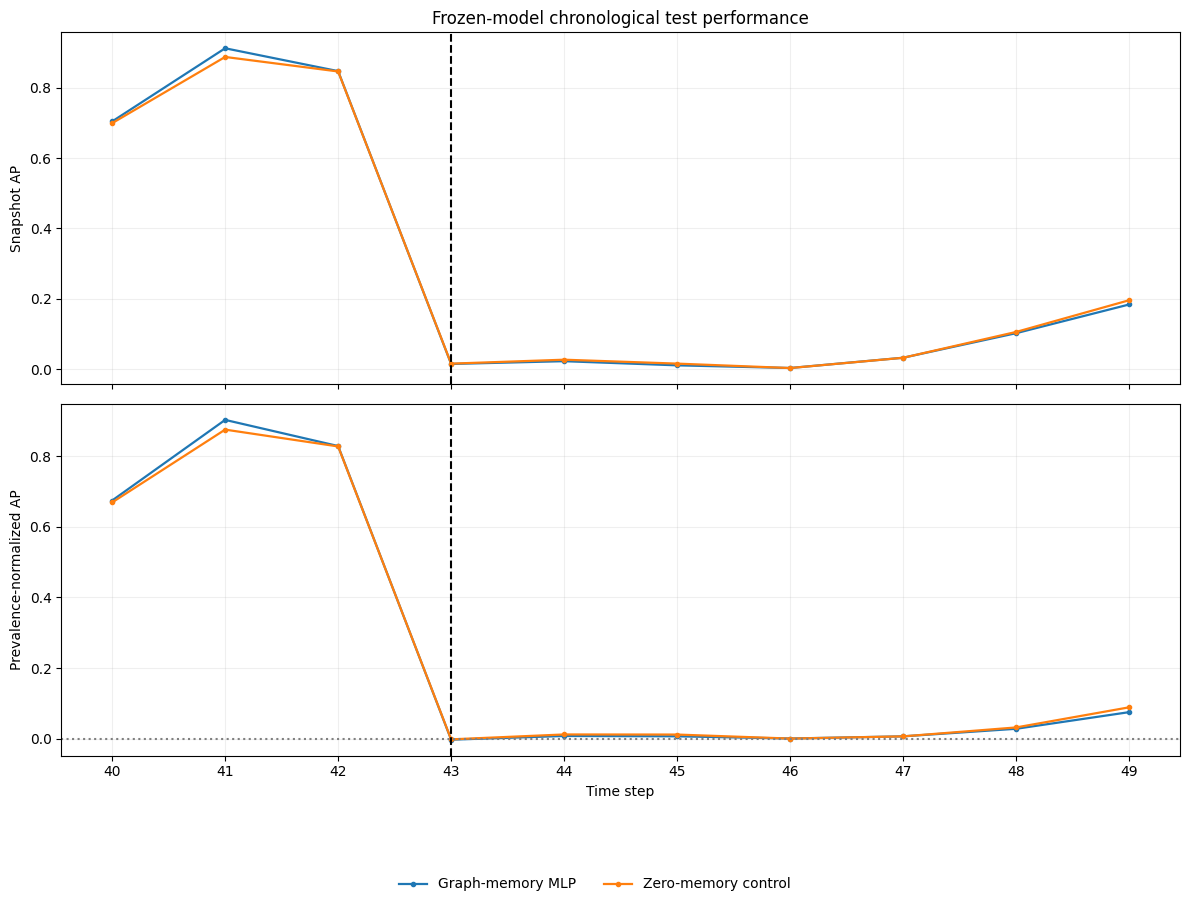


STEP 43:
              Model  Step       AP  Samples  Fraud
Zero-memory control    43 0.015270     1370     24
   Graph-memory MLP    43 0.014369     1370     24

Saved: /kaggle/working/m1_posthoc_extension/m1_snapshot_8models_AP_normalized.png
Saved: /kaggle/working/m1_posthoc_extension/m1_snapshot_8models_AP_normalized.pdf


In [107]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = "/kaggle/working/m1_posthoc_extension"

FILES = [
    os.path.join(OUT, "m1_frozen_models_snapshot_metrics.csv"),
    os.path.join(OUT, "m1_graph_memory_snapshot_metrics.csv"),
]

aliases = {
    "MLP": "MLP",
    "GCN": "GCN",
    "GraphSAGE": "GraphSAGE",
    "No-edge SAGE": "No-edge GraphSAGE",
    "No-edge GraphSAGE": "No-edge GraphSAGE",
    "Adaptive fusion": "Adaptive graph fusion",
    "Adaptive graph fusion": "Adaptive graph fusion",
    "Residual fusion": "Residual graph fusion",
    "Residual graph fusion": "Residual graph fusion",
    "Graph-memory MLP": "Graph-memory MLP",
    "Zero-memory control": "Zero-memory control",
}

parts = []

for path in FILES:
    df = pd.read_csv(path)

    # Case-insensitive column recognition
    lookup = {
        str(c).lower().replace("_", ""): c
        for c in df.columns
    }

    def find(*names):
        for n in names:
            key = n.lower().replace("_", "")
            if key in lookup:
                return lookup[key]
        return None

    mc = find("model", "model_name")
    tc = find("time", "time_step", "step", "snapshot")
    ac = find("ap", "pr_auc", "average_precision")
    nc = find("samples", "n", "n_labeled")
    fc = find("fraud", "n_fraud", "illicit")

    if not all([mc, tc, ac]):
        print("Skipped:", path, df.columns.tolist())
        continue

    rename = {mc: "Model", tc: "Step", ac: "AP"}

    if nc:
        rename[nc] = "Samples"
    if fc:
        rename[fc] = "Fraud"

    d = df.rename(columns=rename).copy()
    keep = ["Model", "Step", "AP"]
    keep += [c for c in ["Samples", "Fraud"] if c in d]

    d = d[keep]
    d["Model"] = d["Model"].map(
        lambda x: aliases.get(str(x), str(x))
    )

    d["Step"] = pd.to_numeric(d["Step"], errors="coerce")
    d["AP"] = pd.to_numeric(d["AP"], errors="coerce")

    d = d[d["Step"].between(40, 49)]
    parts.append(d)

data = (
    pd.concat(parts, ignore_index=True)
    .drop_duplicates(["Model", "Step"])
    .sort_values(["Model", "Step"])
)

# Preserve all available actual observations
data.to_csv(
    os.path.join(OUT, "m1_snapshot_8models.csv"),
    index=False
)

print("Models found:", data["Model"].nunique())
print("Model names:", sorted(data["Model"].unique()))

# Figure: two panels (AP and AP normalized by prevalence)
fig, axes = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True
)

for model, sub in data.groupby("Model"):
    sub = sub.sort_values("Step")

    axes[0].plot(
        sub["Step"], sub["AP"],
        marker="o", linewidth=1.6, markersize=3,
        label=model
    )

axes[0].axvline(43, linestyle="--", color="black")
axes[0].set_ylabel("Snapshot AP")
axes[0].set_title(
    "Frozen-model chronological test performance"
)
axes[0].grid(alpha=0.2)

# Actual per-snapshot prevalence, if available
prev = data.dropna(
    subset=["Samples", "Fraud"]
).copy() if all(
    c in data.columns for c in ["Samples", "Fraud"]
) else pd.DataFrame()

if not prev.empty:
    prev["Prevalence"] = prev["Fraud"] / prev["Samples"]
    prev = (
        prev.drop_duplicates("Step")
        .set_index("Step")["Prevalence"]
    )

    for model, sub in data.groupby("Model"):
        sub = sub.copy()
        sub["Prevalence"] = sub["Step"].map(prev)
        valid = sub["Prevalence"].between(0, 1, inclusive="neither")

        sub = sub[valid]
        sub["nAP"] = (
            (sub["AP"] - sub["Prevalence"]) /
            (1 - sub["Prevalence"])
        )

        axes[1].plot(
            sub["Step"], sub["nAP"],
            marker="o", linewidth=1.6,
            markersize=3, label=model
        )

    print("\nStep 43 prevalence:", prev.get(43, np.nan))

else:
    axes[1].text(
        0.5, 0.5,
        "Snapshot prevalence unavailable",
        transform=axes[1].transAxes,
        ha="center", va="center"
    )

axes[1].axvline(43, linestyle="--", color="black")
axes[1].axhline(0, linestyle=":", color="gray")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Prevalence-normalized AP")
axes[1].grid(alpha=0.2)

axes[1].set_xticks(range(40, 50))

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.01),
    frameon=False
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

png = os.path.join(
    OUT, "m1_snapshot_8models_AP_normalized.png"
)
pdf = os.path.join(
    OUT, "m1_snapshot_8models_AP_normalized.pdf"
)

fig.savefig(png, dpi=400, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")
plt.show()

print("\nSTEP 43:")
print(
    data[data["Step"] == 43]
    .sort_values("AP", ascending=False)
    .to_string(index=False)
)

print("\nSaved:", png)
print("Saved:", pdf)

XGBoost pooled AP: 0.642525
XGBoost pooled AUC: 0.855553

ALL SNAPSHOT RESULTS
        Model  Step    N  Fraud       AP      AUC
Random Forest    40 1211    112 0.747846 0.887333
Random Forest    41 1132    116 0.953791 0.980222
Random Forest    42 2154    239 0.878492 0.947444
Random Forest    43 1370     24 0.036633 0.730467
Random Forest    44 1591     24 0.033014 0.748484
Random Forest    45 1221      5 0.006797 0.619901
Random Forest    46  712      2 0.507042 0.901408
Random Forest    47  846     22 0.026862 0.538338
Random Forest    48  471     36 0.088243 0.584802
Random Forest    49  476     56 0.141979 0.622215
      XGBoost    40 1211    112 0.737802 0.878656
      XGBoost    41 1132    116 0.953959 0.985915
      XGBoost    42 2154    239 0.872579 0.957608
      XGBoost    43 1370     24 0.029797 0.651374
      XGBoost    44 1591     24 0.067063 0.801000
      XGBoost    45 1221      5 0.008290 0.646875
      XGBoost    46  712      2 0.260309 0.932394
      XGBoost    47  

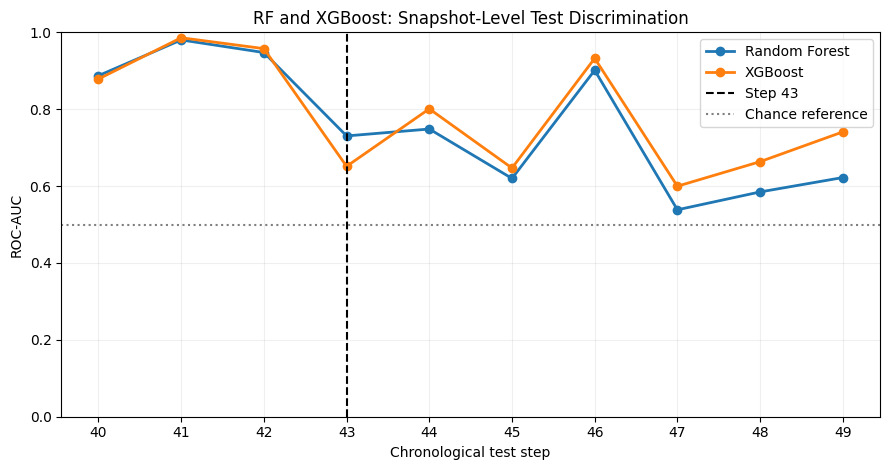


Saved figure and snapshot CSV.


In [108]:
# STEP 97 — RF + XGBOOST SNAPSHOT RESULTS
# No retraining; post-hoc descriptive evaluation

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

OUT = "/kaggle/working/m1_posthoc_extension"
os.makedirs(OUT, exist_ok=True)

# RF: read the exact original Step 80 metrics
rf_path = (
    "/kaggle/working/final_paper_protocol/"
    "final_test_predictive_metrics.csv"
)
rf = pd.read_csv(rf_path)
rf = rf[
    (rf["Model"] == "Raw RF") &
    (rf["Period"].str.fullmatch(r"t4[0-9]"))
].copy()

rf_results = pd.DataFrame({
    "Model": "Random Forest",
    "Step": rf["Period"].str[1:].astype(int),
    "N": rf["Samples"],
    "Fraud": rf["Fraud"],
    "AP": rf["PR-AUC"],
    "AUC": rf["ROC-AUC"]
})

# XGBoost: reuse the fitted model and Step 80 aligned test data
assert "xgb_model" in globals(), "Fitted xgb_model not found"
assert all(k in globals() for k in ["X_test", "y_test", "test_times"])

xgb_scores = xgb_model.predict_proba(X_test)[:, 1]

rows = []
for t in range(40, 50):
    mask = np.asarray(test_times) == t
    yt = np.asarray(y_test)[mask]
    pt = xgb_scores[mask]

    rows.append({
        "Model": "XGBoost",
        "Step": t,
        "N": len(yt),
        "Fraud": int(yt.sum()),
        "AP": average_precision_score(yt, pt),
        "AUC": roc_auc_score(yt, pt)
    })

xgb_results = pd.DataFrame(rows)

results = pd.concat(
    [rf_results, xgb_results],
    ignore_index=True
).sort_values(["Model", "Step"])

# Check that XGBoost reproduces Step 89 pooled AP/AUC
pooled_ap = average_precision_score(y_test, xgb_scores)
pooled_auc = roc_auc_score(y_test, xgb_scores)

print("XGBoost pooled AP:", round(pooled_ap, 6))
print("XGBoost pooled AUC:", round(pooled_auc, 6))

assert np.isclose(pooled_ap, 0.642525, atol=0.0001)
assert np.isclose(pooled_auc, 0.855553, atol=0.0001)

results.to_csv(
    f"{OUT}/rf_xgboost_snapshot_metrics.csv",
    index=False
)

print("\nALL SNAPSHOT RESULTS")
print(results.round(6).to_string(index=False))

print("\nSTEP 43")
print(
    results[results.Step == 43]
    .round(6).to_string(index=False)
)

# Plot AUC without test-based model selection
fig, ax = plt.subplots(figsize=(9, 4.8))

for model, sub in results.groupby("Model"):
    ax.plot(
        sub.Step, sub.AUC,
        marker="o", linewidth=2,
        label=model
    )

ax.axvline(43, color="black", linestyle="--",
           label="Step 43")
ax.axhline(0.5, color="gray", linestyle=":",
           label="Chance reference")

ax.set_xlabel("Chronological test step")
ax.set_ylabel("ROC-AUC")
ax.set_title("RF and XGBoost: Snapshot-Level Test Discrimination")
ax.set_xticks(range(40, 50))
ax.set_ylim(0, 1)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()

fig.savefig(
    f"{OUT}/rf_xgboost_snapshot_auc.png",
    dpi=400, bbox_inches="tight"
)
fig.savefig(
    f"{OUT}/rf_xgboost_snapshot_auc.pdf",
    bbox_inches="tight"
)
plt.show()

print("\nSaved figure and snapshot CSV.")

In [109]:

# STEP 97 — M2: Test calibration and matched-coverage
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, log_loss

y = np.asarray(y_test).astype(int)
raw = np.asarray(p_raw, dtype=float)
cal = np.asarray(p_cal, dtype=float)

assert len(y) == len(raw) == len(cal) == 11184
assert set(np.unique(y)) == {0, 1}
assert np.isfinite(raw).all() and np.isfinite(cal).all()
assert np.all((raw >= 0) & (raw <= 1))
assert np.all((cal >= 0) & (cal <= 1))

def ece(y, p, bins=15):
    edges = np.linspace(0, 1, bins + 1)
    ids = np.minimum(np.searchsorted(edges, p, side="right") - 1, bins - 1)
    return sum(
        np.mean(ids == k) *
        abs(y[ids == k].mean() - p[ids == k].mean())
        for k in range(bins) if np.any(ids == k)
    )

print("TEST CALIBRATION METRICS")
rows = []
for name, p in [("Raw RF", raw), ("Platt RF", cal)]:
    rows.append({
        "Model": name,
        "ECE-15": ece(y, p),
        "Log loss": log_loss(y, np.clip(p, 1e-12, 1-1e-12)),
        "Brier": brier_score_loss(y, p)
    })
print(pd.DataFrame(rows).round(6).to_string(index=False))

# Match the existing fixed-policy auto-clearance coverage.
# Identical ranks imply identical selected sets at equal coverage.
print("\nMATCHED-COVERAGE AUTO-CLEAR COMPARISON")
rows = []
n = len(y)

for coverage in [0.4638, 0.8073]:
    k = int(round(coverage * n))
    for name, p in [("Raw RF", raw), ("Platt RF", cal)]:
        selected = np.argsort(p, kind="stable")[:k]
        missed = int(y[selected].sum())
        rows.append({
            "Target coverage": coverage,
            "Model": name,
            "Cleared": k,
            "Fraud cleared": missed,
            "Fraud/clear (%)": 100 * missed / k,
            "Fraud missed (%)": 100 * missed / y.sum()
        })

matched_coverage_df = pd.DataFrame(rows)
print(matched_coverage_df.round(4).to_string(index=False))

# Check whether Platt preserves the ordering, including ties.
raw_order = np.argsort(raw, kind="stable")
cal_order = np.argsort(cal, kind="stable")
print("\nIdentical sorted transaction order:",
      np.array_equal(raw_order, cal_order))

print("\nSTEP 97 COMPLETE")


TEST CALIBRATION METRICS
   Model   ECE-15  Log loss    Brier
  Raw RF 0.042221  0.159555 0.035016
Platt RF 0.020614  0.160676 0.027316

MATCHED-COVERAGE AUTO-CLEAR COMPARISON
 Target coverage    Model  Cleared  Fraud cleared  Fraud/clear (%)  Fraud missed (%)
          0.4638   Raw RF     5187             94           1.8122           14.7799
          0.4638 Platt RF     5187             94           1.8122           14.7799
          0.8073   Raw RF     9029            202           2.2372           31.7610
          0.8073 Platt RF     9029            202           2.2372           31.7610

Identical sorted transaction order: False

STEP 97 COMPLETE


In [110]:

# ============================================================
# STEP 98 — M6: STATISTICAL UNCERTAINTY (95% CI)
# ============================================================
import numpy as np
import pandas as pd
from scipy.stats import beta
from sklearn.metrics import average_precision_score, roc_auc_score

y = np.asarray(y_test).astype(int).ravel()
raw = np.asarray(p_raw, dtype=float).ravel()
cal = np.asarray(p_cal, dtype=float).ravel()

# Use actual chronological test-step variable
time_candidates = [
    "test_times", "test_steps", "time_test",
    "steps_test", "test_time_steps", "t_test"
]
time_name = next(
    (n for n in time_candidates
     if n in globals() and
     np.asarray(globals()[n]).size == len(y)),
    None
)
if time_name is None:
    raise ValueError(
        "Test step variable not found. Supply the actual "
        "chronological test-step array before running."
    )

steps = np.asarray(globals()[time_name]).ravel()
assert len(y) == len(raw) == len(cal) == len(steps)

def cp_ci(k, n, alpha=0.05):
    if n == 0:
        return (np.nan, np.nan)
    lo = 0 if k == 0 else beta.ppf(alpha/2, k, n-k+1)
    hi = 1 if k == n else beta.ppf(1-alpha/2, k+1, n-k)
    return lo, hi

print("A. EXACT 95% CI — FRAUD MISSED AMONG ALL ILLICIT")
print("Time variable:", time_name)
print("Test snapshots:", np.unique(steps))

rows = []
total_fraud = int(y.sum())

for name, p in [("Raw RF", raw), ("Platt RF", cal)]:
    for coverage in [0.4638, 0.8073]:
        k = round(coverage * len(y))
        selected = np.argsort(p, kind="stable")[:k]
        missed = int(y[selected].sum())
        lo, hi = cp_ci(missed, total_fraud)
        rows.append({
            "Model": name,
            "Coverage (%)": round(100*k/len(y), 2),
            "Missed fraud": missed,
            "Total fraud": total_fraud,
            "Miss rate (%)": round(100*missed/total_fraud, 2),
            "95% CI lower": round(100*lo, 2),
            "95% CI upper": round(100*hi, 2)
        })

print(pd.DataFrame(rows).to_string(index=False))

# Resample whole chronological snapshots, preserving
# all transactions and labels within each snapshot.
print("\nB. SNAPSHOT-BLOCK BOOTSTRAP — RAW RF")
rng = np.random.default_rng(2026)
unique_steps = np.unique(steps)
groups = [np.flatnonzero(steps == s) for s in unique_steps]
B = 2000
ap_samples, auc_samples = [], []

for _ in range(B):
    chosen = rng.integers(0, len(groups), len(groups))
    idx = np.concatenate([groups[j] for j in chosen])
    yy, pp = y[idx], raw[idx]
    if len(np.unique(yy)) < 2:
        continue
    ap_samples.append(average_precision_score(yy, pp))
    auc_samples.append(roc_auc_score(yy, pp))

for metric, point, samples in [
    ("AP", average_precision_score(y, raw), ap_samples),
    ("ROC-AUC", roc_auc_score(y, raw), auc_samples)
]:
    lo, hi = np.percentile(samples, [2.5, 97.5])
    print(f"{metric}: {point:.4f} | 95% block-bootstrap CI: "
          f"[{lo:.4f}, {hi:.4f}] | valid={len(samples)}")

print("\nSTEP 98 COMPLETE")


A. EXACT 95% CI — FRAUD MISSED AMONG ALL ILLICIT
Time variable: test_times
Test snapshots: [40 41 42 43 44 45 46 47 48 49]
   Model  Coverage (%)  Missed fraud  Total fraud  Miss rate (%)  95% CI lower  95% CI upper
  Raw RF         46.38            94          636          14.78         12.11         17.78
  Raw RF         80.73           202          636          31.76         28.16         35.54
Platt RF         46.38            94          636          14.78         12.11         17.78
Platt RF         80.73           202          636          31.76         28.16         35.54

B. SNAPSHOT-BLOCK BOOTSTRAP — RAW RF
AP: 0.6450 | 95% block-bootstrap CI: [0.2092, 0.8153] | valid=2000
ROC-AUC: 0.8363 | 95% block-bootstrap CI: [0.6167, 0.9218] | valid=2000

STEP 98 COMPLETE


In [111]:

# STEP 99 — Expanding-window RF (M4)
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

X = np.asarray(X_all)
y = np.asarray(labels_all).ravel()
t = np.asarray(times_all).ravel()

print("Label distribution:", pd.Series(y).value_counts(dropna=False).to_dict())

# Elliptic labels: 1 = illicit, 0 = licit;
# unlabeled values are excluded.
valid = np.isin(y, [0, 1])

assert len(X) == len(y) == len(t)
assert valid.sum() > 0

rows = []
all_predictions = []

for step in range(40, 50):
    train_idx = valid & (t < step)
    test_idx = valid & (t == step)

    if not test_idx.any():
        continue

    model = clone(rf_model)
    model.fit(X[train_idx], y[train_idx].astype(int))

    p = model.predict_proba(X[test_idx])[:, 1]
    yy = y[test_idx].astype(int)

    rows.append({
        "Step": step,
        "N": len(yy),
        "Illicit": int(yy.sum()),
        "AP": average_precision_score(yy, p),
        "ROC-AUC": roc_auc_score(yy, p)
                   if len(np.unique(yy)) == 2 else np.nan
    })

    all_predictions.append(
        pd.DataFrame({
            "Step": step,
            "y": yy,
            "p_adaptive": p
        })
    )

adaptive_df = pd.DataFrame(rows)
adaptive_predictions = pd.concat(all_predictions, ignore_index=True)

print("\nEXPANDING-WINDOW RF")
print(adaptive_df.round(4).to_string(index=False))

print("\nPooled AP:",
      round(average_precision_score(
          adaptive_predictions.y,
          adaptive_predictions.p_adaptive), 6))

print("Pooled ROC-AUC:",
      round(roc_auc_score(
          adaptive_predictions.y,
          adaptive_predictions.p_adaptive), 6))

print("\nSTEP 99 COMPLETE")


Label distribution: {-1: 157205, 0: 42019, 1: 4545}

EXPANDING-WINDOW RF
 Step    N  Illicit     AP  ROC-AUC
   40 1211      112 0.7681   0.9145
   41 1132      116 0.9678   0.9895
   42 2154      239 0.9151   0.9761
   43 1370       24 0.0811   0.8739
   44 1591       24 0.0948   0.9048
   45 1221        5 0.0347   0.8655
   46  712        2 0.2675   0.9606
   47  846       22 0.0884   0.8483
   48  471       36 0.3415   0.8998
   49  476       56 0.7976   0.9717

Pooled AP: 0.761243
Pooled ROC-AUC: 0.948903

STEP 99 COMPLETE


In [112]:

# ============================================================
# STEP 100 — M3/M7: TEMPORAL PREVALENCE AND FEATURE DRIFT
# ============================================================
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp, spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score

X = np.asarray(X_all)
y = np.asarray(labels_all).ravel()
t = np.asarray(times_all).ravel()
valid = np.isin(y, [0, 1])

# Reference: labeled training period, steps 1–29
ref = X[valid & (t >= 1) & (t <= 29)]
assert len(ref) > 0

# KS drift over all 93 features; no test-label leakage
def mean_ks(reference, current):
    values = []
    for j in range(reference.shape[1]):
        a = reference[:, j]
        b = current[:, j]
        a, b = a[np.isfinite(a)], b[np.isfinite(b)]
        if len(a) and len(b):
            values.append(ks_2samp(a, b).statistic)
    return float(np.mean(values))

# Existing frozen RF test predictions
test_y = np.asarray(y_test).astype(int).ravel()
test_p = np.asarray(p_raw, dtype=float).ravel()
test_t = np.asarray(test_times).ravel()

assert len(test_y) == len(test_p) == len(test_t)

rows = []

for step in range(30, 50):
    mask = valid & (t == step)
    yy = y[mask].astype(int)
    xx = X[mask]

    if len(yy) == 0:
        continue

    prevalence = yy.mean()
    ks = mean_ks(ref, xx)

    row = {
        "Step": step,
        "N": len(yy),
        "Illicit": int(yy.sum()),
        "Prevalence": prevalence,
        "Mean_KS": ks,
        "RF_AP": np.nan,
        "RF_AUC": np.nan,
        "AP_Lift": np.nan
    }

    if step >= 40:
        pm = test_t == step
        yt, pt = test_y[pm], test_p[pm]

        # Verify label totals match chronological source
        assert len(yt) == len(yy)
        assert int(yt.sum()) == int(yy.sum())

        ap = average_precision_score(yt, pt)
        auc = roc_auc_score(yt, pt) if len(np.unique(yt)) == 2 else np.nan

        row["RF_AP"] = ap
        row["RF_AUC"] = auc
        row["AP_Lift"] = ap / prevalence if prevalence > 0 else np.nan

    rows.append(row)

temporal_drift_df = pd.DataFrame(rows)

print("STEP 100: TEMPORAL SHIFT RESULTS")
print(temporal_drift_df.round(4).to_string(index=False))

test_rows = temporal_drift_df.query("Step >= 40")

print("\nTEST-PERIOD ASSOCIATIONS (10 SNAPSHOTS)")
for metric in ["RF_AP", "RF_AUC", "AP_Lift"]:
    subset = test_rows[["Mean_KS", metric]].dropna()
    rho, p = spearmanr(subset["Mean_KS"], subset[metric])
    print(f"Mean KS vs {metric}: rho={rho:.4f}, p={p:.4f}")

print("\nSTEP 100 COMPLETE")


STEP 100: TEMPORAL SHIFT RESULTS
 Step    N  Illicit  Prevalence  Mean_KS  RF_AP  RF_AUC  AP_Lift
   30  524       83      0.1584   0.1451    NaN     NaN      NaN
   31  710      106      0.1493   0.1130    NaN     NaN      NaN
   32 1323      342      0.2585   0.1935    NaN     NaN      NaN
   33  441       23      0.0522   0.2362    NaN     NaN      NaN
   34  515       37      0.0718   0.1944    NaN     NaN      NaN
   35 1341      182      0.1357   0.1500    NaN     NaN      NaN
   36 1708       33      0.0193   0.1830    NaN     NaN      NaN
   37  498       40      0.0803   0.1722    NaN     NaN      NaN
   38  756      111      0.1468   0.1488    NaN     NaN      NaN
   39 1183       81      0.0685   0.2481    NaN     NaN      NaN
   40 1211      112      0.0925   0.1624 0.7478  0.8873   8.0861
   41 1132      116      0.1025   0.1435 0.9538  0.9802   9.3077
   42 2154      239      0.1110   0.1785 0.8785  0.9474   7.9175
   43 1370       24      0.0175   0.2250 0.0366  0.7305  

In [113]:

# ============================================================
# STEP 101 — M5/M10: RISK CONTROL + COST SENSITIVITY
# ============================================================
import numpy as np
import pandas as pd
from scipy.stats import beta

rng = np.random.default_rng(2026)

# M5: Exchangeable positive control
# Calibrate on random 50% of illicit examples;
# evaluate clearance risk on the remaining 50%.
y = np.asarray(y_test).astype(int).ravel()
p = np.asarray(p_raw, dtype=float).ravel()

assert len(y) == len(p)

def cp_upper(k, n, alpha=0.05):
    if n == 0:
        return 1.0
    if k == n:
        return 1.0
    return beta.ppf(1-alpha, k+1, n-k)

# Risk target: at most 5% of illicit cases cleared
target_risk = 0.05
alpha = 0.05
positive_scores = p[y == 1]

def select_threshold(scores):
    # Candidate thresholds from observed illicit scores.
    # Clear when score < threshold.
    candidates = np.unique(
        np.r_[0.0, scores, 1.0]
    )
    accepted = []
    for threshold in candidates:
        misses = int(np.sum(scores < threshold))
        upper = cp_upper(misses, len(scores), alpha)
        if upper <= target_risk:
            accepted.append(threshold)
    return max(accepted) if accepted else 0.0

B = 300
control_rows = []

for _ in range(B):
    ids = rng.permutation(len(positive_scores))
    mid = len(ids) // 2
    cal_scores = positive_scores[ids[:mid]]
    eval_scores = positive_scores[ids[mid:]]

    threshold = select_threshold(cal_scores)
    miss_rate = float(np.mean(eval_scores < threshold))

    control_rows.append({
        "threshold": threshold,
        "miss_rate": miss_rate,
        "meets_target": miss_rate <= target_risk
    })

control_df = pd.DataFrame(control_rows)

print("M5: RANDOM-SPLIT POSITIVE CONTROL")
print("Target miss rate:", target_risk)
print("Mean empirical miss rate:",
      round(control_df.miss_rate.mean(), 4))
print("Fraction of splits meeting target:",
      round(control_df.meets_target.mean(), 4))
print("Mean selected threshold:",
      round(control_df.threshold.mean(), 6))

# M10: Existing locked-test policy counts
# Columns: illicit cleared, legitimate flagged, review count
policies = {
    "Fixed raw RF": (94, 111, 5517),
    "Fixed Platt RF": (202, 29, 1789),
    "Historical raw RF": (144, 111, 3359),
    "Historical Platt RF": (144, 29, 3473)
}

# Illustrative unit costs, not observed financial losses
cost_ratios = [5, 10, 25, 50, 100]
rows = []

for fraud_cost in cost_ratios:
    costs = {}
    for name, (missed, false_flag, review) in policies.items():
        cost = (
            fraud_cost * missed +
            1.0 * false_flag +
            0.5 * review
        )
        costs[name] = cost
        rows.append({
            "Fraud cost": fraud_cost,
            "Policy": name,
            "Total illustrative cost": cost
        })
    print(f"Fraud cost {fraud_cost}: "
          f"lowest-cost policy = {min(costs, key=costs.get)}")

cost_sensitivity_df = pd.DataFrame(rows)

print("\nCOST SENSITIVITY TABLE")
print(cost_sensitivity_df.pivot(
    index="Fraud cost",
    columns="Policy",
    values="Total illustrative cost"
).round(2).to_string())

print("\nSTEP 101 COMPLETE")


M5: RANDOM-SPLIT POSITIVE CONTROL
Target miss rate: 0.05
Mean empirical miss rate: 0.0305
Fraction of splits meeting target: 0.9033
Mean selected threshold: 0.004209
Fraud cost 5: lowest-cost policy = Fixed Platt RF
Fraud cost 10: lowest-cost policy = Fixed Platt RF
Fraud cost 25: lowest-cost policy = Fixed raw RF
Fraud cost 50: lowest-cost policy = Fixed raw RF
Fraud cost 100: lowest-cost policy = Fixed raw RF

COST SENSITIVITY TABLE
Policy      Fixed Platt RF  Fixed raw RF  Historical Platt RF  Historical raw RF
Fraud cost                                                                      
5                   1933.5        3339.5               2485.5             2510.5
10                  2943.5        3809.5               3205.5             3230.5
25                  5973.5        5219.5               5365.5             5390.5
50                 11023.5        7569.5               8965.5             8990.5
100                21123.5       12269.5              16165.5            16

STEP 102: CALIBRATION AND RISK-COVERAGE ANALYSIS
Locked-test observations: 11184
Illicit observations: 636
Raw RF predictions: 11184
Platt RF predictions: 11184


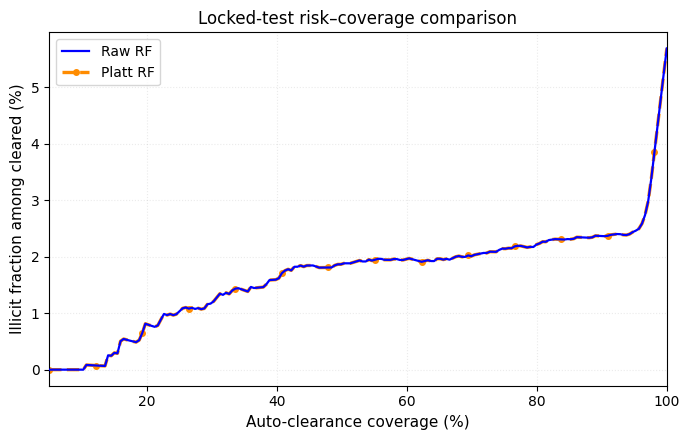


RISK–COVERAGE COMPARISON
----------------------------------------------------------------------
Coverage:  20.0% | Raw RF:   18 illicit | Platt RF:   18 illicit
Coverage:  40.0% | Raw RF:   72 illicit | Platt RF:   72 illicit
Coverage:  60.0% | Raw RF:  131 illicit | Platt RF:  131 illicit
Coverage:  80.0% | Raw RF:  198 illicit | Platt RF:  198 illicit
Coverage: 100.0% | Raw RF:  636 illicit | Platt RF:  636 illicit

Maximum absolute risk difference (percentage points): 0.0


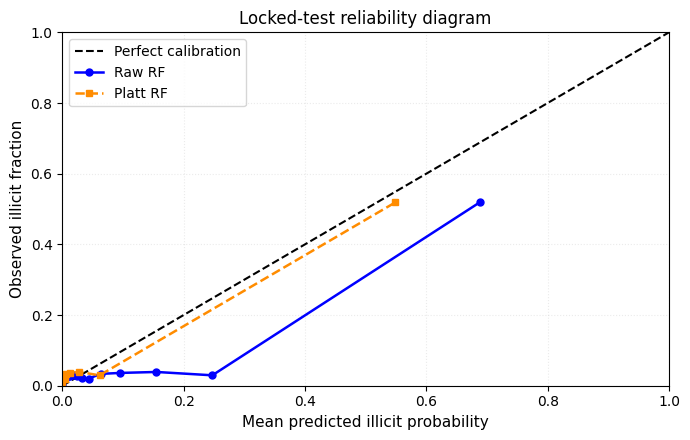


STEP 102 COMPLETE
Saved figures:
1. step102_risk_coverage.pdf
2. step102_risk_coverage.png
3. step102_reliability.pdf
4. step102_reliability.png

Frozen models modified: NO
Predictions modified: NO
Thresholds modified: NO
Model retraining performed: NO

SUCCESS: Step 102 completed.


In [114]:

# ============================================================
# STEP 102 — M2: RISK–COVERAGE + RELIABILITY DIAGRAMS
# UPDATED FINAL VERSION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

print("=" * 70)
print("STEP 102: CALIBRATION AND RISK-COVERAGE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load existing locked-test predictions
# ------------------------------------------------------------

y = np.asarray(y_test).astype(int).ravel()
raw = np.asarray(p_raw, dtype=float).ravel()
cal = np.asarray(p_cal, dtype=float).ravel()

assert len(y) == len(raw) == len(cal), \
    "Prediction and label lengths do not match."

assert set(np.unique(y)).issubset({0, 1}), \
    "Labels must be binary (0/1)."

assert np.all(np.isfinite(raw)) and np.all(np.isfinite(cal)), \
    "Predictions contain non-finite values."

assert np.all((raw >= 0) & (raw <= 1))
assert np.all((cal >= 0) & (cal <= 1))

print("Locked-test observations:", len(y))
print("Illicit observations:", int(np.sum(y)))
print("Raw RF predictions:", len(raw))
print("Platt RF predictions:", len(cal))

# ------------------------------------------------------------
# 2. Risk–Coverage computation
# ------------------------------------------------------------

coverages = np.linspace(0.05, 1.0, 200)

def compute_risk_coverage(y_true, scores, coverage_values):

    order = np.argsort(scores, kind="stable")
    sorted_labels = y_true[order]

    cumulative_fraud = np.cumsum(sorted_labels)

    risks = []

    for coverage in coverage_values:

        k = max(
            1,
            int(round(coverage * len(y_true)))
        )

        fraud_cleared = cumulative_fraud[k - 1]

        risk = fraud_cleared / k

        risks.append(risk)

    return np.asarray(risks)


raw_risk = compute_risk_coverage(
    y, raw, coverages
)

cal_risk = compute_risk_coverage(
    y, cal, coverages
)

# ------------------------------------------------------------
# 3. Updated risk–coverage visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.5))

# Platt RF: draw first, dashed orange with markers
ax.plot(
    coverages * 100,
    cal_risk * 100,
    color="darkorange",
    linestyle="--",
    linewidth=2.4,
    marker="o",
    markevery=15,
    markersize=4,
    label="Platt RF",
    zorder=2
)

# Raw RF: draw above Platt RF
ax.plot(
    coverages * 100,
    raw_risk * 100,
    color="blue",
    linestyle="-",
    linewidth=1.6,
    label="Raw RF",
    zorder=3
)

ax.set_xlabel(
    "Auto-clearance coverage (%)",
    fontsize=11
)

ax.set_ylabel(
    "Illicit fraction among cleared (%)",
    fontsize=11
)

ax.set_title(
    "Locked-test risk–coverage comparison",
    fontsize=12
)

# Explicit legend order
handles, labels = ax.get_legend_handles_labels()

ax.legend(
    [handles[1], handles[0]],
    [labels[1], labels[0]],
    loc="upper left",
    fontsize=10
)

ax.grid(
    alpha=0.25,
    linestyle=":"
)

ax.set_xlim(5, 100)

plt.tight_layout()

plt.savefig(
    "step102_risk_coverage.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "step102_risk_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Numerical risk–coverage comparison
# ------------------------------------------------------------

print("\nRISK–COVERAGE COMPARISON")
print("-" * 70)

for coverage in [0.20, 0.40, 0.60, 0.80, 1.00]:

    k = max(1, int(round(coverage * len(y))))

    raw_order = np.argsort(raw, kind="stable")
    cal_order = np.argsort(cal, kind="stable")

    raw_fraud = int(np.sum(y[raw_order[:k]]))
    cal_fraud = int(np.sum(y[cal_order[:k]]))

    print(
        f"Coverage: {coverage * 100:5.1f}% | "
        f"Raw RF: {raw_fraud:4d} illicit | "
        f"Platt RF: {cal_fraud:4d} illicit"
    )

print(
    "\nMaximum absolute risk difference "
    "(percentage points):",
    round(
        float(np.max(np.abs(raw_risk - cal_risk)) * 100),
        6
    )
)

# ------------------------------------------------------------
# 5. Reliability diagram (15 quantile bins)
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.5))

# Perfect calibration reference
ax.plot(
    [0, 1],
    [0, 1],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

# Raw RF
observed_raw, predicted_raw = calibration_curve(
    y,
    raw,
    n_bins=15,
    strategy="quantile"
)

ax.plot(
    predicted_raw,
    observed_raw,
    color="blue",
    marker="o",
    linestyle="-",
    linewidth=1.8,
    markersize=5,
    label="Raw RF"
)

# Platt RF
observed_cal, predicted_cal = calibration_curve(
    y,
    cal,
    n_bins=15,
    strategy="quantile"
)

ax.plot(
    predicted_cal,
    observed_cal,
    color="darkorange",
    marker="s",
    linestyle="--",
    linewidth=1.8,
    markersize=5,
    label="Platt RF"
)

ax.set_xlabel(
    "Mean predicted illicit probability",
    fontsize=11
)

ax.set_ylabel(
    "Observed illicit fraction",
    fontsize=11
)

ax.set_title(
    "Locked-test reliability diagram",
    fontsize=12
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.legend(
    loc="upper left",
    fontsize=10
)

ax.grid(
    alpha=0.25,
    linestyle=":"
)

plt.tight_layout()

plt.savefig(
    "step102_reliability.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "step102_reliability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 102 COMPLETE")
print("=" * 70)

print("Saved figures:")
print("1. step102_risk_coverage.pdf")
print("2. step102_risk_coverage.png")
print("3. step102_reliability.pdf")
print("4. step102_reliability.png")

print("\nFrozen models modified: NO")
print("Predictions modified: NO")
print("Thresholds modified: NO")
print("Model retraining performed: NO")

print("\nSUCCESS: Step 102 completed.")


STEP 103: FIXED-FPR RECALL AND TEMPORAL LABEL SHIFT
Assessment N: 1939
Assessment illicit: 192
Locked-test N: 11184
Locked-test illicit: 636
Feature alignment: VERIFIED

FIXED-FPR ASSESSMENT VS LOCKED TEST
------------------------------------------------------------------------
   Model  Target_FPR      Period  Threshold  Observed_FPR  Recall  Illicit_N  Licit_N
  Raw RF        0.01  Assessment    0.45881       0.00916 0.92188        192     1747
  Raw RF        0.01 Locked test    0.45881       0.01384 0.58805        636    10548
  Raw RF        0.05  Assessment    0.28417       0.04579 0.93750        192     1747
  Raw RF        0.05 Locked test    0.28417       0.04882 0.61321        636    10548
  Raw RF        0.10  Assessment    0.28417       0.04579 0.93750        192     1747
  Raw RF        0.10 Locked test    0.28417       0.04882 0.61321        636    10548
Platt RF        0.01  Assessment    0.19506       0.00916 0.92188        192     1747
Platt RF        0.01 Locked test 

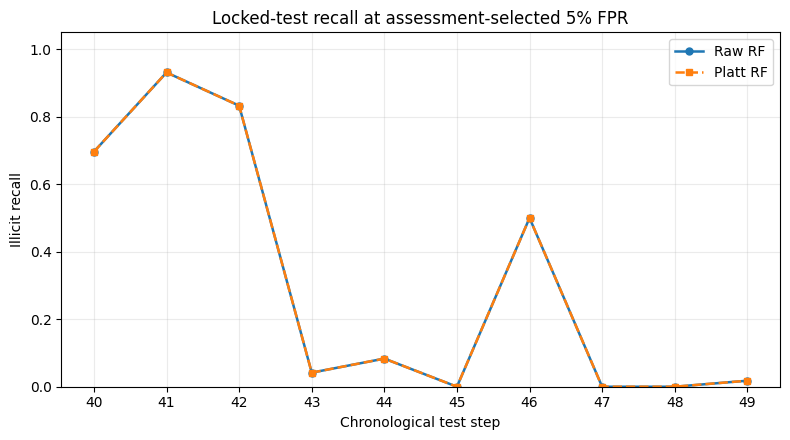

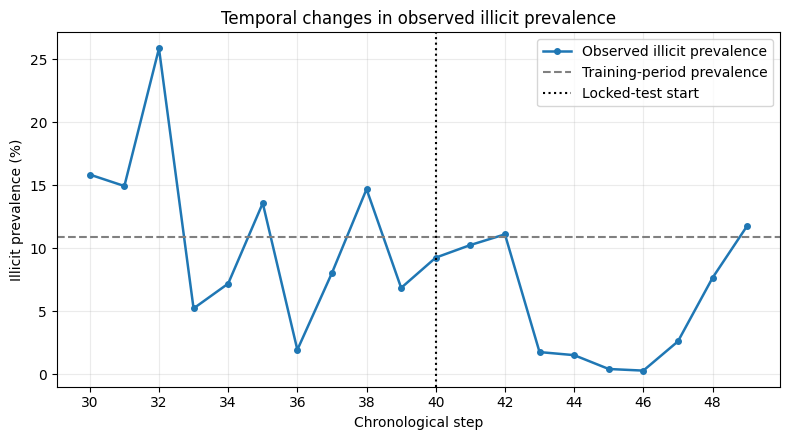


STEP 103 COMPLETE
Output directory: /kaggle/working/step103_m3
Frozen models modified: NO
Retraining performed: NO
Additional scaling applied: NO
Threshold selection on locked test: NO
Formal label-shift guarantee claimed: NO


In [115]:

# ============================================================
# STEP 103 — M3: FIXED-FPR RECALL + TEMPORAL LABEL SHIFT
# CORRECTED VERSION — NO RETRAINING / NO RESCALING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve
from scipy.stats import ks_2samp

OUT = "/kaggle/working/step103_m3"
os.makedirs(OUT, exist_ok=True)

print("=" * 72)
print("STEP 103: FIXED-FPR RECALL AND TEMPORAL LABEL SHIFT")
print("=" * 72)

# ------------------------------------------------------------
# 1. Reuse original feature matrix, labels and time steps
# ------------------------------------------------------------

X = np.asarray(X_all)
labels = np.asarray(labels_all).ravel()
times = np.asarray(times_all).ravel()

assert len(X) == len(labels) == len(times)
assert X.shape[1] == rf_final.n_features_in_
assert np.all(np.isfinite(X))

valid = np.isin(labels, [0, 1])

assessment_mask = valid & np.isin(times, [38, 39])
test_mask = valid & (times >= 40) & (times <= 49)
reference_mask = valid & (times >= 1) & (times <= 29)

y_assessment = labels[assessment_mask].astype(int)
y_test_103 = labels[test_mask].astype(int)
test_t = times[test_mask]

assert len(y_assessment) == 1939
assert int(y_assessment.sum()) == 192

# Confirm exact test alignment before proceeding
assert np.array_equal(
    y_test_103, np.asarray(y_test).astype(int).ravel()
), "Locked-test labels are not aligned."

assert np.array_equal(
    test_t, np.asarray(test_times).ravel()
), "Locked-test time steps are not aligned."

assert np.allclose(
    X[test_mask], np.asarray(X_test),
    rtol=1e-5, atol=1e-6
), "Feature alignment failed."

print("Assessment N:", len(y_assessment))
print("Assessment illicit:", int(y_assessment.sum()))
print("Locked-test N:", len(y_test_103))
print("Locked-test illicit:", int(y_test_103.sum()))
print("Feature alignment: VERIFIED")

# ------------------------------------------------------------
# 2. Assessment predictions from frozen RF
# ------------------------------------------------------------

fraud_col = list(rf_final.classes_).index(1)

assessment_raw = rf_final.predict_proba(
    X[assessment_mask]
)[:, fraud_col]

# The Platt model is fitted on the RF logit scores.
# Reuse the same transformation as the original notebook.
eps = 1e-6

assessment_clipped = np.clip(
    assessment_raw, eps, 1 - eps
)

assessment_logit = np.log(
    assessment_clipped /
    (1 - assessment_clipped)
).reshape(-1, 1)

cal_fraud_col = list(platt_final.classes_).index(1)

assessment_platt = platt_final.predict_proba(
    assessment_logit
)[:, cal_fraud_col]

raw_test = np.asarray(p_raw).ravel()
platt_test = np.asarray(p_cal).ravel()

assert len(raw_test) == len(platt_test) == len(y_test_103)

# ------------------------------------------------------------
# 3. Assessment-selected fixed-FPR thresholds
# ------------------------------------------------------------

FPR_TARGETS = [0.01, 0.05, 0.10]

def select_threshold(y_true, scores, target_fpr):

    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores,
        drop_intermediate=False
    )

    eligible = np.where(
        fpr <= target_fpr + 1e-12
    )[0]

    # Highest assessment recall among feasible thresholds
    best = eligible[np.argmax(tpr[eligible])]

    return float(thresholds[best])


models = [
    ("Raw RF", assessment_raw, raw_test),
    ("Platt RF", assessment_platt, platt_test)
]

pooled_rows = []
snapshot_rows = []

for name, assessment_scores, test_scores in models:

    for target in FPR_TARGETS:

        threshold = select_threshold(
            y_assessment,
            assessment_scores,
            target
        )

        for period, yy, scores in [
            ("Assessment", y_assessment, assessment_scores),
            ("Locked test", y_test_103, test_scores)
        ]:

            predicted = scores >= threshold

            observed_fpr = predicted[yy == 0].mean()
            recall = predicted[yy == 1].mean()

            pooled_rows.append({
                "Model": name,
                "Target_FPR": target,
                "Period": period,
                "Threshold": threshold,
                "Observed_FPR": observed_fpr,
                "Recall": recall,
                "Illicit_N": int((yy == 1).sum()),
                "Licit_N": int((yy == 0).sum())
            })

        for step in range(40, 50):

            mask = test_t == step

            yy = y_test_103[mask]
            scores = test_scores[mask]

            predicted = scores >= threshold

            snapshot_rows.append({
                "Model": name,
                "Target_FPR": target,
                "Step": step,
                "N": len(yy),
                "Illicit": int(yy.sum()),
                "Observed_FPR":
                    predicted[yy == 0].mean()
                    if np.any(yy == 0) else np.nan,
                "Recall":
                    predicted[yy == 1].mean()
                    if np.any(yy == 1) else np.nan
            })

fixed_fpr_df = pd.DataFrame(pooled_rows)
snapshot_fpr_df = pd.DataFrame(snapshot_rows)

print("\nFIXED-FPR ASSESSMENT VS LOCKED TEST")
print("-" * 72)
print(fixed_fpr_df.round(5).to_string(index=False))

print("\nSNAPSHOT-LEVEL FIXED-FPR RESULTS")
print("-" * 72)
print(snapshot_fpr_df.round(5).to_string(index=False))

# ------------------------------------------------------------
# 4. Temporal prevalence and label-shift diagnostics
# ------------------------------------------------------------

reference_y = labels[reference_mask].astype(int)

reference_prevalence = reference_y.mean()

reference_scores = rf_final.predict_proba(
    X[reference_mask]
)[:, fraud_col]

shift_rows = []

for step in range(30, 50):

    mask = valid & (times == step)

    yy = labels[mask].astype(int)

    if len(yy) == 0:
        continue

    scores = rf_final.predict_proba(
        X[mask]
    )[:, fraud_col]

    conditional_ks = {}

    for label_value in [0, 1]:

        reference_class_scores = reference_scores[
            reference_y == label_value
        ]

        current_class_scores = scores[
            yy == label_value
        ]

        if (
            len(reference_class_scores) >= 2
            and len(current_class_scores) >= 2
        ):
            conditional_ks[label_value] = ks_2samp(
                reference_class_scores,
                current_class_scores
            ).statistic
        else:
            conditional_ks[label_value] = np.nan

    shift_rows.append({
        "Step": step,
        "N": len(yy),
        "Illicit": int(yy.sum()),
        "Prevalence": float(yy.mean()),
        "Prevalence_Ratio":
            float(yy.mean() / reference_prevalence),
        "KS_Licit_Score": conditional_ks[0],
        "KS_Illicit_Score": conditional_ks[1]
    })

label_shift_df = pd.DataFrame(shift_rows)

# Correct the column name for class 0
label_shift_df = label_shift_df.rename(
    columns={"KS_Licit_Score": "KS_Licit_Class0"}
)

print("\nTEMPORAL LABEL-SHIFT DIAGNOSTICS")
print("-" * 72)

print(
    "Training-period illicit prevalence:",
    round(reference_prevalence, 6)
)

print(
    label_shift_df.round(5).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Save all numerical results
# ------------------------------------------------------------

fixed_fpr_df.to_csv(
    f"{OUT}/fixed_fpr_pooled.csv",
    index=False
)

snapshot_fpr_df.to_csv(
    f"{OUT}/fixed_fpr_snapshots.csv",
    index=False
)

label_shift_df.to_csv(
    f"{OUT}/temporal_label_shift.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Figure: recall at assessment-selected 5% FPR
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))

for name, style in [
    ("Raw RF", "-o"),
    ("Platt RF", "--s")
]:

    sub = snapshot_fpr_df[
        (snapshot_fpr_df["Model"] == name) &
        np.isclose(
            snapshot_fpr_df["Target_FPR"], 0.05
        )
    ]

    ax.plot(
        sub["Step"],
        sub["Recall"],
        style,
        linewidth=1.8,
        markersize=5,
        label=name
    )

ax.set_xlabel("Chronological test step")
ax.set_ylabel("Illicit recall")
ax.set_title(
    "Locked-test recall at assessment-selected 5% FPR"
)
ax.set_xticks(range(40, 50))
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    f"{OUT}/fixed_fpr_recall.pdf",
    bbox_inches="tight"
)

fig.savefig(
    f"{OUT}/fixed_fpr_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. Figure: chronological illicit prevalence
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    label_shift_df["Step"],
    100 * label_shift_df["Prevalence"],
    "-o",
    linewidth=1.8,
    markersize=4,
    label="Observed illicit prevalence"
)

ax.axhline(
    100 * reference_prevalence,
    linestyle="--",
    color="gray",
    label="Training-period prevalence"
)

ax.axvline(
    40,
    linestyle=":",
    color="black",
    label="Locked-test start"
)

ax.set_xlabel("Chronological step")
ax.set_ylabel("Illicit prevalence (%)")
ax.set_title(
    "Temporal changes in observed illicit prevalence"
)
ax.set_xticks(range(30, 50, 2))
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    f"{OUT}/temporal_label_shift.pdf",
    bbox_inches="tight"
)

fig.savefig(
    f"{OUT}/temporal_label_shift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 103 COMPLETE")
print("=" * 72)

print("Output directory:", OUT)
print("Frozen models modified: NO")
print("Retraining performed: NO")
print("Additional scaling applied: NO")
print("Threshold selection on locked test: NO")
print("Formal label-shift guarantee claimed: NO")



STEP 104A — POOLED CLEARED-POOL CALIBRATION
   Model                  Policy   Step  Cleared  Illicit cleared  Mean predicted risk (%)  Observed fraud rate (%)  Observed CI low (%)  Observed CI high (%)  Calibration gap (pp)  Expected illicit count  Observed minus expected
  Raw RF          Fixed p < 0.02 Pooled     5187               94                   0.6422                   1.8122               1.4669                2.2132                1.1701                 33.3090                  60.6910
Platt RF          Fixed p < 0.02 Pooled     9029              202                   0.2697                   2.2372               1.9421                2.5637                1.9675                 24.3531                 177.6469
  Raw RF Matched coverage 80.73% Pooled     9029              202                   2.6247                   2.2372               1.9421                2.5637               -0.3875                236.9832                 -34.9832
Platt RF Matched coverage 80.73% Po

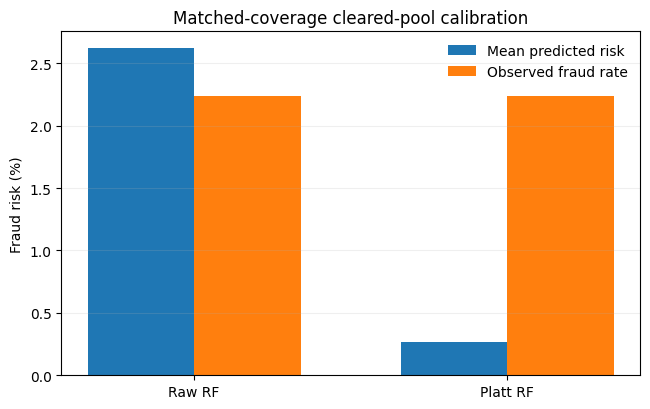

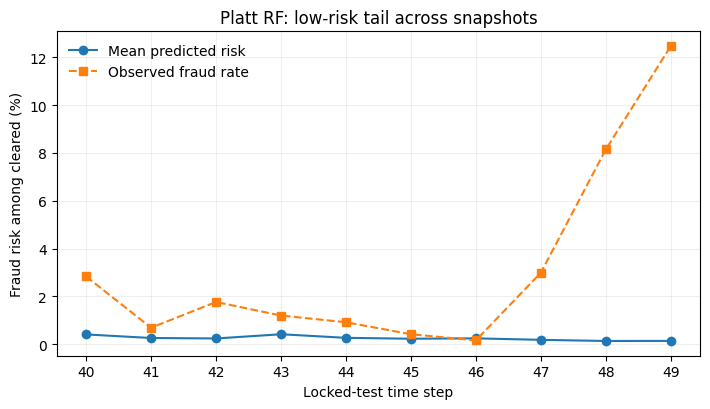


STEP 104 COMPLETE
Results saved to: /kaggle/working/step104_calibration_tail


In [116]:

# ============================================================
# STEP 104 — M2/R3: CALIBRATION-TAIL AUDIT
# Predicted versus observed risk under temporal shift
# Post-hoc diagnostic; no retraining or threshold tuning
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

OUT = "/kaggle/working/step104_calibration_tail"
os.makedirs(OUT, exist_ok=True)

# 1. Frozen locked-test arrays
y = np.asarray(y_test, dtype=int).ravel()
t = np.asarray(test_times, dtype=int).ravel()
raw = np.asarray(p_raw, dtype=float).ravel()
cal = np.asarray(p_cal, dtype=float).ravel()

assert len(y) == len(t) == len(raw) == len(cal) == 11184
assert set(np.unique(y)) == {0, 1}
assert np.array_equal(np.unique(t), np.arange(40, 50))
assert y.sum() == 636
assert np.isfinite(raw).all() and np.isfinite(cal).all()
assert np.all((raw >= 0) & (raw <= 1))
assert np.all((cal >= 0) & (cal <= 1))

# 2. Exact binomial CI for observed fraud rate
def cp_interval(k, n, alpha=0.05):
    if n == 0:
        return np.nan, np.nan
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n-k+1)
    hi = 1.0 if k == n else beta.ppf(1-alpha/2, k+1, n-k)
    return lo, hi

def audit_subset(model, policy, scores, mask, step="Pooled"):
    yy = y[mask]
    pp = scores[mask]
    n = len(yy)
    k = int(yy.sum())
    lo, hi = cp_interval(k, n)

    return {
        "Model": model,
        "Policy": policy,
        "Step": step,
        "Cleared": n,
        "Illicit cleared": k,
        "Mean predicted risk (%)": 100*pp.mean() if n else np.nan,
        "Observed fraud rate (%)": 100*k/n if n else np.nan,
        "Observed CI low (%)": 100*lo,
        "Observed CI high (%)": 100*hi,
        "Calibration gap (pp)": (
            100*(k/n - pp.mean()) if n else np.nan
        ),
        "Expected illicit count": pp.sum(),
        "Observed minus expected": k-pp.sum()
    }

rows = []
snapshot_rows = []

# 3. Fixed numerical clearance threshold
# This evaluates probability-based policies.
for name, scores in [("Raw RF", raw), ("Platt RF", cal)]:
    mask = scores < 0.02

    rows.append(audit_subset(
        name, "Fixed p < 0.02", scores, mask
    ))

    for step in range(40, 50):
        snapshot_rows.append(audit_subset(
            name, "Fixed p < 0.02",
            scores, mask & (t == step), step
        ))

# 4. Matched coverage: same number cleared
# Tests calibration of the probability estimates
# over a comparable selected population.
n_clear = 9029

for name, scores in [("Raw RF", raw), ("Platt RF", cal)]:
    order = np.argsort(scores, kind="stable")
    mask = np.zeros(len(scores), dtype=bool)
    mask[order[:n_clear]] = True

    rows.append(audit_subset(
        name, "Matched coverage 80.73%",
        scores, mask
    ))

    for step in range(40, 50):
        snapshot_rows.append(audit_subset(
            name, "Matched coverage 80.73%",
            scores, mask & (t == step), step
        ))

pooled_df = pd.DataFrame(rows)
snapshot_df = pd.DataFrame(snapshot_rows)

print("\n" + "="*75)
print("STEP 104A — POOLED CLEARED-POOL CALIBRATION")
print("="*75)
print(pooled_df.round(4).to_string(index=False))

print("\n" + "="*75)
print("STEP 104B — SNAPSHOT CALIBRATION")
print("="*75)
print(snapshot_df.round(4).to_string(index=False))

# 5. Probability-tail bins across all locked-test observations
edges = [0, .005, .01, .02, .05, .10, .20, .50, 1.0]
tail_rows = []

for name, scores in [("Raw RF", raw), ("Platt RF", cal)]:
    for j in range(len(edges)-1):
        low, high = edges[j], edges[j+1]
        mask = (
            (scores >= low) &
            ((scores < high) if j < len(edges)-2
             else (scores <= high))
        )
        if not mask.any():
            continue

        result = audit_subset(
            name,
            f"[{low:.3f}, {high:.3f}" +
            ("]" if j == len(edges)-2 else ")"),
            scores,
            mask
        )
        tail_rows.append(result)

tail_df = pd.DataFrame(tail_rows)

print("\n" + "="*75)
print("STEP 104C — PROBABILITY-TAIL RELIABILITY")
print("="*75)
print(tail_df.round(4).to_string(index=False))

# 6. Figure A: Predicted vs observed cleared-pool risk
plot_df = pooled_df[
    pooled_df["Policy"] == "Matched coverage 80.73%"
].reset_index(drop=True)

x = np.arange(len(plot_df))
width = .34

fig, ax = plt.subplots(figsize=(6.6, 4.2))
ax.bar(
    x-width/2,
    plot_df["Mean predicted risk (%)"],
    width,
    label="Mean predicted risk"
)
ax.bar(
    x+width/2,
    plot_df["Observed fraud rate (%)"],
    width,
    label="Observed fraud rate"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"])
ax.set_ylabel("Fraud risk (%)")
ax.set_title("Matched-coverage cleared-pool calibration")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
fig.savefig(
    os.path.join(OUT, "step104_cleared_pool_risk.pdf"),
    bbox_inches="tight"
)
fig.savefig(
    os.path.join(OUT, "step104_cleared_pool_risk.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# 7. Figure B: Snapshot-level Platt tail calibration
plot_df = snapshot_df[
    (snapshot_df["Model"] == "Platt RF") &
    (snapshot_df["Policy"] == "Fixed p < 0.02")
].copy()

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(
    plot_df["Step"],
    plot_df["Mean predicted risk (%)"],
    "o-", label="Mean predicted risk"
)
ax.plot(
    plot_df["Step"],
    plot_df["Observed fraud rate (%)"],
    "s--", label="Observed fraud rate"
)
ax.set_xticks(np.arange(40, 50))
ax.set_xlabel("Locked-test time step")
ax.set_ylabel("Fraud risk among cleared (%)")
ax.set_title("Platt RF: low-risk tail across snapshots")
ax.legend(frameon=False)
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(
    os.path.join(OUT, "step104_snapshot_tail.pdf"),
    bbox_inches="tight"
)
fig.savefig(
    os.path.join(OUT, "step104_snapshot_tail.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# 8. Save complete numerical results
pooled_df.to_csv(
    os.path.join(OUT, "step104_pooled.csv"),
    index=False
)
snapshot_df.to_csv(
    os.path.join(OUT, "step104_snapshots.csv"),
    index=False
)
tail_df.to_csv(
    os.path.join(OUT, "step104_probability_bins.csv"),
    index=False
)

print("\nSTEP 104 COMPLETE")
print("Results saved to:", OUT)


In [117]:

# ============================================================
# STEP 105 + STEP 106
# R3: COST-DEPENDENT SCREENING THRESHOLDS
# R6: PAIRED RF vs XGBOOST BOOTSTRAP
# POST-HOC EXPLORATORY ANALYSIS — NO MODEL RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

OUT = "/kaggle/working/step105_106_r3_r6"
os.makedirs(OUT, exist_ok=True)

# ------------------------------------------------------------
# LOAD EXISTING FROZEN TEST PREDICTIONS
# ------------------------------------------------------------

y = np.asarray(y_test).astype(int).ravel()
t = np.asarray(test_times).astype(int).ravel()

raw = np.asarray(p_raw, dtype=float).ravel()
cal = np.asarray(p_cal, dtype=float).ravel()

assert len(y) == len(t) == len(raw) == len(cal) == 11184
assert int(y.sum()) == 636
assert set(np.unique(y)) == {0, 1}

assert np.all(np.isfinite(raw))
assert np.all(np.isfinite(cal))

assert np.all((raw >= 0) & (raw <= 1))
assert np.all((cal >= 0) & (cal <= 1))

assert np.all((t >= 40) & (t <= 49))

# ============================================================
# STEP 105 — R3 COST-DEPENDENT THRESHOLDS
# ============================================================

# Illustrative action losses:
#
# Clear:  w * p
# Review: 0.5
# Flag:   1 - p
#
# For the considered weights, the Bayes action boundaries are:
#
# tau_L = 0.5 / w
# tau_H = 0.5
#
# These thresholds assume calibrated probabilities.
# Step 104 demonstrated important low-risk miscalibration.
#
# No thresholds are optimized using locked-test labels.

weights = [5, 10, 25, 50, 100]

rows = []

for w in weights:

    low = 0.5 / w
    high = 0.5

    for name, p in [
        ("Raw RF", raw),
        ("Platt RF", cal)
    ]:

        clear = p < low
        flag = p > high
        review = ~(clear | flag)

        illicit_clear = int(
            np.sum(clear & (y == 1))
        )

        licit_flag = int(
            np.sum(flag & (y == 0))
        )

        n_clear = int(clear.sum())
        n_flag = int(flag.sum())
        n_review = int(review.sum())

        cost = (
            w * illicit_clear
            + licit_flag
            + 0.5 * n_review
        )

        rows.append({
            "weight": w,
            "policy": name,
            "tau_L": low,
            "tau_H": high,
            "clear": n_clear,
            "flag": n_flag,
            "review": n_review,
            "coverage_pct": 100 * clear.mean(),
            "review_pct": 100 * review.mean(),
            "illicit_clear": illicit_clear,
            "miss_pct": (
                100 * illicit_clear / int(y.sum())
            ),
            "fraud_per_clear_pct": (
                100 * illicit_clear / n_clear
                if n_clear else np.nan
            ),
            "licit_flag": licit_flag,
            "total_cost": cost
        })

r3 = pd.DataFrame(rows)

r3.to_csv(
    f"{OUT}/r3_cost_dependent_thresholds.csv",
    index=False
)

print("\n" + "=" * 75)
print("STEP 105 — COST-DEPENDENT SCREENING")
print("=" * 75)

print(
    r3.round(4).to_string(index=False)
)

print(
    "\nNOTE: Thresholds are cost-derived, "
    "not empirically optimized on the test set."
)

# ============================================================
# STEP 106 — R6 PAIRED BOOTSTRAP
# ============================================================

# Both models must predict the same transactions.
# Use the already fitted XGBoost model.
# Do not refit the model here.

assert "xgb_model" in globals(), (
    "xgb_model is missing. "
    "Run the existing XGBoost evaluation cell first."
)

xgb = np.asarray(
    xgb_model.predict_proba(X_test)[:, 1],
    dtype=float
).ravel()

assert len(xgb) == len(y)

# Verify frozen model predictions

assert np.isclose(
    average_precision_score(y, raw),
    0.645028,
    atol=0.0002
), "Frozen RF scores do not match!"

assert np.isclose(
    average_precision_score(y, xgb),
    0.642525,
    atol=0.0002
), "XGBoost scores do not match!"

assert np.isclose(
    roc_auc_score(y, xgb),
    0.855553,
    atol=0.0002
), "XGBoost ROC-AUC does not match!"

rng = np.random.default_rng(20261020)

B = 2000

# ------------------------------------------------------------
# PAIRED METRIC DIFFERENCES
# ------------------------------------------------------------

def paired_metrics(idx):

    yy = y[idx]

    if len(np.unique(yy)) < 2:
        return None

    rf_ap = average_precision_score(
        yy, raw[idx]
    )

    xgb_ap = average_precision_score(
        yy, xgb[idx]
    )

    rf_auc = roc_auc_score(
        yy, raw[idx]
    )

    xgb_auc = roc_auc_score(
        yy, xgb[idx]
    )

    return [
        rf_ap - xgb_ap,
        rf_auc - xgb_auc
    ]


full_idx = np.arange(len(y))

point = np.asarray(
    paired_metrics(full_idx)
)

positive_idx = np.flatnonzero(y == 1)
negative_idx = np.flatnonzero(y == 0)

step_idx = [
    np.flatnonzero(t == s)
    for s in range(40, 50)
]

# ------------------------------------------------------------
# A. STRATIFIED TRANSACTION BOOTSTRAP
# ------------------------------------------------------------

transaction = []

for _ in range(B):

    idx = np.r_[
        rng.choice(
            positive_idx,
            len(positive_idx),
            replace=True
        ),
        rng.choice(
            negative_idx,
            len(negative_idx),
            replace=True
        )
    ]

    transaction.append(
        paired_metrics(idx)
    )

transaction = np.asarray(
    transaction,
    dtype=float
)

# ------------------------------------------------------------
# B. SNAPSHOT-BLOCK BOOTSTRAP
# ------------------------------------------------------------

blocks = []

for _ in range(B):

    selected = rng.integers(
        0, 10, size=10
    )

    idx = np.concatenate([
        step_idx[k]
        for k in selected
    ])

    result = paired_metrics(idx)

    if result is not None:
        blocks.append(result)

blocks = np.asarray(
    blocks,
    dtype=float
)

# ------------------------------------------------------------
# CONFIDENCE INTERVAL SUMMARY
# ------------------------------------------------------------

summary = []

for method, draws in [
    ("Stratified transaction", transaction),
    ("Snapshot block", blocks)
]:

    for j, metric in enumerate([
        "AP", "ROC-AUC"
    ]):

        ci = np.quantile(
            draws[:, j],
            [0.025, 0.975]
        )

        summary.append({
            "method": method,
            "metric": metric,
            "contrast": "RF minus XGBoost",
            "point_difference": point[j],
            "ci95_lower": ci[0],
            "ci95_upper": ci[1],
            "valid_replicates": len(draws),
            "contains_zero": bool(
                ci[0] <= 0 <= ci[1]
            )
        })

r6 = pd.DataFrame(summary)

r6.to_csv(
    f"{OUT}/r6_paired_bootstrap.csv",
    index=False
)

print("\n" + "=" * 75)
print("STEP 106 — PAIRED RF vs XGBOOST BOOTSTRAP")
print("=" * 75)

print(
    r6.round(6).to_string(index=False)
)

print("\nORIGINAL FROZEN TEST PERFORMANCE")

print(
    "RF AP:",
    round(average_precision_score(y, raw), 6)
)

print(
    "XGBoost AP:",
    round(average_precision_score(y, xgb), 6)
)

print(
    "RF ROC-AUC:",
    round(roc_auc_score(y, raw), 6)
)

print(
    "XGBoost ROC-AUC:",
    round(roc_auc_score(y, xgb), 6)
)

print("\nLIMITATIONS:")
print("- Post-hoc exploratory analysis")
print("- Transaction bootstrap assumes IID")
print("- Snapshot bootstrap uses only 10 temporal blocks")
print("- No multiplicity adjustment")
print("- No formal prospective risk guarantees")

print("\nCSV files saved in:", OUT)

print("\nSTEP 105 + STEP 106 COMPLETED")



STEP 105 — COST-DEPENDENT SCREENING
 weight   policy  tau_L  tau_H  clear  flag  review  coverage_pct  review_pct  illicit_clear  miss_pct  fraud_per_clear_pct  licit_flag  total_cost
      5   Raw RF  0.100    0.5   8669   480    2035       77.5125     18.1956            190   29.8742               2.1917         111      2078.5
      5 Platt RF  0.100    0.5  10421   366     397       93.1778      3.5497            249   39.1509               2.3894          29      1472.5
     10   Raw RF  0.050    0.5   7393   480    3311       66.1034     29.6048            145   22.7987               1.9613         111      3216.5
     10 Platt RF  0.050    0.5   9943   366     875       88.9038      7.8237            235   36.9497               2.3635          29      2816.5
     25   Raw RF  0.020    0.5   5187   480    5517       46.3788     49.3294             94   14.7799               1.8122         111      5219.5
     25 Platt RF  0.020    0.5   9029   366    1789       80.7314     15.99

In [122]:
print("=" * 65)
print("STEP 107: DATASET AND VARIABLE CHECK")
print("=" * 65)

print("\n1. df columns:")
if "df" in globals():
    print(df.columns.tolist())
    print("Shape:", df.shape)

print("\n2. Available dataset variables:")
names = [
    "X_all", "y_all", "df", "data",
    "X_train", "X_cal", "X_assess", "X_test",
    "y_train", "y_cal", "y_assess", "y_test",
    "rf_final", "platt_final", "p_raw", "p_cal"
]

for name in names:
    if name in globals():
        obj = globals()[name]
        print(name, "| Type:", type(obj).__name__,
              "| Shape:", getattr(obj, "shape", "N/A"))

print("\n3. Candidate label/time columns:")
if "df" in globals():
    for col in df.columns:
        if any(term in str(col).lower()
               for term in ["label", "class", "time", "step", "illicit"]):
            print(col)

STEP 107: DATASET AND VARIABLE CHECK

1. df columns:
['Model', 'Time', 'Samples', 'Fraud', 'PR_AUC', 'ROC_AUC']
Shape: (20, 6)

2. Available dataset variables:
X_all | Type: ndarray | Shape: (203769, 93)
y_all | Type: ndarray | Shape: (11184,)
df | Type: DataFrame | Shape: (20, 6)
data | Type: DataFrame | Shape: (20, 5)
X_train | Type: ndarray | Shape: (26381, 93)
X_test | Type: ndarray | Shape: (11184, 93)
y_train | Type: ndarray | Shape: (26381,)
y_assess | Type: ndarray | Shape: (1939,)
y_test | Type: ndarray | Shape: (11184,)
rf_final | Type: RandomForestClassifier | Shape: N/A
platt_final | Type: LogisticRegression | Shape: N/A
p_raw | Type: ndarray | Shape: (11184,)
p_cal | Type: ndarray | Shape: (11184,)

3. Candidate label/time columns:
Time


In [123]:
import numpy as np

print("=" * 70)
print("STEP 107 — FIND EXACT CALIBRATION / ASSESSMENT VARIABLES")
print("=" * 70)

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if not isinstance(obj, (np.ndarray, pd.DataFrame, pd.Series)):
        continue

    shape = getattr(obj, "shape", None)

    if shape is None:
        continue

    name_lower = name.lower()

    if (
        "cal" in name_lower
        or "assess" in name_lower
        or "time" in name_lower
        or "step" in name_lower
        or "label" in name_lower
        or shape[0] in [1939, 3547, 11184]
    ):
        print(f"{name:40s} {str(shape):20s}")

STEP 107 — FIND EXACT CALIBRATION / ASSESSMENT VARIABLES
p                                        (11184,)            
expected_label                           (203769,)           
y_all                                    (11184,)            
mask                                     (11184,)            
X_split                                  (11184, 93)         
y_split                                  (11184,)            
train_label_sets                         (26336,)            
node_times                               (203769,)           
src_times                                (234355,)           
dst_times                                (234355,)           
t                                        (11184,)            
global_to_local                          (203769,)           
local_src                                (2587,)             
local_dst                                (2587,)             
local_edge_index                         (2, 2587)           
y            

STEP 107: HISTORICAL CALIBRATION AND TAIL-RISK AUDIT
Calibration 35-37: N=3547, illicit=255
Assessment 38-39: N=1939, illicit=192
Locked test 40-49: N=11184, illicit=636
Platt mapping check (Calibration 35-37): max difference=0.0000000000
Platt mapping check (Assessment 38-39): max difference=0.0000000000
Platt mapping check (Locked test 40-49): max difference=0.0000000000

Existing Platt predictions: VERIFIED
Isotonic fit: steps 35–37 ONLY

STEP 107A — TAIL CALIBRATION
           Period       Model                              Policy     N  Cleared  Coverage (%)  Illicit cleared  Predicted risk (%)  Observed risk (%)  95% CI lower (%)  95% CI upper (%)  Calibration gap (pp)
Calibration 35-37      Raw RF                      Fixed p < 0.02  3547     1901       53.5946                2              0.5550             0.1052            0.0127            0.3795               -0.4498
Calibration 35-37      Raw RF Matched Platt coverage (diagnostic)  3547     2944       82.9997             

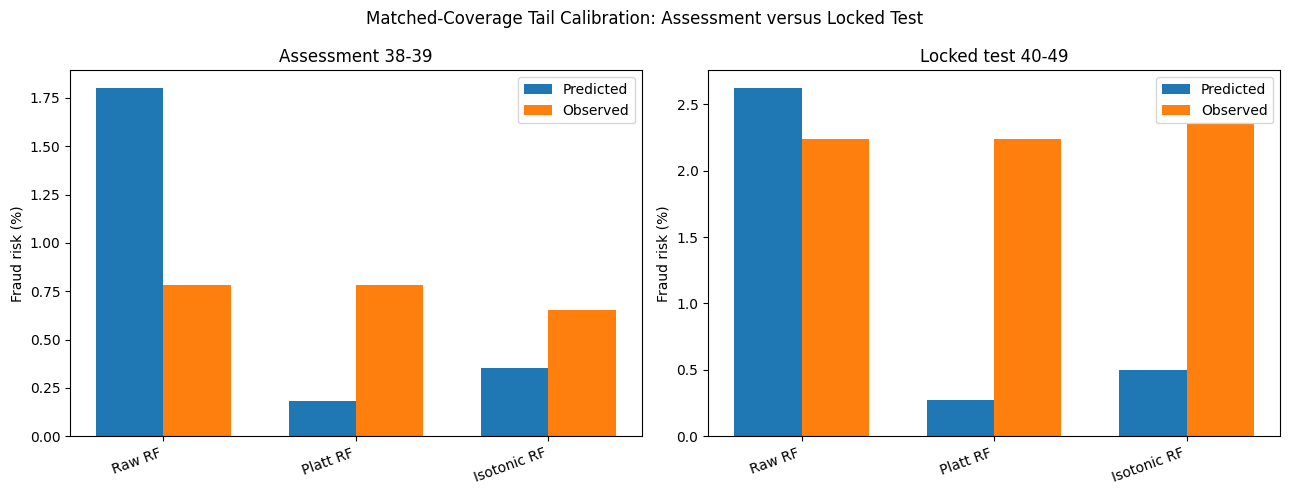


STEP 107 COMPLETED SUCCESSFULLY
Historical isotonic fitting: 35–37
Assessment evaluation: 38–39
Locked test evaluation: 40–49
Frozen model files modified: NO
Analysis type: POST-HOC EXPLORATORY
Outputs: /kaggle/working/step107_calibration_comparison


In [124]:

# ============================================================
# STEP 107 — REVIEWER POINT 1
# HISTORICAL TAIL CALIBRATION + ISOTONIC SENSITIVITY
#
# Fit:         Steps 35–37
# Assessment:  Steps 38–39
# Locked test: Steps 40–49
#
# Exploratory post-hoc analysis; frozen models unchanged.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import beta
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
    average_precision_score
)

OUT107 = "/kaggle/working/step107_calibration_comparison"
os.makedirs(OUT107, exist_ok=True)

print("=" * 76)
print("STEP 107: HISTORICAL CALIBRATION AND TAIL-RISK AUDIT")
print("=" * 76)

# ------------------------------------------------------------
# 1. Use existing notebook predictions
# ------------------------------------------------------------
periods107 = {
    "Calibration 35-37": {
        "y": np.asarray(y_fit, dtype=int).ravel(),
        "Raw RF": np.asarray(p_fit_raw, dtype=float).ravel(),
        "Platt RF": np.asarray(p_fit_cal, dtype=float).ravel(),
    },
    "Assessment 38-39": {
        "y": np.asarray(y_assess, dtype=int).ravel(),
        "Raw RF": np.asarray(p_assess_raw, dtype=float).ravel(),
        "Platt RF": np.asarray(p_assess_cal, dtype=float).ravel(),
    },
    "Locked test 40-49": {
        "y": np.asarray(y_test, dtype=int).ravel(),
        "Raw RF": np.asarray(p_raw, dtype=float).ravel(),
        "Platt RF": np.asarray(p_cal, dtype=float).ravel(),
    },
}

expected107 = {
    "Calibration 35-37": (3547, 255),
    "Assessment 38-39": (1939, 192),
    "Locked test 40-49": (11184, 636),
}

for period, values in periods107.items():
    yy = values["y"]
    raw = values["Raw RF"]
    platt = values["Platt RF"]

    assert len(yy) == len(raw) == len(platt), (
        f"Length mismatch: {period}"
    )
    assert set(np.unique(yy)).issubset({0, 1}), (
        f"Invalid labels: {period}"
    )
    assert np.isfinite(raw).all() and np.isfinite(platt).all()
    assert ((raw >= 0) & (raw <= 1)).all()
    assert ((platt >= 0) & (platt <= 1)).all()

    expected_n, expected_illicit = expected107[period]
    assert len(yy) == expected_n, f"Sample mismatch: {period}"
    assert int(yy.sum()) == expected_illicit, (
        f"Illicit count mismatch: {period}"
    )

    print(
        f"{period}: N={len(yy)}, illicit={int(yy.sum())}"
    )

# ------------------------------------------------------------
# 2. Verify Platt mapping using the existing fitted model
# ------------------------------------------------------------
def logit107(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

for period, values in periods107.items():
    expected_platt = platt_final.predict_proba(
        logit107(values["Raw RF"])
    )[:, list(platt_final.classes_).index(1)]

    max_difference = float(np.max(np.abs(
        expected_platt - values["Platt RF"]
    )))

    print(
        f"Platt mapping check ({period}): "
        f"max difference={max_difference:.10f}"
    )

    assert np.allclose(
        expected_platt,
        values["Platt RF"],
        atol=1e-8,
        rtol=1e-6
    ), f"Platt predictions inconsistent: {period}"

print("\nExisting Platt predictions: VERIFIED")

# ------------------------------------------------------------
# 3. Fit isotonic ONLY on historical calibration 35–37
# ------------------------------------------------------------
iso107 = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

iso107.fit(
    periods107["Calibration 35-37"]["Raw RF"],
    periods107["Calibration 35-37"]["y"]
)

for period, values in periods107.items():
    values["Isotonic RF"] = iso107.predict(
        values["Raw RF"]
    )

print("Isotonic fit: steps 35–37 ONLY")

# ------------------------------------------------------------
# 4. Exact 95% binomial confidence intervals
# ------------------------------------------------------------
def cp107(k, n):
    if n == 0:
        return np.nan, np.nan

    lower = (
        0.0 if k == 0
        else beta.ppf(0.025, k, n - k + 1)
    )
    upper = (
        1.0 if k == n
        else beta.ppf(0.975, k + 1, n - k)
    )

    return float(lower), float(upper)

def audit107(period, model, policy, selected):
    values = periods107[period]
    yy = values["y"]
    pp = values[model]

    selected = np.asarray(selected, dtype=bool)
    n = int(selected.sum())
    k = int(yy[selected].sum())

    lo, hi = cp107(k, n)

    predicted = float(pp[selected].mean()) if n else np.nan
    observed = k / n if n else np.nan

    return {
        "Period": period,
        "Model": model,
        "Policy": policy,
        "N": len(yy),
        "Cleared": n,
        "Coverage (%)": 100 * n / len(yy),
        "Illicit cleared": k,
        "Predicted risk (%)": 100 * predicted,
        "Observed risk (%)": 100 * observed,
        "95% CI lower (%)": 100 * lo,
        "95% CI upper (%)": 100 * hi,
        "Calibration gap (pp)": 100 * (observed - predicted),
    }

# ------------------------------------------------------------
# 5. Tail audit: fixed threshold and matched coverage
# ------------------------------------------------------------
tail_rows107 = []

for period, values in periods107.items():
    platt_n = int(np.sum(values["Platt RF"] < 0.02))

    for model in ["Raw RF", "Platt RF", "Isotonic RF"]:
        pp = values[model]

        tail_rows107.append(
            audit107(
                period,
                model,
                "Fixed p < 0.02",
                pp < 0.02
            )
        )

        # Diagnostic matched coverage; not a deployable
        # historically preselected threshold.
        selected = np.zeros(len(pp), dtype=bool)
        selected[
            np.argsort(pp, kind="stable")[:platt_n]
        ] = True

        tail_rows107.append(
            audit107(
                period,
                model,
                "Matched Platt coverage (diagnostic)",
                selected
            )
        )

tail_df107 = pd.DataFrame(tail_rows107)

print("\n" + "=" * 76)
print("STEP 107A — TAIL CALIBRATION")
print("=" * 76)
print(tail_df107.round(4).to_string(index=False))

tail_df107.to_csv(
    f"{OUT107}/step107_tail_audit.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Whole-period performance
# ------------------------------------------------------------
metric_rows107 = []

for period, values in periods107.items():
    yy = values["y"]

    for model in ["Raw RF", "Platt RF", "Isotonic RF"]:
        pp = values[model]
        safe = np.clip(pp, 1e-12, 1 - 1e-12)

        metric_rows107.append({
            "Period": period,
            "Model": model,
            "N": len(yy),
            "Prevalence (%)": 100 * yy.mean(),
            "Mean predicted (%)": 100 * pp.mean(),
            "Brier": brier_score_loss(yy, pp),
            "Log loss": log_loss(yy, safe, labels=[0, 1]),
            "ROC-AUC": roc_auc_score(yy, pp),
            "PR-AUC": average_precision_score(yy, pp),
        })

metrics_df107 = pd.DataFrame(metric_rows107)

print("\n" + "=" * 76)
print("STEP 107B — PERIOD METRICS")
print("=" * 76)
print(metrics_df107.round(5).to_string(index=False))

metrics_df107.to_csv(
    f"{OUT107}/step107_period_metrics.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Low-probability reliability bins
# ------------------------------------------------------------
edges107 = [
    0, 0.005, 0.01, 0.02,
    0.05, 0.10, 0.20, 0.50, 1.00
]

bin_rows107 = []

for period in ["Assessment 38-39", "Locked test 40-49"]:
    values = periods107[period]

    for model in ["Raw RF", "Platt RF", "Isotonic RF"]:
        pp = values[model]

        for j in range(len(edges107) - 1):
            low = edges107[j]
            high = edges107[j + 1]

            if j == len(edges107) - 2:
                selected = (pp >= low) & (pp <= high)
            else:
                selected = (pp >= low) & (pp < high)

            if selected.sum() == 0:
                continue

            bin_rows107.append(
                audit107(
                    period,
                    model,
                    f"[{low:.3f}, {high:.3f}]",
                    selected
                )
            )

bins_df107 = pd.DataFrame(bin_rows107)

bins_df107.to_csv(
    f"{OUT107}/step107_probability_bins.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Matched-coverage visualization
# ------------------------------------------------------------
plot_df107 = tail_df107[
    (tail_df107["Policy"] ==
     "Matched Platt coverage (diagnostic)")
    & (tail_df107["Period"] != "Calibration 35-37")
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, period in zip(
    axes,
    ["Assessment 38-39", "Locked test 40-49"]
):
    sub = plot_df107[plot_df107["Period"] == period]
    x = np.arange(len(sub))
    width = 0.35

    ax.bar(
        x - width / 2,
        sub["Predicted risk (%)"],
        width,
        label="Predicted"
    )
    ax.bar(
        x + width / 2,
        sub["Observed risk (%)"],
        width,
        label="Observed"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        sub["Model"], rotation=20, ha="right"
    )
    ax.set_title(period)
    ax.set_ylabel("Fraud risk (%)")
    ax.legend()

plt.suptitle(
    "Matched-Coverage Tail Calibration: "
    "Assessment versus Locked Test"
)
plt.tight_layout()

plt.savefig(
    f"{OUT107}/step107_tail_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    f"{OUT107}/step107_tail_comparison.pdf",
    bbox_inches="tight"
)
plt.show()

print("\n" + "=" * 76)
print("STEP 107 COMPLETED SUCCESSFULLY")
print("=" * 76)
print("Historical isotonic fitting: 35–37")
print("Assessment evaluation: 38–39")
print("Locked test evaluation: 40–49")
print("Frozen model files modified: NO")
print("Analysis type: POST-HOC EXPLORATORY")
print("Outputs:", OUT107)


In [125]:

# ============================================================
# STEP 108 — REVIEWER POINT 2
# CORRECTED HISTORICAL CP THRESHOLD SELECTION
#
# Calibration: Steps 35–37 (255 illicit)
# Assessment:  Steps 38–39 (192 illicit)
# Locked test: Steps 40–49 (636 illicit)
#
# Target: illicit auto-clearance fraction <= 5%
# Confidence: 95% (one-sided)
#
# Post-hoc exploratory correction.
# Frozen models and original policies are NOT modified.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import beta

OUT108 = "/kaggle/working/step108_corrected_cp"
os.makedirs(OUT108, exist_ok=True)

ALPHA108 = 0.05
TARGET108 = 0.05

print("=" * 75)
print("STEP 108: CORRECTED HISTORICAL CP RISK-CONTROL")
print("=" * 75)

# ------------------------------------------------------------
# 1. Use existing frozen model scores
# ------------------------------------------------------------
periods108 = {
    "Calibration 35-37": {
        "y": np.asarray(y_fit, dtype=int).ravel(),
        "Raw RF": np.asarray(p_fit_raw, dtype=float).ravel(),
        "Platt RF": np.asarray(p_fit_cal, dtype=float).ravel()
    },
    "Assessment 38-39": {
        "y": np.asarray(y_assess, dtype=int).ravel(),
        "Raw RF": np.asarray(p_assess_raw, dtype=float).ravel(),
        "Platt RF": np.asarray(p_assess_cal, dtype=float).ravel()
    },
    "Locked test 40-49": {
        "y": np.asarray(y_test, dtype=int).ravel(),
        "Raw RF": np.asarray(p_raw, dtype=float).ravel(),
        "Platt RF": np.asarray(p_cal, dtype=float).ravel()
    }
}

expected108 = {
    "Calibration 35-37": (3547, 255),
    "Assessment 38-39": (1939, 192),
    "Locked test 40-49": (11184, 636)
}

for period, values in periods108.items():
    yy = values["y"]
    expected_n, expected_illicit = expected108[period]

    assert len(yy) == expected_n
    assert int(yy.sum()) == expected_illicit

    for model in ["Raw RF", "Platt RF"]:
        pp = values[model]
        assert len(pp) == len(yy)
        assert np.isfinite(pp).all()
        assert np.all((pp >= 0) & (pp <= 1))

    print(
        f"{period}: N={len(yy)}, "
        f"illicit={int(yy.sum())}"
    )

# ------------------------------------------------------------
# 2. One-sided exact Clopper-Pearson upper bound
# ------------------------------------------------------------
def cp_upper108(k, n, alpha=ALPHA108):
    """
    One-sided (1-alpha) exact binomial upper bound.

    Applies to the illicit conditional miss probability,
    not the fraud proportion among cleared transactions.
    """
    if n <= 0:
        return np.nan

    if k >= n:
        return 1.0

    return float(beta.ppf(1 - alpha, k + 1, n - k))

# ------------------------------------------------------------
# 3. Corrected order-statistic rank
# ------------------------------------------------------------
n_illicit108 = int(
    periods108["Calibration 35-37"]["y"].sum()
)

# Largest allowable count k whose one-sided CP upper
# bound does not exceed the target.
feasible_counts108 = [
    k for k in range(n_illicit108 + 1)
    if cp_upper108(k, n_illicit108) <= TARGET108
]

if not feasible_counts108:
    raise RuntimeError(
        "No feasible historical CP count at the "
        "requested confidence and risk target."
    )

k_max108 = max(feasible_counts108)

print("\nCorrected historical selection:")
print("Illicit calibration N:", n_illicit108)
print("Target miss probability:", TARGET108)
print("One-sided confidence:", 1 - ALPHA108)
print("Maximum allowable calibration misses:", k_max108)
print(
    "CP upper bound:",
    cp_upper108(k_max108, n_illicit108)
)

# ------------------------------------------------------------
# 4. Select largest threshold from historical illicit scores
# ------------------------------------------------------------
def select_threshold108(scores, labels, k_max):
    scores = np.asarray(scores, dtype=float)
    labels = np.asarray(labels, dtype=int)

    illicit_scores = np.sort(scores[labels == 1])

    # Clearance condition is STRICT: score < threshold.
    #
    # The (k_max + 1)-th illicit order statistic is the
    # largest threshold at which at most k_max illicit
    # calibration samples are cleared.
    #
    # Ties are handled by strict inequality.
    threshold = float(illicit_scores[k_max])

    misses = int(np.sum(illicit_scores < threshold))

    assert misses <= k_max

    return threshold, misses

thresholds108 = {}

for model in ["Raw RF", "Platt RF"]:
    values = periods108["Calibration 35-37"]

    threshold, misses = select_threshold108(
        values[model],
        values["y"],
        k_max108
    )

    thresholds108[model] = threshold

    print(f"\n{model}")
    print(f"Corrected threshold: {threshold:.10f}")
    print(f"Calibration illicit misses: {misses}/{n_illicit108}")
    print(
        "Calibration CP upper bound:",
        cp_upper108(misses, n_illicit108)
    )

# ------------------------------------------------------------
# 5. Apply thresholds WITHOUT modification
# ------------------------------------------------------------
rows108 = []

for period, values in periods108.items():
    yy = values["y"]

    for model in ["Raw RF", "Platt RF"]:
        pp = values[model]
        threshold = thresholds108[model]

        cleared = pp < threshold

        n_clear = int(cleared.sum())
        illicit_clear = int(yy[cleared].sum())
        n_illicit = int(yy.sum())

        miss_fraction = illicit_clear / n_illicit
        observed_clear_risk = (
            illicit_clear / n_clear if n_clear else np.nan
        )

        cp_lo = (
            0.0 if illicit_clear == 0
            else float(beta.ppf(
                0.025,
                illicit_clear,
                n_illicit - illicit_clear + 1
            ))
        )

        cp_hi = (
            1.0 if illicit_clear == n_illicit
            else float(beta.ppf(
                0.975,
                illicit_clear + 1,
                n_illicit - illicit_clear
            ))
        )

        rows108.append({
            "Period": period,
            "Model": model,
            "Threshold": threshold,
            "N": len(yy),
            "Illicit N": n_illicit,
            "Cleared": n_clear,
            "Coverage (%)": 100 * n_clear / len(yy),
            "Illicit cleared": illicit_clear,
            "Miss (%)": 100 * miss_fraction,
            "Observed fraud/clear (%)":
                100 * observed_clear_risk,
            "Miss CI lower (%)": 100 * cp_lo,
            "Miss CI upper (%)": 100 * cp_hi,
            "Meets empirical 5% target":
                miss_fraction <= TARGET108
        })

results108 = pd.DataFrame(rows108)

print("\n" + "=" * 75)
print("STEP 108 RESULTS")
print("=" * 75)
print(results108.round(5).to_string(index=False))

results108.to_csv(
    f"{OUT108}/step108_corrected_cp_results.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Compare original and corrected historical thresholds
# ------------------------------------------------------------
original108 = {
    "Raw RF": 0.048304,
    "Platt RF": 0.004633
}

comparison_rows108 = []

for model in ["Raw RF", "Platt RF"]:
    for label, threshold in [
        ("Original historical", original108[model]),
        ("Corrected CP", thresholds108[model])
    ]:
        for period in [
            "Assessment 38-39",
            "Locked test 40-49"
        ]:
            yy = periods108[period]["y"]
            pp = periods108[period][model]

            cleared = pp < threshold
            illicit_clear = int(yy[cleared].sum())

            comparison_rows108.append({
                "Model": model,
                "Policy": label,
                "Period": period,
                "Threshold": threshold,
                "Cleared": int(cleared.sum()),
                "Illicit cleared": illicit_clear,
                "Miss (%)": 100 * illicit_clear / yy.sum()
            })

comparison108 = pd.DataFrame(comparison_rows108)

print("\n" + "=" * 75)
print("ORIGINAL VERSUS CORRECTED CP")
print("=" * 75)
print(comparison108.round(5).to_string(index=False))

comparison108.to_csv(
    f"{OUT108}/step108_original_vs_corrected.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Protocol documentation
# ------------------------------------------------------------
protocol108 = pd.DataFrame([{
    "Target illicit miss probability": TARGET108,
    "Alpha": ALPHA108,
    "Illicit calibration count": n_illicit108,
    "Maximum CP-feasible misses": k_max108,
    "CP upper at selected count":
        cp_upper108(k_max108, n_illicit108),
    "Raw threshold": thresholds108["Raw RF"],
    "Platt threshold": thresholds108["Platt RF"],
    "Threshold inequality": "score < threshold",
    "Threshold fitting period": "35-37",
    "Assessment period": "38-39",
    "Locked test period": "40-49",
    "Status": "Post-hoc exploratory correction"
}])

protocol108.to_csv(
    f"{OUT108}/step108_protocol.csv",
    index=False
)

print("\n" + "=" * 75)
print("STEP 108 COMPLETED SUCCESSFULLY")
print("=" * 75)
print("Historical calibration only: YES")
print("Assessment/test threshold fitting: NO")
print("Frozen artifacts modified: NO")
print("Prospective deployment guarantee claimed: NO")
print("Output directory:", OUT108)


STEP 108: CORRECTED HISTORICAL CP RISK-CONTROL
Calibration 35-37: N=3547, illicit=255
Assessment 38-39: N=1939, illicit=192
Locked test 40-49: N=11184, illicit=636

Corrected historical selection:
Illicit calibration N: 255
Target miss probability: 0.05
One-sided confidence: 0.95
Maximum allowable calibration misses: 6
CP upper bound: 0.04591003104165281

Raw RF
Corrected threshold: 0.0417694436
Calibration illicit misses: 6/255
Calibration CP upper bound: 0.04591003104165281

Platt RF
Corrected threshold: 0.0037452724
Calibration illicit misses: 6/255
Calibration CP upper bound: 0.04591003104165281

STEP 108 RESULTS
           Period    Model  Threshold     N  Illicit N  Cleared  Coverage (%)  Illicit cleared  Miss (%)  Observed fraud/clear (%)  Miss CI lower (%)  Miss CI upper (%)  Meets empirical 5% target
Calibration 35-37   Raw RF    0.04177  3547        255     2438      68.73414                6   2.35294                   0.24610            0.86827            5.05075           

In [126]:

# ============================================================
# STEP 109: CLASS-CONDITIONAL SCORE SHIFT AUDIT
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score
from statsmodels.stats.proportion import proportion_confint

# Use existing notebook arrays and frozen RF predictions.
# Required: times_all, labels_all, p_assess_raw, p_raw

assert "times_all" in globals(), "Missing times_all"
assert "labels_all" in globals(), "Missing labels_all"
assert "p_assess_raw" in globals(), "Missing p_assess_raw"
assert "p_raw" in globals(), "Missing p_raw"

t_all = np.asarray(times_all).reshape(-1)
y_all_full = np.asarray(labels_all).reshape(-1)

def get_period(start, end, scores):
    mask = (
        (t_all >= start) &
        (t_all <= end) &
        np.isin(y_all_full, [0, 1])
    )
    y = y_all_full[mask].astype(int)
    t = t_all[mask].astype(int)
    p = np.asarray(scores).reshape(-1)

    assert len(y) == len(p), (
        f"Score alignment error for steps {start}-{end}: "
        f"{len(y)} labels vs {len(p)} scores"
    )
    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()
    return t, y, p

t_assess, y_assess_109, p_assess_109 = get_period(
    38, 39, p_assess_raw
)
t_test, y_test_109, p_test_109 = get_period(
    40, 49, p_raw
)

assert len(y_assess_109) == 1939
assert len(y_test_109) == 11184
assert int(y_assess_109.sum()) == 192
assert int(y_test_109.sum()) == 636

# Threshold with empirical assessment FPR <= 5%.
# Strictly flag when score > threshold.
licit_assess = p_assess_109[y_assess_109 == 0]
candidate_thresholds = np.unique(
    np.concatenate(([0.0], licit_assess, [1.0]))
)

eligible = [
    x for x in candidate_thresholds
    if np.mean(licit_assess > x) <= 0.05
]
tau_5fpr = float(min(eligible))

print("Assessment 5%-FPR threshold:", tau_5fpr)

periods = {
    "Assessment 38-39": (
        t_assess, y_assess_109, p_assess_109
    ),
    "Early test 40-42": (
        t_test[(t_test >= 40) & (t_test <= 42)],
        y_test_109[(t_test >= 40) & (t_test <= 42)],
        p_test_109[(t_test >= 40) & (t_test <= 42)]
    ),
    "Late test 43-49": (
        t_test[(t_test >= 43) & (t_test <= 49)],
        y_test_109[(t_test >= 43) & (t_test <= 49)],
        p_test_109[(t_test >= 43) & (t_test <= 49)]
    ),
    "Full test 40-49": (
        t_test, y_test_109, p_test_109
    )
}

quantile_rows = []
performance_rows = []

for name, (t, y, p) in periods.items():
    for cls, label in [(0, "Licit"), (1, "Illicit")]:
        v = p[y == cls]
        quantile_rows.append({
            "period": name,
            "class": label,
            "n": len(v),
            "q10": np.quantile(v, 0.10),
            "median": np.quantile(v, 0.50),
            "q90": np.quantile(v, 0.90)
        })

    flag = p > tau_5fpr
    recall = flag[y == 1].mean()
    fpr = flag[y == 0].mean()

    clear = p < 0.02
    n_clear = int(clear.sum())
    illicit_clear = int(np.sum(clear & (y == 1)))
    observed_risk = (
        illicit_clear / n_clear if n_clear else np.nan
    )
    prevalence = float(y.mean())

    performance_rows.append({
        "period": name,
        "n": len(y),
        "illicit_n": int(y.sum()),
        "prevalence": prevalence,
        "recall_at_5fpr_threshold": recall,
        "fpr_at_5fpr_threshold": fpr,
        "ap": average_precision_score(y, p),
        "roc_auc": roc_auc_score(y, p),
        "fixed_0.02_cleared": n_clear,
        "fixed_0.02_coverage": clear.mean(),
        "fixed_0.02_illicit_cleared": illicit_clear,
        "fixed_0.02_cleared_fraud_rate": observed_risk,
        "fixed_0.02_risk_to_prevalence": (
            observed_risk / prevalence
            if prevalence > 0 else np.nan
        )
    })

quantile_df_109 = pd.DataFrame(quantile_rows)
performance_df_109 = pd.DataFrame(performance_rows)

print("\nCLASS-CONDITIONAL QUANTILES")
print(quantile_df_109.to_string(index=False))

print("\nTEMPORAL PERFORMANCE")
print(performance_df_109.to_string(index=False))

quantile_df_109.to_csv(
    "/kaggle/working/step109_score_quantiles.csv",
    index=False
)
performance_df_109.to_csv(
    "/kaggle/working/step109_temporal_performance.csv",
    index=False
)

# Snapshot-level recall and FPR
snapshot_rows = []

for step in range(40, 50):
    mask = t_test == step
    yy = y_test_109[mask]
    pp = p_test_109[mask]

    pos = yy == 1
    neg = yy == 0
    flags = pp > tau_5fpr

    snapshot_rows.append({
        "step": step,
        "n": len(yy),
        "illicit_n": int(pos.sum()),
        "prevalence": yy.mean(),
        "recall": (
            flags[pos].mean() if pos.any() else np.nan
        ),
        "fpr": (
            flags[neg].mean() if neg.any() else np.nan
        ),
        "illicit_flagged": int(np.sum(flags & pos)),
        "illicit_not_flagged": int(np.sum(~flags & pos))
    })

snapshot_df_109 = pd.DataFrame(snapshot_rows)

print("\nSNAPSHOT-LEVEL RESULTS")
print(snapshot_df_109.to_string(index=False))

snapshot_df_109.to_csv(
    "/kaggle/working/step109_snapshot_metrics.csv",
    index=False
)

print("\nSTEP 109 COMPLETED")


Assessment 5%-FPR threshold: 0.27624742689746656

CLASS-CONDITIONAL QUANTILES
          period   class     n      q10   median      q90
Assessment 38-39   Licit  1747 0.000000 0.008929 0.174058
Assessment 38-39 Illicit   192 0.583423 0.973641 0.980881
Early test 40-42   Licit  4030 0.000000 0.023114 0.191392
Early test 40-42 Illicit   467 0.076379 0.970402 0.979938
 Late test 43-49   Licit  6518 0.000000 0.020700 0.196342
 Late test 43-49 Illicit   169 0.003230 0.023649 0.172518
 Full test 40-49   Licit 10548 0.000000 0.021385 0.194604
 Full test 40-49 Illicit   636 0.012939 0.756712 0.979643

TEMPORAL PERFORMANCE
          period     n  illicit_n  prevalence  recall_at_5fpr_threshold  fpr_at_5fpr_threshold       ap  roc_auc  fixed_0.02_cleared  fixed_0.02_coverage  fixed_0.02_illicit_cleared  fixed_0.02_cleared_fraud_rate  fixed_0.02_risk_to_prevalence
Assessment 38-39  1939        192    0.099020                  0.937500               0.049800 0.948869 0.978214                1050  

In [127]:

# ============================================================
# STEP 110: MATCHED-RULE RANDOMIZED POSITIVE CONTROL
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import beta
from statsmodels.stats.proportion import proportion_confint

# Required existing notebook arrays:
# y_fit, p_fit_raw, y_assess_109, p_assess_109,
# y_test_109, p_test_109

y_hist = np.asarray(y_fit).reshape(-1).astype(int)
p_hist = np.asarray(p_fit_raw).reshape(-1)

assert len(y_hist) == len(p_hist)
assert len(y_hist) == 3547
assert int(y_hist.sum()) == 255
assert int(y_test_109.sum()) == 636

hist_illicit = p_hist[y_hist == 1]
test_illicit = p_test_109[y_test_109 == 1]

ALPHA = 0.05
DELTA = 0.05
N_REPS = 300
SEED = 2026

def cp_upper(k, n, delta=0.05):
    """One-sided Clopper-Pearson upper confidence limit."""
    if n == 0:
        return np.nan
    if k == n:
        return 1.0
    return float(beta.ppf(1 - delta, k + 1, n - k))

def select_corrected_threshold(illicit_scores):
    """
    Select a threshold under strict clearance: score < tau.
    Use the largest permissible miss count according to
    the nominal one-sided CP criterion.

    This is exploratory, not a post-selection guarantee.
    """
    scores = np.sort(np.asarray(illicit_scores, dtype=float))
    n = len(scores)

    allowed = [
        k for k in range(n + 1)
        if cp_upper(k, n, DELTA) <= ALPHA
    ]
    if not allowed:
        return 0.0, 0, np.nan

    k = max(allowed)

    # Strict score < threshold:
    # Selecting score[k] allows at most k misses,
    # including in the presence of ties.
    if k < n:
        threshold = float(scores[k])
    else:
        threshold = 1.0

    actual_misses = int(np.sum(scores < threshold))
    upper = cp_upper(actual_misses, n, DELTA)

    return threshold, actual_misses, upper

# ------------------------------------------------------------
# A. Corrected historical threshold
# ------------------------------------------------------------

tau_hist, k_hist, upper_hist = (
    select_corrected_threshold(hist_illicit)
)

print("HISTORICAL CALIBRATION")
print("Calibration illicit n:", len(hist_illicit))
print("Threshold:", tau_hist)
print("Calibration misses:", k_hist)
print("Nominal CP upper:", upper_hist)

# Check consistency with previously verified Step 108.
assert k_hist == 6, (
    "Historical miss count differs from Step 108."
)
assert np.isclose(tau_hist, 0.0417694436, atol=1e-6), (
    "Historical threshold differs from Step 108. "
    "Check frozen score arrays."
)

def evaluate_illicit_misses(scores, threshold):
    scores = np.asarray(scores)
    n = len(scores)
    misses = int(np.sum(scores < threshold))
    return {
        "n_illicit": n,
        "illicit_cleared": misses,
        "miss_fraction": misses / n,
        "cp_upper_95": cp_upper(misses, n, DELTA)
    }

historical_rows = []

for period, y, p in [
    ("Calibration 35-37", y_hist, p_hist),
    ("Assessment 38-39", y_assess_109, p_assess_109),
    ("Test 40-49", y_test_109, p_test_109)
]:
    result = evaluate_illicit_misses(
        np.asarray(p)[np.asarray(y) == 1],
        tau_hist
    )
    historical_rows.append({
        "period": period,
        "threshold": tau_hist,
        **result
    })

historical_df_110 = pd.DataFrame(historical_rows)

print("\nCORRECTED HISTORICAL POLICY")
print(historical_df_110.to_string(index=False))

# ------------------------------------------------------------
# B. Randomized matched-rule positive control
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)
n_cal = len(hist_illicit)  # 255
n_total = len(test_illicit)  # 636
n_eval = n_total - n_cal  # 381

assert n_cal == 255
assert n_eval == 381

random_rows = []

for rep in range(1, N_REPS + 1):
    perm = rng.permutation(n_total)

    cal_scores = test_illicit[perm[:n_cal]]
    eval_scores = test_illicit[perm[n_cal:]]

    tau, cal_misses, cal_upper = (
        select_corrected_threshold(cal_scores)
    )

    result = evaluate_illicit_misses(eval_scores, tau)

    random_rows.append({
        "repetition": rep,
        "calibration_n": n_cal,
        "evaluation_n": n_eval,
        "threshold": tau,
        "calibration_misses": cal_misses,
        "calibration_cp_upper": cal_upper,
        **result,
        "empirical_target_met": (
            result["miss_fraction"] <= ALPHA
        ),
        "evaluation_cp_target_met": (
            result["cp_upper_95"] <= ALPHA
        )
    })

random_df_110 = pd.DataFrame(random_rows)

summary_df_110 = pd.DataFrame([{
    "repetitions": N_REPS,
    "calibration_n": n_cal,
    "evaluation_n": n_eval,
    "mean_miss_fraction": random_df_110[
        "miss_fraction"
    ].mean(),
    "median_miss_fraction": random_df_110[
        "miss_fraction"
    ].median(),
    "miss_fraction_q025": random_df_110[
        "miss_fraction"
    ].quantile(0.025),
    "miss_fraction_q975": random_df_110[
        "miss_fraction"
    ].quantile(0.975),
    "empirical_target_met_fraction": random_df_110[
        "empirical_target_met"
    ].mean(),
    "evaluation_cp_target_met_fraction": random_df_110[
        "evaluation_cp_target_met"
    ].mean(),
    "historical_test_miss_fraction": (
        historical_df_110.loc[
            historical_df_110["period"] == "Test 40-49",
            "miss_fraction"
        ].iloc[0]
    )
}])

print("\nMATCHED-RULE RANDOMIZED SUMMARY")
print(summary_df_110.to_string(index=False))

# ------------------------------------------------------------
# C. Save outputs
# ------------------------------------------------------------

historical_df_110.to_csv(
    "/kaggle/working/step110_historical.csv",
    index=False
)

random_df_110.to_csv(
    "/kaggle/working/step110_randomized_repetitions.csv",
    index=False
)

summary_df_110.to_csv(
    "/kaggle/working/step110_summary.csv",
    index=False
)

print("\nSTEP 110 COMPLETED")


HISTORICAL CALIBRATION
Calibration illicit n: 255
Threshold: 0.04176944361297847
Calibration misses: 6
Nominal CP upper: 0.04591003104165281

CORRECTED HISTORICAL POLICY
           period  threshold  n_illicit  illicit_cleared  miss_fraction  cp_upper_95
Calibration 35-37   0.041769        255                6       0.023529     0.045910
 Assessment 38-39   0.041769        192                6       0.031250     0.060744
       Test 40-49   0.041769        636              134       0.210692     0.239052

MATCHED-RULE RANDOMIZED SUMMARY
 repetitions  calibration_n  evaluation_n  mean_miss_fraction  median_miss_fraction  miss_fraction_q025  miss_fraction_q975  empirical_target_met_fraction  evaluation_cp_target_met_fraction  historical_test_miss_fraction
         300            255           381            0.026395              0.026247            0.005249            0.051247                       0.973333                           0.653333                       0.210692

STEP 110 COMPL

In [128]:
import os
import shutil

source_dir = "/kaggle/working"
zip_path = "/kaggle/working_complete_final"

shutil.make_archive(
    zip_path,
    "zip",
    root_dir="/kaggle",
    base_dir="working"
)

print("ZIP created successfully!")
print("File:", zip_path + ".zip")
print("Size (MB):", round(
    os.path.getsize(zip_path + ".zip") / (1024**2), 2
))

ZIP created successfully!
File: /kaggle/working_complete_final.zip
Size (MB): 13.69


In [129]:
import shutil
import os

source = "/kaggle/working_complete_final.zip"
destination = "/kaggle/working/working_complete_final.zip"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("ZIP copied successfully!")
    print("Location:", destination)
else:
    print("Source ZIP not found.")

ZIP copied successfully!
Location: /kaggle/working/working_complete_final.zip
